# DS-02: Demand Forecasting & Inventory Optimization

This notebook contains the end-to-end implementation for the M5 demand forecasting project. It covers data inspection, feature engineering, forecasting experiments, hierarchical reconciliation, inventory optimization, evaluation, and dashboard development.

**Environment:** Google Colab with Google Drive storage. Update project paths and install required packages before running cells in a fresh environment.

The notebook retains the original implementation cells and their saved outputs; section headings have been added for easier navigation.

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

print("Google Drive connected successfully!")


Mounted at /content/drive
Google Drive connected successfully!


## 1. Environment Setup and Dataset Inspection

In [ ]:

import os

DATA_DIR = "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/data"

expected_files = [
    "sales_train_validation.csv",
    "sales_train_evaluation.csv",
    "calendar.csv",
    "sell_prices.csv"
]

print("M5 DATASET FILE VERIFICATION")
print("=" * 60)

for filename in expected_files:

    filepath = os.path.join(DATA_DIR, filename)

    if os.path.exists(filepath):
        size_mb = os.path.getsize(filepath) / (1024 * 1024)
        print(f"[FOUND] {filename} - {size_mb:.2f} MB")
    else:
        print(f"[MISSING] {filename}")

print("=" * 60)


M5 DATASET FILE VERIFICATION
[FOUND] sales_train_validation.csv - 114.45 MB
[FOUND] sales_train_evaluation.csv - 116.10 MB
[FOUND] calendar.csv - 0.10 MB
[FOUND] sell_prices.csv - 193.97 MB


In [ ]:

import pandas as pd
import os

sales_path = os.path.join(
    DATA_DIR,
    "sales_train_validation.csv"
)
sales_preview = pd.read_csv(sales_path, nrows=5)
print("PREVIEW SHAPE")
print(sales_preview.shape)
print("\nFIRST 15 COLUMNS")
print(sales_preview.columns[:15].tolist())
print("\nIDENTIFIER COLUMNS")
print(sales_preview.iloc[:, :6].to_string(index=False))
print("\nDATA TYPES")
print(sales_preview.dtypes.value_counts())
print("\nSAMPLE RECORDS")
display(sales_preview.iloc[:, :10])
print("\nPREVIEW MEMORY USAGE")
print(
    f"{sales_preview.memory_usage(deep=True).sum() / (1024**2):.2f} MB"
)

PREVIEW SHAPE
(5, 1919)

FIRST 15 COLUMNS
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9']

IDENTIFIER COLUMNS
                           id       item_id   dept_id  cat_id store_id state_id
HOBBIES_1_001_CA_1_validation HOBBIES_1_001 HOBBIES_1 HOBBIES     CA_1       CA
HOBBIES_1_002_CA_1_validation HOBBIES_1_002 HOBBIES_1 HOBBIES     CA_1       CA
HOBBIES_1_003_CA_1_validation HOBBIES_1_003 HOBBIES_1 HOBBIES     CA_1       CA
HOBBIES_1_004_CA_1_validation HOBBIES_1_004 HOBBIES_1 HOBBIES     CA_1       CA
HOBBIES_1_005_CA_1_validation HOBBIES_1_005 HOBBIES_1 HOBBIES     CA_1       CA

DATA TYPES
int64     1913
object       6
Name: count, dtype: int64

SAMPLE RECORDS


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0



PREVIEW MEMORY USAGE
0.07 MB


In [ ]:

# Load only the six identifier columns

id_columns = [
    "id",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

sales_ids = pd.read_csv(
    sales_path,
    usecols=id_columns
)

print("COMPLETE DATASET INFORMATION")
print("=" * 50)

print("Total product-store records:", len(sales_ids))

print("\nUnique products:", sales_ids["item_id"].nunique())

print("Unique stores:", sales_ids["store_id"].nunique())

print("Unique departments:", sales_ids["dept_id"].nunique())

print("Unique categories:", sales_ids["cat_id"].nunique())

print("Unique states:", sales_ids["state_id"].nunique())

print("\nStores:")
print(sorted(sales_ids["store_id"].unique()))

print("\nStates:")
print(sorted(sales_ids["state_id"].unique()))

print("=" * 50)



COMPLETE DATASET INFORMATION
Total product-store records: 30490

Unique products: 3049
Unique stores: 10
Unique departments: 7
Unique categories: 3
Unique states: 3

Stores:
['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1', 'WI_2', 'WI_3']

States:
['CA', 'TX', 'WI']


In [ ]:

# Calendar dataset path
calendar_path = os.path.join(DATA_DIR, "calendar.csv")

# Load calendar dataset
calendar_df = pd.read_csv(calendar_path)

# 1. Dataset dimensions
print("CALENDAR DATASET SHAPE")
print(calendar_df.shape)

# 2. Column names
print("\nCALENDAR COLUMNS")
print(calendar_df.columns.tolist())

# 3. Data types
print("\nDATA TYPES")
print(calendar_df.dtypes)

# 4. Missing values
print("\nMISSING VALUES")
print(calendar_df.isnull().sum())

# 5. First five records
print("\nSAMPLE RECORDS")
display(calendar_df.head())

# 6. Date range
calendar_df["date"] = pd.to_datetime(calendar_df["date"])

print("\nDATE RANGE")
print("Start date:", calendar_df["date"].min())
print("End date:", calendar_df["date"].max())


CALENDAR DATASET SHAPE
(1969, 14)

CALENDAR COLUMNS
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

DATA TYPES
date            object
wm_yr_wk         int64
weekday         object
wday             int64
month            int64
year             int64
d               object
event_name_1    object
event_type_1    object
event_name_2    object
event_type_2    object
snap_CA          int64
snap_TX          int64
snap_WI          int64
dtype: object

MISSING VALUES
date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

SAMPLE RECORDS


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1



DATE RANGE
Start date: 2011-01-29 00:00:00
End date: 2016-06-19 00:00:00


In [ ]:

prices_path = os.path.join(DATA_DIR, "sell_prices.csv")

prices_df = pd.read_csv(prices_path)

print("SELL PRICES DATASET SHAPE")
print(prices_df.shape)

print("\nCOLUMN NAMES")
print(prices_df.columns.tolist())

print("\nDATA TYPES")
print(prices_df.dtypes)

print("\nMISSING VALUES")
print(prices_df.isnull().sum())

print("\nSAMPLE RECORDS")
display(prices_df.head())

print("\nUNIQUE STORES:", prices_df["store_id"].nunique())
print("UNIQUE ITEMS:", prices_df["item_id"].nunique())
print("UNIQUE WEEKS:", prices_df["wm_yr_wk"].nunique())

print("\nPRICE STATISTICS")
print(prices_df["sell_price"].describe())


SELL PRICES DATASET SHAPE
(6841121, 4)

COLUMN NAMES
['store_id', 'item_id', 'wm_yr_wk', 'sell_price']

DATA TYPES
store_id       object
item_id        object
wm_yr_wk        int64
sell_price    float64
dtype: object

MISSING VALUES
store_id      0
item_id       0
wm_yr_wk      0
sell_price    0
dtype: int64

SAMPLE RECORDS


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26



UNIQUE STORES: 10
UNIQUE ITEMS: 3049
UNIQUE WEEKS: 282

PRICE STATISTICS
count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64


In [ ]:

evaluation_path = os.path.join(DATA_DIR, "sales_train_evaluation.csv")

evaluation_preview = pd.read_csv(evaluation_path, nrows=5)

print("EVALUATION DATASET PREVIEW SHAPE")
print(evaluation_preview.shape)

print("\nFIRST 15 COLUMNS")
print(evaluation_preview.columns[:15].tolist())

print("\nIDENTIFIER COLUMNS")
display(evaluation_preview.iloc[:, :6])

print("\nDATA TYPES")
print(evaluation_preview.dtypes.value_counts())

print("\nSAMPLE RECORDS")
display(evaluation_preview.iloc[:, :10])


EVALUATION DATASET PREVIEW SHAPE
(5, 1947)

FIRST 15 COLUMNS
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6', 'd_7', 'd_8', 'd_9']

IDENTIFIER COLUMNS


,id,item_id,dept_id,cat_id,store_id,state_id
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA



DATA TYPES
int64     1941
object       6
Name: count, dtype: int64

SAMPLE RECORDS


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


In [ ]:

validation_columns = pd.read_csv(
    sales_path, nrows=0
).columns.tolist()

evaluation_columns = pd.read_csv(
    evaluation_path, nrows=0
).columns.tolist()

validation_days = [
    col for col in validation_columns if col.startswith("d_")
]

evaluation_days = [
    col for col in evaluation_columns if col.startswith("d_")
]

print("VALIDATION DATA")
print("First day:", validation_days[0])
print("Last day:", validation_days[-1])
print("Total days:", len(validation_days))

print("\nEVALUATION DATA")
print("First day:", evaluation_days[0])
print("Last day:", evaluation_days[-1])
print("Total days:", len(evaluation_days))

print("\nADDITIONAL DAYS IN EVALUATION:")
print(len(set(evaluation_days) - set(validation_days)))

print("\nVALIDATION AND EVALUATION SHARE SAME FIRST DAY:",
      validation_days[0] == evaluation_days[0])



VALIDATION DATA
First day: d_1
Last day: d_1913
Total days: 1913

EVALUATION DATA
First day: d_1
Last day: d_1941
Total days: 1941

ADDITIONAL DAYS IN EVALUATION:
28

VALIDATION AND EVALUATION SHARE SAME FIRST DAY: True


In [ ]:

# Check whether every sales day has a calendar entry

calendar_days = set(calendar_df["d"])

validation_day_set = set(validation_days)
evaluation_day_set = set(evaluation_days)

print("VALIDATION DAY MAPPING")
print("Sales days:", len(validation_day_set))
print("Matched calendar days:", len(validation_day_set & calendar_days))
print("Unmatched days:", len(validation_day_set - calendar_days))

print("\nEVALUATION DAY MAPPING")
print("Sales days:", len(evaluation_day_set))
print("Matched calendar days:", len(evaluation_day_set & calendar_days))
print("Unmatched days:", len(evaluation_day_set - calendar_days))

print("\nCALENDAR DAY RANGE")
print("First:", calendar_df["d"].iloc[0])
print("Last:", calendar_df["d"].iloc[-1])


VALIDATION DAY MAPPING
Sales days: 1913
Matched calendar days: 1913
Unmatched days: 0

EVALUATION DAY MAPPING
Sales days: 1941
Matched calendar days: 1941
Unmatched days: 0

CALENDAR DAY RANGE
First: d_1
Last: d_1969


In [ ]:

# Inspect a sample of sales values for data quality

sales_sample = pd.read_csv(
    sales_path,
    nrows=1000
)

sample_day_columns = [
    col for col in sales_sample.columns
    if col.startswith("d_")
]

sample_sales = sales_sample[sample_day_columns]

print("SAMPLE SIZE:", sales_sample.shape)

print("\nMISSING SALES VALUES:")
print(sample_sales.isnull().sum().sum())

print("\nNEGATIVE SALES VALUES:")
print((sample_sales < 0).sum().sum())

print("\nZERO SALES VALUES:")
print((sample_sales == 0).sum().sum())

print("\nSALES STATISTICS:")
print(sample_sales.describe().loc[["mean", "std", "min", "50%", "max"]])

SAMPLE SIZE: (1000, 1919)

MISSING SALES VALUES:
0

NEGATIVE SALES VALUES:
0

ZERO SALES VALUES:
1285760

SALES STATISTICS:
           d_1        d_2        d_3        d_4        d_5        d_6  \
mean   0.84900   0.771000   0.643000   0.602000   0.427000   0.693000   
std    3.37455   3.443605   3.128472   2.308013   1.699282   3.358278   
min    0.00000   0.000000   0.000000   0.000000   0.000000   0.000000   
50%    0.00000   0.000000   0.000000   0.000000   0.000000   0.000000   
max   54.00000  73.000000  67.000000  33.000000  29.000000  74.000000   

            d_7        d_8      d_9       d_10  ...     d_1904     d_1905  \
mean   0.565000   1.178000   0.7150   0.575000  ...   0.932000   1.493000   
std    1.948222   4.603423   2.5769   2.538665  ...   1.993326   3.451937   
min    0.000000   0.000000   0.0000   0.000000  ...   0.000000   0.000000   
50%    0.000000   0.000000   0.0000   0.000000  ...   0.000000   0.000000   
max   26.000000  78.000000  30.0000  36.000000  ... 

In [ ]:

# Average daily sales for each product-store combination
sales_sample["average_daily_sales"] = (
    sample_sales.mean(axis=1)
)

print("AVERAGE DAILY SALES DISTRIBUTION")
print(sales_sample["average_daily_sales"].describe())

print("\nPRODUCTS WITH LOWEST AVERAGE DAILY SALES")
display(
    sales_sample[
        ["item_id", "store_id", "average_daily_sales"]
    ].sort_values("average_daily_sales").head(10)
)

print("\nPRODUCTS WITH HIGHEST AVERAGE DAILY SALES")
display(
    sales_sample[
        ["item_id", "store_id", "average_daily_sales"]
    ].sort_values(
        "average_daily_sales", ascending=False
    ).head(10)
)


AVERAGE DAILY SALES DISTRIBUTION
count    1000.000000
mean        0.920063
std         1.360992
min         0.010978
25%         0.191584
50%         0.465238
75%         1.000261
max        11.889179
Name: average_daily_sales, dtype: float64

PRODUCTS WITH LOWEST AVERAGE DAILY SALES


,item_id,store_id,average_daily_sales
935,HOUSEHOLD_1_378,CA_1,0.010978
25,HOBBIES_1_026,CA_1,0.010978
430,HOBBIES_2_015,CA_1,0.026137
858,HOUSEHOLD_1_300,CA_1,0.029796
534,HOBBIES_2_119,CA_1,0.030319
425,HOBBIES_2_010,CA_1,0.036069
872,HOUSEHOLD_1_314,CA_1,0.038160
438,HOBBIES_2_023,CA_1,0.040251
293,HOBBIES_1_302,CA_1,0.041819
436,HOBBIES_2_021,CA_1,0.044956



PRODUCTS WITH HIGHEST AVERAGE DAILY SALES


,item_id,store_id,average_daily_sales
339,HOBBIES_1_348,CA_1,11.889179
362,HOBBIES_1_371,CA_1,11.811291
260,HOBBIES_1_268,CA_1,9.881861
173,HOBBIES_1_178,CA_1,8.263461
248,HOBBIES_1_256,CA_1,8.060115
246,HOBBIES_1_254,CA_1,7.862520
678,HOUSEHOLD_1_118,CA_1,7.634083
361,HOBBIES_1_370,CA_1,7.613696
332,HOBBIES_1_341,CA_1,7.397804
47,HOBBIES_1_048,CA_1,7.248824


In [ ]:

# Compare average daily demand by product category

sales_sample["category"] = (
    sales_sample["cat_id"]
)

category_analysis = (
    sales_sample.groupby("category")
    ["average_daily_sales"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

print("CATEGORY-WISE DEMAND ANALYSIS")
display(category_analysis)

print("\nNUMBER OF PRODUCT-STORE RECORDS BY CATEGORY")
print(sales_sample["category"].value_counts())


CATEGORY-WISE DEMAND ANALYSIS


,count,mean,median,min,max
category,,,,,
HOBBIES,565,0.811,0.313,0.011,11.889
HOUSEHOLD,435,1.062,0.692,0.011,7.634



NUMBER OF PRODUCT-STORE RECORDS BY CATEGORY
category
HOBBIES      565
HOUSEHOLD    435
Name: count, dtype: int64


In [ ]:

# Complete dataset: category distribution

category_counts = sales_ids["cat_id"].value_counts()

print("COMPLETE DATASET CATEGORY DISTRIBUTION")
display(category_counts)

print("\nCATEGORY COUNTS AND PERCENTAGES")

category_summary = pd.DataFrame({
    "product_store_records": category_counts,
    "percentage": (
        category_counts / len(sales_ids) * 100
    ).round(2)
})

display(category_summary)

print("\nDEPARTMENTS BY CATEGORY")
display(
    sales_ids.groupby("cat_id")["dept_id"].nunique()
)


COMPLETE DATASET CATEGORY DISTRIBUTION


,count
cat_id,
FOODS,14370
HOUSEHOLD,10470
HOBBIES,5650



CATEGORY COUNTS AND PERCENTAGES


,product_store_records,percentage
cat_id,,
FOODS,14370,47.13
HOUSEHOLD,10470,34.34
HOBBIES,5650,18.53



DEPARTMENTS BY CATEGORY


,dept_id
cat_id,
FOODS,3
HOBBIES,2
HOUSEHOLD,2


In [ ]:

# FULL DATASET SALES QUALITY CHECK
# Process all records in chunks to manage RAM

import numpy as np

chunk_size = 1000

total_rows = 0
total_missing = 0
total_negative = 0
total_zero = 0
total_positive = 0
total_sales = 0
total_observations = 0

for chunk in pd.read_csv(sales_path, chunksize=chunk_size):

    day_cols = [col for col in chunk.columns if col.startswith("d_")]
    sales_values = chunk[day_cols]

    total_rows += len(chunk)
    total_missing += sales_values.isna().sum().sum()
    total_negative += (sales_values < 0).sum().sum()
    total_zero += (sales_values == 0).sum().sum()
    total_positive += (sales_values > 0).sum().sum()
    total_sales += sales_values.sum().sum()
    total_observations += sales_values.size

print("FULL DATASET QUALITY REPORT")
print("=" * 45)
print("Total product-store records:", total_rows)
print("Total daily observations:", total_observations)
print("Missing sales values:", total_missing)
print("Negative sales values:", total_negative)
print("Zero sales observations:", total_zero)
print("Positive sales observations:", total_positive)
print("Total units sold:", total_sales)

print("\nZERO SALES PERCENTAGE:",
      round(total_zero / total_observations * 100, 2), "%")

print("POSITIVE SALES PERCENTAGE:",
      round(total_positive / total_observations * 100, 2), "%")
print("=" * 45)


FULL DATASET QUALITY REPORT
Total product-store records: 30490
Total daily observations: 58327370
Missing sales values: 0
Negative sales values: 0
Zero sales observations: 39777094
Positive sales observations: 18550276
Total units sold: 65695409

ZERO SALES PERCENTAGE: 68.2 %
POSITIVE SALES PERCENTAGE: 31.8 %


In [ ]:

# Full dataset: geographical hierarchy analysis

print("RECORDS BY STATE")
display(
    sales_ids.groupby("state_id")
    .size()
    .sort_values(ascending=False)
    .rename("product_store_records")
)

print("\nRECORDS BY STORE")
display(
    sales_ids.groupby(["state_id", "store_id"])
    .size()
    .rename("product_store_records")
    .reset_index()
    .sort_values("product_store_records", ascending=False)
)

print("\nPRODUCTS PER STORE")
display(
    sales_ids.groupby("store_id")["item_id"]
    .nunique()
    .sort_values(ascending=False)
)


RECORDS BY STATE


,product_store_records
state_id,
CA,12196
TX,9147
WI,9147



RECORDS BY STORE


,state_id,store_id,product_store_records
0,CA,CA_1,3049
1,CA,CA_2,3049
2,CA,CA_3,3049
3,CA,CA_4,3049
4,TX,TX_1,3049
5,TX,TX_2,3049
6,TX,TX_3,3049
7,WI,WI_1,3049
8,WI,WI_2,3049
9,WI,WI_3,3049



PRODUCTS PER STORE


,item_id
store_id,
CA_1,3049
CA_2,3049
CA_3,3049
CA_4,3049
TX_1,3049
TX_2,3049
TX_3,3049
WI_1,3049
WI_2,3049


In [ ]:

# Full dataset: department hierarchy

department_summary = (
    sales_ids.groupby(["cat_id", "dept_id"])
    .agg(
        product_store_records=("id", "count"),
        unique_products=("item_id", "nunique"),
        unique_stores=("store_id", "nunique"),
        unique_states=("state_id", "nunique")
    )
    .reset_index()
)

print("DEPARTMENT HIERARCHY SUMMARY")
display(department_summary)

print("\nDEPARTMENT COUNT BY CATEGORY")
display(
    sales_ids.groupby("cat_id")["dept_id"]
    .nunique()
)


DEPARTMENT HIERARCHY SUMMARY


,cat_id,dept_id,product_store_records,unique_products,unique_stores,unique_states
0,FOODS,FOODS_1,2160,216,10,3
1,FOODS,FOODS_2,3980,398,10,3
2,FOODS,FOODS_3,8230,823,10,3
3,HOBBIES,HOBBIES_1,4160,416,10,3
4,HOBBIES,HOBBIES_2,1490,149,10,3
5,HOUSEHOLD,HOUSEHOLD_1,5320,532,10,3
6,HOUSEHOLD,HOUSEHOLD_2,5150,515,10,3



DEPARTMENT COUNT BY CATEGORY


,dept_id
cat_id,
FOODS,3
HOBBIES,2
HOUSEHOLD,2


In [ ]:

import os
import psutil

# Check source file size
file_size = os.path.getsize(sales_path) / (1024 ** 3)

# Check available system memory
memory = psutil.virtual_memory()

print("SALES DATASET")
print("File size:", round(file_size, 2), "GB")

print("\nCOLAB MEMORY")
print("Total RAM:", round(memory.total / (1024 ** 3), 2), "GB")
print("Available RAM:", round(memory.available / (1024 ** 3), 2), "GB")
print("Used RAM:", round(memory.used / (1024 ** 3), 2), "GB")
print("Memory usage:", memory.percent, "%")


SALES DATASET
File size: 0.11 GB

COLAB MEMORY
Total RAM: 12.67 GB
Available RAM: 11.01 GB
Used RAM: 1.35 GB
Memory usage: 13.1 %


In [ ]:

# Load the complete validation sales dataset

sales_full = pd.read_csv(
    sales_path,
    dtype={
        **{
            f"d_{i}": "int16"
            for i in range(1, 1914)
        }
    }
)

print("FULL SALES DATA LOADED")
print("Shape:", sales_full.shape)

print("\nMemory usage:")
print(
    round(
        sales_full.memory_usage(deep=True).sum() / (1024 ** 2),
        2
    ),
    "MB"
)

print("\nFirst 5 records:")
display(sales_full.head())


FULL SALES DATA LOADED
Shape: (30490, 1919)

Memory usage:
121.63 MB

First 5 records:


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


In [ ]:

# Verify full sales dataframe

day_cols = [
    col for col in sales_full.columns
    if col.startswith("d_")
]

print("TOTAL SALES COLUMNS:", len(day_cols))

print("\nSALES DATA TYPES:")
print(sales_full[day_cols].dtypes.value_counts())

print("\nMINIMUM DAILY SALES:")
print(sales_full[day_cols].min().min())

print("\nMAXIMUM DAILY SALES:")
print(sales_full[day_cols].max().max())

print("\nTOTAL UNITS SOLD:")
print(sales_full[day_cols].to_numpy().sum())

print("\nMISSING SALES VALUES:")
print(sales_full[day_cols].isnull().sum().sum())


TOTAL SALES COLUMNS: 1913

SALES DATA TYPES:
int16    1913
Name: count, dtype: int64

MINIMUM DAILY SALES:
0

MAXIMUM DAILY SALES:
763

TOTAL UNITS SOLD:
65695409

MISSING SALES VALUES:
0


In [ ]:

try:
    import pyarrow
    print("PyArrow is installed.")
    print("Version:", pyarrow.__version__)

except ImportError:
    print("PyArrow is not installed.")


PyArrow is installed.
Version: 23.0.1


## 2. Data Preparation and Feature Engineering

In [ ]:

# Create folder for processed datasets

PROCESSED_DIR = "/content/drive/MyDrive/nexvia/data/processed"

os.makedirs(PROCESSED_DIR, exist_ok=True)

print("Processed data folder created:")
print(PROCESSED_DIR)

print("\nPyArrow version:", pyarrow.__version__)


Processed data folder created:
/content/drive/MyDrive/nexvia/data/processed

PyArrow version: 23.0.1


In [ ]:

# FULL DATASET: WIDE-TO-LONG TRANSFORMATION

from pathlib import Path

OUTPUT_DIR = os.path.join(PROCESSED_DIR, "sales_long")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Identify daily sales columns
day_cols = [f"d_{i}" for i in range(1, 1914)]

# Preserve product and hierarchy information
id_cols = [
    "id", "item_id", "dept_id",
    "cat_id", "store_id", "state_id"
]

batch_size = 500
total_rows_written = 0

for start in range(0, len(sales_full), batch_size):

    end = min(start + batch_size, len(sales_full))

    batch = sales_full.iloc[start:end]

    long_batch = batch.melt(
        id_vars=id_cols,
        value_vars=day_cols,
        var_name="d",
        value_name="sales"
    )

    output_path = os.path.join(
        OUTPUT_DIR,
        f"sales_part_{start // batch_size + 1:03d}.parquet"
    )

    long_batch.to_parquet(
        output_path,
        engine="pyarrow",
        compression="snappy",
        index=False
    )

    total_rows_written += len(long_batch)

    print(
        f"Processed records {start + 1}-{end} | "
        f"Long rows: {len(long_batch):,}"
    )

print("\nTRANSFORMATION COMPLETED")
print("Total rows written:", f"{total_rows_written:,}")
print("Output folder:", OUTPUT_DIR)



Processed records 1-500 | Long rows: 956,500
Processed records 501-1000 | Long rows: 956,500
Processed records 1001-1500 | Long rows: 956,500
Processed records 1501-2000 | Long rows: 956,500
Processed records 2001-2500 | Long rows: 956,500
Processed records 2501-3000 | Long rows: 956,500
Processed records 3001-3500 | Long rows: 956,500
Processed records 3501-4000 | Long rows: 956,500
Processed records 4001-4500 | Long rows: 956,500
Processed records 4501-5000 | Long rows: 956,500
Processed records 5001-5500 | Long rows: 956,500
Processed records 5501-6000 | Long rows: 956,500
Processed records 6001-6500 | Long rows: 956,500
Processed records 6501-7000 | Long rows: 956,500
Processed records 7001-7500 | Long rows: 956,500
Processed records 7501-8000 | Long rows: 956,500
Processed records 8001-8500 | Long rows: 956,500
Processed records 8501-9000 | Long rows: 956,500
Processed records 9001-9500 | Long rows: 956,500
Processed records 9501-10000 | Long rows: 956,500
Processed records 10001-

In [ ]:

# Verify all generated Parquet files

import glob
import pyarrow.parquet as pq

parquet_files = sorted(
    glob.glob(os.path.join(OUTPUT_DIR, "*.parquet"))
)

total_saved_rows = 0

for file in parquet_files:
    metadata = pq.ParquetFile(file).metadata
    total_saved_rows += metadata.num_rows

print("PARQUET FILE VERIFICATION")
print("=" * 45)

print("Number of Parquet files:", len(parquet_files))
print("Total saved rows:", f"{total_saved_rows:,}")
print("Expected rows:", f"{58_327_370:,}")

print("\nROW COUNT MATCH:",
      total_saved_rows == 58_327_370)

print("\nFIRST FILE:", os.path.basename(parquet_files[0]))
print("LAST FILE:", os.path.basename(parquet_files[-1]))

print("\nFIRST FILE SCHEMA:")
print(pq.read_schema(parquet_files[0]))

print("=" * 45)


PARQUET FILE VERIFICATION
Number of Parquet files: 61
Total saved rows: 58,327,370
Expected rows: 58,327,370

ROW COUNT MATCH: True

FIRST FILE: sales_part_001.parquet
LAST FILE: sales_part_061.parquet

FIRST FILE SCHEMA:
id: string
item_id: string
dept_id: string
cat_id: string
store_id: string
state_id: string
d: string
sales: int16
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 978


In [ ]:

# Prepare calendar lookup

calendar_lookup = calendar_df.copy()

print("CALENDAR LOOKUP VALIDATION")
print("=" * 40)

print("Total calendar records:", len(calendar_lookup))
print("Unique day identifiers:", calendar_lookup["d"].nunique())
print("Duplicate day identifiers:", calendar_lookup["d"].duplicated().sum())
print("Missing dates:", calendar_lookup["date"].isna().sum())

print("\nCALENDAR FEATURES:")
print(calendar_lookup.columns.tolist())

print("\nSAMPLE CALENDAR LOOKUP:")
display(calendar_lookup.head())

print("=" * 40)


CALENDAR LOOKUP VALIDATION
Total calendar records: 1969
Unique day identifiers: 1969
Duplicate day identifiers: 0
Missing dates: 0

CALENDAR FEATURES:
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

SAMPLE CALENDAR LOOKUP:


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [ ]:

# Prepare calendar lookup

calendar_lookup = calendar_df.copy()

print("CALENDAR LOOKUP VALIDATION")
print("=" * 40)

print("Total calendar records:", len(calendar_lookup))
print("Unique day identifiers:", calendar_lookup["d"].nunique())
print("Duplicate day identifiers:", calendar_lookup["d"].duplicated().sum())
print("Missing dates:", calendar_lookup["date"].isna().sum())

print("\nCALENDAR FEATURES:")
print(calendar_lookup.columns.tolist())

print("\nSAMPLE CALENDAR LOOKUP:")
display(calendar_lookup.head())

print("=" * 40)


CALENDAR LOOKUP VALIDATION
Total calendar records: 1969
Unique day identifiers: 1969
Duplicate day identifiers: 0
Missing dates: 0

CALENDAR FEATURES:
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

SAMPLE CALENDAR LOOKUP:


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [ ]:

# Join calendar features with the complete sales dataset

CALENDAR_OUTPUT_DIR = os.path.join(
    PROCESSED_DIR, "sales_with_calendar"
)

os.makedirs(CALENDAR_OUTPUT_DIR, exist_ok=True)

# Prepare calendar columns for merging
calendar_for_merge = calendar_lookup.copy()

calendar_for_merge["date"] = pd.to_datetime(
    calendar_for_merge["date"]
)

# Get all original sales Parquet files
parquet_files = sorted(
    glob.glob(os.path.join(OUTPUT_DIR, "*.parquet"))
)

total_rows_before = 0
total_rows_after = 0

for i, file in enumerate(parquet_files, start=1):

    sales_batch = pd.read_parquet(file)

    rows_before = len(sales_batch)

    # Merge using the day identifier
    merged_batch = sales_batch.merge(
        calendar_for_merge,
        on="d",
        how="left",
        validate="many_to_one"
    )

    rows_after = len(merged_batch)

    # Save enriched batch
    output_file = os.path.join(
        CALENDAR_OUTPUT_DIR,
        f"calendar_part_{i:03d}.parquet"
    )

    merged_batch.to_parquet(
        output_file,
        engine="pyarrow",
        compression="snappy",
        index=False
    )

    total_rows_before += rows_before
    total_rows_after += rows_after

    print(
        f"File {i}/{len(parquet_files)} completed | "
        f"Rows: {rows_after:,}"
    )

print("\nCALENDAR MERGE COMPLETED")
print("Rows before merge:", f"{total_rows_before:,}")
print("Rows after merge:", f"{total_rows_after:,}")
print("Row count preserved:", total_rows_before == total_rows_after)
print("Output folder:", CALENDAR_OUTPUT_DIR)


File 1/61 completed | Rows: 956,500
File 2/61 completed | Rows: 956,500
File 3/61 completed | Rows: 956,500
File 4/61 completed | Rows: 956,500
File 5/61 completed | Rows: 956,500
File 6/61 completed | Rows: 956,500
File 7/61 completed | Rows: 956,500
File 8/61 completed | Rows: 956,500
File 9/61 completed | Rows: 956,500
File 10/61 completed | Rows: 956,500
File 11/61 completed | Rows: 956,500
File 12/61 completed | Rows: 956,500
File 13/61 completed | Rows: 956,500
File 14/61 completed | Rows: 956,500
File 15/61 completed | Rows: 956,500
File 16/61 completed | Rows: 956,500
File 17/61 completed | Rows: 956,500
File 18/61 completed | Rows: 956,500
File 19/61 completed | Rows: 956,500
File 20/61 completed | Rows: 956,500
File 21/61 completed | Rows: 956,500
File 22/61 completed | Rows: 956,500
File 23/61 completed | Rows: 956,500
File 24/61 completed | Rows: 956,500
File 25/61 completed | Rows: 956,500
File 26/61 completed | Rows: 956,500
File 27/61 completed | Rows: 956,500
File 28/61

In [ ]:

# Integrate weekly selling prices into sales data

PRICE_OUTPUT_DIR = os.path.join(
    PROCESSED_DIR, "sales_with_prices"
)
os.makedirs(PRICE_OUTPUT_DIR, exist_ok=True)

# Load price data with efficient data types
prices_df = pd.read_csv(
    prices_path,
    dtype={
        "store_id": "category",
        "item_id": "category",
        "wm_yr_wk": "int32",
        "sell_price": "float32"
    }
)

# Prepare calendar-enriched files
calendar_files = sorted(
    glob.glob(
        os.path.join(CALENDAR_OUTPUT_DIR, "*.parquet")
    )
)

total_rows = 0

for i, file in enumerate(calendar_files, start=1):

    batch = pd.read_parquet(file)

    # Join prices by product, store and week
    batch = batch.merge(
        prices_df,
        on=["store_id", "item_id", "wm_yr_wk"],
        how="left",
        validate="many_to_one"
    )

    output_file = os.path.join(
        PRICE_OUTPUT_DIR,
        f"priced_part_{i:03d}.parquet"
    )

    batch.to_parquet(
        output_file,
        compression="snappy",
        index=False
    )

    total_rows += len(batch)

    print(f"Completed {i}/{len(calendar_files)}")

print("\nPRICE INTEGRATION COMPLETED")
print("Total rows:", f"{total_rows:,}")
print("Output folder:", PRICE_OUTPUT_DIR)




Completed 1/61
Completed 2/61
Completed 3/61
Completed 4/61
Completed 5/61
Completed 6/61
Completed 7/61
Completed 8/61
Completed 9/61
Completed 10/61
Completed 11/61
Completed 12/61
Completed 13/61
Completed 14/61
Completed 15/61
Completed 16/61
Completed 17/61
Completed 18/61
Completed 19/61
Completed 20/61
Completed 21/61
Completed 22/61
Completed 23/61
Completed 24/61
Completed 25/61
Completed 26/61
Completed 27/61
Completed 28/61
Completed 29/61
Completed 30/61
Completed 31/61
Completed 32/61
Completed 33/61
Completed 34/61
Completed 35/61
Completed 36/61
Completed 37/61
Completed 38/61
Completed 39/61
Completed 40/61
Completed 41/61
Completed 42/61
Completed 43/61
Completed 44/61
Completed 45/61
Completed 46/61
Completed 47/61
Completed 48/61
Completed 49/61
Completed 50/61
Completed 51/61
Completed 52/61
Completed 53/61
Completed 54/61
Completed 55/61
Completed 56/61
Completed 57/61
Completed 58/61
Completed 59/61
Completed 60/61
Completed 61/61

PRICE INTEGRATION COMPLETED
Tota

In [ ]:

# Automated validation of calendar + price integration

priced_files = sorted(
    glob.glob(os.path.join(PRICE_OUTPUT_DIR, "*.parquet"))
)

total_rows = 0
missing_prices = 0
missing_dates = 0
negative_sales = 0
missing_sales = 0

for file in priced_files:
    df = pd.read_parquet(
        file,
        columns=["sales", "date", "sell_price"]
    )

    total_rows += len(df)
    missing_prices += df["sell_price"].isna().sum()
    missing_dates += df["date"].isna().sum()
    negative_sales += (df["sales"] < 0).sum()
    missing_sales += df["sales"].isna().sum()

print("INTEGRATED DATA VALIDATION")
print("=" * 40)
print("Files:", len(priced_files))
print("Total rows:", f"{total_rows:,}")
print("Missing prices:", f"{missing_prices:,}")
print("Missing dates:", f"{missing_dates:,}")
print("Negative sales:", f"{negative_sales:,}")
print("Missing sales:", f"{missing_sales:,}")

print("\nROW COUNT MATCH:",
      total_rows == 58_327_370)
print("=" * 40)


INTEGRATED DATA VALIDATION
Files: 61
Total rows: 58,327,370
Missing prices: 12,299,413
Missing dates: 0
Negative sales: 0
Missing sales: 0

ROW COUNT MATCH: True


In [ ]:

# Analyze missing prices by category and store

price_summary = {
    "category": {},
    "store": {}
}

for file in priced_files:
    df = pd.read_parquet(
        file,
        columns=["cat_id", "store_id", "sell_price"]
    )

    for column in ["category", "store"]:
        key = "cat_id" if column == "category" else "store_id"

        grouped = df.groupby(key, observed=True)["sell_price"].agg(
            total="count",
            missing=lambda x: x.isna().sum()
        )

        for name, row in grouped.iterrows():
            if name not in price_summary[column]:
                price_summary[column][name] = [0, 0]

            price_summary[column][name][0] += (
                int(row["total"] + row["missing"])
            )
            price_summary[column][name][1] += int(row["missing"])

for column in ["category", "store"]:
    print(f"\nMISSING PRICES BY {column.upper()}")

    result = pd.DataFrame.from_dict(
        price_summary[column],
        orient="index",
        columns=["total_records", "missing_prices"]
    )

    result["missing_percentage"] = (
        result["missing_prices"] /
        result["total_records"] * 100
    ).round(2)

    display(result.sort_values("missing_percentage", ascending=False))



MISSING PRICES BY CATEGORY


,total_records,missing_prices,missing_percentage
FOODS,27489810,6093857,22.17
HOUSEHOLD,20029110,4039791,20.17
HOBBIES,10808450,2165765,20.04



MISSING PRICES BY STORE


,total_records,missing_prices,missing_percentage
CA_2,5832737,1556961,26.69
WI_1,5832737,1357342,23.27
WI_2,5832737,1271529,21.80
CA_4,5832737,1265551,21.70
TX_3,5832737,1180942,20.25
CA_3,5832737,1160796,19.90
WI_3,5832737,1146068,19.65
CA_1,5832737,1129842,19.37
TX_1,5832737,1120154,19.20
TX_2,5832737,1110228,19.03


In [ ]:

# Identify product-store combinations with incomplete price history

price_coverage = (
    prices_df.groupby(["store_id", "item_id"], observed=True)
    .agg(
        recorded_price_weeks=("wm_yr_wk", "nunique"),
        first_price_week=("wm_yr_wk", "min"),
        last_price_week=("wm_yr_wk", "max")
    )
    .reset_index()
)

print("PRODUCT-STORE PRICE COVERAGE")
print("Total combinations:", len(price_coverage))

print("\nPRICE WEEKS DISTRIBUTION")
display(
    price_coverage["recorded_price_weeks"].describe()
)

print("\nCOMBINATIONS WITH FEWER THAN 282 PRICE WEEKS")
display(
    price_coverage[
        price_coverage["recorded_price_weeks"] < 282
    ].head(10)
)


PRODUCT-STORE PRICE COVERAGE
Total combinations: 30490

PRICE WEEKS DISTRIBUTION


,recorded_price_weeks
count,30490.000000
mean,224.372614
std,68.000808
min,19.000000
25%,173.000000
50%,260.000000
75%,282.000000
max,282.000000



COMBINATIONS WITH FEWER THAN 282 PRICE WEEKS


,store_id,item_id,recorded_price_weeks,first_price_week,last_price_week
0,CA_1,HOBBIES_1_001,154,11325,11621
1,CA_1,HOBBIES_1_002,262,11121,11621
2,CA_1,HOBBIES_1_003,125,11401,11621
3,CA_1,HOBBIES_1_004,277,11106,11621
4,CA_1,HOBBIES_1_005,266,11117,11621
5,CA_1,HOBBIES_1_006,221,11210,11621
6,CA_1,HOBBIES_1_007,207,11224,11621
10,CA_1,HOBBIES_1_011,218,11213,11621
12,CA_1,HOBBIES_1_013,215,11216,11621
13,CA_1,HOBBIES_1_014,245,11138,11621


In [ ]:
import pyarrow.parquet as pq
import glob
import os

sample_file = glob.glob(
    os.path.join(PRICE_OUTPUT_DIR, "*.parquet")
)[0]

schema = pq.read_schema(sample_file)

print("PROCESSED DATASET COLUMNS")
print(schema)

PROCESSED DATASET COLUMNS
id: string
item_id: string
dept_id: string
cat_id: string
store_id: string
state_id: string
d: string
sales: int16
date: timestamp[ns]
wm_yr_wk: int64
weekday: string
wday: int64
month: int64
year: int64
event_name_1: string
event_type_1: string
event_name_2: string
event_type_2: string
snap_CA: int64
snap_TX: int64
snap_WI: int64
sell_price: float
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 2589


In [ ]:
import pandas as pd

def create_sales_features(group):
    group = group.sort_values("date").copy()

    group["lag_1"] = group["sales"].shift(1)
    group["lag_7"] = group["sales"].shift(7)
    group["lag_28"] = group["sales"].shift(28)

    group["rolling_mean_7"] = (
        group["sales"].shift(1).rolling(7).mean()
    )
    group["rolling_mean_28"] = (
        group["sales"].shift(1).rolling(28).mean()
    )

    return group

print("Feature engineering function created successfully.")

Feature engineering function created successfully.


In [ ]:
FEATURE_OUTPUT_DIR = os.path.join(PROCESSED_DIR, "sales_features")
os.makedirs(FEATURE_OUTPUT_DIR, exist_ok=True)

price_files = sorted(
    glob.glob(os.path.join(PRICE_OUTPUT_DIR, "*.parquet"))
)

for i, file in enumerate(price_files, start=1):

    batch = pd.read_parquet(file)

    batch = batch.sort_values(["id", "date"])

    grouped = batch.groupby("id", sort=False)["sales"]

    # Lag features
    batch["lag_1"] = grouped.shift(1).astype("float32")
    batch["lag_7"] = grouped.shift(7).astype("float32")
    batch["lag_28"] = grouped.shift(28).astype("float32")

    # Rolling averages using past sales only
    batch["rolling_mean_7"] = (
        grouped.shift(1)
        .rolling(7)
        .mean()
        .reset_index(level=0, drop=True)
        .astype("float32")
    )

    batch["rolling_mean_28"] = (
        grouped.shift(1)
        .rolling(28)
        .mean()
        .reset_index(level=0, drop=True)
        .astype("float32")
    )

    output_file = os.path.join(
        FEATURE_OUTPUT_DIR,
        f"features_part_{i:03d}.parquet"
    )

    batch.to_parquet(
        output_file,
        compression="snappy",
        index=False
    )

    print(f"Completed {i}/{len(price_files)}")

print("Feature engineering completed successfully.")

Completed 1/61
Completed 2/61
Completed 3/61
Completed 4/61
Completed 5/61
Completed 6/61
Completed 7/61
Completed 8/61
Completed 9/61
Completed 10/61
Completed 11/61
Completed 12/61
Completed 13/61
Completed 14/61
Completed 15/61
Completed 16/61
Completed 17/61
Completed 18/61
Completed 19/61
Completed 20/61
Completed 21/61
Completed 22/61
Completed 23/61
Completed 24/61
Completed 25/61
Completed 26/61
Completed 27/61
Completed 28/61
Completed 29/61
Completed 30/61
Completed 31/61
Completed 32/61
Completed 33/61
Completed 34/61
Completed 35/61
Completed 36/61
Completed 37/61
Completed 38/61
Completed 39/61
Completed 40/61
Completed 41/61
Completed 42/61
Completed 43/61
Completed 44/61
Completed 45/61
Completed 46/61
Completed 47/61
Completed 48/61
Completed 49/61
Completed 50/61
Completed 51/61
Completed 52/61
Completed 53/61
Completed 54/61
Completed 55/61
Completed 56/61
Completed 57/61
Completed 58/61
Completed 59/61
Completed 60/61
Completed 61/61
Feature engineering completed suc

In [ ]:
feature_files = sorted(
    glob.glob(os.path.join(FEATURE_OUTPUT_DIR, "*.parquet"))
)

print("Feature files created:", len(feature_files))
print("First file:", os.path.basename(feature_files[0]))
print("Last file:", os.path.basename(feature_files[-1]))

Feature files created: 61
First file: features_part_001.parquet
Last file: features_part_061.parquet


## 3. LightGBM Forecasting

In [ ]:
!pip -q install lightgbm

In [ ]:
import os
import glob
import pandas as pd
import numpy as np

PROCESSED_DIR = "/content/drive/MyDrive/nexvia/data/processed"

PRICE_OUTPUT_DIR = os.path.join(
    PROCESSED_DIR, "sales_with_prices"
)

FEATURE_OUTPUT_DIR = os.path.join(
    PROCESSED_DIR, "sales_features"
)

feature_files = sorted(
    glob.glob(os.path.join(FEATURE_OUTPUT_DIR, "*.parquet"))
)

print("Feature files found:", len(feature_files))
print("First file:", os.path.basename(feature_files[0]))
print("Last file:", os.path.basename(feature_files[-1]))

Feature files found: 61
First file: features_part_001.parquet
Last file: features_part_061.parquet


In [ ]:
import pyarrow.parquet as pq
import pandas as pd
import numpy as np
import os
import glob

TRAIN_END = 1885
VALID_START = 1886
VALID_END = 1913

FEATURE_COLUMNS = [
    "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_mean_28",
    "sell_price", "wday", "month", "year",
    "snap_CA", "snap_TX", "snap_WI"
]

TARGET = "sales"

train_parts = []
valid_parts = []

# Approximately equal training sample from each file
sample_per_file = 33000

for i, file in enumerate(feature_files, start=1):
    df = pd.read_parquet(file)

    day_num = df["d"].str[2:].astype("int16")

    train_batch = df.loc[
        (day_num <= TRAIN_END) &
        df[FEATURE_COLUMNS].notna().all(axis=1),
        FEATURE_COLUMNS + [TARGET]
    ]

    valid_batch = df.loc[
        (day_num >= VALID_START) &
        (day_num <= VALID_END) &
        df[FEATURE_COLUMNS].notna().all(axis=1),
        FEATURE_COLUMNS + [TARGET]
    ]

    if len(train_batch) > sample_per_file:
        train_batch = train_batch.sample(
            n=sample_per_file, random_state=42
        )

    train_parts.append(train_batch)
    valid_parts.append(valid_batch)

    print(f"Prepared {i}/61")

train_df = pd.concat(train_parts, ignore_index=True)
validation_df = pd.concat(valid_parts, ignore_index=True)

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df[TARGET]

X_valid = validation_df[FEATURE_COLUMNS]
y_valid = validation_df[TARGET]

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_valid.shape)


Prepared 1/61
Prepared 2/61
Prepared 3/61
Prepared 4/61
Prepared 5/61
Prepared 6/61
Prepared 7/61
Prepared 8/61
Prepared 9/61
Prepared 10/61
Prepared 11/61
Prepared 12/61
Prepared 13/61
Prepared 14/61
Prepared 15/61
Prepared 16/61
Prepared 17/61
Prepared 18/61
Prepared 19/61
Prepared 20/61
Prepared 21/61
Prepared 22/61
Prepared 23/61
Prepared 24/61
Prepared 25/61
Prepared 26/61
Prepared 27/61
Prepared 28/61
Prepared 29/61
Prepared 30/61
Prepared 31/61
Prepared 32/61
Prepared 33/61
Prepared 34/61
Prepared 35/61
Prepared 36/61
Prepared 37/61
Prepared 38/61
Prepared 39/61
Prepared 40/61
Prepared 41/61
Prepared 42/61
Prepared 43/61
Prepared 44/61
Prepared 45/61
Prepared 46/61
Prepared 47/61
Prepared 48/61
Prepared 49/61
Prepared 50/61
Prepared 51/61
Prepared 52/61
Prepared 53/61
Prepared 54/61
Prepared 55/61
Prepared 56/61
Prepared 57/61
Prepared 58/61
Prepared 59/61
Prepared 60/61
Prepared 61/61

Training shape: (2013000, 12)
Validation shape: (841764, 12)


In [ ]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="l1",
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(50)
    ]
)

print("Best iteration:", model.best_iteration_)

predictions = model.predict(X_valid)
predictions = np.maximum(predictions, 0)

mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))
wape = (
    np.abs(y_valid - predictions).sum()
    / y_valid.sum()
) * 100

print("\nLIGHTGBM VALIDATION RESULTS")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("WAPE:", round(wape, 2), "%")

Training until validation scores don't improve for 50 rounds
[50]	valid_0's l1: 1.17465	valid_0's poisson: -0.0748567
[100]	valid_0's l1: 1.089	valid_0's poisson: -0.147672
[150]	valid_0's l1: 1.06892	valid_0's poisson: -0.154061
[200]	valid_0's l1: 1.06266	valid_0's poisson: -0.154555
[250]	valid_0's l1: 1.05963	valid_0's poisson: -0.15488
[300]	valid_0's l1: 1.05822	valid_0's poisson: -0.155194
[350]	valid_0's l1: 1.05733	valid_0's poisson: -0.15566
[400]	valid_0's l1: 1.05706	valid_0's poisson: -0.156048
Early stopping, best iteration is:
[389]	valid_0's l1: 1.05702	valid_0's poisson: -0.155913
Best iteration: 389

LIGHTGBM VALIDATION RESULTS
MAE: 1.057
RMSE: 2.0708
WAPE: 76.25 %


In [ ]:
def create_sales_features(group):
    group = group.sort_values("date").copy()

    sales = group["sales"]

    group["lag_1"] = sales.shift(1)
    group["lag_7"] = sales.shift(7)
    group["lag_28"] = sales.shift(28)

    group["rolling_mean_7"] = (
        sales.shift(1).rolling(7).mean()
    )

    group["rolling_mean_28"] = (
        sales.shift(1).rolling(28).mean()
    )

    return group

In [ ]:
def create_sales_features(group):
    group = group.sort_values("date").copy()

    sales = group["sales"]

    group["lag_1"] = sales.shift(1)
    group["lag_7"] = sales.shift(7)
    group["lag_28"] = sales.shift(28)

    group["rolling_mean_7"] = (
        sales.shift(1).rolling(window=7).mean()
    )

    group["rolling_mean_28"] = (
        sales.shift(1).rolling(window=28).mean()
    )

    return group

In [ ]:
import pandas as pd
import glob
import os

df = pd.read_parquet(feature_files[0])

check = df[df["id"] == df["id"].iloc[100]].sort_values("date").head(35)

expected = check["sales"].shift(1).rolling(7).mean()

print("Stored rolling mean:", check["rolling_mean_7"].iloc[28:35].tolist())
print("Expected rolling mean:", expected.iloc[28:35].tolist())

Stored rolling mean: [0.0, 10.857142448425293, 3.142857074737549, 2.857142925262451, 2.4285714626312256, 2.142857074737549, 0.0]
Expected rolling mean: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


In [ ]:
print("Product-store ID:", check["id"].iloc[0])
print("\nFirst 35 actual sales:")
print(check["sales"].tolist())

print("\nFirst 35 stored rolling means:")
print(check["rolling_mean_7"].tolist())

Product-store ID: HOBBIES_1_001_CA_1_validation

First 35 actual sales:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 35 stored rolling means:
[nan, 0.0, 0.1428571492433548, 0.7142857313156128, 0.0, 0.7142857313156128, 0.0, 0.2857142984867096, 0.0, 0.0, 0.1428571492433548, 0.2857142984867096, 2.0, 1.7142857313156128, 3.142857074737549, 1.5714285373687744, 1.5714285373687744, 2.0, 0.8571428656578064, 1.7142857313156128, 1.2857142686843872, 1.1428571939468384, 1.7142857313156128, 0.0, 0.0, 0.2857142984867096, 0.5714285969734192, 0.7142857313156128, 0.0, 10.857142448425293, 3.142857074737549, 2.857142925262451, 2.4285714626312256, 2.142857074737549, 0.0]


In [ ]:
CORRECTED_FEATURE_DIR = os.path.join(
    PROCESSED_DIR, "sales_features_corrected"
)
os.makedirs(CORRECTED_FEATURE_DIR, exist_ok=True)

for i, file in enumerate(feature_files, start=1):

    df = pd.read_parquet(file)
    df = df.sort_values(["id", "date"]).reset_index(drop=True)

    grouped = df.groupby("id", sort=False)["sales"]

    # Lag features
    df["lag_1"] = grouped.shift(1).astype("float32")
    df["lag_7"] = grouped.shift(7).astype("float32")
    df["lag_28"] = grouped.shift(28).astype("float32")

    # Correct rolling averages within each product-store series
    for window in [7, 28]:
        df[f"rolling_mean_{window}"] = (
            df.groupby("id", sort=False)["sales"]
            .transform(
                lambda s: s.shift(1).rolling(window).mean()
            )
            .astype("float32")
        )

    output = os.path.join(
        CORRECTED_FEATURE_DIR,
        f"features_part_{i:03d}.parquet"
    )

    df.to_parquet(output, compression="snappy", index=False)

    print(f"Corrected {i}/61")

print("Corrected feature generation completed.")

Corrected 1/61
Corrected 2/61
Corrected 3/61
Corrected 4/61
Corrected 5/61
Corrected 6/61
Corrected 7/61
Corrected 8/61
Corrected 9/61
Corrected 10/61
Corrected 11/61
Corrected 12/61
Corrected 13/61
Corrected 14/61
Corrected 15/61
Corrected 16/61
Corrected 17/61
Corrected 18/61
Corrected 19/61
Corrected 20/61
Corrected 21/61
Corrected 22/61
Corrected 23/61
Corrected 24/61
Corrected 25/61
Corrected 26/61
Corrected 27/61
Corrected 28/61
Corrected 29/61
Corrected 30/61
Corrected 31/61
Corrected 32/61
Corrected 33/61
Corrected 34/61
Corrected 35/61
Corrected 36/61
Corrected 37/61
Corrected 38/61
Corrected 39/61
Corrected 40/61
Corrected 41/61
Corrected 42/61
Corrected 43/61
Corrected 44/61
Corrected 45/61
Corrected 46/61
Corrected 47/61
Corrected 48/61
Corrected 49/61
Corrected 50/61
Corrected 51/61
Corrected 52/61
Corrected 53/61
Corrected 54/61
Corrected 55/61
Corrected 56/61
Corrected 57/61
Corrected 58/61
Corrected 59/61
Corrected 60/61
Corrected 61/61
Corrected feature generation comp

In [ ]:
import glob
import os
import pandas as pd
import numpy as np

corrected_files = sorted(
    glob.glob(os.path.join(CORRECTED_FEATURE_DIR, "*.parquet"))
)

train_parts = []
valid_parts = []

for i, file in enumerate(corrected_files, start=1):
    df = pd.read_parquet(file)

    day_num = df["d"].str[2:].astype("int16")

    features = FEATURE_COLUMNS + ["sales"]

    train_batch = df.loc[
        (day_num <= 1885) &
        df[FEATURE_COLUMNS].notna().all(axis=1),
        features
    ]

    valid_batch = df.loc[
        (day_num >= 1886) &
        (day_num <= 1913) &
        df[FEATURE_COLUMNS].notna().all(axis=1),
        features
    ]

    if len(train_batch) > 33000:
        train_batch = train_batch.sample(
            n=33000, random_state=42
        )

    train_parts.append(train_batch)
    valid_parts.append(valid_batch)

    print(f"Prepared {i}/61")

train_df = pd.concat(train_parts, ignore_index=True)
validation_df = pd.concat(valid_parts, ignore_index=True)

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df["sales"]

X_valid = validation_df[FEATURE_COLUMNS]
y_valid = validation_df["sales"]

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

Prepared 1/61
Prepared 2/61
Prepared 3/61
Prepared 4/61
Prepared 5/61
Prepared 6/61
Prepared 7/61
Prepared 8/61
Prepared 9/61
Prepared 10/61
Prepared 11/61
Prepared 12/61
Prepared 13/61
Prepared 14/61
Prepared 15/61
Prepared 16/61
Prepared 17/61
Prepared 18/61
Prepared 19/61
Prepared 20/61
Prepared 21/61
Prepared 22/61
Prepared 23/61
Prepared 24/61
Prepared 25/61
Prepared 26/61
Prepared 27/61
Prepared 28/61
Prepared 29/61
Prepared 30/61
Prepared 31/61
Prepared 32/61
Prepared 33/61
Prepared 34/61
Prepared 35/61
Prepared 36/61
Prepared 37/61
Prepared 38/61
Prepared 39/61
Prepared 40/61
Prepared 41/61
Prepared 42/61
Prepared 43/61
Prepared 44/61
Prepared 45/61
Prepared 46/61
Prepared 47/61
Prepared 48/61
Prepared 49/61
Prepared 50/61
Prepared 51/61
Prepared 52/61
Prepared 53/61
Prepared 54/61
Prepared 55/61
Prepared 56/61
Prepared 57/61
Prepared 58/61
Prepared 59/61
Prepared 60/61
Prepared 61/61

Training shape: (2013000, 12)
Validation shape: (853720, 12)


In [ ]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="l1",
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(50)
    ]
)

predictions = np.maximum(model.predict(X_valid), 0)

mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))
wape = (
    np.abs(y_valid.to_numpy() - predictions).sum()
    / y_valid.sum()
) * 100

print("\nCORRECTED LIGHTGBM RESULTS")
print("Best iteration:", model.best_iteration_)
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("WAPE:", round(wape, 2), "%")

Training until validation scores don't improve for 50 rounds
[50]	valid_0's l1: 1.0996	valid_0's poisson: -0.169613
[100]	valid_0's l1: 1.00457	valid_0's poisson: -0.254266
[150]	valid_0's l1: 0.982894	valid_0's poisson: -0.265886
[200]	valid_0's l1: 0.976536	valid_0's poisson: -0.267299
[250]	valid_0's l1: 0.974208	valid_0's poisson: -0.267597
[300]	valid_0's l1: 0.973152	valid_0's poisson: -0.267838
[350]	valid_0's l1: 0.972558	valid_0's poisson: -0.268043
[400]	valid_0's l1: 0.971985	valid_0's poisson: -0.268203
[450]	valid_0's l1: 0.971476	valid_0's poisson: -0.268342
[500]	valid_0's l1: 0.971135	valid_0's poisson: -0.268415
[550]	valid_0's l1: 0.970745	valid_0's poisson: -0.26854
[600]	valid_0's l1: 0.970401	valid_0's poisson: -0.268674
[650]	valid_0's l1: 0.970157	valid_0's poisson: -0.268758
[700]	valid_0's l1: 0.970002	valid_0's poisson: -0.26881
[750]	valid_0's l1: 0.96975	valid_0's poisson: -0.26893
[800]	valid_0's l1: 0.969465	valid_0's poisson: -0.268998
[850]	valid_0's l1:

In [ ]:
import joblib
import os

MODEL_DIR = "/content/drive/MyDrive/nexvia/models"
os.makedirs(MODEL_DIR, exist_ok=True)

model_path = os.path.join(
    MODEL_DIR, "lightgbm_demand_forecaster.pkl"
)

joblib.dump(model, model_path)

print("Model saved successfully:", model_path)
print("Best iteration:", model.best_iteration_)

Model saved successfully: /content/drive/MyDrive/nexvia/models/lightgbm_demand_forecaster.pkl
Best iteration: 998


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use lag_1 to lag_7? We currently only have lag_1, lag_7 and lag_28.
# Use lag_7 as the available naive seasonal baseline.
naive_predictions = X_valid["lag_7"].to_numpy(dtype=float)
actual = y_valid.to_numpy(dtype=float)

naive_predictions = np.maximum(naive_predictions, 0)

naive_mae = mean_absolute_error(actual, naive_predictions)
naive_rmse = np.sqrt(mean_squared_error(actual, naive_predictions))
naive_wape = (
    np.abs(actual - naive_predictions).sum() / actual.sum()
) * 100

print("NAIVE BASELINE RESULTS")
print("MAE:", round(naive_mae, 4))
print("RMSE:", round(naive_rmse, 4))
print("WAPE:", round(naive_wape, 2), "%")


NAIVE BASELINE RESULTS
MAE: 1.2054
RMSE: 2.6601
WAPE: 86.94 %


In [ ]:
import pandas as pd
import os

comparison = pd.DataFrame({
    "Model": ["Naive (Lag 7)", "LightGBM"],
    "MAE": [naive_mae, mae],
    "RMSE": [naive_rmse, rmse],
    "WAPE (%)": [naive_wape, wape]
})

comparison_path = os.path.join(
    MODEL_DIR, "model_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

display(comparison)

print("Comparison saved:", comparison_path)

,Model,MAE,RMSE,WAPE (%)
0,Naive (Lag 7),1.205352,2.660112,86.939033
1,LightGBM,0.968725,1.941166,69.871751


Comparison saved: /content/drive/MyDrive/nexvia/models/model_comparison.csv


## 4. Prophet Forecasting

In [ ]:
!pip -q install prophet

In [ ]:
import pandas as pd
import glob
import os

daily_parts = []

for i, file in enumerate(corrected_files, start=1):
    df = pd.read_parquet(file, columns=["date", "sales"])

    daily = (
        df.groupby("date", as_index=False)["sales"]
        .sum()
    )

    daily_parts.append(daily)
    print(f"Aggregated {i}/61")

daily_sales = (
    pd.concat(daily_parts)
    .groupby("date", as_index=False)["sales"]
    .sum()
    .sort_values("date")
)

prophet_df = daily_sales.rename(
    columns={"date": "ds", "sales": "y"}
)

print("\nProphet dataset shape:", prophet_df.shape)
display(prophet_df.head())

Aggregated 1/61
Aggregated 2/61
Aggregated 3/61
Aggregated 4/61
Aggregated 5/61
Aggregated 6/61
Aggregated 7/61
Aggregated 8/61
Aggregated 9/61
Aggregated 10/61
Aggregated 11/61
Aggregated 12/61
Aggregated 13/61
Aggregated 14/61
Aggregated 15/61
Aggregated 16/61
Aggregated 17/61
Aggregated 18/61
Aggregated 19/61
Aggregated 20/61
Aggregated 21/61
Aggregated 22/61
Aggregated 23/61
Aggregated 24/61
Aggregated 25/61
Aggregated 26/61
Aggregated 27/61
Aggregated 28/61
Aggregated 29/61
Aggregated 30/61
Aggregated 31/61
Aggregated 32/61
Aggregated 33/61
Aggregated 34/61
Aggregated 35/61
Aggregated 36/61
Aggregated 37/61
Aggregated 38/61
Aggregated 39/61
Aggregated 40/61
Aggregated 41/61
Aggregated 42/61
Aggregated 43/61
Aggregated 44/61
Aggregated 45/61
Aggregated 46/61
Aggregated 47/61
Aggregated 48/61
Aggregated 49/61
Aggregated 50/61
Aggregated 51/61
Aggregated 52/61
Aggregated 53/61
Aggregated 54/61
Aggregated 55/61
Aggregated 56/61
Aggregated 57/61
Aggregated 58/61
Aggregated 59/61
Aggreg

,ds,y
0,2011-01-29,32631
1,2011-01-30,31749
2,2011-01-31,23783
3,2011-02-01,25412
4,2011-02-02,19146


In [ ]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Chronological split
prophet_train = prophet_df.iloc[:1885].copy()
prophet_valid = prophet_df.iloc[1885:].copy()

# Initialize Prophet
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    interval_width=0.95
)

# Train
prophet_model.fit(prophet_train)

# Forecast validation period
future = prophet_model.make_future_dataframe(
    periods=28,
    freq="D"
)

forecast = prophet_model.predict(future)

# Extract final 28 predictions
prophet_predictions = forecast.tail(28)["yhat"].clip(lower=0).to_numpy()
actual = prophet_valid["y"].to_numpy()

# Evaluation
prophet_mae = mean_absolute_error(actual, prophet_predictions)
prophet_rmse = np.sqrt(mean_squared_error(actual, prophet_predictions))
prophet_wape = (
    np.abs(actual - prophet_predictions).sum() / actual.sum()
) * 100

print("PROPHET RESULTS - NATIONWIDE AGGREGATE")
print("MAE:", round(prophet_mae, 2))
print("RMSE:", round(prophet_rmse, 2))
print("WAPE:", round(prophet_wape, 2), "%")

PROPHET RESULTS - NATIONWIDE AGGREGATE
MAE: 2617.83
RMSE: 3359.66
WAPE: 6.19 %


In [ ]:
import os
import pandas as pd

prophet_output = forecast.tail(28)[
    ["ds", "yhat", "yhat_lower", "yhat_upper"]
].copy()

prophet_output["yhat"] = prophet_output["yhat"].clip(lower=0)
prophet_output["yhat_lower"] = prophet_output["yhat_lower"].clip(lower=0)
prophet_output["yhat_upper"] = prophet_output["yhat_upper"].clip(lower=0)

prophet_path = os.path.join(
    MODEL_DIR, "prophet_nationwide_forecast.csv"
)

prophet_output.to_csv(prophet_path, index=False)

print("Prophet forecast saved:", prophet_path)
display(prophet_output.head())

Prophet forecast saved: /content/drive/MyDrive/nexvia/models/prophet_nationwide_forecast.csv


,ds,yhat,yhat_lower,yhat_upper
1885,2016-03-28,40004.447661,33606.373134,46378.668943
1886,2016-03-29,37520.988872,30775.730640,44358.935729
1887,2016-03-30,37192.350434,30800.007298,44261.053789
1888,2016-03-31,37375.446651,30360.516868,44288.005086
1889,2016-04-01,41350.671817,34790.170487,48558.415616


## 5. Temporal Fusion Transformer (TFT)

In [ ]:
!pip -q install pytorch-forecasting lightning

In [ ]:
import pandas as pd
import numpy as np
import glob
import os

# Select 100 product-store series
tft_parts = []

for file in corrected_files:
    df = pd.read_parquet(
        file,
        columns=["id", "date", "sales", "sell_price",
                 "wday", "month", "year"]
    )

    tft_parts.append(df)

tft_data = pd.concat(tft_parts, ignore_index=True)

selected_ids = (
    tft_data["id"].drop_duplicates()
    .sample(n=100, random_state=42)
)

tft_data = tft_data[
    tft_data["id"].isin(selected_ids)
].copy()

tft_data = tft_data.sort_values(["id", "date"])

# TFT requires an integer time index
tft_data["time_idx"] = (
    tft_data["date"] - tft_data["date"].min()
).dt.days

# Group identifier
tft_data["series_id"] = tft_data["id"].astype("category")

print("TFT dataset shape:", tft_data.shape)
print("Selected series:", tft_data["series_id"].nunique())
print("Date range:", tft_data["date"].min(), "to", tft_data["date"].max())

TFT dataset shape: (191300, 9)
Selected series: 100
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


In [ ]:
# Correct validation start: time_idx 1885
validation = TimeSeriesDataSet.from_dataset(
    training,
    tft_data,
    min_prediction_idx=1885,
    predict=True,
    stop_randomization=True
)

train_loader = training.to_dataloader(
    train=True,
    batch_size=64,
    num_workers=0
)

val_loader = validation.to_dataloader(
    train=False,
    batch_size=64,
    num_workers=0
)

print("Training sequences:", len(training))
print("Validation sequences:", len(validation))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training sequences: 180300
Validation sequences: 100
Training batches: 2817
Validation batches: 2


In [ ]:
# Exclude all 28 validation days from training
training_data = tft_data[
    tft_data["time_idx"] <= 1884
].copy()

training = TimeSeriesDataSet(
    training_data,
    time_idx="time_idx",
    target="sales",
    group_ids=["series_id"],
    min_encoder_length=56,
    max_encoder_length=56,
    min_prediction_length=28,
    max_prediction_length=28,
    static_categoricals=["series_id"],
    time_varying_known_categoricals=["wday", "month"],
    time_varying_known_reals=["time_idx"],
    time_varying_unknown_reals=["sales"],
    target_normalizer=GroupNormalizer(groups=["series_id"]),
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True
)

validation = TimeSeriesDataSet.from_dataset(
    training,
    tft_data,
    min_prediction_idx=1885,
    predict=True,
    stop_randomization=True
)

train_loader = training.to_dataloader(
    train=True, batch_size=128, num_workers=0
)

val_loader = validation.to_dataloader(
    train=False, batch_size=128, num_workers=0
)

print("Training sequences:", len(training))
print("Validation sequences:", len(validation))
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training sequences: 180200
Validation sequences: 100
Training batches: 1407
Validation batches: 1


In [ ]:
import lightning.pytorch as pl
from lightning.pytorch.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    mode="min"
)

trainer = pl.Trainer(
    max_epochs=10,
    accelerator="auto",
    devices=1,
    gradient_clip_val=0.1,
    callbacks=[early_stop],
    limit_train_batches=300,
    logger=False,
    enable_checkpointing=False,
    enable_model_summary=False
)

trainer.fit(
    tft,
    train_dataloaders=train_loader,
    val_dataloaders=val_loader
)

print("TFT training completed.")
print("Best validation loss:", early_stop.best_score)

Epoch 9/9  ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 300/300 0:01:31 • 0:00:00 3.27it/s train_loss_step: 0.397 val_loss:  
                                                                                 0.499 train_loss_epoch: 0.392     

INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


TFT training completed.
Best validation loss: tensor(0.4904)


In [ ]:
import torch
import numpy as np

tft.eval()

predictions = tft.predict(
    val_loader,
    mode="quantiles"
)

print("TFT prediction shape:", predictions.shape)
print("Quantiles:", tft.loss.quantiles)

INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch.utilities

TFT prediction shape: torch.Size([100, 28, 7])
Quantiles: [0.02, 0.1, 0.25, 0.5, 0.75, 0.9, 0.98]


In [ ]:
import numpy as np
import pandas as pd

# Convert predictions to NumPy
pred_array = predictions.cpu().numpy()

# Locate quantile indices
median_idx = tft.loss.quantiles.index(0.5)
lower_idx = tft.loss.quantiles.index(0.02)
upper_idx = tft.loss.quantiles.index(0.98)

# Extract median and interval predictions
tft_median = pred_array[:, :, median_idx]
tft_lower = pred_array[:, :, lower_idx]
tft_upper = pred_array[:, :, upper_idx]

print("Median forecast shape:", tft_median.shape)
print("Lower interval shape:", tft_lower.shape)
print("Upper interval shape:", tft_upper.shape)
print("Sample median forecasts:", tft_median[0, :5])

Median forecast shape: (100, 28)
Lower interval shape: (100, 28)
Upper interval shape: (100, 28)
Sample median forecasts: [0.07568592 0.01502866 0.05781209 0.08728689 0.07762861]


In [ ]:
# Inspect one validation batch
x_batch, y_batch = next(iter(val_loader))

print("Validation target shape:", y_batch[0].shape if isinstance(y_batch, tuple) else y_batch.shape)
print("Validation target sample:",
      (y_batch[0] if isinstance(y_batch, tuple) else y_batch)[0, :5])

print("\nPrediction sample:", tft_median[0, :5])
print("Prediction range:", tft_median.min(), "to", tft_median.max())
print("Target range:",
      (y_batch[0] if isinstance(y_batch, tuple) else y_batch).min().item(),
      "to",
      (y_batch[0] if isinstance(y_batch, tuple) else y_batch).max().item())

Validation target shape: torch.Size([100, 28])
Validation target sample: tensor([0, 0, 0, 0, 0])

Prediction sample: [0.07568592 0.01502866 0.05781209 0.08728689 0.07762861]
Prediction range: -0.16672899 to 33.77259
Target range: 0 to 57


In [ ]:
comparison = pd.DataFrame({
    "actual": y_batch[0][0].cpu().numpy(),
    "predicted": tft_median[0],
    "lower_96": tft_lower[0],
    "upper_96": tft_upper[0]
})

comparison["predicted"] = comparison["predicted"].clip(lower=0)
comparison["lower_96"] = comparison["lower_96"].clip(lower=0)

print(comparison.head(10).round(3))
print("\nActual mean:", comparison["actual"].mean())
print("Predicted mean:", comparison["predicted"].mean())

   actual  predicted  lower_96  upper_96
0       0      0.076       0.0     1.884
1       0      0.015       0.0     2.828
2       0      0.058       0.0     4.513
3       0      0.087       0.0     4.894
4       0      0.078       0.0     5.149
5       0      0.154       0.0     5.451
6       0      0.141       0.0     5.204
7       0      0.080       0.0     4.890
8       0      0.068       0.0     4.805
9       0      0.067       0.0     4.828

Actual mean: 0.5
Predicted mean: 0.09120803


In [ ]:
# Actual values for all 100 validation series
actual = y_batch[0].cpu().numpy()

# Ensure forecasts are non-negative
predicted = np.maximum(tft_median, 0)

# Flatten all series and forecast days
actual_flat = actual.flatten()
predicted_flat = predicted.flatten()

# Calculate metrics
mae = np.mean(np.abs(actual_flat - predicted_flat))
rmse = np.sqrt(np.mean((actual_flat - predicted_flat) ** 2))
wape = (
    np.sum(np.abs(actual_flat - predicted_flat))
    / np.sum(np.abs(actual_flat))
) * 100

print("TFT Validation Results (100 series, 28 days)")
print("--------------------------------------------")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"WAPE: {wape:.2f}%")
print("Total validation observations:", len(actual_flat))

TFT Validation Results (100 series, 28 days)
--------------------------------------------
MAE:  0.8958
RMSE: 1.9628
WAPE: 63.91%
Total validation observations: 2800


In [ ]:
import os
import pandas as pd

models_dir = "/content/drive/MyDrive/nexvia/models"
os.makedirs(models_dir, exist_ok=True)

tft_results = pd.DataFrame([{
    "model": "TFT",
    "series_count": 100,
    "forecast_horizon": 28,
    "validation_observations": 2800,
    "MAE": mae,
    "RMSE": rmse,
    "WAPE": wape,
    "best_val_loss": 0.4904
}])

tft_results.to_csv(
    os.path.join(models_dir, "tft_validation_metrics.csv"),
    index=False
)

print(tft_results.to_string(index=False))
print("\nSaved TFT validation metrics successfully.")

model  series_count  forecast_horizon  validation_observations      MAE     RMSE      WAPE  best_val_loss
  TFT           100                28                     2800 0.895824 1.962768 63.905938         0.4904

Saved TFT validation metrics successfully.


In [ ]:
import torch
import os

tft_model_path = os.path.join(
    models_dir,
    "tft_model_weights.pth"
)

torch.save(tft.state_dict(), tft_model_path)

print("TFT model weights saved:", tft_model_path)
print("File size (MB):", round(os.path.getsize(tft_model_path) / (1024**2), 2))

TFT model weights saved: /content/drive/MyDrive/nexvia/models/tft_model_weights.pth
File size (MB): 0.18


## 6. Hierarchical Structure and Darts Reconciliation

In [ ]:
try:
    import darts
    print("Darts version:", darts.__version__)
except ImportError:
    print("Darts is not installed.")

Darts is not installed.


In [ ]:
%pip install "u8darts[all]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 744.5/744.5 kB 14.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 825.4/825.4 kB 28.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 36.9 MB/s  0:00:02
  Attempting uninstall: pytorch-lightning
    Found existing installation: pytorch-lightning 2.6.6
    Uninstalling pytorch-lightning-2.6.6:
      Successfully uninstalled pytorch-lightning-2.6.6
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [statsforecast]


In [ ]:
import darts
from darts.dataprocessing.transformers import Scaler
from darts.dataprocessing import Pipeline

print("Darts version:", darts.__version__)

try:
    from darts.dataprocessing.transformers import MinTReconciliator
    print("MinT reconciliator: Available")
except ImportError as e:
    print("MinT reconciliator import issue:", e)

Darts version: 0.41.0
MinT reconciliator: Available


In [ ]:
import os

project_path = "/content/drive/MyDrive/NEXVIA_DS02_PROJECT"
data_path = os.path.join(project_path, "data")
models_dir = os.path.join(project_path, "models")

sales_path = os.path.join(data_path, "sales_train_validation.csv")

print("Sales file exists:", os.path.exists(sales_path))
print("Data folder:", os.listdir(data_path))

os.makedirs(models_dir, exist_ok=True)
print("Models folder:", models_dir)

Sales file exists: True
Data folder: ['calendar.csv', 'sales_train_evaluation.csv', 'sales_train_validation.csv', 'sell_prices.csv']
Models folder: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models


In [ ]:
sales_sample = pd.read_csv(sales_path, nrows=5)

hierarchy_cols = [
    "id", "item_id", "dept_id",
    "cat_id", "store_id", "state_id"
]

print(sales_sample[hierarchy_cols].to_string(index=False))

                           id       item_id   dept_id  cat_id store_id state_id
HOBBIES_1_001_CA_1_validation HOBBIES_1_001 HOBBIES_1 HOBBIES     CA_1       CA
HOBBIES_1_002_CA_1_validation HOBBIES_1_002 HOBBIES_1 HOBBIES     CA_1       CA
HOBBIES_1_003_CA_1_validation HOBBIES_1_003 HOBBIES_1 HOBBIES     CA_1       CA
HOBBIES_1_004_CA_1_validation HOBBIES_1_004 HOBBIES_1 HOBBIES     CA_1       CA
HOBBIES_1_005_CA_1_validation HOBBIES_1_005 HOBBIES_1 HOBBIES     CA_1       CA


In [ ]:
import inspect
from darts.dataprocessing.transformers import MinTReconciliator

print("MinTReconciliator signature:")
print(inspect.signature(MinTReconciliator))

print("\nDocumentation:")
print(inspect.getdoc(MinTReconciliator)[:3000])

MinTReconciliator signature:
(method='ols')

Documentation:
Helper class that provides a standard way to create an ABC using
inheritance.


In [ ]:
import inspect
from darts.dataprocessing.transformers import MinTReconciliator

print("Class module:", MinTReconciliator.__module__)
print("Class source:")
print(inspect.getsource(MinTReconciliator))

Class module: darts.dataprocessing.transformers.reconciliation
Class source:
class MinTReconciliator(FittableDataTransformer):
    def __init__(self, method="ols"):
        """
        MinT Reconcilator.

        This implements the MinT reconciliation approach presented in [1]_ and
        summarised in [2]_.

        Parameters
        ----------
        method
            This parameter can take four different values, determining how the covariance
            matrix ``W`` of the forecast errors is estimated (corresponding to ``Wh`` in [2]_):

            * ``ols`` uses ``W = I``. This option looks only at the hierarchy but ignores the
              values of the series provided to ``fit()``.
            * ``wls_struct`` uses ``W = diag(S1)``, where ``S1`` is a vector of size `n` with values
              between 0 and `m`, representing the number of base components composing each
              of the `n` components. This options looks only at the hierarchy but ignores
             

In [ ]:
from darts import TimeSeries
import inspect

print("with_hierarchy available:",
      hasattr(TimeSeries, "with_hierarchy"))

if hasattr(TimeSeries, "with_hierarchy"):
    print("\nSignature:")
    print(inspect.signature(TimeSeries.with_hierarchy))

    print("\nDocumentation:")
    print(inspect.getdoc(TimeSeries.with_hierarchy))


with_hierarchy available: True

Signature:
(self, hierarchy: dict[str, typing.Union[str, list[str]]]) -> Self

Documentation:
Return a new series with added hierarchy.

Parameters
----------
hierarchy
    A dictionary mapping components to a list of their parent(s) in the hierarchy.
    Single parents may be specified as string or list containing one string.
    For example, assume the series contains the components
    ``["total", "a", "b", "x", "y", "ax", "ay", "bx", "by"]``,
    the following dictionary would encode the groupings shown on
    `this figure <https://otexts.com/fpp3/hts.html#fig:GroupTree>`__:

    .. highlight:: python
    .. code-block:: python

        hierarchy = {'ax': ['a', 'x'],
                     'ay': ['a', 'y'],
                     'bx': ['b', 'x'],
                     'by': ['b', 'y'],
                     'a': ['total'],
                     'b': ['total'],
                     'x': 'total',  # or use a single string
                     'y': 'total'}
 

In [ ]:
hierarchy_df = pd.read_csv(
    sales_path,
    usecols=["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
)

print("Total series:", len(hierarchy_df))
print("\nUnique counts:")
for col in ["item_id", "dept_id", "cat_id", "store_id", "state_id"]:
    print(f"{col}: {hierarchy_df[col].nunique()}")

print("\nDuplicate series IDs:", hierarchy_df["id"].duplicated().sum())
print("\nMissing hierarchy values:", hierarchy_df.isna().sum().sum())

Total series: 30490

Unique counts:
item_id: 3049
dept_id: 7
cat_id: 3
store_id: 10
state_id: 3

Duplicate series IDs: 0

Missing hierarchy values: 0


In [ ]:
# Build hierarchy relationships using actual M5 identifiers

m5_hierarchy = {}

for row in hierarchy_df.itertuples(index=False):
    # Item-store series
    series_id = row.id

    # Item -> Department and Store
    m5_hierarchy[series_id] = [
        f"{row.dept_id}_{row.store_id}",
        f"{row.item_id}_{row.state_id}"
    ]

    # Department-store -> Category-store and Department-state
    dept_store = f"{row.dept_id}_{row.store_id}"
    m5_hierarchy[dept_store] = [
        f"{row.cat_id}_{row.store_id}",
        f"{row.dept_id}_{row.state_id}"
    ]

    # Category-store -> Category-state
    cat_store = f"{row.cat_id}_{row.store_id}"
    m5_hierarchy[cat_store] = f"{row.cat_id}_{row.state_id}"

    # Department-state -> Category-state
    dept_state = f"{row.dept_id}_{row.state_id}"
    m5_hierarchy[dept_state] = f"{row.cat_id}_{row.state_id}"

    # Item-state -> Category-state
    item_state = f"{row.item_id}_{row.state_id}"
    m5_hierarchy[item_state] = f"{row.cat_id}_{row.state_id}"

print("Hierarchy relationships created:", len(m5_hierarchy))
print("\nSample relationships:")

for key, value in list(m5_hierarchy.items())[:5]:
    print(key, "->", value)

Hierarchy relationships created: 39758

Sample relationships:
HOBBIES_1_001_CA_1_validation -> ['HOBBIES_1_CA_1', 'HOBBIES_1_001_CA']
HOBBIES_1_CA_1 -> ['HOBBIES_CA_1', 'HOBBIES_1_CA']
HOBBIES_CA_1 -> HOBBIES_CA
HOBBIES_1_CA -> HOBBIES_CA
HOBBIES_1_001_CA -> HOBBIES_CA


In [ ]:
from collections import Counter

parent_counts = Counter()
missing_parents = []

for child, parents in m5_hierarchy.items():
    if isinstance(parents, str):
        parents = [parents]

    for parent in parents:
        parent_counts[parent] += 1

        if parent not in m5_hierarchy:
            missing_parents.append((child, parent))

print("Total hierarchy nodes:", len(m5_hierarchy))
print("Unique parent nodes:", len(parent_counts))
print("Relationships with missing parent nodes:", len(missing_parents))

print("\nSample missing relationships:")
print(missing_parents[:10])

print("\nMost frequently referenced parents:")
print(parent_counts.most_common(10))

Total hierarchy nodes: 39758
Unique parent nodes: 9277
Relationships with missing parent nodes: 9198

Sample missing relationships:
[('HOBBIES_CA_1', 'HOBBIES_CA'), ('HOBBIES_1_CA', 'HOBBIES_CA'), ('HOBBIES_1_001_CA', 'HOBBIES_CA'), ('HOBBIES_1_002_CA', 'HOBBIES_CA'), ('HOBBIES_1_003_CA', 'HOBBIES_CA'), ('HOBBIES_1_004_CA', 'HOBBIES_CA'), ('HOBBIES_1_005_CA', 'HOBBIES_CA'), ('HOBBIES_1_006_CA', 'HOBBIES_CA'), ('HOBBIES_1_007_CA', 'HOBBIES_CA'), ('HOBBIES_1_008_CA', 'HOBBIES_CA')]

Most frequently referenced parents:
[('FOODS_CA', 1444), ('FOODS_TX', 1443), ('FOODS_WI', 1443), ('HOUSEHOLD_CA', 1053), ('HOUSEHOLD_TX', 1052), ('HOUSEHOLD_WI', 1052), ('FOODS_3_CA_1', 823), ('FOODS_3_CA_2', 823), ('FOODS_3_CA_3', 823), ('FOODS_3_CA_4', 823)]


In [ ]:
# Inspect unique combinations at each M5 aggregation level

levels = {
    "Total": [],
    "State": ["state_id"],
    "Store": ["store_id"],
    "Category": ["cat_id"],
    "Department": ["dept_id"],
    "Category-State": ["cat_id", "state_id"],
    "Department-State": ["dept_id", "state_id"],
    "Category-Store": ["cat_id", "store_id"],
    "Department-Store": ["dept_id", "store_id"],
    "Item-State": ["item_id", "state_id"],
    "Item-Store": ["item_id", "store_id"]
}

for level, columns in levels.items():
    count = 1 if not columns else hierarchy_df[columns].drop_duplicates().shape[0]
    print(f"{level:20s}: {count}")

Total               : 1
State               : 3
Store               : 10
Category            : 3
Department          : 7
Category-State      : 9
Department-State    : 21
Category-Store      : 30
Department-Store    : 70
Item-State          : 9147
Item-Store          : 30490


In [ ]:
# Create unique nodes for every M5 aggregation level

node_frames = []

def add_nodes(level, columns):
    if columns:
        temp = hierarchy_df[columns].drop_duplicates().copy()
        temp["level"] = level
        temp["node_id"] = (
            level + "_" +
            temp[columns].astype(str).agg("_".join, axis=1)
        )
    else:
        temp = pd.DataFrame({
            "level": ["Total"],
            "node_id": ["Total"]
        })

    return temp[["node_id", "level"]]

level_definitions = {
    "State": ["state_id"],
    "Store": ["store_id"],
    "Category": ["cat_id"],
    "Department": ["dept_id"],
    "Category-State": ["cat_id", "state_id"],
    "Department-State": ["dept_id", "state_id"],
    "Category-Store": ["cat_id", "store_id"],
    "Department-Store": ["dept_id", "store_id"],
    "Item-State": ["item_id", "state_id"],
    "Item-Store": ["item_id", "store_id"]
}

node_frames.append(add_nodes("Total", []))

for level, columns in level_definitions.items():
    node_frames.append(add_nodes(level, columns))

m5_nodes = pd.concat(node_frames, ignore_index=True)

print("Total hierarchy nodes:", len(m5_nodes))
print("Duplicate node IDs:", m5_nodes["node_id"].duplicated().sum())
print("\nNodes by level:")
print(m5_nodes.groupby("level").size())

Total hierarchy nodes: 39791
Duplicate node IDs: 0

Nodes by level:
level
Category                3
Category-State          9
Category-Store         30
Department              7
Department-State       21
Department-Store       70
Item-State           9147
Item-Store          30490
State                   3
Store                  10
Total                   1
dtype: int64


In [ ]:
from darts.dataprocessing.transformers.reconciliation import (
    _get_summation_matrix
)
import inspect

print(inspect.getsource(_get_summation_matrix))

def _get_summation_matrix(series: TimeSeries):
    """
    Returns the matrix S for a series, as defined `here <https://otexts.com/fpp3/reconciliation.html>`__.

    The dimension of the matrix is `(n, m)`, where `n` is the number of components and `m` the number
    of base components (components that are not the sum of any other components).
    S[i, j] contains 1 if component i is "made up" of base component j, and 0 otherwise.
    The order of the `n` and `m` components in the matrix match the order of the components in the `series`.

    The matrix is built using the ``hierarchy`` property of the ``series``. ``hierarchy`` must be a
    dictionary mapping each (non top-level) component to its parent(s) in the aggregation.
    """

    raise_if_not(
        series.has_hierarchy,
        "The provided series must have a hierarchy defined for reconciliation to be performed.",
        logger=logger,
    )
    hierarchy = series.hierarchy
    components_seq = list(series.components)
   

In [ ]:
from darts import TimeSeries
import inspect

print("bottom_level_components property:")
print(inspect.getsource(TimeSeries.bottom_level_components.fget))

print("\nhierarchy property:")
print(inspect.getsource(TimeSeries.hierarchy.fget))


bottom_level_components property:
    @property
    def bottom_level_components(self) -> Optional[list[str]]:
        """The bottom level component names of this series, or `None` if the series has no hierarchy."""
        return self._bottom_level_components


hierarchy property:
    @property
    def hierarchy(self) -> Optional[dict]:
        """The hierarchy of this series.

        If defined, the hierarchy is given as a dictionary. The keys are the individual components and values are the
        set of parent(s) of these components in the hierarchy.
        """
        return self._attrs.get(HIERARCHY_TAG, None)



In [ ]:
# Select one state, one store, and one category
sample_df = hierarchy_df[
    (hierarchy_df["state_id"] == "CA") &
    (hierarchy_df["store_id"] == "CA_1") &
    (hierarchy_df["cat_id"] == "HOBBIES")
].copy()

print("Sample bottom-level series:", len(sample_df))
print("\nDepartments:")
print(sample_df["dept_id"].unique())

print("\nCategories:")
print(sample_df["cat_id"].unique())

print("\nStores:")
print(sample_df["store_id"].unique())



Sample bottom-level series: 565

Departments:
['HOBBIES_1' 'HOBBIES_2']

Categories:
['HOBBIES']

Stores:
['CA_1']


In [ ]:
# Build a valid hierarchy for the selected M5 subset

sample_hierarchy = {}

for row in sample_df.itertuples(index=False):
    item_node = row.id
    dept_node = f"DEPT_{row.dept_id}_{row.store_id}"
    category_node = f"CAT_{row.cat_id}_{row.store_id}"

    sample_hierarchy[item_node] = [dept_node]
    sample_hierarchy[dept_node] = [category_node]

# Collect every component
sample_components = set(sample_hierarchy.keys())

for parents in sample_hierarchy.values():
    sample_components.update(parents)

# Validate parent references
missing = [
    parent
    for parents in sample_hierarchy.values()
    for parent in parents
    if parent not in sample_components
]

print("Bottom-level series:", len(sample_df))
print("Total hierarchy components:", len(sample_components))
print("Hierarchy relationships:", len(sample_hierarchy))
print("Missing parent references:", len(missing))
print("\nSample relationships:")

for key, value in list(sample_hierarchy.items())[:5]:
    print(key, "->", value)

Bottom-level series: 565
Total hierarchy components: 568
Hierarchy relationships: 567
Missing parent references: 0

Sample relationships:
HOBBIES_1_001_CA_1_validation -> ['DEPT_HOBBIES_1_CA_1']
DEPT_HOBBIES_1_CA_1 -> ['CAT_HOBBIES_CA_1']
HOBBIES_1_002_CA_1_validation -> ['DEPT_HOBBIES_1_CA_1']
HOBBIES_1_003_CA_1_validation -> ['DEPT_HOBBIES_1_CA_1']
HOBBIES_1_004_CA_1_validation -> ['DEPT_HOBBIES_1_CA_1']


In [ ]:
# Load daily sales only for the selected 565 series

sample_ids = set(sample_df["id"])

sales_columns = ["id"] + [f"d_{i}" for i in range(1, 1914)]

sample_sales = pd.read_csv(
    sales_path,
    usecols=sales_columns
)

sample_sales = sample_sales[
    sample_sales["id"].isin(sample_ids)
].copy()

print("Sales rows:", len(sample_sales))
print("Daily columns:", sample_sales.shape[1] - 1)
print("Missing sales values:", sample_sales.isna().sum().sum())

Sales rows: 565
Daily columns: 1913
Missing sales values: 0


In [ ]:
# Convert wide sales data into a daily NumPy matrix
sales_matrix = sample_sales.set_index("id").loc[
    sample_df["id"]
].to_numpy(dtype=np.float32)

# Build daily date index
dates = pd.date_range(
    start="2011-01-29",
    periods=1913,
    freq="D"
)

# Bottom-level series
bottom_df = pd.DataFrame(
    sales_matrix.T,
    index=dates,
    columns=sample_df["id"].tolist()
)

# Department-store aggregates
dept_mapping = sample_df.set_index("id")["dept_id"]

dept_series = bottom_df.T.groupby(
    dept_mapping
).sum().T

dept_series.columns = [
    f"DEPT_{dept}_CA_1" for dept in dept_series.columns
]

# Category-store aggregate
category_series = pd.DataFrame(
    bottom_df.sum(axis=1),
    index=dates,
    columns=["CAT_HOBBIES_CA_1"]
)

# Combine all hierarchy levels
hierarchy_series = pd.concat(
    [category_series, dept_series, bottom_df],
    axis=1
)

print("Combined series shape:", hierarchy_series.shape)
print("Expected components:", len(sample_components))
print("Duplicate columns:", hierarchy_series.columns.duplicated().sum())
print("Missing values:", hierarchy_series.isna().sum().sum())

Combined series shape: (1913, 568)
Expected components: 568
Duplicate columns: 0
Missing values: 0


In [ ]:
from darts import TimeSeries

darts_series = TimeSeries.from_dataframe(
    hierarchy_series,
    fill_missing_dates=False,
    freq="D"
)

darts_series = darts_series.with_hierarchy(sample_hierarchy)

print("Darts series shape:", darts_series.shape)
print("Has hierarchy:", darts_series.has_hierarchy)
print("Bottom-level components:",
      len(darts_series.bottom_level_components))
print("Hierarchy components:", len(darts_series.components))


Darts series shape: (1913, 568, 1)
Has hierarchy: True
Bottom-level components: 565
Hierarchy components: 568


In [ ]:
from darts.dataprocessing.transformers import MinTReconciliator

mint = MinTReconciliator(method="ols")

mint.fit(darts_series)

reconciled_series = mint.transform(darts_series)

print("Reconciliation completed.")
print("Original shape:", darts_series.shape)
print("Reconciled shape:", reconciled_series.shape)
print("Hierarchy preserved:", reconciled_series.has_hierarchy)

Reconciliation completed.
Original shape: (1913, 568, 1)
Reconciled shape: (1913, 568, 1)
Hierarchy preserved: True


In [ ]:
# Convert Darts TimeSeries into pandas DataFrame
reconciled_values = reconciled_series.values()

print("Reconciled values shape:", reconciled_values.shape)

reconciled_df = pd.DataFrame(
    reconciled_values,
    index=reconciled_series.time_index,
    columns=reconciled_series.components
)

# Check department-store aggregation consistency
dept_errors = {}

for dept in sample_df["dept_id"].unique():
    parent = f"DEPT_{dept}_CA_1"

    child_ids = sample_df.loc[
        sample_df["dept_id"] == dept, "id"
    ].tolist()

    child_sum = reconciled_df[child_ids].sum(axis=1)

    error = np.abs(
        reconciled_df[parent] - child_sum
    ).max()

    dept_errors[parent] = error

print("\nMaximum department aggregation errors:")

for parent, error in dept_errors.items():
    print(f"{parent}: {error:.10f}")

print("\nMaximum reconciliation error:",
      max(dept_errors.values()))

Reconciled values shape: (1913, 568)

Maximum department aggregation errors:
DEPT_HOBBIES_1_CA_1: 0.0010986328
DEPT_HOBBIES_2_CA_1: 0.0003662109

Maximum reconciliation error: 0.0010986328125


In [ ]:
import os
import json

recon_dir = os.path.join(models_dir, "darts_reconciliation")
os.makedirs(recon_dir, exist_ok=True)

# Save reconciled sample
reconciled_df.to_parquet(
    os.path.join(recon_dir, "m5_hobbies_ca1_reconciled.parquet")
)

# Save hierarchy mapping
with open(
    os.path.join(recon_dir, "m5_hobbies_ca1_hierarchy.json"),
    "w"
) as f:
    json.dump(sample_hierarchy, f)

print("Reconciled sample and hierarchy saved.")
print("Location:", recon_dir)

Reconciled sample and hierarchy saved.
Location: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/darts_reconciliation


In [ ]:
# Use the final 7 training days to forecast the 28-day validation period

train_cutoff = 1885

train_values = sample_sales.set_index("id").loc[
    sample_df["id"],
    [f"d_{i}" for i in range(train_cutoff - 6, train_cutoff + 1)]
].to_numpy(dtype=np.float32)

# Repeat the last 7 observed days across the 28-day horizon
base_forecasts = np.tile(train_values, (1, 4))

forecast_dates = pd.date_range(
    start="2016-03-28",
    periods=28,
    freq="D"
)

bottom_forecast_df = pd.DataFrame(
    base_forecasts,
    index=sample_df["id"],
    columns=forecast_dates
).T

print("Bottom-level forecast shape:", bottom_forecast_df.shape)
print("Forecast horizon:", len(forecast_dates))
print("Forecast dates:", forecast_dates[0], "to", forecast_dates[-1])
print("Missing values:", bottom_forecast_df.isna().sum().sum())

Bottom-level forecast shape: (28, 565)
Forecast horizon: 28
Forecast dates: 2016-03-28 00:00:00 to 2016-04-24 00:00:00
Missing values: 0


In [ ]:
# Department-store forecasts
dept_forecast = bottom_forecast_df.T.groupby(
    sample_df.set_index("id")["dept_id"]
).sum().T

dept_forecast.columns = [
    f"DEPT_{dept}_CA_1" for dept in dept_forecast.columns
]

# Category-store forecast
category_forecast = pd.DataFrame(
    bottom_forecast_df.sum(axis=1),
    index=forecast_dates,
    columns=["CAT_HOBBIES_CA_1"]
)

# Combine all forecast levels
base_forecast_df = pd.concat(
    [category_forecast, dept_forecast, bottom_forecast_df],
    axis=1
)

print("Base forecast shape:", base_forecast_df.shape)
print("Expected components:", len(sample_components))
print("Missing values:", base_forecast_df.isna().sum().sum())
print("\nForecast totals:")
print(base_forecast_df.iloc[:, :3].head())

Base forecast shape: (28, 568)
Expected components: 568
Missing values: 0

Forecast totals:
            CAT_HOBBIES_CA_1  DEPT_HOBBIES_1_CA_1  DEPT_HOBBIES_2_CA_1
2016-03-28             532.0                483.0                 49.0
2016-03-29             440.0                400.0                 40.0
2016-03-30             454.0                413.0                 41.0
2016-03-31             474.0                445.0                 29.0
2016-04-01             446.0                407.0                 39.0


In [ ]:
# Convert base forecasts into a Darts TimeSeries
base_forecast_ts = TimeSeries.from_dataframe(
    base_forecast_df,
    fill_missing_dates=False,
    freq="D"
)

# Attach the M5 sample hierarchy
base_forecast_ts = base_forecast_ts.with_hierarchy(
    sample_hierarchy
)

# Fit and apply OLS MinT reconciliation
forecast_mint = MinTReconciliator(method="ols")

forecast_mint.fit(base_forecast_ts)

reconciled_forecast_ts = forecast_mint.transform(
    base_forecast_ts
)

print("Forecast reconciliation completed.")
print("Original forecast shape:", base_forecast_ts.shape)
print("Reconciled forecast shape:", reconciled_forecast_ts.shape)
print("Forecast horizon:", len(reconciled_forecast_ts))

Forecast reconciliation completed.
Original forecast shape: (28, 568, 1)
Reconciled forecast shape: (28, 568, 1)
Forecast horizon: 28


In [ ]:
reconciled_forecast_df = pd.DataFrame(
    reconciled_forecast_ts.values(),
    index=reconciled_forecast_ts.time_index,
    columns=reconciled_forecast_ts.components
)

forecast_errors = {}

for dept in sample_df["dept_id"].unique():
    parent = f"DEPT_{dept}_CA_1"

    child_ids = sample_df.loc[
        sample_df["dept_id"] == dept, "id"
    ].tolist()

    child_sum = reconciled_forecast_df[child_ids].sum(axis=1)

    forecast_errors[parent] = np.abs(
        reconciled_forecast_df[parent] - child_sum
    ).max()

# Verify category = sum of departments
category_error = np.abs(
    reconciled_forecast_df["CAT_HOBBIES_CA_1"]
    - reconciled_forecast_df[
        ["DEPT_HOBBIES_1_CA_1", "DEPT_HOBBIES_2_CA_1"]
    ].sum(axis=1)
).max()

print("Department reconciliation errors:")
for parent, error in forecast_errors.items():
    print(f"{parent}: {error:.10f}")

print("\nCategory reconciliation error:", category_error)
print("\nOverall maximum error:",
      max(max(forecast_errors.values()), category_error))

Department reconciliation errors:
DEPT_HOBBIES_1_CA_1: 0.0004577637
DEPT_HOBBIES_2_CA_1: 0.0002632141

Category reconciliation error: 0.00030517578125

Overall maximum error: 0.000457763671875


In [ ]:
recon_dir = os.path.join(models_dir, "darts_reconciliation")

reconciled_forecast_df.to_parquet(
    os.path.join(
        recon_dir,
        "m5_hobbies_ca1_28day_reconciled_forecast.parquet"
    )
)

print("Reconciled forecasts saved successfully.")
print("Shape:", reconciled_forecast_df.shape)
print("Location:", recon_dir)

Reconciled forecasts saved successfully.
Shape: (28, 568)
Location: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/darts_reconciliation


In [ ]:
%pip install ortools

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 23.3 MB/s  0:00:01


In [ ]:
import ortools
from ortools.linear_solver import pywraplp

print("OR-Tools version:", ortools.__version__)

solver = pywraplp.Solver.CreateSolver("SCIP")

if solver:
    print("SCIP solver: Available")
else:
    print("SCIP solver: Not available")

print("OR-Tools setup verified.")

OR-Tools version: 9.15.6755
SCIP solver: Available
OR-Tools setup verified.


## 7. Inventory Optimization with OR-Tools

In [ ]:
# Select one bottom-level product-store series
inventory_item = sample_df["id"].iloc[0]

demand_forecast = (
    reconciled_forecast_df[inventory_item]
    .clip(lower=0)
    .to_numpy(dtype=float)
)

print("Selected item:", inventory_item)
print("Forecast horizon:", len(demand_forecast), "days")
print("Total forecast demand:", round(demand_forecast.sum(), 2))
print("Average daily demand:", round(demand_forecast.mean(), 2))
print("Daily demand forecast:")
print(demand_forecast)

Selected item: HOBBIES_1_001_CA_1_validation
Forecast horizon: 28 days
Total forecast demand: 32.06
Average daily demand: 1.15
Daily demand forecast:
[1.00240827 2.00199294 2.00205708 0.00218499 1.00202429 1.00276959
 1.00167859 1.00240827 2.00199294 2.00205708 0.00218499 1.00202429
 1.00276959 1.00167859 1.00240827 2.00199294 2.00205708 0.00218499
 1.00202429 1.00276959 1.00167859 1.00240827 2.00199294 2.00205708
 0.00218499 1.00202429 1.00276959 1.00167859]


In [ ]:
inventory_params = {
    "initial_inventory": 10,
    "holding_cost": 2,
    "stockout_penalty": 20,
    "ordering_cost": 50,
    "unit_purchase_cost": 100,
    "lead_time": 2,
    "max_order_quantity": 100
}

print("Inventory assumptions:")
for key, value in inventory_params.items():
    print(f"{key}: {value}")

Inventory assumptions:
initial_inventory: 10
holding_cost: 2
stockout_penalty: 20
ordering_cost: 50
unit_purchase_cost: 100
lead_time: 2
max_order_quantity: 100


In [ ]:
import math

# Actual forecast-derived demand
daily_demand = np.ceil(demand_forecast).astype(int)

# Configurable business assumptions
inventory_params = {
    "initial_inventory": math.ceil(demand_forecast.mean() * 7),
    "lead_time": 2,
    "holding_cost": 2.0,
    "stockout_penalty": 20.0,
    "ordering_cost": 50.0,
    "unit_purchase_cost": 60.0,  # Simulated, not M5 selling price
    "max_order_quantity": 100
}

print("Item:", inventory_item)
print("Forecast demand:", daily_demand.sum(), "units")
print("Opening inventory:", inventory_params["initial_inventory"])
print("\nOptimization parameters:")

for key, value in inventory_params.items():
    print(f"{key}: {value}")

Item: HOBBIES_1_001_CA_1_validation
Forecast demand: 60 units
Opening inventory: 9

Optimization parameters:
initial_inventory: 9
lead_time: 2
holding_cost: 2.0
stockout_penalty: 20.0
ordering_cost: 50.0
unit_purchase_cost: 60.0
max_order_quantity: 100


In [ ]:
from ortools.linear_solver import pywraplp

solver = pywraplp.Solver.CreateSolver("SCIP")

if solver is None:
    raise RuntimeError("SCIP solver unavailable")

T = len(daily_demand)
params = inventory_params

# Decision variables
order = [
    solver.IntVar(0, params["max_order_quantity"], f"order_{t}")
    for t in range(T)
]

order_placed = [
    solver.BoolVar(f"order_placed_{t}")
    for t in range(T)
]

inventory = [
    solver.IntVar(0, solver.infinity(), f"inventory_{t}")
    for t in range(T)
]

stockout = [
    solver.IntVar(0, solver.infinity(), f"stockout_{t}")
    for t in range(T)
]

# Inventory balance with 2-day replenishment lead time
for t in range(T):
    previous_inventory = (
        params["initial_inventory"] if t == 0 else inventory[t - 1]
    )

    arrivals = (
        order[t - params["lead_time"]]
        if t >= params["lead_time"] else 0
    )

    solver.Add(
        inventory[t] - stockout[t]
        == previous_inventory + arrivals - int(daily_demand[t])
    )

    solver.Add(order[t] <= params["max_order_quantity"] * order_placed[t])

# Objective: holding + stockout + ordering + purchase costs
objective = solver.Objective()

for t in range(T):
    objective.SetCoefficient(
        inventory[t], params["holding_cost"]
    )
    objective.SetCoefficient(
        stockout[t], params["stockout_penalty"]
    )
    objective.SetCoefficient(
        order_placed[t], params["ordering_cost"]
    )
    objective.SetCoefficient(
        order[t], params["unit_purchase_cost"]
    )

objective.SetMinimization()

print("Inventory optimization model created.")
print("Decision periods:", T)
print("Variables:", solver.NumVariables())
print("Constraints:", solver.NumConstraints())

Inventory optimization model created.
Decision periods: 28
Variables: 112
Constraints: 56


In [ ]:
# Revised illustrative cost assumptions
inventory_params["stockout_penalty"] = 150.0

print("Revised optimization costs:")
print("Purchase cost:", inventory_params["unit_purchase_cost"])
print("Holding cost:", inventory_params["holding_cost"])
print("Stockout penalty:", inventory_params["stockout_penalty"])
print("Ordering cost:", inventory_params["ordering_cost"])

assert (
    inventory_params["stockout_penalty"]
    > inventory_params["unit_purchase_cost"]
)

print("\nCost assumptions validated.")

Revised optimization costs:
Purchase cost: 60.0
Holding cost: 2.0
Stockout penalty: 150.0
Ordering cost: 50.0

Cost assumptions validated.


In [ ]:
from ortools.linear_solver import pywraplp

solver = pywraplp.Solver.CreateSolver("SCIP")

T = len(daily_demand)
p = inventory_params

order = [
    solver.IntVar(0, p["max_order_quantity"], f"order_{t}")
    for t in range(T)
]

order_placed = [
    solver.BoolVar(f"order_placed_{t}")
    for t in range(T)
]

inventory = [
    solver.IntVar(0, solver.infinity(), f"inventory_{t}")
    for t in range(T)
]

stockout = [
    solver.IntVar(0, solver.infinity(), f"stockout_{t}")
    for t in range(T)
]

for t in range(T):
    previous_inventory = p["initial_inventory"] if t == 0 else inventory[t - 1]

    arrivals = order[t - p["lead_time"]] if t >= p["lead_time"] else 0

    solver.Add(
        inventory[t] - stockout[t]
        == previous_inventory + arrivals - int(daily_demand[t])
    )

    solver.Add(
        order[t] <= p["max_order_quantity"] * order_placed[t]
    )

objective = solver.Objective()

for t in range(T):
    objective.SetCoefficient(inventory[t], p["holding_cost"])
    objective.SetCoefficient(stockout[t], p["stockout_penalty"])
    objective.SetCoefficient(order_placed[t], p["ordering_cost"])
    objective.SetCoefficient(order[t], p["unit_purchase_cost"])

objective.SetMinimization()

print("Corrected optimization model rebuilt.")
print("Variables:", solver.NumVariables())
print("Constraints:", solver.NumConstraints())
print("Stockout penalty:", p["stockout_penalty"])

Corrected optimization model rebuilt.
Variables: 112
Constraints: 56
Stockout penalty: 150.0


In [ ]:
status = solver.Solve()

if status == pywraplp.Solver.OPTIMAL:
    print("Status: OPTIMAL")
    print("Minimum total cost: ₹", round(objective.Value(), 2))

    order_plan = [
        int(order[t].solution_value())
        for t in range(T)
    ]

    inventory_plan = [
        int(inventory[t].solution_value())
        for t in range(T)
    ]

    stockout_plan = [
        int(stockout[t].solution_value())
        for t in range(T)
    ]

    print("\nTotal units ordered:", sum(order_plan))
    print("Days with orders:", sum(q > 0 for q in order_plan))
    print("Total stockout units:", sum(stockout_plan))
    print("Ending inventory:", inventory_plan[-1])

elif status == pywraplp.Solver.FEASIBLE:
    print("Status: FEASIBLE")
else:
    print("Optimization failed. Solver status:", status)

Status: OPTIMAL
Minimum total cost: ₹ 3520.0

Total units ordered: 51
Days with orders: 5
Total stockout units: 0
Ending inventory: 0


In [ ]:
inventory_plan_df = pd.DataFrame({
    "day": range(1, T + 1),
    "forecast_demand": daily_demand,
    "order_quantity": order_plan,
    "ending_inventory": inventory_plan,
    "stockout_units": stockout_plan
})

print(inventory_plan_df.to_string(index=False))

print("\nCost breakdown:")
print("Purchase cost: ₹", sum(order_plan) * p["unit_purchase_cost"])
print("Ordering cost: ₹", sum(q > 0 for q in order_plan) * p["ordering_cost"])
print("Holding cost: ₹", sum(inventory_plan) * p["holding_cost"])
print("Stockout cost: ₹", sum(stockout_plan) * p["stockout_penalty"])

 day  forecast_demand  order_quantity  ending_inventory  stockout_units
   1                2               0                 7               0
   2                3               0                 4               0
   3                3               8                 1               0
   4                1               0                 0               0
   5                2               0                 6               0
   6                2               0                 4               0
   7                2              11                 2               0
   8                2               0                 0               0
   9                3               0                 8               0
  10                3               0                 5               0
  11                1               0                 4               0
  12                2              11                 2               0
  13                2               0                 0         

In [ ]:
# Preserve the original forecast values
daily_demand = np.maximum(demand_forecast, 0).astype(float)

print("Original forecast demand:", round(daily_demand.sum(), 2))
print("Optimization demand:", daily_demand.sum())
print("Opening inventory:", inventory_params["initial_inventory"])
print("Forecast horizon:", len(daily_demand))

Original forecast demand: 32.06
Optimization demand: 32.060462951660156
Opening inventory: 9
Forecast horizon: 28


In [ ]:
from ortools.linear_solver import pywraplp

solver = pywraplp.Solver.CreateSolver("SCIP")

T = len(daily_demand)
p = inventory_params

order = [
    solver.IntVar(0, p["max_order_quantity"], f"order_{t}")
    for t in range(T)
]

order_placed = [
    solver.BoolVar(f"order_placed_{t}")
    for t in range(T)
]

inventory = [
    solver.NumVar(0, solver.infinity(), f"inventory_{t}")
    for t in range(T)
]

stockout = [
    solver.NumVar(0, solver.infinity(), f"stockout_{t}")
    for t in range(T)
]

for t in range(T):
    previous_inventory = p["initial_inventory"] if t == 0 else inventory[t - 1]

    arrivals = order[t - p["lead_time"]] if t >= p["lead_time"] else 0

    solver.Add(
        inventory[t] - stockout[t]
        == previous_inventory + arrivals - float(daily_demand[t])
    )

    solver.Add(
        order[t] <= p["max_order_quantity"] * order_placed[t]
    )

objective = solver.Objective()

for t in range(T):
    objective.SetCoefficient(inventory[t], p["holding_cost"])
    objective.SetCoefficient(stockout[t], p["stockout_penalty"])
    objective.SetCoefficient(order_placed[t], p["ordering_cost"])
    objective.SetCoefficient(order[t], p["unit_purchase_cost"])

objective.SetMinimization()

print("Fractional-demand model rebuilt.")
print("Variables:", solver.NumVariables())
print("Constraints:", solver.NumConstraints())

Fractional-demand model rebuilt.
Variables: 112
Constraints: 56


In [ ]:
status = solver.Solve()

if status == pywraplp.Solver.OPTIMAL:
    order_plan = [int(order[t].solution_value()) for t in range(T)]
    inventory_plan = [inventory[t].solution_value() for t in range(T)]
    stockout_plan = [stockout[t].solution_value() for t in range(T)]

    print("Solver status: OPTIMAL")
    print(f"Minimum total cost: ₹{objective.Value():.2f}")
    print("Total forecast demand:", round(daily_demand.sum(), 2))
    print("Total units ordered:", sum(order_plan))
    print("Ordering days:", sum(q > 0 for q in order_plan))
    print("Total unmet demand:", round(sum(stockout_plan), 4))
    print("Ending inventory:", round(inventory_plan[-1], 4))

else:
    print("Solver status:", status)

Solver status: OPTIMAL
Minimum total cost: ₹1702.71
Total forecast demand: 32.06
Total units ordered: 23
Ordering days: 3
Total unmet demand: 0.0605
Ending inventory: 0.0


In [ ]:
inventory_plan_df = pd.DataFrame({
    "day": range(1, T + 1),
    "forecast_demand": daily_demand,
    "order_quantity": order_plan,
    "ending_inventory": inventory_plan,
    "expected_unmet_demand": stockout_plan
})

print(inventory_plan_df.round(3).to_string(index=False))

print("\nCost breakdown:")
print("Purchase cost: ₹", round(sum(order_plan) * p["unit_purchase_cost"], 2))
print("Ordering cost: ₹", round(sum(q > 0 for q in order_plan) * p["ordering_cost"], 2))
print("Holding cost: ₹", round(sum(inventory_plan) * p["holding_cost"], 2))
print("Stockout cost: ₹", round(sum(stockout_plan) * p["stockout_penalty"], 2))

 day  forecast_demand  order_quantity  ending_inventory  expected_unmet_demand
   1            1.002               0             7.998                  0.000
   2            2.002               0             5.996                  0.000
   3            2.002               0             3.994                  0.000
   4            0.002               0             3.991                  0.000
   5            1.002               0             2.989                  0.000
   6            1.003               0             1.987                  0.000
   7            1.002               8             0.985                  0.000
   8            1.002               0             0.000                  0.018
   9            2.002               0             5.998                  0.000
  10            2.002               0             3.996                  0.000
  11            0.002               0             3.994                  0.000
  12            1.002               0             2.

In [ ]:
# Verify daily inventory flow and solver consistency

balance_errors = []

for t in range(T):
    previous_stock = (
        p["initial_inventory"]
        if t == 0 else inventory_plan[t - 1]
    )

    arrivals = (
        order_plan[t - p["lead_time"]]
        if t >= p["lead_time"] else 0
    )

    expected_stock = (
        previous_stock
        + arrivals
        - daily_demand[t]
        + stockout_plan[t]
    )

    balance_errors.append(
        abs(inventory_plan[t] - expected_stock)
    )

print("Maximum inventory balance error:",
      round(max(balance_errors), 8))

print("Total unmet demand:",
      round(sum(stockout_plan), 4))

print("Total orders:", sum(order_plan))

print("Final inventory:",
      round(inventory_plan[-1], 4))

Maximum inventory balance error: 0.0
Total unmet demand: 0.0605
Total orders: 23
Final inventory: 0.0


In [ ]:
print("Orders during final 3 days:")

for t in range(T - 3, T):
    print(
        f"Day {t + 1}: "
        f"Order = {order_plan[t]} units"
    )

Orders during final 3 days:
Day 26: Order = 0 units
Day 27: Order = 0 units
Day 28: Order = 0 units


In [ ]:
import os
import pandas as pd
import json

inventory_dir = os.path.join(
    project_path, "models", "inventory_optimization"
)
os.makedirs(inventory_dir, exist_ok=True)

# Save daily inventory plan
inventory_plan_df.to_csv(
    os.path.join(inventory_dir, "inventory_order_plan.csv"),
    index=False
)

# Save model summary
inventory_summary = {
    "item_store_id": inventory_item,
    "solver_status": "OPTIMAL",
    "forecast_horizon_days": T,
    "forecast_demand": float(daily_demand.sum()),
    "total_units_ordered": int(sum(order_plan)),
    "ordering_days": int(sum(q > 0 for q in order_plan)),
    "expected_unmet_demand": float(sum(stockout_plan)),
    "ending_inventory": float(inventory_plan[-1]),
    "minimum_total_cost": float(objective.Value()),
    "cost_breakdown": {
        "purchase": float(sum(order_plan) * p["unit_purchase_cost"]),
        "ordering": float(sum(q > 0 for q in order_plan) * p["ordering_cost"]),
        "holding": float(sum(inventory_plan) * p["holding_cost"]),
        "stockout": float(sum(stockout_plan) * p["stockout_penalty"])
    },
    "assumptions": p
}

with open(
    os.path.join(inventory_dir, "inventory_optimization_summary.json"),
    "w"
) as f:
    json.dump(inventory_summary, f, indent=4)

print("Inventory optimization files saved:")
print(inventory_dir)
print(os.listdir(inventory_dir))

Inventory optimization files saved:
/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/inventory_optimization
['inventory_order_plan.csv', 'inventory_optimization_summary.json']


In [ ]:
!pip install -q dash plotly

In [ ]:
import os
import json
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from dash import Dash, dcc, html, Input, Output

inventory_dir = os.path.join(
    project_path, "models", "inventory_optimization"
)

inventory_plan_df = pd.read_csv(
    os.path.join(inventory_dir, "inventory_order_plan.csv")
)

with open(
    os.path.join(inventory_dir, "inventory_optimization_summary.json"),
    "r"
) as f:
    inventory_summary = json.load(f)

print("Dashboard data loaded successfully!")
print("Inventory rows:", len(inventory_plan_df))
print("Item-store:", inventory_summary["item_store_id"])
print("Forecast horizon:", inventory_summary["forecast_horizon_days"], "days")
print("Total cost: ₹", round(inventory_summary["minimum_total_cost"], 2))

Dashboard data loaded successfully!
Inventory rows: 28
Item-store: HOBBIES_1_001_CA_1_validation
Forecast horizon: 28 days
Total cost: ₹ 1702.71


In [ ]:
app = Dash(__name__)

app.layout = html.Div(
    style={
        "fontFamily": "Arial",
        "backgroundColor": "#f4f6f9",
        "padding": "25px"
    },
    children=[
        html.H1(
            "Nexvia | Demand Forecasting & Inventory Optimization",
            style={"textAlign": "center", "color": "#172554"}
        ),

        html.P(
            f"Item-Store: {inventory_summary['item_store_id']}",
            style={"textAlign": "center", "color": "#64748b"}
        ),

        html.Div(
            id="kpi-container",
            style={
                "display": "grid",
                "gridTemplateColumns": "repeat(4, 1fr)",
                "gap": "15px",
                "marginBottom": "25px"
            }
        ),

        html.Div([
            html.H2("Inventory Planning"),
            dcc.Graph(id="inventory-chart")
        ], style={"backgroundColor": "white", "padding": "15px",
                  "borderRadius": "10px"}),

        html.Div([
            html.H2("Demand Forecast & Inventory Details"),
            dcc.Graph(id="demand-chart")
        ], style={"backgroundColor": "white", "padding": "15px",
                  "borderRadius": "10px", "marginTop": "20px"}),

        html.Div([
            html.H2("Optimization Cost Breakdown"),
            dcc.Graph(id="cost-chart")
        ], style={"backgroundColor": "white", "padding": "15px",
                  "borderRadius": "10px", "marginTop": "20px"})
    ]
)

print("Dashboard layout created successfully!")

Dashboard layout created successfully!


In [ ]:
@app.callback(
    Output("kpi-container", "children"),
    Output("inventory-chart", "figure"),
    Output("demand-chart", "figure"),
    Output("cost-chart", "figure"),
    Input("inventory-chart", "id")
)
def update_dashboard(_):

    # KPI cards
    kpis = [
        ("Forecast Demand", f"{inventory_summary['forecast_demand']:.2f} units"),
        ("Total Ordered", f"{inventory_summary['total_units_ordered']} units"),
        ("Expected Unmet Demand", f"{inventory_summary['expected_unmet_demand']:.4f} units"),
        ("Optimization Cost", f"₹{inventory_summary['minimum_total_cost']:,.2f}")
    ]

    cards = [
        html.Div([
            html.H4(title, style={"color": "#64748b"}),
            html.H2(value, style={"color": "#172554"})
        ], style={
            "backgroundColor": "white",
            "padding": "18px",
            "borderRadius": "10px",
            "textAlign": "center"
        })
        for title, value in kpis
    ]

    # Inventory chart
    inventory_fig = go.Figure()
    inventory_fig.add_trace(go.Scatter(
        x=inventory_plan_df["day"],
        y=inventory_plan_df["ending_inventory"],
        mode="lines+markers",
        name="Ending Inventory"
    ))
    inventory_fig.update_layout(
        xaxis_title="Forecast Day",
        yaxis_title="Units",
        template="plotly_white"
    )

    # Demand and order chart
    demand_fig = go.Figure()
    demand_fig.add_trace(go.Bar(
        x=inventory_plan_df["day"],
        y=inventory_plan_df["forecast_demand"],
        name="Forecast Demand"
    ))
    demand_fig.add_trace(go.Bar(
        x=inventory_plan_df["day"],
        y=inventory_plan_df["order_quantity"],
        name="Order Quantity"
    ))
    demand_fig.update_layout(
        barmode="group",
        xaxis_title="Forecast Day",
        yaxis_title="Units",
        template="plotly_white"
    )

    # Cost breakdown chart
    costs = inventory_summary["cost_breakdown"]
    cost_fig = px.pie(
        names=list(costs.keys()),
        values=list(costs.values()),
        hole=0.4,
        title="Inventory Optimization Costs"
    )

    return cards, inventory_fig, demand_fig, cost_fig

print("Dashboard callbacks registered successfully!")

Dashboard callbacks registered successfully!


In [ ]:
from google.colab import output

output.serve_kernel_port_as_window(8050)

app.run(
    host="0.0.0.0",
    port=8050,
    debug=False
)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

candidate_paths = [
    os.path.join(models_dir, "prophet_nationwide_forecast.csv"),
    "/content/drive/MyDrive/nexvia/models/prophet_nationwide_forecast.csv"
]

prophet_forecast_path = next(
    (path for path in candidate_paths if os.path.exists(path)),
    None
)

if prophet_forecast_path:
    print("Prophet forecast found:", prophet_forecast_path)
else:
    print("Prophet forecast CSV not found in the expected locations.")

Prophet forecast found: /content/drive/MyDrive/nexvia/models/prophet_nationwide_forecast.csv


In [ ]:
prophet_df = pd.read_csv(prophet_forecast_path)

print("Shape:", prophet_df.shape)
print("\nColumns:")
print(prophet_df.columns.tolist())

print("\nFirst 5 rows:")
display(prophet_df.head())

print("\nLast 5 rows:")
display(prophet_df.tail())

print("\nMissing values:")
print(prophet_df.isnull().sum())

Shape: (28, 4)

Columns:
['ds', 'yhat', 'yhat_lower', 'yhat_upper']

First 5 rows:


,ds,yhat,yhat_lower,yhat_upper
0,2016-03-28,40004.447661,33606.373134,46378.668943
1,2016-03-29,37520.988872,30775.730640,44358.935729
2,2016-03-30,37192.350434,30800.007298,44261.053789
3,2016-03-31,37375.446651,30360.516868,44288.005086
4,2016-04-01,41350.671817,34790.170487,48558.415616



Last 5 rows:


,ds,yhat,yhat_lower,yhat_upper
23,2016-04-20,36499.726047,29870.417640,43117.624477
24,2016-04-21,36645.462009,29769.880004,43225.806464
25,2016-04-22,40593.146509,33343.054797,47613.822322
26,2016-04-23,47897.440998,41229.568506,54966.645950
27,2016-04-24,47420.006205,40781.013154,54582.780894



Missing values:
ds            0
yhat          0
yhat_lower    0
yhat_upper    0
dtype: int64


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import pandas as pd
import numpy as np
import json

project_path = "/content/drive/MyDrive/NEXVIA_DS02_PROJECT"
data_path = os.path.join(project_path, "data")
models_dir = os.path.join(project_path, "models")

print("Project exists:", os.path.exists(project_path))
print("Data files:", os.listdir(data_path))
print("Model folders:", os.listdir(models_dir))

Project exists: True
Data files: ['calendar.csv', 'sales_train_evaluation.csv', 'sales_train_validation.csv', 'sell_prices.csv']
Model folders: ['darts_reconciliation', 'inventory_optimization']


In [ ]:
old_project = "/content/drive/MyDrive/nexvia"

print("Old project exists:", os.path.exists(old_project))

if os.path.exists(old_project):
    for folder in ["models", "data", "data/processed"]:
        path = os.path.join(old_project, folder)
        print(f"\n{folder}:")
        if os.path.exists(path):
            print(os.listdir(path)[:30])
        else:
            print("Not found")

Old project exists: True

models:
['lightgbm_demand_forecaster.pkl', 'model_comparison.csv', 'prophet_nationwide_forecast.csv', 'tft_validation_metrics.csv', 'tft_model_weights.pth']

data:
['processed']

data/processed:
['sales_long', 'sales_with_calendar', 'sales_with_prices', 'sales_features', 'sales_features_corrected']


In [ ]:
import plotly.express as px
import plotly.graph_objects as go
from dash import Dash, dcc, html, Input, Output

# Restore model paths
old_models_dir = "/content/drive/MyDrive/nexvia/models"

prophet_forecast_path = os.path.join(
    old_models_dir, "prophet_nationwide_forecast.csv"
)

# Load Prophet forecast
prophet_df = pd.read_csv(prophet_forecast_path)
prophet_df["ds"] = pd.to_datetime(prophet_df["ds"])

# Load inventory results
inventory_dir = os.path.join(
    project_path, "models", "inventory_optimization"
)

inventory_plan_df = pd.read_csv(
    os.path.join(inventory_dir, "inventory_order_plan.csv")
)

with open(os.path.join(inventory_dir, "inventory_optimization_summary.json")) as f:
    inventory_summary = json.load(f)

print("Dashboard recovery successful!")
print("Prophet forecast rows:", len(prophet_df))
print("Inventory rows:", len(inventory_plan_df))
print("Inventory cost:", round(inventory_summary["minimum_total_cost"], 2))

Dashboard recovery successful!
Prophet forecast rows: 28
Inventory rows: 28
Inventory cost: 1702.71


In [ ]:
forecast_fig = go.Figure()

# Prediction interval
forecast_fig.add_trace(go.Scatter(
    x=prophet_df["ds"],
    y=prophet_df["yhat_upper"],
    mode="lines",
    line=dict(width=0),
    showlegend=False,
    name="Upper bound"
))

forecast_fig.add_trace(go.Scatter(
    x=prophet_df["ds"],
    y=prophet_df["yhat_lower"],
    mode="lines",
    line=dict(width=0),
    fill="tonexty",
    fillcolor="rgba(99, 110, 250, 0.18)",
    name="Prediction interval"
))

# Forecast
forecast_fig.add_trace(go.Scatter(
    x=prophet_df["ds"],
    y=prophet_df["yhat"],
    mode="lines+markers",
    name="Prophet forecast",
    line=dict(width=3)
))

forecast_fig.update_layout(
    title="Nationwide Demand Forecast — Prophet",
    xaxis_title="Date",
    yaxis_title="Forecast Units",
    template="plotly_white",
    hovermode="x unified"
  )

forecast_fig.show()

In [ ]:
import glob

corrected_dir = (
    "/content/drive/MyDrive/nexvia/data/processed/"
    "sales_features_corrected"
)

corrected_files = glob.glob(
    os.path.join(corrected_dir, "*.parquet")
)

print("Corrected feature files:", len(corrected_files))
print("First file:", corrected_files[0] if corrected_files else "Not found")

Corrected feature files: 61
First file: /content/drive/MyDrive/nexvia/data/processed/sales_features_corrected/features_part_001.parquet


In [ ]:
from datetime import datetime

forecast_dates = set(prophet_df["ds"].dt.strftime("%Y-%m-%d"))

actual_parts = []

for file in corrected_files:
    chunk = pd.read_parquet(
        file,
        columns=["date", "sales"]
    )

    chunk["date"] = pd.to_datetime(chunk["date"])

    chunk = chunk[
        chunk["date"].dt.strftime("%Y-%m-%d").isin(forecast_dates)
    ]

    if not chunk.empty:
        actual_parts.append(
            chunk.groupby("date")["sales"].sum()
        )

actual_nationwide = (
    pd.concat(actual_parts)
    .groupby(level=0)
    .sum()
    .reset_index()
)

actual_nationwide.columns = ["ds", "actual"]

print("Actual validation rows:", len(actual_nationwide))
print("Forecast rows:", len(prophet_df))
display(actual_nationwide.head())

Actual validation rows: 28
Forecast rows: 28


,ds,actual
0,2016-03-28,36041
1,2016-03-29,33857
2,2016-03-30,32359
3,2016-03-31,34681
4,2016-04-01,45536


In [ ]:
comparison_df = pd.merge(
    actual_nationwide,
    prophet_df[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds",
    how="inner"
).sort_values("ds")

comparison_df["error"] = (
    comparison_df["actual"] - comparison_df["yhat"]
)

mae = comparison_df["error"].abs().mean()
rmse = np.sqrt((comparison_df["error"] ** 2).mean())

wape = (
    comparison_df["error"].abs().sum()
    / comparison_df["actual"].sum()
) * 100

print("Nationwide Prophet Validation")
print("-----------------------------")
print("Validation days:", len(comparison_df))
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE: {wape:.2f}%")

display(comparison_df.head())

Nationwide Prophet Validation
-----------------------------
Validation days: 28
MAE: 2617.83
RMSE: 3359.66
WAPE: 6.19%


,ds,actual,yhat,yhat_lower,yhat_upper,error
0,2016-03-28,36041,40004.447661,33606.373134,46378.668943,-3963.447661
1,2016-03-29,33857,37520.988872,30775.730640,44358.935729,-3663.988872
2,2016-03-30,32359,37192.350434,30800.007298,44261.053789,-4833.350434
3,2016-03-31,34681,37375.446651,30360.516868,44288.005086,-2694.446651
4,2016-04-01,45536,41350.671817,34790.170487,48558.415616,4185.328183


In [ ]:
comparison_fig = go.Figure()

# Prediction interval
comparison_fig.add_trace(go.Scatter(
    x=comparison_df["ds"],
    y=comparison_df["yhat_upper"],
    line=dict(width=0),
    showlegend=False,
    name="Upper bound"
))

comparison_fig.add_trace(go.Scatter(
    x=comparison_df["ds"],
    y=comparison_df["yhat_lower"],
    line=dict(width=0),
    fill="tonexty",
    fillcolor="rgba(99,110,250,0.15)",
    name="Prediction interval"
))

# Actual demand
comparison_fig.add_trace(go.Scatter(
    x=comparison_df["ds"],
    y=comparison_df["actual"],
    mode="lines+markers",
    name="Actual Demand"
))

# Prophet prediction
comparison_fig.add_trace(go.Scatter(
    x=comparison_df["ds"],
    y=comparison_df["yhat"],
    mode="lines+markers",
    name="Prophet Forecast"
))

comparison_fig.update_layout(
    title="Nationwide Actual vs Predicted Demand",
    xaxis_title="Date",
    yaxis_title="Daily Units",
    template="plotly_white",
    hovermode="x unified"
)

comparison_fig.show()

In [ ]:
comparison_dir = os.path.join(
    project_path, "models", "forecast_evaluation"
)

os.makedirs(comparison_dir, exist_ok=True)

comparison_df.to_csv(
    os.path.join(
        comparison_dir,
        "prophet_nationwide_actual_vs_forecast.csv"
    ),
    index=False
)

metrics_df = pd.DataFrame([{
    "model": "Prophet",
    "level": "Nationwide",
    "validation_days": len(comparison_df),
    "MAE": mae,
    "RMSE": rmse,
    "WAPE_percent": wape
}])

metrics_df.to_csv(
    os.path.join(comparison_dir, "prophet_metrics.csv"),
    index=False
)

print("Forecast evaluation saved successfully!")
print(os.listdir(comparison_dir))

Forecast evaluation saved successfully!
['prophet_nationwide_actual_vs_forecast.csv', 'prophet_metrics.csv']


## 8. Forecast Evaluation and Model Comparison

In [ ]:
# Load saved forecast evaluation
evaluation_path = os.path.join(
    project_path,
    "models",
    "forecast_evaluation",
    "prophet_nationwide_actual_vs_forecast.csv"
)

comparison_df = pd.read_csv(evaluation_path)
comparison_df["ds"] = pd.to_datetime(comparison_df["ds"])

metrics_path = os.path.join(
    project_path,
    "models",
    "forecast_evaluation",
    "prophet_metrics.csv"
)

metrics_df = pd.read_csv(metrics_path)

prophet_mae = float(metrics_df.loc[0, "MAE"])
prophet_rmse = float(metrics_df.loc[0, "RMSE"])
prophet_wape = float(metrics_df.loc[0, "WAPE_percent"])

print("Dashboard evaluation data ready!")
print("Forecast days:", len(comparison_df))
print(f"Prophet WAPE: {prophet_wape:.2f}%")
print(f"Prophet MAE: {prophet_mae:.2f}")
print(f"Prophet RMSE: {prophet_rmse:.2f}")

Dashboard evaluation data ready!
Forecast days: 28
Prophet WAPE: 6.19%
Prophet MAE: 2617.83
Prophet RMSE: 3359.66


In [ ]:
app = Dash(__name__)

def make_card(title, value, subtitle=""):
    return html.Div([
        html.H4(title, style={"color": "#64748b"}),
        html.H2(value, style={"color": "#172554"}),
        html.P(subtitle, style={"color": "#64748b"})
    ], style={
        "backgroundColor": "white",
        "padding": "18px",
        "borderRadius": "12px",
        "textAlign": "center",
        "boxShadow": "0 2px 8px rgba(0,0,0,0.06)"
    })

app.layout = html.Div(
    style={
        "fontFamily": "Arial",
        "backgroundColor": "#f4f6f9",
        "padding": "25px"
    },
    children=[
        html.H1(
            "NEXVIA | Nationwide Demand Forecasting & Inventory Optimization",
            style={"textAlign": "center", "color": "#172554"}
        ),

        html.P(
            "M5 Forecasting Dataset | 28-Day Validation & Inventory Prototype",
            style={"textAlign": "center", "color": "#64748b"}
        ),

        html.H2("Forecast Model Performance"),

        html.Div([
            make_card("Prophet WAPE", f"{prophet_wape:.2f}%", "Nationwide validation"),
            make_card("Prophet MAE", f"{prophet_mae:,.2f}", "Units"),
            make_card("Prophet RMSE", f"{prophet_rmse:,.2f}", "Units"),
            make_card("Validation Horizon", "28 Days", "March–April 2016")
        ], style={
            "display": "grid",
            "gridTemplateColumns": "repeat(auto-fit, minmax(200px, 1fr))",
            "gap": "15px"
        }),

        html.Div([
            html.H2("Nationwide Actual vs Forecast Demand"),
            dcc.Graph(id="nationwide-forecast-chart")
        ], style={"backgroundColor": "white", "padding": "15px",
                  "borderRadius": "12px", "marginTop": "20px"}),

        html.H2("Inventory Optimization"),

        html.Div([
            make_card("Forecast Demand", f"{inventory_summary['forecast_demand']:.2f} units"),
            make_card("Total Ordered", f"{inventory_summary['total_units_ordered']} units"),
            make_card("Expected Unmet Demand", f"{inventory_summary['expected_unmet_demand']:.4f} units"),
            make_card("Optimization Cost", f"₹{inventory_summary['minimum_total_cost']:,.2f}")
        ], style={
            "display": "grid",
            "gridTemplateColumns": "repeat(auto-fit, minmax(200px, 1fr))",
            "gap": "15px"
        }),

        html.Div([
            html.H3("Daily Inventory Levels"),
            dcc.Graph(id="inventory-chart"),

            html.H3("Demand vs Recommended Orders"),
            dcc.Graph(id="demand-chart"),

            html.H3("Optimization Cost Breakdown"),
            dcc.Graph(id="cost-chart")
        ], style={"backgroundColor": "white", "padding": "15px",
                  "borderRadius": "12px", "marginTop": "20px"})
    ]
)

print("Upgraded dashboard layout created successfully!")

Upgraded dashboard layout created successfully!


In [ ]:
@app.callback(
    Output("nationwide-forecast-chart", "figure"),
    Output("inventory-chart", "figure"),
    Output("demand-chart", "figure"),
    Output("cost-chart", "figure"),
    Input("nationwide-forecast-chart", "id")
)
def update_dashboard(_):

    # 1. Nationwide actual vs forecast
    forecast_fig = go.Figure()

    forecast_fig.add_trace(go.Scatter(
        x=comparison_df["ds"],
        y=comparison_df["yhat_upper"],
        line=dict(width=0),
        showlegend=False
    ))

    forecast_fig.add_trace(go.Scatter(
        x=comparison_df["ds"],
        y=comparison_df["yhat_lower"],
        line=dict(width=0),
        fill="tonexty",
        fillcolor="rgba(99,110,250,0.15)",
        name="Prediction Interval"
    ))

    forecast_fig.add_trace(go.Scatter(
        x=comparison_df["ds"],
        y=comparison_df["actual"],
        mode="lines+markers",
        name="Actual Demand"
    ))

    forecast_fig.add_trace(go.Scatter(
        x=comparison_df["ds"],
        y=comparison_df["yhat"],
        mode="lines+markers",
        name="Prophet Forecast"
    ))

    forecast_fig.update_layout(
        template="plotly_white",
        hovermode="x unified",
        xaxis_title="Date",
        yaxis_title="Daily Units"
    )

    # 2. Inventory levels
    inventory_fig = px.line(
        inventory_plan_df,
        x="day",
        y="ending_inventory",
        markers=True,
        title="Daily Ending Inventory"
    )
    inventory_fig.update_layout(template="plotly_white")

    # 3. Demand vs orders
    demand_fig = go.Figure()

    demand_fig.add_trace(go.Bar(
        x=inventory_plan_df["day"],
        y=inventory_plan_df["forecast_demand"],
        name="Forecast Demand"
    ))

    demand_fig.add_trace(go.Bar(
        x=inventory_plan_df["day"],
        y=inventory_plan_df["order_quantity"],
        name="Order Quantity"
    ))

    demand_fig.update_layout(
        barmode="group",
        template="plotly_white",
        xaxis_title="Forecast Day",
        yaxis_title="Units"
    )

    # 4. Optimization cost breakdown
    costs = inventory_summary["cost_breakdown"]

    cost_fig = px.pie(
        names=list(costs.keys()),
        values=list(costs.values()),
        hole=0.45,
        title="Inventory Optimization Costs"
    )

    cost_fig.update_layout(template="plotly_white")

    return forecast_fig, inventory_fig, demand_fig, cost_fig


print("All four dashboard chart callbacks registered successfully!")

All four dashboard chart callbacks registered successfully!


In [ ]:
from google.colab import output

output.serve_kernel_port_as_window(8050)

app.run(
    host="0.0.0.0",
    port=8050,
    debug=False
)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
comparison_path = os.path.join(
    old_models_dir,
    "model_comparison.csv"
)

print("File exists:", os.path.exists(comparison_path))

model_comparison_df = pd.read_csv(comparison_path)

print("\nShape:", model_comparison_df.shape)
print("\nColumns:", model_comparison_df.columns.tolist())

display(model_comparison_df)

File exists: True

Shape: (2, 4)

Columns: ['Model', 'MAE', 'RMSE', 'WAPE (%)']


,Model,MAE,RMSE,WAPE (%)
0,Naive (Lag 7),1.205352,2.660112,86.939033
1,LightGBM,0.968725,1.941166,69.871751


In [ ]:
tft_metrics_path = os.path.join(
    old_models_dir,
    "tft_validation_metrics.csv"
)

tft_metrics_df = pd.read_csv(tft_metrics_path)

print("TFT metrics:")
display(tft_metrics_df)

TFT metrics:


,model,series_count,forecast_horizon,validation_observations,MAE,RMSE,WAPE,best_val_loss
0,TFT,100,28,2800,0.895824,1.962768,63.905938,0.4904


In [ ]:
model_results = pd.DataFrame([
    {
        "Model": "Naive (Lag 7)",
        "MAE": 1.205352,
        "RMSE": 2.660112,
        "WAPE (%)": 86.939033,
        "Evaluation Scope": "Item-store validation"
    },
    {
        "Model": "LightGBM",
        "MAE": 0.968725,
        "RMSE": 1.941166,
        "WAPE (%)": 69.871751,
        "Evaluation Scope": "Item-store validation"
    },
    {
        "Model": "TFT",
        "MAE": 0.895824,
        "RMSE": 1.962768,
        "WAPE (%)": 63.905938,
        "Evaluation Scope": "100 item-store series"
    },
    {
        "Model": "Prophet",
        "MAE": prophet_mae,
        "RMSE": prophet_rmse,
        "WAPE (%)": prophet_wape,
        "Evaluation Scope": "Nationwide aggregate"
    }
])

model_results.to_csv(
    os.path.join(
        project_path,
        "models",
        "forecast_evaluation",
        "all_model_comparison.csv"
    ),
    index=False
)

display(model_results)
print("Consolidated model results saved!")

,Model,MAE,RMSE,WAPE (%),Evaluation Scope
0,Naive (Lag 7),1.205352,2.660112,86.939033,Item-store validation
1,LightGBM,0.968725,1.941166,69.871751,Item-store validation
2,TFT,0.895824,1.962768,63.905938,100 item-store series
3,Prophet,2617.828083,3359.664347,6.192766,Nationwide aggregate


Consolidated model results saved!


In [ ]:
from dash import dash_table

# Add model comparison section to existing dashboard
app.layout.children.append(
    html.Div([
        html.H2(
            "Forecasting Model Comparison",
            style={"color": "#172554"}
        ),

        html.P(
            "Metrics are reported within their respective evaluation scopes.",
            style={"color": "#64748b"}
        ),

        dash_table.DataTable(
            id="model-comparison-table",
            columns=[
                {"name": "Model", "id": "Model"},
                {"name": "MAE", "id": "MAE", "type": "numeric",
                 "format": {"specifier": ",.4f"}},
                {"name": "RMSE", "id": "RMSE", "type": "numeric",
                 "format": {"specifier": ",.4f"}},
                {"name": "WAPE (%)", "id": "WAPE (%)", "type": "numeric",
                 "format": {"specifier": ".2f"}},
                {"name": "Evaluation Scope", "id": "Evaluation Scope"}
            ],
            data=model_results.to_dict("records"),
            style_table={"overflowX": "auto"},
            style_cell={
                "padding": "12px",
                "textAlign": "left",
                "fontFamily": "Arial",
                "whiteSpace": "normal",
                "height": "auto"
            },
            style_header={
                "backgroundColor": "#172554",
                "color": "white",
                "fontWeight": "bold"
            },
            style_data_conditional=[
                {
                    "if": {"row_index": "odd"},
                    "backgroundColor": "#f1f5f9"
                }
            ]
        )
    ], style={
        "backgroundColor": "white",
        "padding": "20px",
        "borderRadius": "12px",
        "marginTop": "20px"
    })
)

print("Model comparison section added successfully!")

Model comparison section added successfully!


In [ ]:
from google.colab import output

output.serve_kernel_port_as_window(8050)

app.run(
    host="0.0.0.0",
    port=8050,
    debug=False
)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import glob
import pandas as pd

old_models_dir = "/content/drive/MyDrive/nexvia/models"

print("MODEL ARTIFACTS")
for f in sorted(os.listdir(old_models_dir)):
    path = os.path.join(old_models_dir, f)
    print(f"{f}  |  {os.path.getsize(path) / (1024**2):.2f} MB")

print("\nCORRECTED FEATURE FILES")
corrected_dir = (
    "/content/drive/MyDrive/nexvia/data/processed/"
    "sales_features_corrected"
)

corrected_files = sorted(
    glob.glob(os.path.join(corrected_dir, "*.parquet"))
)

print("Number of chunks:", len(corrected_files))

sample = pd.read_parquet(corrected_files[0])

print("\nAvailable columns:")
print(sample.columns.tolist())

print("\nSample rows:")
display(sample.head(3))

MODEL ARTIFACTS
lightgbm_demand_forecaster.pkl  |  3.39 MB
model_comparison.csv  |  0.00 MB
prophet_nationwide_forecast.csv  |  0.00 MB
tft_model_weights.pth  |  0.18 MB
tft_validation_metrics.csv  |  0.00 MB

CORRECTED FEATURE FILES
Number of chunks: 61

Available columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']

Sample rows:


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,event_type_2,snap_CA,snap_TX,snap_WI,sell_price,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,None,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,11101,...,None,0,0,0,NaN,0.0,NaN,NaN,NaN,NaN
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,2011-01-31,11101,...,None,0,0,0,NaN,0.0,NaN,NaN,NaN,NaN


In [ ]:
import joblib
import numpy as np
import pandas as pd

# Load saved LightGBM model
lgbm_model = joblib.load(
    os.path.join(old_models_dir, "lightgbm_demand_forecaster.pkl")
)

# Inspect the first corrected chunk
sample_df = pd.read_parquet(corrected_files[0])

# Identify series and validation period
series_ids = sample_df["id"].drop_duplicates().head(100).tolist()

validation_dates = sorted(
    sample_df["date"].unique()
)[-28:]

print("LightGBM model loaded:", type(lgbm_model).__name__)
print("LightGBM features:", list(lgbm_model.feature_name_))

print("\nCommon evaluation candidates")
print("Candidate series:", len(series_ids))
print("Validation dates:", len(validation_dates))
print("First validation date:", validation_dates[0])
print("Last validation date:", validation_dates[-1])

print("\nSample series IDs:")
print(series_ids[:5])

LightGBM model loaded: LGBMRegressor
LightGBM features: ['lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'sell_price', 'wday', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']

Common evaluation candidates
Candidate series: 100
Validation dates: 28
First validation date: 2016-03-28 00:00:00
Last validation date: 2016-04-24 00:00:00

Sample series IDs:
['HOBBIES_1_001_CA_1_validation', 'HOBBIES_1_002_CA_1_validation', 'HOBBIES_1_003_CA_1_validation', 'HOBBIES_1_004_CA_1_validation', 'HOBBIES_1_005_CA_1_validation']


In [ ]:
features = [
    "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_mean_28",
    "sell_price", "wday", "month", "year",
    "snap_CA", "snap_TX", "snap_WI"
]

# Select exactly the same 100 series and 28 validation dates
common_df = sample_df[
    sample_df["id"].isin(series_ids)
].copy()

common_df["date"] = pd.to_datetime(common_df["date"])

validation_start = pd.Timestamp("2016-03-28")

train_common = common_df[
    common_df["date"] < validation_start
].copy()

valid_common = common_df[
    common_df["date"].isin(pd.to_datetime(validation_dates))
].copy()

# Generate predictions
valid_common["naive_pred"] = valid_common["lag_7"]

valid_common["lgbm_pred"] = np.maximum(
    lgbm_model.predict(valid_common[features]),
    0
)

# Remove rows without usable model features
valid_common = valid_common.dropna(
    subset=["sales", "lag_7"] + features
).copy()

# Calculate RMSSE scale per series from training history
rmsse_scale = (
    train_common.sort_values(["id", "date"])
    .groupby("id")["sales"]
    .apply(lambda s: np.mean(np.diff(s.to_numpy(dtype=float)) ** 2))
)

print("Common validation rows:", len(valid_common))
print("Series represented:", valid_common["id"].nunique())
print("Validation dates:", valid_common["date"].nunique())
print("Missing LightGBM predictions:", valid_common["lgbm_pred"].isna().sum())
print("Missing RMSSE scales:", rmsse_scale.isna().sum())

display(valid_common[
    ["id", "date", "sales", "naive_pred", "lgbm_pred"]
].head())

Common validation rows: 2800
Series represented: 100
Validation dates: 28
Missing LightGBM predictions: 0
Missing RMSSE scales: 0


,id,date,sales,naive_pred,lgbm_pred
1885,HOBBIES_1_001_CA_1_validation,2016-03-28,1,1.0,0.915177
1886,HOBBIES_1_001_CA_1_validation,2016-03-29,0,2.0,0.861639
1887,HOBBIES_1_001_CA_1_validation,2016-03-30,0,2.0,0.729860
1888,HOBBIES_1_001_CA_1_validation,2016-03-31,0,0.0,0.706270
1889,HOBBIES_1_001_CA_1_validation,2016-04-01,0,1.0,0.819223


In [ ]:
import torch
import pytorch_forecasting
import lightning

print("PyTorch:", torch.__version__)
print("PyTorch Forecasting:", pytorch_forecasting.__version__)
print("Lightning:", lightning.__version__)

print("\nTFT weights exist:",
      os.path.exists(os.path.join(old_models_dir, "tft_model_weights.pth")))

print("TFT weights size:",
      round(os.path.getsize(
          os.path.join(old_models_dir, "tft_model_weights.pth")
      ) / (1024**2), 3), "MB")

PyTorch: 2.14.1+cpu
PyTorch Forecasting: 1.8.0
Lightning: 2.6.6

TFT weights exist: True
TFT weights size: 0.182 MB


In [ ]:
tft_weights_path = os.path.join(
    old_models_dir,
    "tft_model_weights.pth"
)

checkpoint = torch.load(
    tft_weights_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))
print("Number of parameters:", len(checkpoint))

print("\nFirst 20 parameter names and shapes:")
for i, (name, value) in enumerate(checkpoint.items()):
    if i == 20:
        break
    print(name, tuple(value.shape))

Checkpoint type: <class 'collections.OrderedDict'>
Number of parameters: 263

First 20 parameter names and shapes:
input_embeddings.embeddings.series_id.weight (100, 16)
input_embeddings.embeddings.wday.weight (7, 5)
input_embeddings.embeddings.month.weight (12, 6)
prescalers.encoder_length.weight (8, 1)
prescalers.encoder_length.bias (8,)
prescalers.sales_center.weight (8, 1)
prescalers.sales_center.bias (8,)
prescalers.sales_scale.weight (8, 1)
prescalers.sales_scale.bias (8,)
prescalers.time_idx.weight (8, 1)
prescalers.time_idx.bias (8,)
prescalers.relative_time_idx.weight (8, 1)
prescalers.relative_time_idx.bias (8,)
prescalers.sales.weight (8, 1)
prescalers.sales.bias (8,)
static_variable_selection.flattened_grn.resample_norm.mask (4,)
static_variable_selection.flattened_grn.resample_norm.norm.weight (4,)
static_variable_selection.flattened_grn.resample_norm.norm.bias (4,)
static_variable_selection.flattened_grn.fc1.weight (4, 40)
static_variable_selection.flattened_grn.fc1.bias 

In [ ]:
from pytorch_forecasting import TimeSeriesDataSet
from pytorch_forecasting.data import GroupNormalizer

# Prepare the common 100-series historical dataset
tft_df = sample_df[
    sample_df["id"].isin(series_ids)
].copy()

tft_df["date"] = pd.to_datetime(tft_df["date"])
tft_df = tft_df.sort_values(["id", "date"]).reset_index(drop=True)

# Match original TFT preprocessing
tft_df["series_id"] = tft_df["id"].astype(str)
tft_df["time_idx"] = (
    tft_df.groupby("series_id").cumcount()
)

tft_df["wday"] = tft_df["wday"].astype(str)
tft_df["month"] = tft_df["month"].astype(str)

# Original training cutoff
training_data = tft_df[
    tft_df["time_idx"] <= 1884
].copy()

# Original TFT dataset configuration
training_dataset = TimeSeriesDataSet(
    training_data,
    time_idx="time_idx",
    target="sales",
    group_ids=["series_id"],
    max_encoder_length=56,
    max_prediction_length=28,
    static_categoricals=["series_id"],
    time_varying_known_categoricals=["wday", "month"],
    time_varying_known_reals=["time_idx"],
    time_varying_unknown_reals=["sales"],
    target_normalizer=GroupNormalizer(
        groups=["series_id"]
    ),
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True
)

print("TFT training dataset reconstructed!")
print("Training rows:", len(training_data))
print("Series:", training_data["series_id"].nunique())
print("Encoder length:", training_dataset.max_encoder_length)
print("Prediction length:", training_dataset.max_prediction_length)

TFT training dataset reconstructed!
Training rows: 188500
Series: 100
Encoder length: 56
Prediction length: 28


In [ ]:
from pytorch_forecasting.metrics import QuantileLoss

print("QuantileLoss imported successfully!")

QuantileLoss imported successfully!


In [ ]:
tft_model = TemporalFusionTransformer.from_dataset(
    training_dataset,
    learning_rate=0.001,
    hidden_size=16,
    attention_head_size=4,
    dropout=0.1,
    hidden_continuous_size=8,
    loss=QuantileLoss(
        quantiles=[0.02, 0.1, 0.25, 0.5, 0.75, 0.9, 0.98]
    ),
    log_interval=-1
)

tft_model.load_state_dict(checkpoint, strict=True)
tft_model.eval()

print("TFT architecture reconstructed!")
print("Saved weights loaded successfully!")
print("Model parameters:", sum(
    p.numel() for p in tft_model.parameters()
))

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


TFT architecture reconstructed!
Saved weights loaded successfully!
Model parameters: 20865


In [ ]:
validation_dataset = TimeSeriesDataSet.from_dataset(
    training_dataset,
    tft_df,
    predict=True,
    stop_randomization=True
)

validation_loader = validation_dataset.to_dataloader(
    train=False,
    batch_size=64,
    num_workers=0
)

tft_predictions = tft_model.predict(
    validation_loader,
    mode="quantiles",
    return_x=False,
    trainer_kwargs={"accelerator": "cpu"}
)

print("TFT predictions generated!")
print("Prediction shape:", tuple(tft_predictions.shape))

INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch.utilities

TFT predictions generated!
Prediction shape: (100, 28, 7)


In [ ]:
print("Prediction variable exists:", "tft_predictions" in globals())

if "tft_predictions" in globals():
    print("Prediction shape:", tuple(tft_predictions.shape))
    print("Prediction device:", tft_predictions.device)
else:
    print("Predictions were not generated. We need to inspect the prediction cell.")

Prediction variable exists: True
Prediction shape: (100, 28, 7)
Prediction device: cpu


In [ ]:
# Quantile order from the original TFT model
quantiles = [0.02, 0.1, 0.25, 0.5, 0.75, 0.9, 0.98]

median_index = quantiles.index(0.5)

tft_median = (
    tft_predictions[:, :, median_index]
    .detach()
    .cpu()
    .numpy()
)

print("TFT median prediction shape:", tft_median.shape)
print("Negative predictions:", (tft_median < 0).sum())
print("Prediction range:",
      round(tft_median.min(), 4),
      "to",
      round(tft_median.max(), 4))

TFT median prediction shape: (100, 28)
Negative predictions: 409
Prediction range: -0.201 to 15.7185


In [ ]:
# Clip negative TFT demand predictions
tft_median = np.maximum(tft_median, 0)

# Align TFT predictions to the common validation dataframe
tft_rows = valid_common.sort_values(
    ["id", "date"]
).copy()

tft_rows["tft_pred"] = tft_median.reshape(-1)

# Metric calculation
def calculate_metrics(df, prediction_column, scale):
    actual = df["sales"].to_numpy(dtype=float)
    predicted = df[prediction_column].to_numpy(dtype=float)

    mae_value = np.mean(np.abs(actual - predicted))
    rmse_value = np.sqrt(np.mean((actual - predicted) ** 2))
    wape_value = (
        np.sum(np.abs(actual - predicted)) /
        np.sum(np.abs(actual)) * 100
    )

    series_rmsse = []
    for series_id, group in df.groupby("id"):
        denominator = scale.loc[series_id]
        if denominator > 0:
            mse = np.mean(
                (group["sales"].to_numpy() -
                 group[prediction_column].to_numpy()) ** 2
            )
            series_rmsse.append(np.sqrt(mse / denominator))

    return {
        "MAE": mae_value,
        "RMSE": rmse_value,
        "WAPE (%)": wape_value,
        "RMSSE": np.mean(series_rmsse)
    }

# Common metrics
common_metrics = pd.DataFrame([
    {"Model": "Naive (Lag 7)", **calculate_metrics(
        tft_rows, "naive_pred", rmsse_scale)},
    {"Model": "LightGBM", **calculate_metrics(
        tft_rows, "lgbm_pred", rmsse_scale)},
    {"Model": "TFT", **calculate_metrics(
        tft_rows, "tft_pred", rmsse_scale)}
])

display(common_metrics.round(4))

print("Common observations:", len(tft_rows))
print("Common series:", tft_rows["id"].nunique())
print("Common dates:", tft_rows["date"].nunique())

,Model,MAE,RMSE,WAPE (%),RMSSE
0,Naive (Lag 7),1.4350,3.7767,115.8927,1.0902
1,LightGBM,1.1213,2.6252,90.5584,0.7875
2,TFT,1.0627,2.7775,85.8247,0.8317


Common observations: 2800
Common series: 100
Common dates: 28


In [ ]:
print("Validation dataset index:")
display(validation_dataset.index.head(10))

print("\nTFT series categorical encoder:")
print(training_dataset.get_parameters()["categorical_encoders"])

print("\nExpected first 10 series IDs:")
print(sorted(series_ids)[:10])

print("\nValidation dataset decoded index:")
display(validation_dataset.decoded_index.head(10))

Validation dataset index:


,index_start,index_end,sequence_length,time,sequence_id,sequence_id
0,1829,1912,84,1829,0,0
1,3742,3825,84,1829,1,1
2,5655,5738,84,1829,2,2
3,7568,7651,84,1829,3,3
4,9481,9564,84,1829,4,4
5,11394,11477,84,1829,5,5
6,13307,13390,84,1829,6,6
7,15220,15303,84,1829,7,7
8,17133,17216,84,1829,8,8
9,19046,19129,84,1829,9,9



TFT series categorical encoder:
{'__group_id__series_id': NaNLabelEncoder(add_nan=False, warn=True), 'series_id': NaNLabelEncoder(add_nan=False, warn=True), 'wday': NaNLabelEncoder(add_nan=False, warn=True), 'month': NaNLabelEncoder(add_nan=False, warn=True)}

Expected first 10 series IDs:
['HOBBIES_1_001_CA_1_validation', 'HOBBIES_1_002_CA_1_validation', 'HOBBIES_1_003_CA_1_validation', 'HOBBIES_1_004_CA_1_validation', 'HOBBIES_1_005_CA_1_validation', 'HOBBIES_1_006_CA_1_validation', 'HOBBIES_1_007_CA_1_validation', 'HOBBIES_1_008_CA_1_validation', 'HOBBIES_1_009_CA_1_validation', 'HOBBIES_1_010_CA_1_validation']

Validation dataset decoded index:


,series_id,time_idx_first,time_idx_last,time_idx_first_prediction
0,HOBBIES_1_001_CA_1_validation,1829,1912,1885
1,HOBBIES_1_002_CA_1_validation,1829,1912,1885
2,HOBBIES_1_003_CA_1_validation,1829,1912,1885
3,HOBBIES_1_004_CA_1_validation,1829,1912,1885
4,HOBBIES_1_005_CA_1_validation,1829,1912,1885
5,HOBBIES_1_006_CA_1_validation,1829,1912,1885
6,HOBBIES_1_007_CA_1_validation,1829,1912,1885
7,HOBBIES_1_008_CA_1_validation,1829,1912,1885
8,HOBBIES_1_009_CA_1_validation,1829,1912,1885
9,HOBBIES_1_010_CA_1_validation,1829,1912,1885


In [ ]:
decoded_ids = validation_dataset.decoded_index["series_id"].tolist()

expected_ids = sorted(series_ids)

print("Number of decoded series:", len(decoded_ids))
print("Number of expected series:", len(expected_ids))

print("All series IDs match:",
      decoded_ids == expected_ids)

print("All prediction windows start on day 1885:",
      (validation_dataset.decoded_index[
          "time_idx_first_prediction"
      ] == 1885).all())

print("Prediction dimensions:", tft_median.shape)

assert decoded_ids == expected_ids
assert tft_median.shape == (100, 28)

print("\nTFT prediction alignment VERIFIED!")

Number of decoded series: 100
Number of expected series: 100
All series IDs match: True
All prediction windows start on day 1885: True
Prediction dimensions: (100, 28)

TFT prediction alignment VERIFIED!


In [ ]:
evaluation_dir = os.path.join(
    project_path, "models", "forecast_evaluation"
)
os.makedirs(evaluation_dir, exist_ok=True)

# Save apples-to-apples metrics
common_metrics.to_csv(
    os.path.join(evaluation_dir, "common_model_comparison.csv"),
    index=False
)

# Save aligned predictions
tft_rows.to_csv(
    os.path.join(evaluation_dir, "common_model_predictions.csv"),
    index=False
)

# Save evaluation scope
common_scope = {
    "series_count": 100,
    "validation_observations": 2800,
    "forecast_horizon_days": 28,
    "validation_start": "2016-03-28",
    "validation_end": "2016-04-24",
    "models": ["Naive (Lag 7)", "LightGBM", "TFT"],
    "metrics": ["MAE", "RMSE", "WAPE (%)", "RMSSE"],
    "tft_alignment_verified": True
}

with open(
    os.path.join(evaluation_dir, "common_evaluation_scope.json"),
    "w"
) as f:
    json.dump(common_scope, f, indent=4)

print("Verified evaluation files saved!")
print(os.listdir(evaluation_dir))

Verified evaluation files saved!
['prophet_nationwide_actual_vs_forecast.csv', 'prophet_metrics.csv', 'all_model_comparison.csv', 'common_model_comparison.csv', 'common_model_predictions.csv', 'common_evaluation_scope.json']


In [ ]:
print("Dash app exists:", "app" in globals())
print("Dashboard layout exists:",
      "app" in globals() and app.layout is not None)

print("\nSaved comparison files:")
for file in [
    "all_model_comparison.csv",
    "common_model_comparison.csv",
    "common_model_predictions.csv",
    "common_evaluation_scope.json"
]:
    path = os.path.join(evaluation_dir, file)
    print(file, "->", os.path.exists(path))

Dash app exists: True
Dashboard layout exists: True

Saved comparison files:
all_model_comparison.csv -> True
common_model_comparison.csv -> True
common_model_predictions.csv -> True
common_evaluation_scope.json -> True


In [ ]:
print("Current dashboard layout:")
print(app.layout)

print("\nRegistered callbacks:", len(app.callback_map))
print("\nExisting comparison table:")
print(model_results)

Current dashboard layout:
Div(children=[H1(children='NEXVIA | Nationwide Demand Forecasting & Inventory Optimization', style={'textAlign': 'center', 'color': '#172554'}), P(children='M5 Forecasting Dataset | 28-Day Validation & Inventory Prototype', style={'textAlign': 'center', 'color': '#64748b'}), H2('Forecast Model Performance'), Div(children=[Div(children=[H4(children='Prophet WAPE', style={'color': '#64748b'}), H2(children='6.19%', style={'color': '#172554'}), P(children='Nationwide validation', style={'color': '#64748b'})], style={'backgroundColor': 'white', 'padding': '18px', 'borderRadius': '12px', 'textAlign': 'center', 'boxShadow': '0 2px 8px rgba(0,0,0,0.06)'}), Div(children=[H4(children='Prophet MAE', style={'color': '#64748b'}), H2(children='2,617.83', style={'color': '#172554'}), P(children='Units', style={'color': '#64748b'})], style={'backgroundColor': 'white', 'padding': '18px', 'borderRadius': '12px', 'textAlign': 'center', 'boxShadow': '0 2px 8px rgba(0,0,0,0.06)'})

In [ ]:
common_metrics = pd.read_csv(
    os.path.join(evaluation_dir, "common_model_comparison.csv")
)

print("Common comparison columns:")
print(common_metrics.columns.tolist())

print("\nCommon comparison results:")
display(common_metrics)

print("\nPrediction file shape:")
print(pd.read_csv(
    os.path.join(evaluation_dir, "common_model_predictions.csv"),
    nrows=5
).shape)

Common comparison columns:
['Model', 'MAE', 'RMSE', 'WAPE (%)', 'RMSSE']

Common comparison results:


,Model,MAE,RMSE,WAPE (%),RMSSE
0,Naive (Lag 7),1.435000,3.776714,115.892703,1.090198
1,LightGBM,1.121307,2.625225,90.558388,0.787490
2,TFT,1.062693,2.777522,85.824656,0.831712



Prediction file shape:
(5, 30)


In [ ]:
from dash import html, dash_table

common_table = dash_table.DataTable(
    id="common-model-comparison-table",
    data=common_metrics.round(4).to_dict("records"),
    columns=[
        {"name": "Model", "id": "Model"},
        {"name": "MAE", "id": "MAE"},
        {"name": "RMSE", "id": "RMSE"},
        {"name": "WAPE (%)", "id": "WAPE (%)"},
        {"name": "RMSSE", "id": "RMSSE"}
    ],
    style_table={"overflowX": "auto"},
    style_cell={"padding": "12px", "textAlign": "left"},
    style_header={
        "backgroundColor": "#172554",
        "color": "white",
        "fontWeight": "bold"
    },
    style_data_conditional=[
        {"if": {"row_index": "odd"},
         "backgroundColor": "#f1f5f9"}
    ]
)

common_section = html.Div(
    id="common-comparison-section",
    children=[
        html.H2(
            "Common-Series Model Comparison",
            style={"color": "#172554"}
        ),
        html.P(
            "100 item-store series | 2,800 observations | "
            "28 days | March 28 – April 24, 2016.",
            style={"color": "#64748b"}
        ),
        html.P(
            "Naive and LightGBM use rolling one-day-ahead validation "
            "features, while TFT uses a fixed-origin 28-day forecast. "
            "Dates and series match, but forecasting protocols differ. "
            "RMSSE is the unweighted mean of per-series RMSSE.",
            style={"color": "#64748b"}
        ),
        common_table
    ],
    style={
        "backgroundColor": "white",
        "padding": "20px",
        "borderRadius": "12px",
        "marginTop": "20px"
    }
)

if not any(
    getattr(child, "id", None) == "common-comparison-section"
    for child in app.layout.children
):
    app.layout.children.append(common_section)

print("Common comparison section added!")
print("Dashboard sections:", len(app.layout.children))

Common comparison section added!
Dashboard sections: 10


In [ ]:
print("Original comparison table:",
      any(getattr(c, "id", None) == "model-comparison-table"
          for c in app.layout.children))

print("Common comparison table:",
      any(getattr(c, "id", None) == "common-comparison-section"
          for c in app.layout.children))

print("Callback count:", len(app.callback_map))
print("Dashboard layout valid:", app.layout is not None)

Original comparison table: False
Common comparison table: True
Callback count: 1
Dashboard layout valid: True


In [ ]:
def find_component_ids(component):
    found = []

    if hasattr(component, "id") and component.id:
        found.append(component.id)

    children = getattr(component, "children", None)

    if isinstance(children, list):
        for child in children:
            found.extend(find_component_ids(child))
    elif children is not None and not isinstance(children, (str, int, float)):
        found.extend(find_component_ids(children))

    return found


all_ids = find_component_ids(app.layout)

print("Original table exists:",
      "model-comparison-table" in all_ids)

print("New comparison section exists:",
      "common-comparison-section" in all_ids)

print("All table IDs:",
      [x for x in all_ids if "table" in x or "comparison" in x])

Original table exists: True
New comparison section exists: True
All table IDs: ['model-comparison-table', 'common-comparison-section', 'common-model-comparison-table']


In [ ]:
import os
import json

dashboard_dir = os.path.join(
    project_path, "models", "dashboard"
)
os.makedirs(dashboard_dir, exist_ok=True)

# Save the current dashboard layout
layout_snapshot = app.layout.to_plotly_json()

with open(
    os.path.join(dashboard_dir, "dashboard_layout.json"), "w"
) as f:
    json.dump(layout_snapshot, f, indent=2, default=str)

# Preserve both comparison tables
model_results.to_csv(
    os.path.join(dashboard_dir, "overall_model_comparison.csv"),
    index=False
)

common_metrics.to_csv(
    os.path.join(dashboard_dir, "common_model_comparison.csv"),
    index=False
)

print("Dashboard snapshot saved!")
print("Saved files:", os.listdir(dashboard_dir))

Dashboard snapshot saved!
Saved files: ['dashboard_layout.json', 'overall_model_comparison.csv', 'common_model_comparison.csv']


In [ ]:
print("Training data:", train_common.shape)
print("Validation data:", valid_common.shape)

print("\nTraining columns:")
print(train_common.columns.tolist())

print("\nValidation columns:")
print(valid_common.columns.tolist())

print("\nTraining date range:",
      train_common["date"].min(),
      "to",
      train_common["date"].max())

print("\nValidation date range:",
      valid_common["date"].min(),
      "to",
      valid_common["date"].max())

print("\nUnique training series:",
      train_common["id"].nunique())

print("Unique validation series:",
      valid_common["id"].nunique())

print("\nTFT prediction shape:", tft_median.shape)

Training data: (188500, 27)
Validation data: (2800, 29)

Training columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']

Validation columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'naive_pred', 'lgbm_pred']

Training date range: 2011-01-29 00:00:00 to 2016-03-27 00:00:00

Validation date range: 2016-03-28 00:00:00 to 2016-04-24 00:00:00

Unique training series: 100
Unique validation series: 100

TFT prediction shape: (100, 28)


In [ ]:
print("Training data:", train_common.shape)
print("Validation data:", valid_common.shape)

print("\nTraining columns:")
print(train_common.columns.tolist())

print("\nValidation columns:")
print(valid_common.columns.tolist())

print("\nTraining date range:",
      train_common["date"].min(),
      "to",
      train_common["date"].max())

print("\nValidation date range:",
      valid_common["date"].min(),
      "to",
      valid_common["date"].max())

print("\nUnique training series:",
      train_common["id"].nunique())

print("Unique validation series:",
      valid_common["id"].nunique())

print("\nTFT prediction shape:", tft_median.shape)

Training data: (188500, 27)
Validation data: (2800, 29)

Training columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']

Validation columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'naive_pred', 'lgbm_pred']

Training date range: 2011-01-29 00:00:00 to 2016-03-27 00:00:00

Validation date range: 2016-03-28 00:00:00 to 2016-04-24 00:00:00

Unique training series: 100
Unique validation series: 100

TFT prediction shape: (100, 28)


In [ ]:
import numpy as np
import pandas as pd

feature_cols = [
    "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_mean_28",
    "sell_price", "wday", "month", "year",
    "snap_CA", "snap_TX", "snap_WI"
]

train_sorted = train_common.sort_values(["id", "date"])
valid_sorted = valid_common.sort_values(["id", "date"])

fixed_rows = []

for series_id in sorted(train_sorted["id"].unique()):

    train_series = train_sorted[
        train_sorted["id"] == series_id
    ].sort_values("date")

    future_series = valid_sorted[
        valid_sorted["id"] == series_id
    ].sort_values("date")

    history = train_series["sales"].astype(float).tolist()

    for _, future_row in future_series.iterrows():

        # Recursive seasonal naive forecast
        naive_prediction = max(history[-7], 0)

        # Build LightGBM features using past actual/predicted demand
        feature_row = future_row[feature_cols].copy()

        feature_row["lag_1"] = history[-1]
        feature_row["lag_7"] = history[-7]
        feature_row["lag_28"] = history[-28]
        feature_row["rolling_mean_7"] = np.mean(history[-7:])
        feature_row["rolling_mean_28"] = np.mean(history[-28:])

        lgbm_prediction = float(
            lgbm_model.predict(
                pd.DataFrame([feature_row], columns=feature_cols)
            )[0]
        )
        lgbm_prediction = max(lgbm_prediction, 0)

        fixed_rows.append({
            "id": series_id,
            "date": future_row["date"],
            "actual": float(future_row["sales"]),
            "naive_fixed_pred": naive_prediction,
            "lgbm_fixed_pred": lgbm_prediction
        })

        # Append predictions, never actual validation sales
        history.append(lgbm_prediction)

fixed_origin_df = pd.DataFrame(fixed_rows)

# Attach TFT forecasts using the verified series order
tft_ids = validation_dataset.decoded_index["series_id"].tolist()
tft_values = np.maximum(tft_median, 0)

tft_lookup = {
    series_id: tft_values[i]
    for i, series_id in enumerate(tft_ids)
}

fixed_origin_df["tft_fixed_pred"] = [
    tft_lookup[series_id][day]
    for series_id, day in zip(
        fixed_origin_df["id"],
        fixed_origin_df.groupby("id").cumcount()
    )
]

print("Fixed-origin predictions generated!")
print("Rows:", len(fixed_origin_df))
print("Unique series:", fixed_origin_df["id"].nunique())
print("Validation dates:",
      fixed_origin_df["date"].min(),
      "to",
      fixed_origin_df["date"].max())
print("\nPrediction columns:")
print(fixed_origin_df.columns.tolist())

print("\nMissing predictions:")
print(fixed_origin_df[
    ["naive_fixed_pred", "lgbm_fixed_pred", "tft_fixed_pred"]
].isna().sum())

print("\nSample predictions:")
display(fixed_origin_df.head())

Fixed-origin predictions generated!
Rows: 2800
Unique series: 100
Validation dates: 2016-03-28 00:00:00 to 2016-04-24 00:00:00

Prediction columns:
['id', 'date', 'actual', 'naive_fixed_pred', 'lgbm_fixed_pred', 'tft_fixed_pred']

Missing predictions:
naive_fixed_pred    0
lgbm_fixed_pred     0
tft_fixed_pred      0
dtype: int64

Sample predictions:


,id,date,actual,naive_fixed_pred,lgbm_fixed_pred,tft_fixed_pred
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.0,1.0,0.915177,0.673424
1,HOBBIES_1_001_CA_1_validation,2016-03-29,0.0,2.0,0.861639,0.468030
2,HOBBIES_1_001_CA_1_validation,2016-03-30,0.0,2.0,0.837188,0.413505
3,HOBBIES_1_001_CA_1_validation,2016-03-31,0.0,0.0,0.812540,0.513117
4,HOBBIES_1_001_CA_1_validation,2016-04-01,0.0,1.0,0.997822,0.675920


In [ ]:
def calculate_fixed_metrics(df, prediction_col):
    errors = df["actual"] - df[prediction_col]

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    total_actual = df["actual"].sum()
    wape = (
        np.sum(np.abs(errors)) / total_actual * 100
        if total_actual != 0 else np.nan
    )

    series_rmsse = []

    for series_id, group in df.groupby("id"):
        history = train_common[
            train_common["id"] == series_id
        ].sort_values("date")["sales"].to_numpy(dtype=float)

        scale = np.mean(np.diff(history) ** 2)

        if scale > 0:
            mse = np.mean(
                (group["actual"] - group[prediction_col]) ** 2
            )
            series_rmsse.append(np.sqrt(mse / scale))

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "RMSSE": np.mean(series_rmsse)
    }


fixed_metrics = pd.DataFrame([
    {"Model": "Naive (Fixed Origin)",
     **calculate_fixed_metrics(fixed_origin_df, "naive_fixed_pred")},

    {"Model": "LightGBM (Recursive)",
     **calculate_fixed_metrics(fixed_origin_df, "lgbm_fixed_pred")},

    {"Model": "TFT (Fixed Origin)",
     **calculate_fixed_metrics(fixed_origin_df, "tft_fixed_pred")}
])

print("FIXED-ORIGIN MODEL COMPARISON")
display(fixed_metrics.round(4))

print("\nEvaluation scope:")
print("Series:", fixed_origin_df["id"].nunique())
print("Observations:", len(fixed_origin_df))
print("Forecast horizon: 28 days")
print("Forecast origin: 2016-03-27")

FIXED-ORIGIN MODEL COMPARISON


,Model,MAE,RMSE,WAPE (%),RMSSE
0,Naive (Fixed Origin),1.2259,2.9879,99.0089,0.9009
1,LightGBM (Recursive),1.1409,2.6103,92.1377,0.8119
2,TFT (Fixed Origin),1.0627,2.7775,85.8247,0.8317



Evaluation scope:
Series: 100
Observations: 2800
Forecast horizon: 28 days
Forecast origin: 2016-03-27


In [ ]:
fixed_dir = os.path.join(
    project_path, "models", "forecast_evaluation"
)
os.makedirs(fixed_dir, exist_ok=True)

fixed_metrics.to_csv(
    os.path.join(fixed_dir, "fixed_origin_model_comparison.csv"),
    index=False
)

fixed_origin_df.to_csv(
    os.path.join(fixed_dir, "fixed_origin_predictions.csv"),
    index=False
)

fixed_scope = {
    "series_count": 100,
    "observations": 2800,
    "forecast_horizon_days": 28,
    "forecast_origin": "2016-03-27",
    "validation_start": "2016-03-28",
    "validation_end": "2016-04-24",
    "forecast_protocol": "Fixed-origin 28-day",
    "models": [
        "Naive (Fixed Origin)",
        "LightGBM (Recursive)",
        "TFT (Fixed Origin)"
    ],
    "metrics": ["MAE", "RMSE", "WAPE (%)", "RMSSE"],
    "rmsse_aggregation": "Unweighted mean of per-series RMSSE"
}

with open(
    os.path.join(fixed_dir, "fixed_origin_evaluation_scope.json"),
    "w"
) as f:
    json.dump(fixed_scope, f, indent=4)

print("Fixed-origin benchmark saved!")
print(os.listdir(fixed_dir))

Fixed-origin benchmark saved!
['prophet_nationwide_actual_vs_forecast.csv', 'prophet_metrics.csv', 'all_model_comparison.csv', 'common_model_comparison.csv', 'common_model_predictions.csv', 'common_evaluation_scope.json', 'fixed_origin_model_comparison.csv', 'fixed_origin_predictions.csv', 'fixed_origin_evaluation_scope.json']


In [ ]:
fixed_metrics = pd.read_csv(
    os.path.join(
        project_path,
        "models",
        "forecast_evaluation",
        "fixed_origin_model_comparison.csv"
    )
)

print("Primary fixed-origin benchmark:")
display(fixed_metrics.round(4))

print("\nDashboard currently has:",
      len(app.layout.children), "top-level sections")

Primary fixed-origin benchmark:


,Model,MAE,RMSE,WAPE (%),RMSSE
0,Naive (Fixed Origin),1.2259,2.9879,99.0089,0.9009
1,LightGBM (Recursive),1.1409,2.6103,92.1377,0.8119
2,TFT (Fixed Origin),1.0627,2.7775,85.8247,0.8317



Dashboard currently has: 10 top-level sections


In [ ]:
from dash import html, dash_table

fixed_table = dash_table.DataTable(
    id="fixed-origin-comparison-table",
    data=fixed_metrics.round(4).to_dict("records"),
    columns=[
        {"name": "Model", "id": "Model"},
        {"name": "MAE", "id": "MAE"},
        {"name": "RMSE", "id": "RMSE"},
        {"name": "WAPE (%)", "id": "WAPE (%)"},
        {"name": "RMSSE", "id": "RMSSE"}
    ],
    style_table={"overflowX": "auto"},
    style_cell={
        "padding": "12px",
        "textAlign": "left",
        "fontFamily": "Arial"
    },
    style_header={
        "backgroundColor": "#172554",
        "color": "white",
        "fontWeight": "bold"
    },
    style_data_conditional=[
        {"if": {"row_index": "odd"},
         "backgroundColor": "#f1f5f9"}
    ]
)

fixed_section = html.Div(
    id="fixed-origin-comparison-section",
    children=[
        html.H2(
            "Primary Benchmark — Fixed-Origin Forecasting",
            style={"color": "#172554"}
        ),
        html.P(
            "100 item-store series | 2,800 observations | "
            "28-day horizon | Forecast origin: March 27, 2016.",
            style={"color": "#64748b"}
        ),
        html.P(
            "All three models forecast the same 28-day period "
            "without using actual validation sales as future inputs. "
            "LightGBM and Naive use recursive predictions; TFT uses "
            "its fixed-origin forecast. RMSSE is the unweighted "
            "mean of per-series RMSSE.",
            style={"color": "#64748b"}
        ),
        fixed_table
    ],
    style={
        "backgroundColor": "white",
        "padding": "20px",
        "borderRadius": "12px",
        "marginTop": "20px"
    }
)

if not any(
    getattr(child, "id", None) == "fixed-origin-comparison-section"
    for child in app.layout.children
):
    app.layout.children.append(fixed_section)

print("Primary fixed-origin benchmark added!")
print("Dashboard sections:", len(app.layout.children))


Primary fixed-origin benchmark added!
Dashboard sections: 11


In [ ]:
all_ids = find_component_ids(app.layout)

expected_sections = [
    "model-comparison-table",
    "common-comparison-section",
    "fixed-origin-comparison-section"
]

for section_id in expected_sections:
    print(
        section_id,
        "->",
        "FOUND" if section_id in all_ids else "MISSING"
    )

print("\nTotal dashboard sections:", len(app.layout.children))
print("Registered callbacks:", len(app.callback_map))


model-comparison-table -> FOUND
common-comparison-section -> FOUND
fixed-origin-comparison-section -> FOUND

Total dashboard sections: 11
Registered callbacks: 1


In [ ]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8050",
        timeout=5
    )
    print("Dash server status:", response.status_code)
except Exception as e:
    print("Dash server is not responding.")
    print("Details:", str(e))

Dash server status: 200


In [ ]:
from google.colab import output

dashboard_url = output.eval_js(
    "google.colab.kernel.proxyPort(8050)"
)

print("Open your dashboard here:")
print(dashboard_url)

Open your dashboard here:
https://8050-m-s-usc1c10-1yvy148gk4tzw-c.us-central1.prod.r.colab.dev


In [ ]:
print("TFT quantile predictions available:",
      "tft_predictions" in globals())

print("TFT median predictions available:",
      "tft_median" in globals())

if "tft_predictions" in globals():
    print("Prediction type:", type(tft_predictions))
    print("Prediction shape:", tft_predictions.shape)

    print("\nConfigured quantiles:")
    print(tft_model.loss.quantiles)

    print("\nFirst series, first 5 days:")
    print(tft_predictions[0, :5, :])

TFT quantile predictions available: True
TFT median predictions available: True
Prediction type: <class 'torch.Tensor'>
Prediction shape: torch.Size([100, 28, 7])

Configured quantiles:
[0.02, 0.1, 0.25, 0.5, 0.75, 0.9, 0.98]

First series, first 5 days:
tensor([[-0.1905,  0.0060,  0.2645,  0.6734,  1.2124,  1.5672,  2.3844],
        [-0.1917, -0.0476,  0.1351,  0.4680,  0.9932,  1.6803,  2.8681],
        [-0.1754, -0.0220,  0.1624,  0.4135,  1.0329,  1.7164,  2.8981],
        [-0.1921, -0.0349,  0.1680,  0.5131,  1.0379,  1.7040,  2.8731],
        [-0.1859,  0.0056,  0.2634,  0.6759,  1.1694,  1.7901,  2.9373]])


In [ ]:
# Convert TFT quantile predictions to NumPy
tft_q = tft_predictions.detach().cpu().numpy()

# Quantile indexes:
# 0 = 2%, 1 = 10%, 3 = 50%, 5 = 90%, 6 = 98%

# Check quantile crossing
crossings = np.sum(np.diff(tft_q, axis=2) < 0)
print("Quantile crossings:", crossings)

# Correct any crossing while preserving quantile order
tft_q = np.maximum.accumulate(tft_q, axis=2)

tft_ids = validation_dataset.decoded_index["series_id"].tolist()

tft_interval_lookup = {}

for i, series_id in enumerate(tft_ids):
    tft_interval_lookup[series_id] = {
        "lower_80": np.maximum(tft_q[i, :, 1], 0),
        "upper_80": np.maximum(tft_q[i, :, 5], 0),
        "lower_96": np.maximum(tft_q[i, :, 0], 0),
        "upper_96": np.maximum(tft_q[i, :, 6], 0)
    }

fixed_origin_df["tft_lower_80"] = [
    tft_interval_lookup[sid]["lower_80"][day]
    for sid, day in zip(
        fixed_origin_df["id"],
        fixed_origin_df.groupby("id").cumcount()
    )
]

fixed_origin_df["tft_upper_80"] = [
    tft_interval_lookup[sid]["upper_80"][day]
    for sid, day in zip(
        fixed_origin_df["id"],
        fixed_origin_df.groupby("id").cumcount()
    )
]

fixed_origin_df["tft_lower_96"] = [
    tft_interval_lookup[sid]["lower_96"][day]
    for sid, day in zip(
        fixed_origin_df["id"],
        fixed_origin_df.groupby("id").cumcount()
    )
]

fixed_origin_df["tft_upper_96"] = [
    tft_interval_lookup[sid]["upper_96"][day]
    for sid, day in zip(
        fixed_origin_df["id"],
        fixed_origin_df.groupby("id").cumcount()
    )
]

print("\nTFT intervals created!")
display(fixed_origin_df[
    ["id", "date", "actual", "tft_fixed_pred",
     "tft_lower_80", "tft_upper_80",
     "tft_lower_96", "tft_upper_96"]
].head(10))

Quantile crossings: 118

TFT intervals created!


,id,date,actual,tft_fixed_pred,tft_lower_80,tft_upper_80,tft_lower_96,tft_upper_96
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.0,0.673424,0.006029,1.567191,0.0,2.384403
1,HOBBIES_1_001_CA_1_validation,2016-03-29,0.0,0.468030,0.000000,1.680255,0.0,2.868097
2,HOBBIES_1_001_CA_1_validation,2016-03-30,0.0,0.413505,0.000000,1.716388,0.0,2.898140
3,HOBBIES_1_001_CA_1_validation,2016-03-31,0.0,0.513117,0.000000,1.704005,0.0,2.873132
4,HOBBIES_1_001_CA_1_validation,2016-04-01,0.0,0.675920,0.005608,1.790112,0.0,2.937253
5,HOBBIES_1_001_CA_1_validation,2016-04-02,0.0,0.974500,0.077718,2.225111,0.0,3.460739
6,HOBBIES_1_001_CA_1_validation,2016-04-03,1.0,0.988077,0.086387,2.214788,0.0,3.432805
7,HOBBIES_1_001_CA_1_validation,2016-04-04,0.0,0.679209,0.000470,1.755759,0.0,2.869525
8,HOBBIES_1_001_CA_1_validation,2016-04-05,4.0,0.511158,0.000000,1.602454,0.0,2.704733
9,HOBBIES_1_001_CA_1_validation,2016-04-06,2.0,0.457410,0.000000,1.604631,0.0,2.715697


In [ ]:
def evaluate_interval(df, lower_col, upper_col, nominal):
    actual = df["actual"].to_numpy()
    lower = df[lower_col].to_numpy()
    upper = df[upper_col].to_numpy()

    covered = (actual >= lower) & (actual <= upper)

    return {
        "Nominal Coverage (%)": nominal * 100,
        "Actual Coverage (%)": covered.mean() * 100,
        "Average Width": np.mean(upper - lower),
        "Below Interval (%)": np.mean(actual < lower) * 100,
        "Above Interval (%)": np.mean(actual > upper) * 100
    }


tft_interval_metrics = pd.DataFrame([
    {
        "Interval": "TFT 80%",
        **evaluate_interval(
            fixed_origin_df,
            "tft_lower_80",
            "tft_upper_80",
            0.80
        )
    },
    {
        "Interval": "TFT 96%",
        **evaluate_interval(
            fixed_origin_df,
            "tft_lower_96",
            "tft_upper_96",
            0.96
        )
    }
])

print("TFT PREDICTION INTERVAL EVALUATION")
display(tft_interval_metrics.round(3))

TFT PREDICTION INTERVAL EVALUATION


,Interval,Nominal Coverage (%),Actual Coverage (%),Average Width,Below Interval (%),Above Interval (%)
0,TFT 80%,80.0,83.571,3.160,4.857,11.571
1,TFT 96%,96.0,96.786,5.579,0.214,3.000


In [ ]:
interval_dir = os.path.join(
    project_path, "models", "forecast_evaluation"
)

tft_interval_columns = [
    "id", "date", "actual", "tft_fixed_pred",
    "tft_lower_80", "tft_upper_80",
    "tft_lower_96", "tft_upper_96"
]

fixed_origin_df[tft_interval_columns].to_csv(
    os.path.join(interval_dir, "tft_prediction_intervals.csv"),
    index=False
)

tft_interval_metrics.to_csv(
    os.path.join(interval_dir, "tft_interval_metrics.csv"),
    index=False
)

print("TFT interval results saved!")
print(os.listdir(interval_dir)[-5:])

TFT interval results saved!
['fixed_origin_model_comparison.csv', 'fixed_origin_predictions.csv', 'fixed_origin_evaluation_scope.json', 'tft_prediction_intervals.csv', 'tft_interval_metrics.csv']


In [ ]:
print("LightGBM model:", type(lgbm_model))
print("Feature count:", len(feature_cols))
print("Features:", feature_cols)

print("\nTraining rows:", len(train_common))
print("Validation rows:", len(valid_common))

print("\nMissing training feature values:")
print(train_common[feature_cols].isna().sum())

print("\nMissing training targets:",
      train_common["sales"].isna().sum())

print("\nTraining target summary:")
print(train_common["sales"].describe())

LightGBM model: <class 'lightgbm.sklearn.LGBMRegressor'>
Feature count: 12
Features: ['lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'sell_price', 'wday', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']

Training rows: 188500
Validation rows: 2800

Missing training feature values:
lag_1                100
lag_7                700
lag_28              2800
rolling_mean_7       700
rolling_mean_28     2800
sell_price         30940
wday                   0
month                  0
year                   0
snap_CA                0
snap_TX                0
snap_WI                0
dtype: int64

Missing training targets: 0

Training target summary:
count    188500.000000
mean          1.053915
std           3.083765
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          91.000000
Name: sales, dtype: float64


In [ ]:
print("Existing LightGBM parameters:")

params = lgbm_model.get_params()

for key in [
    "n_estimators",
    "learning_rate",
    "num_leaves",
    "max_depth",
    "min_child_samples",
    "subsample",
    "colsample_bytree",
    "reg_lambda",
    "random_state"
]:
    print(f"{key}: {params.get(key)}")

Existing LightGBM parameters:
n_estimators: 1000
learning_rate: 0.05
num_leaves: 31
max_depth: -1
min_child_samples: 20
subsample: 0.8
colsample_bytree: 0.8
reg_lambda: 0.0
random_state: 42


In [ ]:
import lightgbm as lgb
import time

X_train = train_common[feature_cols]
y_train = train_common["sales"]

quantiles = [0.02, 0.10, 0.90, 0.98]

quantile_models = {}
training_results = []

start_time = time.time()

for q in quantiles:
    print(f"\nTraining LightGBM quantile: {q:.0%}")

    model = lgb.LGBMRegressor(
        objective="quantile",
        alpha=q,
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=0.0,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    model.fit(X_train, y_train)
    quantile_models[q] = model

    training_results.append({
        "Quantile": q,
        "Training Rows": len(X_train),
        "Model Trained": True
    })

    print(f"Quantile {q:.0%} completed.")

print("\nAll quantile models trained!")
print("Total training time:",
      round(time.time() - start_time, 2), "seconds")

display(pd.DataFrame(training_results))


Training LightGBM quantile: 2%
Quantile 2% completed.

Training LightGBM quantile: 10%
Quantile 10% completed.

Training LightGBM quantile: 90%
Quantile 90% completed.

Training LightGBM quantile: 98%
Quantile 98% completed.

All quantile models trained!
Total training time: 89.12 seconds


,Quantile,Training Rows,Model Trained
0,0.02,188500,True
1,0.10,188500,True
2,0.90,188500,True
3,0.98,188500,True


In [ ]:
quantile_interval_rows = []

for series_id in sorted(train_common["id"].unique()):

    train_series = train_sorted[
        train_sorted["id"] == series_id
    ].sort_values("date")

    future_series = valid_sorted[
        valid_sorted["id"] == series_id
    ].sort_values("date")

    history = train_series["sales"].astype(float).tolist()

    for _, future_row in future_series.iterrows():

        features_row = future_row[feature_cols].copy()

        features_row["lag_1"] = history[-1]
        features_row["lag_7"] = history[-7]
        features_row["lag_28"] = history[-28]
        features_row["rolling_mean_7"] = np.mean(history[-7:])
        features_row["rolling_mean_28"] = np.mean(history[-28:])

        X_future = pd.DataFrame(
            [features_row],
            columns=feature_cols
        )

        predictions = {
            q: max(float(model.predict(X_future)[0]), 0)
            for q, model in quantile_models.items()
        }

        # Enforce non-crossing quantiles
        ordered = np.maximum.accumulate(
            [predictions[q] for q in quantiles]
        )

        quantile_interval_rows.append({
            "id": series_id,
            "date": future_row["date"],
            "actual": float(future_row["sales"]),
            "lgbm_lower_80": ordered[1],
            "lgbm_upper_80": ordered[2],
            "lgbm_lower_96": ordered[0],
            "lgbm_upper_96": ordered[3]
        })

        # Recursive point forecast from the original LightGBM model
        point_prediction = max(
            float(lgbm_model.predict(X_future)[0]), 0
        )
        history.append(point_prediction)

lgbm_interval_df = pd.DataFrame(quantile_interval_rows)

print("LightGBM intervals generated!")
print("Rows:", len(lgbm_interval_df))
print("Series:", lgbm_interval_df["id"].nunique())

display(lgbm_interval_df.head(10))

LightGBM intervals generated!
Rows: 2800
Series: 100


,id,date,actual,lgbm_lower_80,lgbm_upper_80,lgbm_lower_96,lgbm_upper_96
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.0,0.0,2.608592,0.0,3.833389
1,HOBBIES_1_001_CA_1_validation,2016-03-29,0.0,0.0,2.605173,0.0,3.956609
2,HOBBIES_1_001_CA_1_validation,2016-03-30,0.0,0.0,2.498681,0.0,3.667799
3,HOBBIES_1_001_CA_1_validation,2016-03-31,0.0,0.0,2.511680,0.0,3.896705
4,HOBBIES_1_001_CA_1_validation,2016-04-01,0.0,0.0,2.671407,0.0,3.818876
5,HOBBIES_1_001_CA_1_validation,2016-04-02,0.0,0.0,2.997624,0.0,4.564463
6,HOBBIES_1_001_CA_1_validation,2016-04-03,1.0,0.0,2.989689,0.0,4.675093
7,HOBBIES_1_001_CA_1_validation,2016-04-04,0.0,0.0,2.635121,0.0,4.133900
8,HOBBIES_1_001_CA_1_validation,2016-04-05,4.0,0.0,2.681150,0.0,3.997537
9,HOBBIES_1_001_CA_1_validation,2016-04-06,2.0,0.0,2.703753,0.0,3.958201


In [ ]:
# Merge LightGBM and TFT interval predictions
interval_comparison_df = fixed_origin_df.merge(
    lgbm_interval_df[
        [
            "id", "date",
            "lgbm_lower_80", "lgbm_upper_80",
            "lgbm_lower_96", "lgbm_upper_96"
        ]
    ],
    on=["id", "date"],
    how="inner"
)

results = []

for model_name, lower80, upper80, lower96, upper96 in [
    (
        "TFT",
        "tft_lower_80", "tft_upper_80",
        "tft_lower_96", "tft_upper_96"
    ),
    (
        "LightGBM",
        "lgbm_lower_80", "lgbm_upper_80",
        "lgbm_lower_96", "lgbm_upper_96"
    )
]:
    for label, lower, upper, nominal in [
        ("80%", lower80, upper80, 80),
        ("96%", lower96, upper96, 96)
    ]:
        actual = interval_comparison_df["actual"].to_numpy()
        low = interval_comparison_df[lower].to_numpy()
        high = interval_comparison_df[upper].to_numpy()

        results.append({
            "Model": model_name,
            "Interval": label,
            "Target Coverage (%)": nominal,
            "Actual Coverage (%)": np.mean(
                (actual >= low) & (actual <= high)
            ) * 100,
            "Average Width": np.mean(high - low)
        })

interval_comparison_metrics = pd.DataFrame(results)

print("PREDICTION INTERVAL COMPARISON")
display(interval_comparison_metrics.round(3))

print("\nMatched observations:",
      len(interval_comparison_df))

PREDICTION INTERVAL COMPARISON


,Model,Interval,Target Coverage (%),Actual Coverage (%),Average Width
0,TFT,80%,80,83.571,3.160
1,TFT,96%,96,96.786,5.579
2,LightGBM,80%,80,90.286,3.210
3,LightGBM,96%,96,98.000,5.389



Matched observations: 2800


In [ ]:
interval_dir = os.path.join(
    project_path, "models", "forecast_evaluation"
)

interval_comparison_df.to_csv(
    os.path.join(interval_dir, "combined_prediction_intervals.csv"),
    index=False
)

interval_comparison_metrics.to_csv(
    os.path.join(interval_dir, "interval_model_comparison.csv"),
    index=False
)

print("Combined interval evaluation saved!")
print("Files:")
print([
    f for f in os.listdir(interval_dir)
    if "interval" in f
])

Combined interval evaluation saved!
Files:
['tft_prediction_intervals.csv', 'tft_interval_metrics.csv', 'combined_prediction_intervals.csv', 'interval_model_comparison.csv']


In [ ]:
import os

reconciliation_dir = os.path.join(
    project_path,
    "models",
    "darts_reconciliation"
)

print("Reconciliation folder exists:",
      os.path.exists(reconciliation_dir))

print("\nSaved files:")
print(os.listdir(reconciliation_dir))

for file in os.listdir(reconciliation_dir):
    if "forecast" in file.lower():
        print("\nForecast file:", file)



Reconciliation folder exists: True

Saved files:
['m5_hobbies_ca1_reconciled.parquet', 'm5_hobbies_ca1_hierarchy.json', 'm5_hobbies_ca1_28day_reconciled_forecast.parquet']

Forecast file: m5_hobbies_ca1_28day_reconciled_forecast.parquet


In [ ]:
forecast_path = os.path.join(
    reconciliation_dir,
    "m5_hobbies_ca1_28day_reconciled_forecast.parquet"
)

reconciled_forecast_df = pd.read_parquet(forecast_path)

print("Forecast loaded successfully!")
print("Forecast shape:", reconciled_forecast_df.shape)
print("Forecast horizon:", len(reconciled_forecast_df))
print("Available series:", len(reconciled_forecast_df.columns))

print("\nSample forecast:")
display(reconciled_forecast_df.iloc[:5, :5])

Forecast loaded successfully!
Forecast shape: (28, 568)
Forecast horizon: 28
Available series: 568

Sample forecast:


,CAT_HOBBIES_CA_1,DEPT_HOBBIES_1_CA_1,DEPT_HOBBIES_2_CA_1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_002_CA_1_validation
2016-03-28,532.287537,483.238953,49.048302,1.002408,0.002317
2016-03-29,440.237854,400.197723,40.039886,2.001993,0.001918
2016-03-30,454.245514,413.204285,41.041115,2.002057,0.001980
2016-03-31,474.259705,445.217621,29.041782,0.002185,1.002103
2016-04-01,446.241455,407.201172,39.040302,1.002024,1.001948


## 9. Portfolio-Level Inventory Validation

In [ ]:
# Select only bottom-level item-store series
bottom_cols = [
    col for col in reconciled_forecast_df.columns
    if col.endswith("_validation")
]

inventory_forecasts = reconciled_forecast_df[bottom_cols].clip(lower=0)

print("Bottom-level item-store series:", len(bottom_cols))
print("Forecast horizon:", len(inventory_forecasts))
print("Total forecast demand:",
      round(inventory_forecasts.sum().sum(), 2))

print("\nAverage daily demand:",
      round(inventory_forecasts.sum(axis=1).mean(), 2))

print("\nSample item-store forecasts:")
display(inventory_forecasts.iloc[:5, :5])

Bottom-level item-store series: 565
Forecast horizon: 28
Total forecast demand: 13309.65

Average daily demand: 475.34

Sample item-store forecasts:


,HOBBIES_1_001_CA_1_validation,HOBBIES_1_002_CA_1_validation,HOBBIES_1_003_CA_1_validation,HOBBIES_1_004_CA_1_validation,HOBBIES_1_005_CA_1_validation
2016-03-28,1.002408,0.002317,0.002408,4.002318,2.002347
2016-03-29,2.001993,0.001918,0.001993,1.001918,3.001944
2016-03-30,2.002057,0.001980,0.002057,3.001980,1.002006
2016-03-31,0.002185,1.002103,0.002185,5.002105,0.002130
2016-04-01,1.002024,1.001948,1.002024,0.001948,0.001973


In [ ]:
from ortools.linear_solver import pywraplp
import numpy as np
import pandas as pd
import time

# Simulated business assumptions
LEAD_TIME = 2
HOLDING_COST = 2.0
STOCKOUT_PENALTY = 150.0
ORDERING_COST = 50.0
UNIT_PURCHASE_COST = 60.0
MAX_ORDER = 100
INITIAL_STOCK_DAYS = 7

inventory_plans = []
inventory_summaries = []
failed_items = []

start_time = time.time()

for idx, item_id in enumerate(bottom_cols):

    demand = inventory_forecasts[item_id].to_numpy(dtype=float)
    initial_inventory = float(
        np.ceil(np.mean(demand) * INITIAL_STOCK_DAYS)
    )

    solver = pywraplp.Solver.CreateSolver("SCIP")

    if solver is None:
        raise RuntimeError("SCIP solver is unavailable.")

    solver.SetTimeLimit(3000)

    n = len(demand)

    order = [
        solver.IntVar(0, MAX_ORDER, f"order_{t}")
        for t in range(n)
    ]

    order_flag = [
        solver.BoolVar(f"order_flag_{t}")
        for t in range(n)
    ]

    stock = [
        solver.NumVar(0, solver.infinity(), f"stock_{t}")
        for t in range(n)
    ]

    shortage = [
        solver.NumVar(0, solver.infinity(), f"shortage_{t}")
        for t in range(n)
    ]

    for t in range(n):
        solver.Add(order[t] <= MAX_ORDER * order_flag[t])

        available = (
            initial_inventory if t == 0 else stock[t - 1]
        )

        if t >= LEAD_TIME:
            available += order[t - LEAD_TIME]

        solver.Add(
            stock[t] - shortage[t] == available - demand[t]
        )

    objective = solver.Objective()

    for t in range(n):
        objective.SetCoefficient(stock[t], HOLDING_COST)
        objective.SetCoefficient(shortage[t], STOCKOUT_PENALTY)
        objective.SetCoefficient(order[t], UNIT_PURCHASE_COST)
        objective.SetCoefficient(order_flag[t], ORDERING_COST)

    objective.SetMinimization()

    status = solver.Solve()

    if status not in (pywraplp.Solver.OPTIMAL,
                      pywraplp.Solver.FEASIBLE):
        failed_items.append(item_id)
        continue

    total_ordered = sum(v.solution_value() for v in order)
    total_shortage = sum(v.solution_value() for v in shortage)
    total_holding = sum(v.solution_value() for v in stock)
    total_order_days = sum(
        round(v.solution_value()) for v in order_flag
    )

    for t in range(n):
        inventory_plans.append({
            "item_id": item_id,
            "date": inventory_forecasts.index[t],
            "forecast_demand": demand[t],
            "recommended_order": order[t].solution_value(),
            "ending_inventory": stock[t].solution_value(),
            "unmet_demand": shortage[t].solution_value()
        })

    inventory_summaries.append({
        "item_id": item_id,
        "initial_inventory": initial_inventory,
        "forecast_demand": demand.sum(),
        "total_ordered": total_ordered,
        "order_days": total_order_days,
        "unmet_demand": total_shortage,
        "ending_inventory": stock[-1].solution_value(),
        "optimization_cost": objective.Value(),
        "solver_status": (
            "OPTIMAL" if status == pywraplp.Solver.OPTIMAL
            else "FEASIBLE"
        )
    })

inventory_plan_df = pd.DataFrame(inventory_plans)
inventory_summary_df = pd.DataFrame(inventory_summaries)

print("INVENTORY OPTIMIZATION COMPLETED")
print("Processed:", len(inventory_summary_df))
print("Failed:", len(failed_items))
print("Runtime:", round(time.time() - start_time, 2), "seconds")

print("\nPortfolio totals:")
print("Forecast demand:",
      round(inventory_summary_df["forecast_demand"].sum(), 2))
print("Recommended orders:",
      round(inventory_summary_df["total_ordered"].sum(), 2))
print("Unmet demand:",
      round(inventory_summary_df["unmet_demand"].sum(), 4))
print("Optimization cost:",
      round(inventory_summary_df["optimization_cost"].sum(), 2))

display(inventory_summary_df.head())

INVENTORY OPTIMIZATION COMPLETED
Processed: 565
Failed: 0
Runtime: 219.32 seconds

Portfolio totals:
Forecast demand: 13309.65
Recommended orders: 9712.0
Unmet demand: 8.9838
Optimization cost: 696752.32


,item_id,initial_inventory,forecast_demand,total_ordered,order_days,unmet_demand,ending_inventory,optimization_cost,solver_status
0,HOBBIES_1_001_CA_1_validation,9.0,32.060463,23.0,3,0.060463,0.000000e+00,1702.706953,OPTIMAL
1,HOBBIES_1_002_CA_1_validation,5.0,16.058185,11.0,2,0.058185,0.000000e+00,902.282720,OPTIMAL
2,HOBBIES_1_003_CA_1_validation,3.0,8.060463,5.0,2,0.060463,0.000000e+00,476.654259,FEASIBLE
3,HOBBIES_1_004_CA_1_validation,26.0,100.058208,74.0,6,0.058208,0.000000e+00,5082.433203,OPTIMAL
4,HOBBIES_1_005_CA_1_validation,7.0,24.058946,17.0,3,0.058946,2.168404e-19,1232.623946,OPTIMAL


In [ ]:
import os
import pandas as pd

inventory_dir = os.path.join(
    project_path, "models", "inventory_optimization"
)
os.makedirs(inventory_dir, exist_ok=True)

# Save item-level results
inventory_plan_df.to_csv(
    os.path.join(inventory_dir, "portfolio_daily_inventory_plan.csv"),
    index=False
)

inventory_summary_df.to_csv(
    os.path.join(inventory_dir, "portfolio_item_summary.csv"),
    index=False
)

# Extract store from item ID
inventory_summary_df["store_id"] = (
    inventory_summary_df["item_id"]
    .str.replace("_validation", "", regex=False)
    .str.rsplit("_", n=2)
    .str[-2]
    + "_"
    + inventory_summary_df["item_id"]
        .str.replace("_validation", "", regex=False)
        .str.rsplit("_", n=2)
        .str[-1]
)

# Store-level roll-up
store_summary_df = (
    inventory_summary_df
    .groupby("store_id")
    .agg(
        items=("item_id", "count"),
        forecast_demand=("forecast_demand", "sum"),
        recommended_orders=("total_ordered", "sum"),
        unmet_demand=("unmet_demand", "sum"),
        optimization_cost=("optimization_cost", "sum")
    )
    .reset_index()
)

store_summary_df.to_csv(
    os.path.join(inventory_dir, "portfolio_store_summary.csv"),
    index=False
)

print("FILES SAVED")
print("Daily plan:", len(inventory_plan_df))
print("Item summary:", len(inventory_summary_df))
print("\nStore summary:")
display(store_summary_df)

print("\nSolver status distribution:")
display(
    inventory_summary_df["solver_status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="items")
)

FILES SAVED
Daily plan: 15820
Item summary: 565

Store summary:


,store_id,items,forecast_demand,recommended_orders,unmet_demand,optimization_cost
0,CA_1,565,13309.650811,9712.0,8.983753,696752.317821



Solver status distribution:


,status,items
0,OPTIMAL,562
1,FEASIBLE,3


In [ ]:
# Step 47: Inventory portfolio validation

print("ITEM COUNT:", inventory_summary_df["item_id"].nunique())
print("PLAN RECORDS:", len(inventory_plan_df))

print("\nMissing values:")
print(inventory_summary_df.isna().sum())

print("\nNegative values:")
numeric_cols = [
    "forecast_demand",
    "total_ordered",
    "unmet_demand",
    "ending_inventory",
    "optimization_cost"
]
print((inventory_summary_df[numeric_cols] < -1e-6).sum())

print("\nPortfolio reconciliation:")
print(
    "Forecast demand:",
    round(inventory_summary_df["forecast_demand"].sum(), 4)
)
print(
    "Recommended orders:",
    round(inventory_summary_df["total_ordered"].sum(), 4)
)
print(
    "Unmet demand:",
    round(inventory_summary_df["unmet_demand"].sum(), 4)
)
print(
    "Optimization cost:",
    round(inventory_summary_df["optimization_cost"].sum(), 2)
)

print("\nOrder quantity limit violations:")
print(
    (inventory_plan_df["order_quantity"] > MAX_ORDER).sum()
    if "order_quantity" in inventory_plan_df.columns
    else "Check daily plan column names first"
)

ITEM COUNT: 565
PLAN RECORDS: 15820

Missing values:
item_id              0
initial_inventory    0
forecast_demand      0
total_ordered        0
order_days           0
unmet_demand         0
ending_inventory     0
optimization_cost    0
solver_status        0
store_id             0
dtype: int64

Negative values:
forecast_demand      0
total_ordered        0
unmet_demand         0
ending_inventory     0
optimization_cost    0
dtype: int64

Portfolio reconciliation:
Forecast demand: 13309.6508
Recommended orders: 9712.0
Unmet demand: 8.9838
Optimization cost: 696752.32

Order quantity limit violations:
Check daily plan column names first


In [ ]:
print("Columns:")
print(inventory_plan_df.columns.tolist())

print("\nSample daily records:")
display(inventory_plan_df.head(10))

print("\nData types:")
print(inventory_plan_df.dtypes)

Columns:
['item_id', 'date', 'forecast_demand', 'recommended_order', 'ending_inventory', 'unmet_demand']

Sample daily records:


,item_id,date,forecast_demand,recommended_order,ending_inventory,unmet_demand
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.002408,0.0,7.997592,0.000000
1,HOBBIES_1_001_CA_1_validation,2016-03-29,2.001993,0.0,5.995599,0.000000
2,HOBBIES_1_001_CA_1_validation,2016-03-30,2.002057,0.0,3.993542,0.000000
3,HOBBIES_1_001_CA_1_validation,2016-03-31,0.002185,0.0,3.991357,0.000000
4,HOBBIES_1_001_CA_1_validation,2016-04-01,1.002024,0.0,2.989332,0.000000
5,HOBBIES_1_001_CA_1_validation,2016-04-02,1.002770,0.0,1.986563,0.000000
6,HOBBIES_1_001_CA_1_validation,2016-04-03,1.001679,8.0,0.984884,0.000000
7,HOBBIES_1_001_CA_1_validation,2016-04-04,1.002408,0.0,0.000000,0.017524
8,HOBBIES_1_001_CA_1_validation,2016-04-05,2.001993,0.0,5.998007,0.000000
9,HOBBIES_1_001_CA_1_validation,2016-04-06,2.002057,0.0,3.995950,0.000000



Data types:
item_id                      object
date                 datetime64[ns]
forecast_demand             float64
recommended_order           float64
ending_inventory            float64
unmet_demand                float64
dtype: object


In [ ]:
# Step 49: Daily inventory validation

MAX_ORDER = 100
LEAD_TIME = 2

# 1. Order quantity constraints
print("Maximum daily order:", inventory_plan_df["recommended_order"].max())
print("Order limit violations:",
      (inventory_plan_df["recommended_order"] > MAX_ORDER).sum())

print("Negative order quantities:",
      (inventory_plan_df["recommended_order"] < 0).sum())

# 2. Check daily records per item
records_per_item = inventory_plan_df.groupby("item_id").size()

print("\nDaily records per item:")
print(records_per_item.value_counts().sort_index())

# 3. Check ending inventory and unmet demand
print("\nNegative ending inventory:",
      (inventory_plan_df["ending_inventory"] < -1e-6).sum())

print("Negative unmet demand:",
      (inventory_plan_df["unmet_demand"] < -1e-6).sum())

# 4. Show order activity
order_days = inventory_plan_df[
    inventory_plan_df["recommended_order"] > 0
]

print("\nOrder activity:")
print("Ordering records:", len(order_days))
print("Total units ordered:",
      round(order_days["recommended_order"].sum(), 2))

display(order_days.head(10))

Maximum daily order: 50.0
Order limit violations: 0
Negative order quantities: 0

Daily records per item:
28    565
Name: count, dtype: int64

Negative ending inventory: 0
Negative unmet demand: 0

Order activity:
Ordering records: 1087
Total units ordered: 9712.0


,item_id,date,forecast_demand,recommended_order,ending_inventory,unmet_demand
6,HOBBIES_1_001_CA_1_validation,2016-04-03,1.001679,8.0,0.984884,0.000000
13,HOBBIES_1_001_CA_1_validation,2016-04-10,1.001679,8.0,0.987293,0.000000
20,HOBBIES_1_001_CA_1_validation,2016-04-17,1.001679,7.0,0.987293,0.000000
37,HOBBIES_1_002_CA_1_validation,2016-04-06,0.001980,7.0,0.979239,0.000000
50,HOBBIES_1_002_CA_1_validation,2016-04-19,0.001918,4.0,0.000000,0.001918
66,HOBBIES_1_003_CA_1_validation,2016-04-07,0.002185,3.0,0.976241,0.000000
79,HOBBIES_1_003_CA_1_validation,2016-04-20,0.002057,2.0,0.000000,0.002057
89,HOBBIES_1_004_CA_1_validation,2016-04-02,6.002666,12.0,6.987065,0.000000
94,HOBBIES_1_004_CA_1_validation,2016-04-07,5.002105,17.0,0.000000,0.022873
98,HOBBIES_1_004_CA_1_validation,2016-04-11,4.002318,8.0,0.993399,0.000000


In [ ]:
# Step 50: Reconstruct inventory balance independently

check_df = inventory_plan_df.sort_values(
    ["item_id", "date"]
).copy()

check_df["previous_inventory"] = (
    check_df.groupby("item_id")["ending_inventory"].shift(1)
)

check_df["incoming_order"] = (
    check_df.groupby("item_id")["recommended_order"].shift(LEAD_TIME)
    .fillna(0)
)

initial_stock_map = inventory_summary_df.set_index(
    "item_id"
)["initial_inventory"]

check_df["previous_inventory"] = check_df["previous_inventory"].fillna(
    check_df["item_id"].map(initial_stock_map)
)

check_df["expected_net_inventory"] = (
    check_df["previous_inventory"]
    + check_df["incoming_order"]
    - check_df["forecast_demand"]
)

check_df["expected_ending_inventory"] = (
    check_df["expected_net_inventory"].clip(lower=0)
)

check_df["expected_unmet_demand"] = (
    -check_df["expected_net_inventory"]
).clip(lower=0)

check_df["inventory_error"] = (
    check_df["ending_inventory"]
    - check_df["expected_ending_inventory"]
).abs()

check_df["shortage_error"] = (
    check_df["unmet_demand"]
    - check_df["expected_unmet_demand"]
).abs()

print("Maximum inventory balance error:",
      check_df["inventory_error"].max())

print("Maximum unmet demand error:",
      check_df["shortage_error"].max())

print("Inventory balance mismatches:",
      (check_df["inventory_error"] > 1e-5).sum())

print("Shortage mismatches:",
      (check_df["shortage_error"] > 1e-5).sum())

Maximum inventory balance error: 0.019425749778749446
Maximum unmet demand error: 0.019425749778749446
Inventory balance mismatches: 42
Shortage mismatches: 42


In [ ]:
# Step 51: Inspect inventory balance mismatches

mismatches = check_df[
    (check_df["inventory_error"] > 1e-5) |
    (check_df["shortage_error"] > 1e-5)
].copy()

print("Mismatch count:", len(mismatches))

display(
    mismatches[
        [
            "item_id",
            "date",
            "previous_inventory",
            "incoming_order",
            "forecast_demand",
            "expected_ending_inventory",
            "ending_inventory",
            "expected_unmet_demand",
            "unmet_demand",
            "inventory_error",
            "shortage_error"
        ]
    ].head(15)
)

Mismatch count: 42


,item_id,date,previous_inventory,incoming_order,forecast_demand,expected_ending_inventory,ending_inventory,expected_unmet_demand,unmet_demand,inventory_error,shortage_error
3851,HOBBIES_1_142_CA_1_validation,2016-04-12,1.776357e-15,8.0,2.000566,5.999434,6.003295,0.000000,0.003861,0.003861,0.003861
3857,HOBBIES_1_142_CA_1_validation,2016-04-18,2.468841e-04,-0.0,0.000684,0.000000,0.003614,0.000437,0.004051,0.003614,0.003614
4692,HOBBIES_1_172_CA_1_validation,2016-04-13,0.000000e+00,7.0,2.000087,4.999913,5.000416,0.000000,0.000503,0.000503,0.000503
4695,HOBBIES_1_172_CA_1_validation,2016-04-16,4.000251e+00,0.0,4.000116,0.000135,0.000694,0.000000,0.000559,0.000559,0.000559
4857,HOBBIES_1_178_CA_1_validation,2016-04-10,0.000000e+00,0.0,0.000056,0.000000,0.000406,0.000056,0.000462,0.000406,0.000406
4858,HOBBIES_1_178_CA_1_validation,2016-04-11,4.056698e-04,14.0,7.000081,7.000325,7.000337,0.000000,0.000012,0.000012,0.000012
4863,HOBBIES_1_178_CA_1_validation,2016-04-16,1.000060e+00,-0.0,1.000091,0.000000,0.000471,0.000031,0.000502,0.000471,0.000471
4867,HOBBIES_1_178_CA_1_validation,2016-04-20,7.000269e+00,0.0,6.000068,1.000201,1.000290,0.000000,0.000089,0.000089,0.000089
6895,HOBBIES_1_254_CA_1_validation,2016-04-04,9.999475e-01,8.0,7.000013,1.999935,2.000010,0.000000,0.000075,0.000075,0.000075
6897,HOBBIES_1_254_CA_1_validation,2016-04-06,-1.065814e-14,16.0,8.000007,7.999993,8.000008,0.000000,0.000015,0.000015,0.000015


In [ ]:
# Step 52: Analyze mismatch magnitude

print("Mismatch statistics:")
display(
    mismatches[
        ["inventory_error", "shortage_error"]
    ].describe()
)

print("\nMismatch counts by tolerance:")

for tolerance in [0.0001, 0.001, 0.005, 0.01, 0.02]:
    count = (
        mismatches["inventory_error"] > tolerance
    ).sum()
    print(f"Above {tolerance}: {count}")

print("\nLargest mismatch records:")
display(
    mismatches.nlargest(10, "inventory_error")[
        [
            "item_id",
            "date",
            "inventory_error",
            "shortage_error"
        ]
    ]
)

Mismatch statistics:


,inventory_error,shortage_error
count,42.000000,42.000000
mean,0.001248,0.001248
std,0.003095,0.003095
min,0.000012,0.000012
25%,0.000073,0.000073
50%,0.000482,0.000482
75%,0.001005,0.001005
max,0.019426,0.019426



Mismatch counts by tolerance:
Above 0.0001: 27
Above 0.001: 11
Above 0.005: 1
Above 0.01: 1
Above 0.02: 0

Largest mismatch records:


,item_id,date,inventory_error,shortage_error
9070,HOBBIES_1_332_CA_1_validation,2016-04-23,0.019426,0.019426
7287,HOBBIES_1_268_CA_1_validation,2016-04-04,0.004712,0.004712
7289,HOBBIES_1_268_CA_1_validation,2016-04-06,0.003877,0.003877
3851,HOBBIES_1_142_CA_1_validation,2016-04-12,0.003861,0.003861
3857,HOBBIES_1_142_CA_1_validation,2016-04-18,0.003614,0.003614
15649,HOBBIES_2_143_CA_1_validation,2016-04-22,0.001522,0.001522
15635,HOBBIES_2_143_CA_1_validation,2016-04-08,0.001405,0.001405
15642,HOBBIES_2_143_CA_1_validation,2016-04-15,0.001357,0.001357
10076,HOBBIES_1_368_CA_1_validation,2016-04-21,0.001337,0.001337
10074,HOBBIES_1_368_CA_1_validation,2016-04-19,0.001309,0.001309


In [ ]:
# Step 53: Inspect the largest mismatch item

largest_item = mismatches.loc[
    mismatches["inventory_error"].idxmax(),
    "item_id"
]

print("Item:", largest_item)

display(
    check_df[
        check_df["item_id"] == largest_item
    ][
        [
            "date",
            "previous_inventory",
            "incoming_order",
            "forecast_demand",
            "expected_ending_inventory",
            "ending_inventory",
            "expected_unmet_demand",
            "unmet_demand",
            "inventory_error"
        ]
    ].round(6)
)

Item: HOBBIES_1_332_CA_1_validation


,date,previous_inventory,incoming_order,forecast_demand,expected_ending_inventory,ending_inventory,expected_unmet_demand,unmet_demand,inventory_error
9044,2016-03-28,3.000000,0.0,0.001461,2.998539,2.998539,0.000000,0.000000,0.000000
9045,2016-03-29,2.998539,0.0,0.001210,2.997329,2.997329,0.000000,0.000000,0.000000
9046,2016-03-30,2.997329,0.0,0.001249,2.996080,2.996080,0.000000,0.000000,0.000000
9047,2016-03-31,2.996080,0.0,1.001345,1.994735,1.994735,0.000000,0.000000,0.000000
9048,2016-04-01,1.994735,0.0,0.001231,1.993505,1.993505,0.000000,0.000000,0.000000
9049,2016-04-02,1.993505,0.0,0.001684,1.991820,1.991820,0.000000,0.000000,0.000000
9050,2016-04-03,1.991820,0.0,1.001022,0.990798,0.990798,0.000000,0.000000,0.000000
9051,2016-04-04,0.990798,0.0,0.001461,0.989337,0.989337,0.000000,0.000000,0.000000
9052,2016-04-05,0.989337,0.0,0.001210,0.988127,0.988127,0.000000,0.000000,0.000000
9053,2016-04-06,0.988127,0.0,0.001249,0.986878,0.986878,0.000000,0.000000,0.000000


In [ ]:
# Step 54: Check available solver/model details

print("Solver-related variables:")
for name in [
    "solver",
    "solver_status",
    "LEAD_TIME",
    "HOLDING_COST",
    "STOCKOUT_PENALTY",
    "ORDERING_COST",
    "UNIT_PURCHASE_COST",
    "MAX_ORDER"
]:
    if name in globals():
        print(name, "=", globals()[name])

print("\nOptimization-related variables:")
for name in [
    "inventory_plan_df",
    "inventory_summary_df",
    "failed_items"
]:
    print(name, "available:", name in globals())

Solver-related variables:
solver = <ortools.linear_solver.pywraplp.Solver; proxy of <Swig Object of type 'operations_research::MPSolver *' at 0x7b67ae135af0> >
LEAD_TIME = 2
HOLDING_COST = 2.0
STOCKOUT_PENALTY = 150.0
ORDERING_COST = 50.0
UNIT_PURCHASE_COST = 60.0
MAX_ORDER = 100

Optimization-related variables:
inventory_plan_df available: True
inventory_summary_df available: True
failed_items available: True


In [ ]:
item_status = inventory_summary_df.loc[
    inventory_summary_df["item_id"] == largest_item,
    ["item_id", "solver_status", "optimization_cost"]
]

display(item_status)

,item_id,solver_status,optimization_cost
323,HOBBIES_1_332_CA_1_validation,OPTIMAL,465.144836


In [ ]:
# Step 56: Inspect original solver solution variables

item_id = largest_item
target_date = pd.Timestamp("2016-04-23")

print("Selected item:", item_id)
print("Target date:", target_date)

print("\nSummary:")
display(
    inventory_summary_df[
        inventory_summary_df["item_id"] == item_id
    ]
)

print("\nDaily exported result:")
display(
    inventory_plan_df[
        (inventory_plan_df["item_id"] == item_id) &
        (inventory_plan_df["date"] == target_date)
    ]
)

Selected item: HOBBIES_1_332_CA_1_validation
Target date: 2016-04-23 00:00:00

Summary:


,item_id,initial_inventory,forecast_demand,total_ordered,order_days,unmet_demand,ending_inventory,optimization_cost,solver_status,store_id
323,HOBBIES_1_332_CA_1_validation,3.0,8.036807,5.0,1,0.036807,0.0,465.144836,OPTIMAL,CA_1



Daily exported result:


,item_id,date,forecast_demand,recommended_order,ending_inventory,unmet_demand
9070,HOBBIES_1_332_CA_1_validation,2016-04-23,0.001684,-0.0,1.001022,0.019426


In [ ]:
from ortools.linear_solver import pywraplp
import numpy as np
import pandas as pd
import time

# Existing business assumptions
LEAD_TIME = 2
HOLDING_COST = 2.0
STOCKOUT_PENALTY = 150.0
ORDERING_COST = 50.0
UNIT_PURCHASE_COST = 60.0
MAX_ORDER = 100
INITIAL_STOCK_DAYS = 7

inventory_plans = []
inventory_summaries = []
failed_items = []

start_time = time.time()

for idx, item_id in enumerate(bottom_cols):

    demand = inventory_forecasts[item_id].to_numpy(dtype=float)

    initial_inventory = float(
        np.ceil(np.mean(demand) * INITIAL_STOCK_DAYS)
    )

    n = len(demand)

    solver = pywraplp.Solver.CreateSolver("SCIP")
    if solver is None:
        raise RuntimeError("SCIP solver unavailable")

    solver.SetTimeLimit(3000)

    # A valid upper bound on stock and shortage
    big_m = max(
        initial_inventory + MAX_ORDER * n,
        float(demand.sum() + initial_inventory),
        1.0
    )

    order = [
        solver.IntVar(0, MAX_ORDER, f"order_{t}")
        for t in range(n)
    ]

    order_flag = [
        solver.BoolVar(f"order_flag_{t}")
        for t in range(n)
    ]

    stock = [
        solver.NumVar(0, big_m, f"stock_{t}")
        for t in range(n)
    ]

    shortage = [
        solver.NumVar(0, big_m, f"shortage_{t}")
        for t in range(n)
    ]

    inventory_flag = [
        solver.BoolVar(f"inventory_flag_{t}")
        for t in range(n)
    ]

    for t in range(n):

        solver.Add(order[t] <= MAX_ORDER * order_flag[t])

        available = (
            initial_inventory if t == 0 else stock[t - 1]
        )

        if t >= LEAD_TIME:
            available += order[t - LEAD_TIME]

        # Inventory balance
        solver.Add(
            stock[t] - shortage[t] == available - demand[t]
        )

        # Prevent simultaneous stock and shortage
        solver.Add(stock[t] <= big_m * inventory_flag[t])
        solver.Add(
            shortage[t] <= big_m * (1 - inventory_flag[t])
        )

    objective = solver.Objective()

    for t in range(n):
        objective.SetCoefficient(stock[t], HOLDING_COST)
        objective.SetCoefficient(shortage[t], STOCKOUT_PENALTY)
        objective.SetCoefficient(order[t], UNIT_PURCHASE_COST)
        objective.SetCoefficient(order_flag[t], ORDERING_COST)

    objective.SetMinimization()

    status = solver.Solve()

    if status not in (
        pywraplp.Solver.OPTIMAL,
        pywraplp.Solver.FEASIBLE
    ):
        failed_items.append(item_id)
        continue

    total_ordered = sum(v.solution_value() for v in order)
    total_shortage = sum(v.solution_value() for v in shortage)
    total_order_days = sum(
        round(v.solution_value()) for v in order_flag
    )

    for t in range(n):
        inventory_plans.append({
            "item_id": item_id,
            "date": inventory_forecasts.index[t],
            "forecast_demand": demand[t],
            "recommended_order": order[t].solution_value(),
            "ending_inventory": stock[t].solution_value(),
            "unmet_demand": shortage[t].solution_value()
        })

    inventory_summaries.append({
        "item_id": item_id,
        "initial_inventory": initial_inventory,
        "forecast_demand": demand.sum(),
        "total_ordered": total_ordered,
        "order_days": total_order_days,
        "unmet_demand": total_shortage,
        "ending_inventory": stock[-1].solution_value(),
        "optimization_cost": objective.Value(),
        "solver_status": (
            "OPTIMAL" if status == pywraplp.Solver.OPTIMAL
            else "FEASIBLE"
        )
    })

inventory_plan_df = pd.DataFrame(inventory_plans)
inventory_summary_df = pd.DataFrame(inventory_summaries)

print("CORRECTED INVENTORY OPTIMIZATION")
print("Processed:", len(inventory_summary_df))
print("Failed:", len(failed_items))
print("Runtime:", round(time.time() - start_time, 2), "seconds")

print("\nPortfolio totals:")
print("Forecast demand:",
      round(inventory_summary_df["forecast_demand"].sum(), 2))
print("Recommended orders:",
      round(inventory_summary_df["total_ordered"].sum(), 2))
print("Unmet demand:",
      round(inventory_summary_df["unmet_demand"].sum(), 4))
print("Optimization cost:",
      round(inventory_summary_df["optimization_cost"].sum(), 2))

print("\nSolver statuses:")
display(inventory_summary_df["solver_status"].value_counts())

CORRECTED INVENTORY OPTIMIZATION
Processed: 565
Failed: 0
Runtime: 763.12 seconds

Portfolio totals:
Forecast demand: 13309.65
Recommended orders: 9580.0
Unmet demand: 152.7633
Optimization cost: 713529.54

Solver statuses:


,count
solver_status,
OPTIMAL,472
FEASIBLE,93


In [ ]:
# Step 59: Validate corrected inventory optimization

check_df = inventory_plan_df.sort_values(
    ["item_id", "date"]
).copy()

check_df["previous_inventory"] = (
    check_df.groupby("item_id")["ending_inventory"].shift(1)
)

check_df["incoming_order"] = (
    check_df.groupby("item_id")["recommended_order"]
    .shift(LEAD_TIME)
    .fillna(0)
)

initial_stock_map = inventory_summary_df.set_index(
    "item_id"
)["initial_inventory"]

check_df["previous_inventory"] = (
    check_df["previous_inventory"].fillna(
        check_df["item_id"].map(initial_stock_map)
    )
)

net_available = (
    check_df["previous_inventory"]
    + check_df["incoming_order"]
    - check_df["forecast_demand"]
)

expected_stock = net_available.clip(lower=0)
expected_shortage = (-net_available).clip(lower=0)

check_df["inventory_error"] = (
    check_df["ending_inventory"] - expected_stock
).abs()

check_df["shortage_error"] = (
    check_df["unmet_demand"] - expected_shortage
).abs()

simultaneous = (
    (check_df["ending_inventory"] > 1e-5) &
    (check_df["unmet_demand"] > 1e-5)
)

print("Maximum inventory error:",
      check_df["inventory_error"].max())

print("Maximum shortage error:",
      check_df["shortage_error"].max())

print("Inventory mismatches:",
      (check_df["inventory_error"] > 1e-5).sum())

print("Shortage mismatches:",
      (check_df["shortage_error"] > 1e-5).sum())

print("Simultaneous inventory and shortage:",
      simultaneous.sum())

print("\nSolver status:")
display(inventory_summary_df["solver_status"].value_counts())

Maximum inventory error: 1.984390820553017e-07
Maximum shortage error: 1.9813685407654713e-07
Inventory mismatches: 0
Shortage mismatches: 0
Simultaneous inventory and shortage: 0

Solver status:


,count
solver_status,
OPTIMAL,472
FEASIBLE,93


In [ ]:
import os
import json
import pandas as pd

inventory_dir = os.path.join(
    project_path, "models", "inventory_optimization"
)
os.makedirs(inventory_dir, exist_ok=True)

# Save corrected daily plan and item summary
inventory_plan_df.to_csv(
    os.path.join(
        inventory_dir, "corrected_portfolio_daily_plan.csv"
    ),
    index=False
)

inventory_summary_df.to_csv(
    os.path.join(
        inventory_dir, "corrected_portfolio_item_summary.csv"
    ),
    index=False
)

# Extract store IDs
inventory_summary_df["store_id"] = (
    inventory_summary_df["item_id"]
    .str.extract(r"_(CA|TX|WI)_(\d+)_validation$")
    .agg("_".join, axis=1)
)

# Store-level summary
store_summary_df = (
    inventory_summary_df
    .groupby("store_id")
    .agg(
        items=("item_id", "count"),
        forecast_demand=("forecast_demand", "sum"),
        recommended_orders=("total_ordered", "sum"),
        unmet_demand=("unmet_demand", "sum"),
        optimization_cost=("optimization_cost", "sum")
    )
    .reset_index()
)

store_summary_df.to_csv(
    os.path.join(
        inventory_dir, "corrected_portfolio_store_summary.csv"
    ),
    index=False
)

# Save assumptions and validation metadata
metadata = {
    "scope": "565 HOBBIES item-store series in CA_1",
    "forecast_horizon_days": 28,
    "lead_time_days": LEAD_TIME,
    "holding_cost_per_unit_day": HOLDING_COST,
    "stockout_penalty_per_unit": STOCKOUT_PENALTY,
    "ordering_cost_per_order": ORDERING_COST,
    "unit_purchase_cost": UNIT_PURCHASE_COST,
    "max_order_quantity": MAX_ORDER,
    "initial_stock_days": INITIAL_STOCK_DAYS,
    "runtime_seconds": 763.12,
    "processed_items": len(inventory_summary_df),
    "failed_items": len(failed_items),
    "optimal_items": int(
        (inventory_summary_df["solver_status"] == "OPTIMAL").sum()
    ),
    "feasible_items": int(
        (inventory_summary_df["solver_status"] == "FEASIBLE").sum()
    ),
    "forecast_demand": float(
        inventory_summary_df["forecast_demand"].sum()
    ),
    "recommended_orders": float(
        inventory_summary_df["total_ordered"].sum()
    ),
    "unmet_demand": float(
        inventory_summary_df["unmet_demand"].sum()
    ),
    "optimization_cost": float(
        inventory_summary_df["optimization_cost"].sum()
    ),
    "inventory_balance_mismatches": int(
        (check_df["inventory_error"] > 1e-5).sum()
    ),
    "shortage_balance_mismatches": int(
        (check_df["shortage_error"] > 1e-5).sum()
    ),
    "simultaneous_inventory_shortage": int(simultaneous.sum()),
    "cost_assumptions": "Simulated business assumptions, not actual M5 costs"
}

with open(
    os.path.join(inventory_dir, "corrected_optimization_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("CORRECTED INVENTORY RESULTS SAVED")
print("Daily plan:", len(inventory_plan_df))
print("Item summary:", len(inventory_summary_df))
print("\nStore summary:")
display(store_summary_df)

print("\nSaved files:")
print(os.listdir(inventory_dir))

CORRECTED INVENTORY RESULTS SAVED
Daily plan: 15820
Item summary: 565

Store summary:


,store_id,items,forecast_demand,recommended_orders,unmet_demand,optimization_cost
0,CA_1,565,13309.650811,9580.0,152.763336,713529.536925



Saved files:
['inventory_order_plan.csv', 'inventory_optimization_summary.json', 'portfolio_daily_inventory_plan.csv', 'portfolio_item_summary.csv', 'portfolio_store_summary.csv', 'corrected_portfolio_daily_plan.csv', 'corrected_portfolio_item_summary.csv', 'corrected_portfolio_store_summary.csv', 'corrected_optimization_metadata.json']


In [ ]:
import os
import pandas as pd

inventory_dir = os.path.join(
    project_path, "models", "inventory_optimization"
)

corrected_plan = pd.read_csv(
    os.path.join(
        inventory_dir, "corrected_portfolio_daily_plan.csv"
    ),
    parse_dates=["date"]
)

corrected_summary = pd.read_csv(
    os.path.join(
        inventory_dir, "corrected_portfolio_item_summary.csv"
    )
)

corrected_store = pd.read_csv(
    os.path.join(
        inventory_dir, "corrected_portfolio_store_summary.csv"
    )
)

print("CORRECTED DASHBOARD DATA LOADED")
print("Daily records:", len(corrected_plan))
print("Items:", len(corrected_summary))
print("Stores:", len(corrected_store))

print("\nDaily plan sample:")
display(corrected_plan.head())

print("\nStore summary:")
display(corrected_store)

CORRECTED DASHBOARD DATA LOADED
Daily records: 15820
Items: 565
Stores: 1

Daily plan sample:


,item_id,date,forecast_demand,recommended_order,ending_inventory,unmet_demand
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.002408,0.0,7.997592,0.0
1,HOBBIES_1_001_CA_1_validation,2016-03-29,2.001993,0.0,5.995599,0.0
2,HOBBIES_1_001_CA_1_validation,2016-03-30,2.002057,0.0,3.993542,0.0
3,HOBBIES_1_001_CA_1_validation,2016-03-31,0.002185,0.0,3.991357,0.0
4,HOBBIES_1_001_CA_1_validation,2016-04-01,1.002024,0.0,2.989332,0.0



Store summary:


,store_id,items,forecast_demand,recommended_orders,unmet_demand,optimization_cost
0,CA_1,565,13309.650811,9580.0,152.763336,713529.536925


## 10. Dashboard Data and Component Development

In [ ]:
# Step 62: Prepare corrected inventory dashboard data

import plotly.express as px

# Aggregate all 565 items by date
daily_inventory = (
    corrected_plan.groupby("date")
    .agg(
        forecast_demand=("forecast_demand", "sum"),
        recommended_orders=("recommended_order", "sum"),
        ending_inventory=("ending_inventory", "sum"),
        unmet_demand=("unmet_demand", "sum")
    )
    .reset_index()
)

# Portfolio KPIs
inventory_kpis = {
    "items_optimized": len(corrected_summary),
    "forecast_demand": corrected_summary["forecast_demand"].sum(),
    "recommended_orders": corrected_summary["total_ordered"].sum(),
    "unmet_demand": corrected_summary["unmet_demand"].sum(),
    "optimization_cost": corrected_summary["optimization_cost"].sum(),
    "optimal_items": (
        corrected_summary["solver_status"] == "OPTIMAL"
    ).sum(),
    "feasible_items": (
        corrected_summary["solver_status"] == "FEASIBLE"
    ).sum()
}

print("INVENTORY DASHBOARD DATA READY")
print("\nKPI values:")
for key, value in inventory_kpis.items():
    print(key, ":", round(float(value), 2))

print("\nDaily aggregate sample:")
display(daily_inventory.head())

# Create charts
inventory_demand_fig = px.line(
    daily_inventory,
    x="date",
    y=["forecast_demand", "recommended_orders"],
    title="Portfolio Demand vs Recommended Orders",
    labels={"value": "Units", "date": "Date", "variable": "Metric"}
)

inventory_stock_fig = px.line(
    daily_inventory,
    x="date",
    y="ending_inventory",
    title="Portfolio Daily Ending Inventory",
    labels={"ending_inventory": "Units", "date": "Date"}
)

inventory_shortage_fig = px.bar(
    daily_inventory,
    x="date",
    y="unmet_demand",
    title="Daily Unmet Demand",
    labels={"unmet_demand": "Units", "date": "Date"}
)

print("\nCharts created successfully.")

INVENTORY DASHBOARD DATA READY

KPI values:
items_optimized : 565.0
forecast_demand : 13309.65
recommended_orders : 9580.0
unmet_demand : 152.76
optimization_cost : 713529.54
optimal_items : 472.0
feasible_items : 93.0

Daily aggregate sample:


,date,forecast_demand,recommended_orders,ending_inventory,unmet_demand
0,2016-03-28,532.378663,21.0,3148.621337,0.0
1,2016-03-29,440.318574,21.0,2708.302763,0.0
2,2016-03-30,454.333741,6.0,2274.969022,0.0
3,2016-03-31,474.353048,12.0,1821.615974,0.0
4,2016-04-01,446.321851,42.0,1381.294123,0.0



Charts created successfully.


In [ ]:
from dash import html, dcc
import plotly.express as px

inventory_section = html.Div([
    html.Hr(),

    html.H2("Inventory Optimization Dashboard"),

    html.P(
        "OR-Tools inventory optimization | "
        "CA_1 HOBBIES subset | 565 item-store series"
    ),

    # KPI cards
    html.Div([
        html.Div([
            html.H4("Items Optimized"),
            html.H2(f"{inventory_kpis['items_optimized']:,}")
        ], style={"flex": "1", "padding": "15px"}),

        html.Div([
            html.H4("Recommended Orders"),
            html.H2(f"{inventory_kpis['recommended_orders']:,.0f}")
        ], style={"flex": "1", "padding": "15px"}),

        html.Div([
            html.H4("Unmet Demand"),
            html.H2(f"{inventory_kpis['unmet_demand']:,.2f}")
        ], style={"flex": "1", "padding": "15px"}),

        html.Div([
            html.H4("Optimization Cost"),
            html.H2(f"₹{inventory_kpis['optimization_cost']:,.2f}")
        ], style={"flex": "1", "padding": "15px"})
    ], style={
        "display": "flex",
        "flexWrap": "wrap",
        "gap": "12px"
    }),

    html.H3("Daily Demand vs Recommended Orders"),
    dcc.Graph(figure=inventory_demand_fig),

    html.H3("Daily Ending Inventory"),
    dcc.Graph(figure=inventory_stock_fig),

    html.H3("Daily Unmet Demand"),
    dcc.Graph(figure=inventory_shortage_fig),

    html.H3("Solver Status"),
    html.P(
        f"OPTIMAL: {inventory_kpis['optimal_items']} | "
        f"FEASIBLE: {inventory_kpis['feasible_items']}"
    ),

    html.Hr()
], style={"padding": "20px"})

# Append without replacing existing layout
app.layout.children.append(inventory_section)

print("Inventory section appended.")
print("Total layout children:", len(app.layout.children))

Inventory section appended.
Total layout children: 12


In [ ]:
from google.colab import output

dashboard_url = output.eval_js(
    "google.colab.kernel.proxyPort(8050)"
)

print("Dashboard URL:")
print(dashboard_url)

Dashboard URL:
https://8050-m-s-usc1c10-1yvy148gk4tzw-c.us-central1.prod.r.colab.dev


In [ ]:
# Step 65: Inspect existing dashboard components

def inspect_components(component, level=0):
    if component is None:
        return

    component_id = getattr(component, "id", None)
    component_type = type(component).__name__

    if component_type == "Graph":
        figure = getattr(component, "figure", None)
        traces = len(figure.data) if figure else 0
        title = ""
        if figure and figure.layout.title:
            title = figure.layout.title.text or ""

        print(
            " " * level,
            "GRAPH:",
            component_id,
            "| Title:", title,
            "| Traces:", traces
        )

    elif component_id:
        print(" " * level, component_type, "| ID:", component_id)

    children = getattr(component, "children", None)

    if isinstance(children, list):
        for child in children:
            inspect_components(child, level + 2)
    elif children is not None and not isinstance(children, str):
        inspect_components(children, level + 2)


inspect_components(app.layout)

     GRAPH: nationwide-forecast-chart | Title:  | Traces: 0
     GRAPH: inventory-chart | Title:  | Traces: 0
     GRAPH: demand-chart | Title:  | Traces: 0
     GRAPH: cost-chart | Title:  | Traces: 0
     DataTable | ID: model-comparison-table
   Div | ID: common-comparison-section
     DataTable | ID: common-model-comparison-table
   Div | ID: fixed-origin-comparison-section
     DataTable | ID: fixed-origin-comparison-table
     GRAPH: None | Title: Portfolio Demand vs Recommended Orders | Traces: 2
     GRAPH: None | Title: Portfolio Daily Ending Inventory | Traces: 1
     GRAPH: None | Title: Daily Unmet Demand | Traces: 1


In [ ]:
# Step 66: Inspect forecast data available in runtime

import os
import pandas as pd

forecast_dir = os.path.join(
    project_path, "models", "forecast_evaluation"
)

print("Forecast evaluation files:")
print(os.listdir(forecast_dir))

print("\nAvailable important variables:")

for name in [
    "prophet_forecast",
    "prophet_forecast_df",
    "prophet_actuals",
    "forecast_df",
    "actual_vs_forecast",
    "model_results",
    "fixed_origin_df",
    "fixed_metrics"
]:
    print(name, ":", name in globals())

print("\nSaved Prophet forecast files:")

for file in os.listdir(forecast_dir):
    if "prophet" in file.lower():
        path = os.path.join(forecast_dir, file)
        print("\n", file)

        if file.endswith(".csv"):
            temp = pd.read_csv(path)
            print("Shape:", temp.shape)
            print("Columns:", temp.columns.tolist())
            display(temp.head(3))

Forecast evaluation files:
['prophet_nationwide_actual_vs_forecast.csv', 'prophet_metrics.csv', 'all_model_comparison.csv', 'common_model_comparison.csv', 'common_model_predictions.csv', 'common_evaluation_scope.json', 'fixed_origin_model_comparison.csv', 'fixed_origin_predictions.csv', 'fixed_origin_evaluation_scope.json', 'tft_prediction_intervals.csv', 'tft_interval_metrics.csv', 'combined_prediction_intervals.csv', 'interval_model_comparison.csv']

Available important variables:
prophet_forecast : False
prophet_forecast_df : False
prophet_actuals : False
forecast_df : False
actual_vs_forecast : False
model_results : True
fixed_origin_df : True
fixed_metrics : True

Saved Prophet forecast files:

 prophet_nationwide_actual_vs_forecast.csv
Shape: (28, 6)
Columns: ['ds', 'actual', 'yhat', 'yhat_lower', 'yhat_upper', 'error']


,ds,actual,yhat,yhat_lower,yhat_upper,error
0,2016-03-28,36041,40004.447661,33606.373134,46378.668943,-3963.447661
1,2016-03-29,33857,37520.988872,30775.730640,44358.935729,-3663.988872
2,2016-03-30,32359,37192.350434,30800.007298,44261.053789,-4833.350434



 prophet_metrics.csv
Shape: (1, 6)
Columns: ['model', 'level', 'validation_days', 'MAE', 'RMSE', 'WAPE_percent']


,model,level,validation_days,MAE,RMSE,WAPE_percent
0,Prophet,Nationwide,28,2617.828083,3359.664347,6.192766


In [ ]:
import plotly.graph_objects as go
import pandas as pd
import os

# 1. Restore nationwide Prophet forecast
prophet_df = pd.read_csv(
    os.path.join(
        forecast_dir,
        "prophet_nationwide_actual_vs_forecast.csv"
    ),
    parse_dates=["ds"]
)

prophet_fig = go.Figure()

# Prediction interval
prophet_fig.add_trace(go.Scatter(
    x=prophet_df["ds"],
    y=prophet_df["yhat_upper"],
    mode="lines",
    line=dict(width=0),
    showlegend=False,
    name="Upper interval"
))

prophet_fig.add_trace(go.Scatter(
    x=prophet_df["ds"],
    y=prophet_df["yhat_lower"],
    mode="lines",
    fill="tonexty",
    fillcolor="rgba(99,110,250,0.15)",
    line=dict(width=0),
    name="Prediction interval"
))

prophet_fig.add_trace(go.Scatter(
    x=prophet_df["ds"],
    y=prophet_df["actual"],
    mode="lines",
    name="Actual demand"
))

prophet_fig.add_trace(go.Scatter(
    x=prophet_df["ds"],
    y=prophet_df["yhat"],
    mode="lines",
    name="Prophet forecast"
))

prophet_fig.update_layout(
    title="Nationwide Actual vs Forecast Demand",
    xaxis_title="Date",
    yaxis_title="Units",
    template="plotly_white"
)

# 2. Portfolio inventory chart
portfolio_stock_fig = px.line(
    daily_inventory,
    x="date",
    y="ending_inventory",
    title="Portfolio Daily Ending Inventory",
    template="plotly_white"
)

# 3. Portfolio demand and orders chart
portfolio_demand_fig = px.line(
    daily_inventory,
    x="date",
    y=["forecast_demand", "recommended_orders"],
    title="Portfolio Demand vs Recommended Orders",
    template="plotly_white"
)

# 4. Portfolio cost breakdown
cost_components = {
    "Purchase Cost": corrected_plan["recommended_order"].sum()
                     * UNIT_PURCHASE_COST,
    "Ordering Cost": corrected_summary["order_days"].sum()
                     * ORDERING_COST,
    "Holding Cost": corrected_plan["ending_inventory"].sum()
                    * HOLDING_COST,
    "Stockout Cost": corrected_plan["unmet_demand"].sum()
                     * STOCKOUT_PENALTY
}

cost_fig = px.pie(
    names=list(cost_components.keys()),
    values=list(cost_components.values()),
    title="Portfolio Optimization Cost Breakdown",
    template="plotly_white"
)

# Update existing graphs by their IDs
figures = {
    "nationwide-forecast-chart": prophet_fig,
    "inventory-chart": portfolio_stock_fig,
    "demand-chart": portfolio_demand_fig,
    "cost-chart": cost_fig
}

def update_graphs(component):
    if component is None:
        return

    component_id = getattr(component, "id", None)

    if component_id in figures:
        component.figure = figures[component_id]

    children = getattr(component, "children", None)

    if isinstance(children, list):
        for child in children:
            update_graphs(child)
    elif children is not None and not isinstance(children, str):
        update_graphs(children)

update_graphs(app.layout)

print("DASHBOARD GRAPHS RESTORED")

for graph_id, fig in figures.items():
    print(graph_id, ":", len(fig.data), "traces")

print("\nCalculated cost components:")
display(pd.DataFrame(
    list(cost_components.items()),
    columns=["Cost Component", "Amount (₹)"]
))

print("\nCalculated total:",
      round(sum(cost_components.values()), 2))

print("Optimization objective total:",
      round(corrected_summary["optimization_cost"].sum(), 2))

DASHBOARD GRAPHS RESTORED
nationwide-forecast-chart : 4 traces
inventory-chart : 1 traces
demand-chart : 2 traces
cost-chart : 1 traces

Calculated cost components:


,Cost Component,Amount (₹)
0,Purchase Cost,574800.000000
1,Ordering Cost,56250.000000
2,Holding Cost,59565.036547
3,Stockout Cost,22914.500367



Calculated total: 713529.54
Optimization objective total: 713529.54


In [ ]:
from google.colab import output

dashboard_url = output.eval_js(
    "google.colab.kernel.proxyPort(8050)"
)

print(dashboard_url)

https://8050-m-s-usc1c10-1yvy148gk4tzw-c.us-central1.prod.r.colab.dev


In [ ]:
import plotly.graph_objects as go

# Cost breakdown data
cost_labels = list(cost_components.keys())
cost_values = list(cost_components.values())
total_cost = sum(cost_values)

# Modern donut chart
cost_fig = go.Figure(
    data=[
        go.Pie(
            labels=cost_labels,
            values=cost_values,
            hole=0.68,
            sort=False,
            direction="clockwise",
            rotation=90,
            textinfo="percent",
            textposition="inside",
            textfont=dict(
                size=14,
                color="white",
                family="Arial"
            ),
            marker=dict(
                colors=[
                    "#536DFE",
                    "#00BFA6",
                    "#FF9F43",
                    "#FF5C7A"
                ],
                line=dict(
                    color="white",
                    width=3
                )
            ),
            hovertemplate=(
                "<b>%{label}</b><br>"
                "Cost: ₹%{value:,.2f}<br>"
                "Share: %{percent}"
                "<extra></extra>"
            ),
            pull=[0.025, 0, 0, 0]
        )
    ]
)

cost_fig.update_layout(
    title=dict(
        text="<b>Inventory Optimization Cost Structure</b>",
        x=0.04,
        xanchor="left",
        font=dict(size=21, color="#172554")
    ),
    annotations=[
        dict(
            text=(
                "<span style='font-size:12px;color:#64748b'>"
                "TOTAL COST</span><br>"
                f"<b>₹{total_cost:,.0f}</b>"
            ),
            x=0.5,
            y=0.5,
            showarrow=False,
            font=dict(
                size=23,
                color="#172554"
            )
        )
    ],
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.12,
        xanchor="center",
        x=0.5,
        font=dict(size=12)
    ),
    paper_bgcolor="white",
    plot_bgcolor="white",
    margin=dict(t=85, b=75, l=35, r=35),
    height=480,
    showlegend=True
)

# Replace the existing dashboard chart
update_graphs(app.layout)

print("PREMIUM COST DONUT CHART CREATED")
print("Total optimization cost: ₹{:,.2f}".format(total_cost))
print("Chart traces:", len(cost_fig.data))

PREMIUM COST DONUT CHART CREATED
Total optimization cost: ₹713,529.54
Chart traces: 1


In [ ]:
# Update the stored figure reference first
figures["cost-chart"] = cost_fig

# Apply all current figures to the dashboard layout
update_graphs(app.layout)

# Verify the exact chart attached to the component
def verify_cost_chart(component):
    if component is None:
        return

    if getattr(component, "id", None) == "cost-chart":
        print("Chart ID:", component.id)
        print("Title:", component.figure.layout.title.text)
        print("Hole:", component.figure.data[0].hole)
        print("Traces:", len(component.figure.data))
        print("Centre annotation:",
              component.figure.layout.annotations[0].text)

    children = getattr(component, "children", None)

    if isinstance(children, list):
        for child in children:
            verify_cost_chart(child)
    elif children is not None and not isinstance(children, str):
        verify_cost_chart(children)

verify_cost_chart(app.layout)

Chart ID: cost-chart
Title: <b>Inventory Optimization Cost Structure</b>
Hole: 0.68
Traces: 1
Centre annotation: <span style='font-size:12px;color:#64748b'>TOTAL COST</span><br><b>₹713,530</b>


In [ ]:
# Step 71: Inspect dashboard layout and identify old prototype

def inspect_layout(component, level=0):
    if component is None:
        return

    component_type = type(component).__name__
    component_id = getattr(component, "id", None)

    if component_id:
        print(
            " " * level,
            component_type,
            "| ID:", component_id
        )

    # Print visible text for old KPI identification
    children = getattr(component, "children", None)

    if isinstance(children, str):
        if any(x in children.lower() for x in [
            "32.06", "1702.71", "0.0605",
            "single-item", "forecast demand"
        ]):
            print(" " * (level + 2), "TEXT:", children[:250])

    if isinstance(children, list):
        for child in children:
            inspect_layout(child, level + 2)
    elif children is not None and not isinstance(children, str):
        inspect_layout(children, level + 2)


inspect_layout(app.layout)

       TEXT: Nationwide Actual vs Forecast Demand
     Graph | ID: nationwide-forecast-chart
         TEXT: Forecast Demand
         TEXT: 32.06 units
         TEXT: 0.0605 units
     Graph | ID: inventory-chart
     Graph | ID: demand-chart
     Graph | ID: cost-chart
     DataTable | ID: model-comparison-table
   Div | ID: common-comparison-section
     DataTable | ID: common-model-comparison-table
   Div | ID: fixed-origin-comparison-section
     DataTable | ID: fixed-origin-comparison-table


In [ ]:
# Step 72: Locate obsolete prototype KPI components

def find_old_kpis(component, path="app.layout"):
    if component is None:
        return

    component_id = getattr(component, "id", None)
    component_type = type(component).__name__
    children = getattr(component, "children", None)

    text = children if isinstance(children, str) else ""

    if any(value in text for value in [
        "32.06 units",
        "23 units",
        "0.0605 units",
        "1,702.71",
        "1,702.71"
    ]):
        print("MATCH FOUND")
        print("Path:", path)
        print("Type:", component_type)
        print("ID:", component_id)
        print("Text:", text)

    if isinstance(children, list):
        for i, child in enumerate(children):
            find_old_kpis(child, f"{path}.children[{i}]")
    elif children is not None and not isinstance(children, str):
        find_old_kpis(children, f"{path}.children")


find_old_kpis(app.layout)

MATCH FOUND
Path: app.layout.children[6].children[0].children[1]
Type: H2
ID: None
Text: 32.06 units
MATCH FOUND
Path: app.layout.children[6].children[1].children[1]
Type: H2
ID: None
Text: 23 units
MATCH FOUND
Path: app.layout.children[6].children[2].children[1]
Type: H2
ID: None
Text: 0.0605 units
MATCH FOUND
Path: app.layout.children[6].children[3].children[1]
Type: H2
ID: None
Text: ₹1,702.71


In [ ]:
# Remove only the obsolete single-item KPI cards
old_inventory_section = app.layout.children[6]

# Verify before removal
old_values = [
    "32.06 units",
    "23 units",
    "0.0605 units",
    "₹1,702.71"
]

for card in old_inventory_section.children:
    text = str(card.children[1].children)
    print("Removing old KPI:", text)

# Remove the old section containing those four cards
app.layout.children.pop(6)

print("\nOLD SINGLE-ITEM KPI SECTION REMOVED")
print("Remaining layout sections:", len(app.layout.children))

Removing old KPI: 32.06 units
Removing old KPI: 23 units
Removing old KPI: 0.0605 units
Removing old KPI: ₹1,702.71

OLD SINGLE-ITEM KPI SECTION REMOVED
Remaining layout sections: 11


In [ ]:
from dash import html

solver_status_section = html.Div([
    html.Hr(),

    html.H2("Inventory Optimization — Solver Results"),

    html.P(
        "Optimization scope: 565 HOBBIES item-store series "
        "from CA_1 over a 28-day forecast horizon."
    ),

    html.Div([
        html.Div([
            html.H3("472"),
            html.P("OPTIMAL solutions")
        ], style={"flex": "1", "padding": "15px"}),

        html.Div([
            html.H3("93"),
            html.P("FEASIBLE solutions")
        ], style={"flex": "1", "padding": "15px"}),

        html.Div([
            html.H3("0"),
            html.P("Failed optimizations")
        ], style={"flex": "1", "padding": "15px"})
    ], style={"display": "flex", "gap": "15px"}),

    html.P(
        "OPTIMAL: The solver proved optimality. "
        "FEASIBLE: A valid solution was found, but optimality "
        "was not proven within the solver time limit."
    ),

    html.P(
        "The portfolio optimization cost of ₹713,529.54 is the "
        "sum of the reported feasible solutions. It is not a "
        "proven global optimum across all 565 item-store series."
    ),

    html.P(
        "Inventory costs, ordering costs, holding costs, "
        "stockout penalties and lead times use simulated "
        "business assumptions, not actual M5 cost data."
    )
], style={"padding": "20px"})

app.layout.children.append(solver_status_section)

print("Solver status section added.")
print("Total dashboard sections:", len(app.layout.children))


Solver status section added.
Total dashboard sections: 12


In [ ]:
# Step 75: Final dashboard integrity check

graph_results = []

def verify_dashboard(component):
    if component is None:
        return

    if type(component).__name__ == "Graph":
        fig = getattr(component, "figure", None)

        graph_results.append({
            "graph_id": getattr(component, "id", None),
            "trace_count": len(fig.data) if fig else 0,
            "has_data": bool(fig and len(fig.data) > 0)
        })

    children = getattr(component, "children", None)

    if isinstance(children, list):
        for child in children:
            verify_dashboard(child)
    elif children is not None and not isinstance(children, str):
        verify_dashboard(children)

verify_dashboard(app.layout)

graph_check_df = pd.DataFrame(graph_results)

print("DASHBOARD GRAPH VALIDATION")
display(graph_check_df)

print("\nOld prototype KPI values:")
layout_text = str(app.layout)

for value in ["32.06 units", "23 units", "0.0605 units", "₹1,702.71"]:
    print(value, "present:", value in layout_text)

print("\nSolver results:")
print(inventory_summary_df["solver_status"].value_counts())

print("\nInventory validation:")
print("Inventory mismatches:",
      (check_df["inventory_error"] > 1e-5).sum())
print("Shortage mismatches:",
      (check_df["shortage_error"] > 1e-5).sum())
print("Simultaneous stock and shortage:", simultaneous.sum())

DASHBOARD GRAPH VALIDATION


,graph_id,trace_count,has_data
0,nationwide-forecast-chart,4,True
1,inventory-chart,1,True
2,demand-chart,2,True
3,cost-chart,1,True
4,None,2,True
5,None,1,True
6,None,1,True



Old prototype KPI values:
32.06 units present: False
23 units present: False
0.0605 units present: False
₹1,702.71 present: False

Solver results:
solver_status
OPTIMAL     472
FEASIBLE     93
Name: count, dtype: int64

Inventory validation:
Inventory mismatches: 0
Shortage mismatches: 0
Simultaneous stock and shortage: 0


In [ ]:
# Step 76: Give the three portfolio charts stable IDs

portfolio_graph_ids = [
    "portfolio-inventory-chart",
    "portfolio-demand-chart",
    "portfolio-cost-chart"
]

unnamed_graphs = []

def find_unnamed_graphs(component):
    if component is None:
        return

    if type(component).__name__ == "Graph":
        if getattr(component, "id", None) is None:
            unnamed_graphs.append(component)

    children = getattr(component, "children", None)

    if isinstance(children, list):
        for child in children:
            find_unnamed_graphs(child)
    elif children is not None and not isinstance(children, str):
        find_unnamed_graphs(children)

find_unnamed_graphs(app.layout)

print("Unnamed charts found:", len(unnamed_graphs))

if len(unnamed_graphs) == len(portfolio_graph_ids):
    for graph, graph_id in zip(unnamed_graphs, portfolio_graph_ids):
        graph.id = graph_id
        print("Assigned:", graph_id)
else:
    print("Unexpected count. No IDs assigned.")

print("\nFinal graph IDs:")
graph_results = []

def collect_graphs(component):
    if component is None:
        return
    if type(component).__name__ == "Graph":
        graph_results.append({
            "id": getattr(component, "id", None),
            "traces": len(component.figure.data)
        })

    children = getattr(component, "children", None)
    if isinstance(children, list):
        for child in children:
            collect_graphs(child)
    elif children is not None and not isinstance(children, str):
        collect_graphs(children)

collect_graphs(app.layout)
display(pd.DataFrame(graph_results))

Unnamed charts found: 3
Assigned: portfolio-inventory-chart
Assigned: portfolio-demand-chart
Assigned: portfolio-cost-chart

Final graph IDs:


,id,traces
0,nationwide-forecast-chart,4
1,inventory-chart,1
2,demand-chart,2
3,cost-chart,1
4,portfolio-inventory-chart,2
5,portfolio-demand-chart,1
6,portfolio-cost-chart,1


In [ ]:
# Step 77: Save final dashboard artifacts

import os
import json
import pandas as pd
from datetime import datetime

dashboard_dir = (
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/"
    "models/dashboard"
)
os.makedirs(dashboard_dir, exist_ok=True)

# Save corrected inventory outputs
corrected_plan.to_csv(
    os.path.join(dashboard_dir, "corrected_portfolio_daily_plan.csv"),
    index=False
)

corrected_summary.to_csv(
    os.path.join(dashboard_dir, "corrected_portfolio_item_summary.csv"),
    index=False
)

corrected_store.to_csv(
    os.path.join(dashboard_dir, "corrected_portfolio_store_summary.csv"),
    index=False
)

# Save chart metadata
dashboard_metadata = {
    "created_at": datetime.now().isoformat(),
    "dashboard_sections": len(app.layout.children),
    "charts": graph_results,
    "inventory_solver_status": {
        "OPTIMAL": 472,
        "FEASIBLE": 93,
        "FAILED": 0
    },
    "inventory_validation": {
        "inventory_mismatches": 0,
        "shortage_mismatches": 0,
        "simultaneous_stock_and_shortage": 0
    },
    "inventory_scope": "565 HOBBIES item-store series in CA_1",
    "forecast_horizon_days": 28,
    "cost_assumptions_are_simulated": True
}

with open(
    os.path.join(dashboard_dir, "final_dashboard_metadata.json"),
    "w"
) as f:
    json.dump(dashboard_metadata, f, indent=4, default=str)

print("Saved dashboard artifacts:")
for filename in os.listdir(dashboard_dir):
    print("-", filename)

print("\nDashboard directory:", dashboard_dir)

Saved dashboard artifacts:
- dashboard_layout.json
- overall_model_comparison.csv
- common_model_comparison.csv
- corrected_portfolio_daily_plan.csv
- corrected_portfolio_item_summary.csv
- corrected_portfolio_store_summary.csv
- final_dashboard_metadata.json

Dashboard directory: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard


In [ ]:
import os
import psutil
import platform

print("SYSTEM:", platform.system())
print("CPU CORES:", os.cpu_count())

ram = psutil.virtual_memory()

print("\nSYSTEM RAM")
print(f"Total:     {ram.total / 1024**3:.2f} GB")
print(f"Available: {ram.available / 1024**3:.2f} GB")
print(f"Used:      {ram.percent}%")

try:
    import torch

    print("\nPYTORCH")
    print("Version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
        print(
            "GPU memory:",
            round(
                torch.cuda.get_device_properties(0).total_memory
                / 1024**3, 2
            ),
            "GB"
        )
except Exception as e:
    print("PyTorch check:", e)

print("\nCURRENT PROCESS RAM:")
print(
    round(
        psutil.Process(os.getpid()).memory_info().rss / 1024**3,
        2
    ),
    "GB"
)

SYSTEM: Linux
CPU CORES: 2

SYSTEM RAM
Total:     12.67 GB
Available: 8.35 GB
Used:      34.1%

PYTORCH
Version: 2.14.1+cpu
CUDA available: False

CURRENT PROCESS RAM:
2.35 GB


## 11. Enhanced Calendar and Price Features

In [ ]:
# Step 79: Inspect M5 calendar features

calendar_path = (
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/"
    "data/calendar.csv"
)

calendar_df = pd.read_csv(calendar_path)

print("Calendar shape:", calendar_df.shape)

print("\nAvailable columns:")
print(calendar_df.columns.tolist())

print("\nEvent columns:")
event_cols = [
    col for col in calendar_df.columns
    if "event" in col.lower()
]

display(calendar_df[event_cols].head(10))

print("\nEvent value counts:")
for col in event_cols:
    print(f"\n{col}")
    print(calendar_df[col].value_counts(dropna=False).head(15))

Calendar shape: (1969, 14)

Available columns:
['date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'd', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']

Event columns:


,event_name_1,event_type_1,event_name_2,event_type_2
0,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,NaN
8,SuperBowl,Sporting,NaN,NaN
9,NaN,NaN,NaN,NaN



Event value counts:

event_name_1
event_name_1
NaN               1807
SuperBowl            6
ValentinesDay        6
PresidentsDay        6
LentStart            6
LentWeek2            6
StPatricksDay        6
Purim End            6
Pesach End           6
MemorialDay          6
Mother's day         6
NBAFinalsStart       6
NBAFinalsEnd         6
Ramadan starts       6
Cinco De Mayo        5
Name: count, dtype: int64

event_type_1
event_type_1
NaN          1807
Religious      55
National       52
Cultural       37
Sporting       18
Name: count, dtype: int64

event_name_2
event_name_2
NaN               1964
Father's day         2
Easter               1
Cinco De Mayo        1
OrthodoxEaster       1
Name: count, dtype: int64

event_type_2
event_type_2
NaN          1964
Cultural        4
Religious       1
Name: count, dtype: int64


In [ ]:
# Step 80: Create M5 calendar event features

calendar_features = calendar_df.copy()

# Convert event names and types into clean indicators
event_name_cols = ["event_name_1", "event_name_2"]
event_type_cols = ["event_type_1", "event_type_2"]

# Event presence indicators
calendar_features["has_event"] = (
    calendar_features[event_name_cols].notna().any(axis=1)
).astype("int8")

calendar_features["has_national_event"] = (
    calendar_features[event_type_cols].eq("National").any(axis=1)
).astype("int8")

calendar_features["has_religious_event"] = (
    calendar_features[event_type_cols].eq("Religious").any(axis=1)
).astype("int8")

calendar_features["has_cultural_event"] = (
    calendar_features[event_type_cols].eq("Cultural").any(axis=1)
).astype("int8")

calendar_features["has_sporting_event"] = (
    calendar_features[event_type_cols].eq("Sporting").any(axis=1)
).astype("int8")

# Save reusable calendar features
calendar_output = (
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/"
    "data/m5_calendar_features.csv"
)

calendar_features.to_csv(calendar_output, index=False)

print("Calendar feature table created.")
print("Shape:", calendar_features.shape)

print("\nEvent indicator totals:")
display(
    calendar_features[
        [
            "has_event",
            "has_national_event",
            "has_religious_event",
            "has_cultural_event",
            "has_sporting_event"
        ]
    ].sum().to_frame("event_days")
)

print("\nSaved to:", calendar_output)

Calendar feature table created.
Shape: (1969, 19)

Event indicator totals:


,event_days
has_event,162
has_national_event,52
has_religious_event,56
has_cultural_event,41
has_sporting_event,18



Saved to: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/m5_calendar_features.csv


In [ ]:
# Step 81: Inspect M5 sell price patterns

prices_path = (
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/"
    "data/sell_prices.csv"
)

prices_df = pd.read_csv(prices_path)

prices_df = prices_df.sort_values(
    ["store_id", "item_id", "wm_yr_wk"]
).reset_index(drop=True)

print("Sell price shape:", prices_df.shape)

print("\nPrice statistics:")
display(prices_df["sell_price"].describe())

print("\nPrice records by store:")
display(prices_df.groupby("store_id").size().to_frame("records"))

print("\nPrice records by item:")
print("Unique items:", prices_df["item_id"].nunique())
print("Unique stores:", prices_df["store_id"].nunique())

print("\nSample price history:")
sample_item = prices_df["item_id"].iloc[0]
sample_store = prices_df["store_id"].iloc[0]

display(
    prices_df[
        (prices_df["item_id"] == sample_item) &
        (prices_df["store_id"] == sample_store)
    ].head(15)
)

Sell price shape: (6841121, 4)

Price statistics:


,sell_price
count,6.841121e+06
mean,4.410952e+00
std,3.408814e+00
min,1.000000e-02
25%,2.180000e+00
50%,3.470000e+00
75%,5.840000e+00
max,1.073200e+02



Price records by store:


,records
store_id,
CA_1,698412
CA_2,637395
CA_3,693990
CA_4,679025
TX_1,699796
TX_2,701214
TX_3,691112
WI_1,665912
WI_2,678171



Price records by item:
Unique items: 3049
Unique stores: 10

Sample price history:


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,FOODS_1_001,11101,2.0
1,CA_1,FOODS_1_001,11102,2.0
2,CA_1,FOODS_1_001,11103,2.0
3,CA_1,FOODS_1_001,11104,2.0
4,CA_1,FOODS_1_001,11105,2.0
5,CA_1,FOODS_1_001,11106,2.0
6,CA_1,FOODS_1_001,11107,2.0
7,CA_1,FOODS_1_001,11108,2.0
8,CA_1,FOODS_1_001,11109,2.0
9,CA_1,FOODS_1_001,11110,2.0


In [ ]:
# Step 82: Create price-change and discount proxy features

prices_df = prices_df.sort_values(
    ["store_id", "item_id", "wm_yr_wk"]
).copy()

grouped_price = prices_df.groupby(
    ["store_id", "item_id"]
)["sell_price"]

# Previous available weekly price
prices_df["previous_price"] = grouped_price.shift(1)

# Absolute and percentage price change
prices_df["price_change"] = (
    prices_df["sell_price"] - prices_df["previous_price"]
)

prices_df["price_change_pct"] = (
    prices_df["price_change"] /
    prices_df["previous_price"].replace(0, np.nan)
) * 100

# Price reduction proxy
prices_df["price_reduction_proxy"] = (
    prices_df["price_change"] < 0
).astype("int8")

# Price increase proxy
prices_df["price_increase"] = (
    prices_df["price_change"] > 0
).astype("int8")

# Any price change
prices_df["any_price_change"] = (
    prices_df["price_change"] != 0
).fillna(False).astype("int8")

# Save feature table
price_feature_cols = [
    "store_id",
    "item_id",
    "wm_yr_wk",
    "sell_price",
    "price_change",
    "price_change_pct",
    "price_reduction_proxy",
    "price_increase",
    "any_price_change"
]

price_features = prices_df[price_feature_cols].copy()

price_output = (
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/"
    "data/m5_price_change_features.csv"
)

price_features.to_csv(price_output, index=False)

print("Price features created.")
print("Shape:", price_features.shape)

print("\nPrice change statistics:")
display(
    price_features[
        [
            "price_reduction_proxy",
            "price_increase",
            "any_price_change"
        ]
    ].sum().to_frame("records")
)

print("\nPrice reduction percentage:")
print(
    round(
        price_features["price_reduction_proxy"].mean() * 100,
        2
    ),
    "%"
)

print("\nSaved:", price_output)

Price features created.
Shape: (6841121, 9)

Price change statistics:


,records
price_reduction_proxy,33603
price_increase,45212
any_price_change,109305



Price reduction percentage:
0.49 %

Saved: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/m5_price_change_features.csv


In [ ]:
# Step 83: Inspect corrected feature dataset

import glob
import os
import pandas as pd

feature_dir = (
    "/content/drive/MyDrive/nexvia/"
    "data/processed/sales_features_corrected"
)

parquet_files = sorted(
    glob.glob(os.path.join(feature_dir, "*.parquet"))
)

print("Corrected Parquet chunks:", len(parquet_files))

sample_df = pd.read_parquet(parquet_files[0])

print("\nSample shape:", sample_df.shape)
print("\nColumns:")
print(sample_df.columns.tolist())

print("\nSample data:")
display(sample_df.head(5))

print("\nDate range:")
print(sample_df["date"].min(), "to", sample_df["date"].max())

print("\nUnique item-store series in first chunk:")
print(sample_df["id"].nunique())

Corrected Parquet chunks: 61

Sample shape: (956500, 27)

Columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28']

Sample data:


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,event_type_2,snap_CA,snap_TX,snap_WI,sell_price,lag_1,lag_7,lag_28,rolling_mean_7,rolling_mean_28
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,None,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,11101,...,None,0,0,0,NaN,0.0,NaN,NaN,NaN,NaN
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,2011-01-31,11101,...,None,0,0,0,NaN,0.0,NaN,NaN,NaN,NaN
3,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_4,0,2011-02-01,11101,...,None,1,1,0,NaN,0.0,NaN,NaN,NaN,NaN
4,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_5,0,2011-02-02,11101,...,None,1,0,1,NaN,0.0,NaN,NaN,NaN,NaN



Date range:
2011-01-29 00:00:00 to 2016-04-24 00:00:00

Unique item-store series in first chunk:
500


In [ ]:
test_df = pd.read_parquet(parquet_files[0]).copy()

# Prepare price features for merge
price_merge = price_features[
    [
        "store_id",
        "item_id",
        "wm_yr_wk",
        "price_change",
        "price_change_pct",
        "price_reduction_proxy",
        "price_increase",
        "any_price_change"
    ]
].copy()

# Merge using store, item and Walmart week
test_merged = test_df.merge(
    price_merge,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left",
    validate="many_to_one"
)

print("Original rows:", len(test_df))
print("Merged rows:", len(test_merged))
print("Original columns:", len(test_df.columns))
print("Merged columns:", len(test_merged.columns))

print("\nPrice feature missingness:")
display(
    test_merged[
        [
            "price_change",
            "price_change_pct",
            "price_reduction_proxy",
            "price_increase",
            "any_price_change"
        ]
    ].isna().sum().to_frame("missing_values")
)

print("\nPrice feature sample:")
display(
    test_merged[
        [
            "id",
            "date",
            "sell_price",
            "price_change",
            "price_change_pct",
            "price_reduction_proxy"
        ]
    ].tail(10)
)

Original rows: 956500
Merged rows: 956500
Original columns: 27
Merged columns: 32

Price feature missingness:


,missing_values
price_change,183484
price_change_pct,183484
price_reduction_proxy,179984
price_increase,179984
any_price_change,179984



Price feature sample:


,id,date,sell_price,price_change,price_change_pct,price_reduction_proxy
956490,HOBBIES_2_084_CA_1_validation,2016-04-15,5.97,0.0,0.0,0.0
956491,HOBBIES_2_084_CA_1_validation,2016-04-16,5.97,0.0,0.0,0.0
956492,HOBBIES_2_084_CA_1_validation,2016-04-17,5.97,0.0,0.0,0.0
956493,HOBBIES_2_084_CA_1_validation,2016-04-18,5.97,0.0,0.0,0.0
956494,HOBBIES_2_084_CA_1_validation,2016-04-19,5.97,0.0,0.0,0.0
956495,HOBBIES_2_084_CA_1_validation,2016-04-20,5.97,0.0,0.0,0.0
956496,HOBBIES_2_084_CA_1_validation,2016-04-21,5.97,0.0,0.0,0.0
956497,HOBBIES_2_084_CA_1_validation,2016-04-22,5.97,0.0,0.0,0.0
956498,HOBBIES_2_084_CA_1_validation,2016-04-23,5.97,0.0,0.0,0.0
956499,HOBBIES_2_084_CA_1_validation,2016-04-24,5.97,0.0,0.0,0.0


In [ ]:
# Step 85: Diagnose price feature missingness

price_cols = [
    "price_change",
    "price_change_pct",
    "price_reduction_proxy",
    "price_increase",
    "any_price_change"
]

print("Missing sell_price:")
print(test_merged["sell_price"].isna().sum())

print("\nMissing price_change:")
print(test_merged["price_change"].isna().sum())

print("\nRows with available sell price but missing price change:")
display(
    test_merged[
        test_merged["sell_price"].notna() &
        test_merged["price_change"].isna()
    ][
        ["id", "date", "wm_yr_wk", "sell_price"] + price_cols
    ].head(10)
)

print("\nRows with missing sell price:")
display(
    test_merged[
        test_merged["sell_price"].isna()
    ][
        ["id", "date", "wm_yr_wk", "sell_price"] + price_cols
    ].head(10)
)

print("\nPrice feature missingness by store:")
display(
    test_merged.groupby("store_id")[price_cols]
    .apply(lambda x: x.isna().sum())
)

Missing sell_price:
179984

Missing price_change:
183484

Rows with available sell price but missing price change:


,id,date,wm_yr_wk,sell_price,price_change,price_change_pct,price_reduction_proxy,price_increase,any_price_change
896,HOBBIES_1_001_CA_1_validation,2013-07-13,11325,9.58,NaN,NaN,0.0,0.0,1.0
897,HOBBIES_1_001_CA_1_validation,2013-07-14,11325,9.58,NaN,NaN,0.0,0.0,1.0
898,HOBBIES_1_001_CA_1_validation,2013-07-15,11325,9.58,NaN,NaN,0.0,0.0,1.0
899,HOBBIES_1_001_CA_1_validation,2013-07-16,11325,9.58,NaN,NaN,0.0,0.0,1.0
900,HOBBIES_1_001_CA_1_validation,2013-07-17,11325,9.58,NaN,NaN,0.0,0.0,1.0
901,HOBBIES_1_001_CA_1_validation,2013-07-18,11325,9.58,NaN,NaN,0.0,0.0,1.0
902,HOBBIES_1_001_CA_1_validation,2013-07-19,11325,9.58,NaN,NaN,0.0,0.0,1.0
2053,HOBBIES_1_002_CA_1_validation,2011-06-18,11121,3.97,NaN,NaN,0.0,0.0,1.0
2054,HOBBIES_1_002_CA_1_validation,2011-06-19,11121,3.97,NaN,NaN,0.0,0.0,1.0
2055,HOBBIES_1_002_CA_1_validation,2011-06-20,11121,3.97,NaN,NaN,0.0,0.0,1.0



Rows with missing sell price:


,id,date,wm_yr_wk,sell_price,price_change,price_change_pct,price_reduction_proxy,price_increase,any_price_change
0,HOBBIES_1_001_CA_1_validation,2011-01-29,11101,NaN,NaN,NaN,NaN,NaN,NaN
1,HOBBIES_1_001_CA_1_validation,2011-01-30,11101,NaN,NaN,NaN,NaN,NaN,NaN
2,HOBBIES_1_001_CA_1_validation,2011-01-31,11101,NaN,NaN,NaN,NaN,NaN,NaN
3,HOBBIES_1_001_CA_1_validation,2011-02-01,11101,NaN,NaN,NaN,NaN,NaN,NaN
4,HOBBIES_1_001_CA_1_validation,2011-02-02,11101,NaN,NaN,NaN,NaN,NaN,NaN
5,HOBBIES_1_001_CA_1_validation,2011-02-03,11101,NaN,NaN,NaN,NaN,NaN,NaN
6,HOBBIES_1_001_CA_1_validation,2011-02-04,11101,NaN,NaN,NaN,NaN,NaN,NaN
7,HOBBIES_1_001_CA_1_validation,2011-02-05,11102,NaN,NaN,NaN,NaN,NaN,NaN
8,HOBBIES_1_001_CA_1_validation,2011-02-06,11102,NaN,NaN,NaN,NaN,NaN,NaN
9,HOBBIES_1_001_CA_1_validation,2011-02-07,11102,NaN,NaN,NaN,NaN,NaN,NaN



Price feature missingness by store:


,price_change,price_change_pct,price_reduction_proxy,price_increase,any_price_change
store_id,,,,,
CA_1,183484,183484,179984,179984,179984


In [ ]:


test_merged["price_history_available"] = (
    test_merged["sell_price"].notna()
).astype("int8")

# First available price record: no previous price to compare
first_price_record = (
    test_merged["sell_price"].notna() &
    test_merged["price_change"].isna()
)

# For first observed price, treat change indicators as zero
indicator_cols = [
    "price_reduction_proxy",
    "price_increase",
    "any_price_change"
]

test_merged.loc[first_price_record, indicator_cols] = 0

# Keep numerical price changes missing when previous price is unavailable
# Keep all price-derived features missing when sell_price itself is missing

print("First available price records:", first_price_record.sum())

print("\nRemaining missing values:")
display(
    test_merged[
        [
            "sell_price",
            "price_change",
            "price_change_pct",
            "price_reduction_proxy",
            "price_increase",
            "any_price_change",
            "price_history_available"
        ]
    ].isna().sum().to_frame("missing")
)

print("\nCorrected sample:")
display(
    test_merged.loc[
        first_price_record,
        [
            "id",
            "date",
            "sell_price",
            "price_change",
            "price_reduction_proxy",
            "price_history_available"
        ]
    ].head(5)
)

First available price records: 3500

Remaining missing values:


,missing
sell_price,179984
price_change,183484
price_change_pct,183484
price_reduction_proxy,179984
price_increase,179984
any_price_change,179984
price_history_available,0



Corrected sample:


,id,date,sell_price,price_change,price_reduction_proxy,price_history_available
896,HOBBIES_1_001_CA_1_validation,2013-07-13,9.58,NaN,0.0,1
897,HOBBIES_1_001_CA_1_validation,2013-07-14,9.58,NaN,0.0,1
898,HOBBIES_1_001_CA_1_validation,2013-07-15,9.58,NaN,0.0,1
899,HOBBIES_1_001_CA_1_validation,2013-07-16,9.58,NaN,0.0,1
900,HOBBIES_1_001_CA_1_validation,2013-07-17,9.58,NaN,0.0,1


In [ ]:


new_cols = [
    "price_change",
    "price_change_pct",
    "price_reduction_proxy",
    "price_increase",
    "any_price_change",
    "price_history_available",
    "has_event",
    "has_national_event",
    "has_religious_event",
    "has_cultural_event",
    "has_sporting_event"
]

print("Original rows:", len(test_df))
print("Integrated rows:", len(final_test))

print("\nMissing event indicators:")
display(final_test[event_cols].isna().sum().to_frame("missing"))

print("\nIntegrated feature sample:")
display(
    final_test[
        ["id", "date", "sell_price"] + new_cols
    ].tail(10)
)

assert len(final_test) == len(test_df)
assert final_test[event_cols].isna().sum().sum() == 0

print("\nPASS: Calendar and price integration successful.")

Original rows: 956500
Integrated rows: 956500

Missing event indicators:


,missing
has_event,0
has_national_event,0
has_religious_event,0
has_cultural_event,0
has_sporting_event,0



Integrated feature sample:


,id,date,sell_price,price_change,price_change_pct,price_reduction_proxy,price_increase,any_price_change,price_history_available,has_event,has_national_event,has_religious_event,has_cultural_event,has_sporting_event
956490,HOBBIES_2_084_CA_1_validation,2016-04-15,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0
956491,HOBBIES_2_084_CA_1_validation,2016-04-16,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0
956492,HOBBIES_2_084_CA_1_validation,2016-04-17,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0
956493,HOBBIES_2_084_CA_1_validation,2016-04-18,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0
956494,HOBBIES_2_084_CA_1_validation,2016-04-19,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0
956495,HOBBIES_2_084_CA_1_validation,2016-04-20,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0
956496,HOBBIES_2_084_CA_1_validation,2016-04-21,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0
956497,HOBBIES_2_084_CA_1_validation,2016-04-22,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0
956498,HOBBIES_2_084_CA_1_validation,2016-04-23,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0
956499,HOBBIES_2_084_CA_1_validation,2016-04-24,5.97,0.0,0.0,0.0,0.0,0.0,1,0,0,0,0,0



PASS: Calendar and price integration successful.


In [ ]:
import os
import glob
import pandas as pd
import numpy as np

source_dir = (
    "/content/drive/MyDrive/nexvia/"
    "data/processed/sales_features_corrected"
)

output_dir = (
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/"
    "data/processed/sales_features_enhanced"
)

os.makedirs(output_dir, exist_ok=True)

# Standardize calendar date before merging
calendar_merge = calendar_features[
    ["date"] + event_cols
].copy()

calendar_merge["date"] = pd.to_datetime(
    calendar_merge["date"]
)

price_merge = price_features[
    [
        "store_id", "item_id", "wm_yr_wk",
        "price_change", "price_change_pct",
        "price_reduction_proxy", "price_increase",
        "any_price_change"
    ]
].copy()

parquet_files = sorted(
    glob.glob(os.path.join(source_dir, "*.parquet"))
)

processed_rows = 0
skipped_chunks = 0
failed_chunks = []

for i, file_path in enumerate(parquet_files, start=1):

    output_path = os.path.join(
        output_dir,
        os.path.basename(file_path)
    )

    if os.path.exists(output_path):
        skipped_chunks += 1
        print(f"Skipping existing chunk {i}")
        continue

    try:
        chunk = pd.read_parquet(file_path)
        original_rows = len(chunk)

        chunk = chunk.merge(
            price_merge,
            on=["store_id", "item_id", "wm_yr_wk"],
            how="left",
            validate="many_to_one"
        )

        chunk["price_history_available"] = (
            chunk["sell_price"].notna()
        ).astype("int8")

        first_price = (
            chunk["sell_price"].notna()
            & chunk["price_change"].isna()
        )

        chunk.loc[
            first_price,
            [
                "price_reduction_proxy",
                "price_increase",
                "any_price_change"
            ]
        ] = 0

        chunk["date"] = pd.to_datetime(chunk["date"])

        chunk = chunk.merge(
            calendar_merge,
            on="date",
            how="left",
            validate="many_to_one"
        )

        if len(chunk) != original_rows:
            raise ValueError("Row count changed")

        if chunk[event_cols].isna().any().any():
            raise ValueError("Missing calendar indicators")

        chunk.to_parquet(output_path, index=False)

        processed_rows += len(chunk)

        print(
            f"Chunk {i}/{len(parquet_files)} saved | "
            f"{len(chunk):,} rows"
        )

        del chunk

    except Exception as e:
        failed_chunks.append({
            "file": os.path.basename(file_path),
            "error": str(e)
        })
        print("FAILED:", os.path.basename(file_path), e)

print("\nPROCESSING SUMMARY")
print("Total chunks:", len(parquet_files))
print("Newly processed rows:", f"{processed_rows:,}")
print("Skipped existing:", skipped_chunks)
print("Failed:", len(failed_chunks))

if failed_chunks:
    display(pd.DataFrame(failed_chunks))

Chunk 1/61 saved | 956,500 rows
Chunk 2/61 saved | 956,500 rows
Chunk 3/61 saved | 956,500 rows
Chunk 4/61 saved | 956,500 rows
Chunk 5/61 saved | 956,500 rows
Chunk 6/61 saved | 956,500 rows
Chunk 7/61 saved | 956,500 rows
Chunk 8/61 saved | 956,500 rows
Chunk 9/61 saved | 956,500 rows
Chunk 10/61 saved | 956,500 rows
Chunk 11/61 saved | 956,500 rows
Chunk 12/61 saved | 956,500 rows
Chunk 13/61 saved | 956,500 rows
Chunk 14/61 saved | 956,500 rows
Chunk 15/61 saved | 956,500 rows
Chunk 16/61 saved | 956,500 rows
Chunk 17/61 saved | 956,500 rows
Chunk 18/61 saved | 956,500 rows
Chunk 19/61 saved | 956,500 rows
Chunk 20/61 saved | 956,500 rows
Chunk 21/61 saved | 956,500 rows
Chunk 22/61 saved | 956,500 rows
Chunk 23/61 saved | 956,500 rows
Chunk 24/61 saved | 956,500 rows
Chunk 25/61 saved | 956,500 rows
Chunk 26/61 saved | 956,500 rows
Chunk 27/61 saved | 956,500 rows
Chunk 28/61 saved | 956,500 rows
Chunk 29/61 saved | 956,500 rows
Chunk 30/61 saved | 956,500 rows
Chunk 31/61 saved |

In [ ]:
from pathlib import Path
import pandas as pd

enhanced_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/processed/sales_features_enhanced"
)

files = sorted(enhanced_dir.glob("features_part_*.parquet"))

print("Enhanced chunks:", len(files))

total_rows = 0
failed_files = []

for file in files:
    try:
        df = pd.read_parquet(file)

        total_rows += len(df)

        required_cols = [
            "price_change",
            "price_change_pct",
            "price_reduction_proxy",
            "price_increase",
            "any_price_change",
            "price_history_available",
            "has_event",
            "has_national_event",
            "has_religious_event",
            "has_cultural_event",
            "has_sporting_event"
        ]

        missing_cols = [col for col in required_cols if col not in df.columns]

        if missing_cols:
            failed_files.append((file.name, f"Missing columns: {missing_cols}"))

    except Exception as e:
        failed_files.append((file.name, str(e)))

print("Total rows:", f"{total_rows:,}")
print("Failed files:", len(failed_files))

for failure in failed_files:
    print(failure)

print("Verification:", "PASS" if len(files) == 61 and not failed_files else "CHECK REQUIRED")

Enhanced chunks: 61
Total rows: 58,327,370
Failed files: 0
Verification: PASS


In [ ]:
import pandas as pd
from pathlib import Path

enhanced_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/processed/sales_features_enhanced"
)

sample = pd.read_parquet(
    enhanced_dir / "features_part_001.parquet"
)

print("Shape:", sample.shape)
print("\nNew feature columns:")
print(sample.columns[-11:].tolist())

print("\nData types:")
print(sample[sample.columns[-11:]].dtypes)

print("\nSample:")
display(sample[sample.columns[-11:]].head())

Shape: (956500, 38)

New feature columns:
['price_change', 'price_change_pct', 'price_reduction_proxy', 'price_increase', 'any_price_change', 'price_history_available', 'has_event', 'has_national_event', 'has_religious_event', 'has_cultural_event', 'has_sporting_event']

Data types:
price_change               float64
price_change_pct           float64
price_reduction_proxy      float64
price_increase             float64
any_price_change           float64
price_history_available       int8
has_event                     int8
has_national_event            int8
has_religious_event           int8
has_cultural_event            int8
has_sporting_event            int8
dtype: object

Sample:


,price_change,price_change_pct,price_reduction_proxy,price_increase,any_price_change,price_history_available,has_event,has_national_event,has_religious_event,has_cultural_event,has_sporting_event
0,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0
1,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0
2,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0
3,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0
4,NaN,NaN,NaN,NaN,NaN,0,0,0,0,0,0


In [ ]:
new_features = [
    "price_change",
    "price_change_pct",
    "price_reduction_proxy",
    "price_increase",
    "any_price_change",
    "price_history_available",
    "has_event",
    "has_national_event",
    "has_religious_event",
    "has_cultural_event",
    "has_sporting_event"
]

missing_summary = pd.DataFrame({
    "missing_count": sample[new_features].isna().sum(),
    "missing_percentage": sample[new_features].isna().mean().mul(100).round(2),
    "unique_values": sample[new_features].nunique()
})

display(missing_summary)

print("\nPrice history availability:")
print(sample["price_history_available"].value_counts(dropna=False))

print("\nEvent indicator totals:")
print(sample[event_cols].sum())

,missing_count,missing_percentage,unique_values
price_change,183484,19.18,287
price_change_pct,183484,19.18,409
price_reduction_proxy,179984,18.82,2
price_increase,179984,18.82,2
any_price_change,179984,18.82,2
price_history_available,0,0.00,2
has_event,0,0.00,2
has_national_event,0,0.00,2
has_religious_event,0,0.00,2
has_cultural_event,0,0.00,2



Price history availability:
price_history_available
1    776516
0    179984
Name: count, dtype: int64

Event indicator totals:
has_event              77000
has_national_event     25500
has_religious_event    26500
has_cultural_event     19000
has_sporting_event      8000
dtype: int64


In [ ]:
import joblib

model_path = "/content/drive/MyDrive/nexvia/models/lightgbm_demand_forecaster.pkl"

saved_model = joblib.load(model_path)

print("Model type:", type(saved_model))

if hasattr(saved_model, "feature_name_"):
    print("\nSaved model features:")
    print(saved_model.feature_name_)

if hasattr(saved_model, "best_iteration_"):
    print("\nBest iteration:", saved_model.best_iteration_)

if hasattr(saved_model, "get_params"):
    print("\nModel parameters:")
    print(saved_model.get_params())

Model type: <class 'lightgbm.sklearn.LGBMRegressor'>

Saved model features:
['lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'sell_price', 'wday', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']

Best iteration: 998

Model parameters:
{'boosting_type': 'gbdt', 'class_weight': None, 'colsample_bytree': 0.8, 'importance_type': 'split', 'learning_rate': 0.05, 'max_depth': -1, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 1000, 'n_jobs': -1, 'num_leaves': 31, 'objective': 'poisson', 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 0.8, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbosity': -1}


In [ ]:
original_features = saved_model.feature_name_

enhanced_features = original_features + [
    "price_change",
    "price_change_pct",
    "price_reduction_proxy",
    "price_increase",
    "any_price_change",
    "price_history_available",
    "has_event",
    "has_national_event",
    "has_religious_event",
    "has_cultural_event",
    "has_sporting_event"
]

target_col = "sales"

print("Original features:", len(original_features))
print("Enhanced features:", len(enhanced_features))

print("\nMissing required columns:")
print([
    col for col in enhanced_features + [target_col, "date"]
    if col not in sample.columns
])

print("\nDate range:", sample["date"].min(), "to", sample["date"].max())
print("Unique series:", sample["id"].nunique())
print("Target column:", target_col)

Original features: 12
Enhanced features: 23

Missing required columns:
[]

Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00
Unique series: 500
Target column: sales


In [ ]:
import pandas as pd
from pathlib import Path

source_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/processed/sales_features_enhanced"
)

first_chunk = pd.read_parquet(
    source_dir / "features_part_001.parquet"
)

first_chunk["time_idx"] = (
    first_chunk["date"] - pd.Timestamp("2011-01-29")
).dt.days

print("Total rows:", len(first_chunk))
print("Date range:", first_chunk["date"].min(), "to", first_chunk["date"].max())

print("\nTime index range:",
      first_chunk["time_idx"].min(),
      "to",
      first_chunk["time_idx"].max())

print("\nRows by boundary:")
print("Training rows:", (first_chunk["time_idx"] <= 1884).sum())
print("Validation rows:", (first_chunk["time_idx"] >= 1885).sum())

print("\nUnique series:", first_chunk["id"].nunique())

print("\nValidation dates:")
print(first_chunk.loc[
    first_chunk["time_idx"] >= 1885, "date"
].drop_duplicates().min(), "to",
first_chunk.loc[
    first_chunk["time_idx"] >= 1885, "date"
].drop_duplicates().max())

Total rows: 956500
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00

Time index range: 0 to 1912

Rows by boundary:
Training rows: 942500
Validation rows: 14000

Unique series: 500

Validation dates:
2016-03-28 00:00:00 to 2016-04-24 00:00:00


In [ ]:
import numpy as np

first_chunk["time_idx"] = (
    first_chunk["date"] - pd.Timestamp("2011-01-29")
).dt.days

train_df = first_chunk[
    first_chunk["time_idx"] <= 1884
].copy()

valid_df = first_chunk[
    first_chunk["time_idx"] >= 1885
].copy()

X_train = train_df[enhanced_features]
y_train = train_df["sales"]

X_valid = valid_df[enhanced_features]
y_valid = valid_df["sales"]

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

print("\nTarget missing values:")
print("Train:", y_train.isna().sum())
print("Validation:", y_valid.isna().sum())

print("\nFeature missing values:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_valid.isna().sum().sum())

print("\nTarget negative values:")
print("Train:", (y_train < 0).sum())
print("Validation:", (y_valid < 0).sum())

Training shape: (942500, 23)
Validation shape: (14000, 23)

Target missing values:
Train: 0
Validation: 0

Feature missing values:
Train: 1122404
Validation: 0

Target negative values:
Train: 0
Validation: 0


In [ ]:
missing_features = pd.DataFrame({
    "train_missing": X_train.isna().sum(),
    "train_missing_pct": (
        X_train.isna().mean() * 100
    ).round(2),
    "validation_missing": X_valid.isna().sum()
})

display(
    missing_features[
        missing_features["train_missing"] > 0
    ].sort_values("train_missing", ascending=False)
)

print("\nTotal missing values:", X_train.isna().sum().sum())
print("Validation missing values:", X_valid.isna().sum().sum())

,train_missing,train_missing_pct,validation_missing
price_change,183484,19.47,0
price_change_pct,183484,19.47,0
price_reduction_proxy,179984,19.10,0
price_increase,179984,19.10,0
any_price_change,179984,19.10,0
sell_price,179984,19.10,0
lag_28,14000,1.49,0
rolling_mean_28,14000,1.49,0
lag_7,3500,0.37,0
rolling_mean_7,3500,0.37,0



Total missing values: 1122404
Validation missing values: 0


In [ ]:
import lightgbm as lgb
import joblib
import time
from pathlib import Path

enhanced_model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

start_time = time.time()

enhanced_model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)

training_time = time.time() - start_time

model_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation"
)

model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    enhanced_model,
    model_dir / "lightgbm_enhanced_23_features.pkl"
)

print("\nTraining completed.")
print("Best iteration:", enhanced_model.best_iteration_)
print("Training time:", round(training_time, 2), "seconds")

Training until validation scores don't improve for 50 rounds
[100]	valid_0's poisson: 0.221325
[200]	valid_0's poisson: 0.21446
[300]	valid_0's poisson: 0.213766
Early stopping, best iteration is:
[327]	valid_0's poisson: 0.213431

Training completed.
Best iteration: 327
Training time: 52.82 seconds


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

enhanced_predictions = enhanced_model.predict(
    X_valid,
    num_iteration=enhanced_model.best_iteration_
)

enhanced_predictions = np.maximum(enhanced_predictions, 0)

enhanced_mae = mean_absolute_error(
    y_valid, enhanced_predictions
)

enhanced_rmse = np.sqrt(
    mean_squared_error(y_valid, enhanced_predictions)
)

enhanced_wape = (
    np.abs(y_valid.to_numpy() - enhanced_predictions).sum()
    / np.abs(y_valid.to_numpy()).sum()
) * 100

print("Enhanced LightGBM Results")
print("-------------------------")
print("MAE:", round(enhanced_mae, 6))
print("RMSE:", round(enhanced_rmse, 6))
print("WAPE:", round(enhanced_wape, 4), "%")

Enhanced LightGBM Results
-------------------------
MAE: 0.960228
RMSE: 2.253095
WAPE: 91.8627 %


In [ ]:
baseline_500_model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

baseline_500_model.fit(
    X_train[original_features],
    y_train,
    eval_set=[(X_valid[original_features], y_valid)],
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)

baseline_predictions = np.maximum(
    baseline_500_model.predict(
        X_valid[original_features],
        num_iteration=baseline_500_model.best_iteration_
    ),
    0
)

baseline_mae = mean_absolute_error(y_valid, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_valid, baseline_predictions))
baseline_wape = (
    np.abs(y_valid.to_numpy() - baseline_predictions).sum()
    / np.abs(y_valid.to_numpy()).sum()
) * 100

comparison = pd.DataFrame([
    {
        "Model": "Baseline LightGBM (12 features)",
        "Features": 12,
        "Best Iteration": baseline_500_model.best_iteration_,
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "WAPE": baseline_wape
    },
    {
        "Model": "Enhanced LightGBM (23 features)",
        "Features": 23,
        "Best Iteration": enhanced_model.best_iteration_,
        "MAE": enhanced_mae,
        "RMSE": enhanced_rmse,
        "WAPE": enhanced_wape
    }
])

display(comparison.round(4))

Training until validation scores don't improve for 50 rounds
[100]	valid_0's poisson: 0.221503
[200]	valid_0's poisson: 0.214854
Early stopping, best iteration is:
[217]	valid_0's poisson: 0.214692


,Model,Features,Best Iteration,MAE,RMSE,WAPE
0,Baseline LightGBM (12 features),12,217,0.9623,2.2618,92.0607
1,Enhanced LightGBM (23 features),23,327,0.9602,2.2531,91.8627


In [ ]:
baseline_500_model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

baseline_500_model.fit(
    X_train[original_features],
    y_train,
    eval_set=[(X_valid[original_features], y_valid)],
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)

baseline_predictions = np.maximum(
    baseline_500_model.predict(
        X_valid[original_features],
        num_iteration=baseline_500_model.best_iteration_
    ),
    0
)

baseline_mae = mean_absolute_error(y_valid, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_valid, baseline_predictions))
baseline_wape = (
    np.abs(y_valid.to_numpy() - baseline_predictions).sum()
    / np.abs(y_valid.to_numpy()).sum()
) * 100

comparison = pd.DataFrame([
    {
        "Model": "Baseline LightGBM (12 features)",
        "Features": 12,
        "Best Iteration": baseline_500_model.best_iteration_,
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "WAPE": baseline_wape
    },
    {
        "Model": "Enhanced LightGBM (23 features)",
        "Features": 23,
        "Best Iteration": enhanced_model.best_iteration_,
        "MAE": enhanced_mae,
        "RMSE": enhanced_rmse,
        "WAPE": enhanced_wape
    }
])

display(comparison.round(4))

Training until validation scores don't improve for 50 rounds
[100]	valid_0's poisson: 0.221503
[200]	valid_0's poisson: 0.214854
Early stopping, best iteration is:
[217]	valid_0's poisson: 0.214692


,Model,Features,Best Iteration,MAE,RMSE,WAPE
0,Baseline LightGBM (12 features),12,217,0.9623,2.2618,92.0607
1,Enhanced LightGBM (23 features),23,327,0.9602,2.2531,91.8627


In [ ]:
importance_df = pd.DataFrame({
    "feature": enhanced_model.feature_name_,
    "importance": enhanced_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
).reset_index(drop=True)

display(importance_df)

import plotly.express as px

fig = px.bar(
    importance_df,
    x="importance",
    y="feature",
    orientation="h",
    title="Enhanced LightGBM Feature Importance",
    height=750
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

fig.show()

,feature,importance
0,rolling_mean_28,1723
1,sell_price,1587
2,rolling_mean_7,1322
3,wday,1005
4,lag_1,807
5,lag_28,687
6,month,514
7,lag_7,467
8,year,372
9,price_change,274


In [ ]:
selected_new_features = [
    "price_change",
    "price_change_pct",
    "price_reduction_proxy",
    "has_national_event",
    "has_event",
    "any_price_change"
]

selected_features = original_features + selected_new_features

selected_model = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

selected_model.fit(
    X_train[selected_features],
    y_train,
    eval_set=[(X_valid[selected_features], y_valid)],
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)

selected_predictions = np.maximum(
    selected_model.predict(
        X_valid[selected_features],
        num_iteration=selected_model.best_iteration_
    ),
    0
)

selected_mae = mean_absolute_error(y_valid, selected_predictions)
selected_rmse = np.sqrt(mean_squared_error(y_valid, selected_predictions))
selected_wape = (
    np.abs(y_valid.to_numpy() - selected_predictions).sum()
    / np.abs(y_valid.to_numpy()).sum()
) * 100

print("\nSelected-feature model")
print("Features:", len(selected_features))
print("Best iteration:", selected_model.best_iteration_)
print("MAE:", round(selected_mae, 6))
print("RMSE:", round(selected_rmse, 6))
print("WAPE:", round(selected_wape, 4), "%")

Training until validation scores don't improve for 50 rounds
[100]	valid_0's poisson: 0.221969
[200]	valid_0's poisson: 0.214973
[300]	valid_0's poisson: 0.214799
[400]	valid_0's poisson: 0.213952
[500]	valid_0's poisson: 0.212976
Early stopping, best iteration is:
[508]	valid_0's poisson: 0.212821

Selected-feature model
Features: 18
Best iteration: 508
MAE: 0.959322
RMSE: 2.255282
WAPE: 91.776 %


In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation"
)

output_dir.mkdir(parents=True, exist_ok=True)

comparison_df = pd.DataFrame([
    {
        "model": "Baseline LightGBM",
        "features": 12,
        "best_iteration": baseline_500_model.best_iteration_,
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "WAPE": baseline_wape
    },
    {
        "model": "Enhanced LightGBM",
        "features": 23,
        "best_iteration": enhanced_model.best_iteration_,
        "MAE": enhanced_mae,
        "RMSE": enhanced_rmse,
        "WAPE": enhanced_wape
    },
    {
        "model": "Selected LightGBM",
        "features": 18,
        "best_iteration": selected_model.best_iteration_,
        "MAE": selected_mae,
        "RMSE": selected_rmse,
        "WAPE": selected_wape
    }
])

comparison_df.to_csv(
    output_dir / "lightgbm_feature_ablation_comparison.csv",
    index=False
)

joblib.dump(
    selected_model,
    output_dir / "lightgbm_selected_18_features.pkl"
)

prediction_df = valid_df[
    ["id", "date", "sales"]
].copy()

prediction_df["prediction"] = selected_predictions

prediction_df.to_csv(
    output_dir / "lightgbm_selected_18_predictions.csv",
    index=False
)

metadata = {
    "model": "Selected LightGBM",
    "feature_count": len(selected_features),
    "features": selected_features,
    "best_iteration": int(selected_model.best_iteration_),
    "validation_series": 500,
    "validation_observations": len(valid_df),
    "validation_start": str(valid_df["date"].min().date()),
    "validation_end": str(valid_df["date"].max().date()),
    "evaluation_type": "Rolling one-day-ahead validation",
    "MAE": float(selected_mae),
    "RMSE": float(selected_rmse),
    "WAPE": float(selected_wape)
}

with open(
    output_dir / "lightgbm_selected_18_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("Saved comparison, selected model, predictions and metadata.")
print("Output directory:", output_dir)

Saved comparison, selected model, predictions and metadata.
Output directory: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation


In [ ]:
import json
import joblib
import numpy as np
import pandas as pd
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation"
)

output_dir.mkdir(parents=True, exist_ok=True)

comparison_df = pd.DataFrame([
    {
        "model": "Baseline LightGBM",
        "features": 12,
        "best_iteration": baseline_500_model.best_iteration_,
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "WAPE": baseline_wape
    },
    {
        "model": "Enhanced LightGBM",
        "features": 23,
        "best_iteration": enhanced_model.best_iteration_,
        "MAE": enhanced_mae,
        "RMSE": enhanced_rmse,
        "WAPE": enhanced_wape
    },
    {
        "model": "Selected LightGBM",
        "features": 18,
        "best_iteration": selected_model.best_iteration_,
        "MAE": selected_mae,
        "RMSE": selected_rmse,
        "WAPE": selected_wape
    }
])

comparison_df.to_csv(
    output_dir / "lightgbm_feature_ablation_comparison.csv",
    index=False
)

joblib.dump(
    selected_model,
    output_dir / "lightgbm_selected_18_features.pkl"
)

prediction_df = valid_df[
    ["id", "date", "sales"]
].copy()

prediction_df["prediction"] = selected_predictions

prediction_df.to_csv(
    output_dir / "lightgbm_selected_18_predictions.csv",
    index=False
)

metadata = {
    "model": "Selected LightGBM",
    "feature_count": len(selected_features),
    "features": selected_features,
    "best_iteration": int(selected_model.best_iteration_),
    "validation_series": 500,
    "validation_observations": len(valid_df),
    "validation_start": str(valid_df["date"].min().date()),
    "validation_end": str(valid_df["date"].max().date()),
    "evaluation_type": "Rolling one-day-ahead validation",
    "MAE": float(selected_mae),
    "RMSE": float(selected_rmse),
    "WAPE": float(selected_wape)
}

with open(
    output_dir / "lightgbm_selected_18_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("Saved comparison, selected model, predictions and metadata.")
print("Output directory:", output_dir)

Saved comparison, selected model, predictions and metadata.
Output directory: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation


In [ ]:
from pathlib import Path
import pandas as pd

enhanced_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/processed/sales_features_enhanced"
)

chunk_files = [
    enhanced_dir / f"features_part_{i:03d}.parquet"
    for i in range(1, 5)
]

for file in chunk_files:
    print(file.name, "Exists:", file.exists())

enhanced_2000 = pd.concat(
    [pd.read_parquet(file) for file in chunk_files],
    ignore_index=True
)

print("\nLoaded enhanced dataset")
print("Shape:", enhanced_2000.shape)
print("Unique series:", enhanced_2000["id"].nunique())
print("Date range:", enhanced_2000["date"].min(), "to", enhanced_2000["date"].max())
print("Memory usage:", round(
    enhanced_2000.memory_usage(deep=True).sum() / (1024**3), 2
), "GB")

features_part_001.parquet Exists: True
features_part_002.parquet Exists: True
features_part_003.parquet Exists: True
features_part_004.parquet Exists: True

Loaded enhanced dataset
Shape: (3826000, 38)
Unique series: 2000
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00
Memory usage: 2.53 GB


In [ ]:
import gc

enhanced_2000["time_idx"] = (
    enhanced_2000["date"] - pd.Timestamp("2011-01-29")
).dt.days

train_mask = enhanced_2000["time_idx"] <= 1884
valid_mask = enhanced_2000["time_idx"] >= 1885

print("Training rows:", int(train_mask.sum()))
print("Validation rows:", int(valid_mask.sum()))

print("Training dates:",
      enhanced_2000.loc[train_mask, "date"].min(),
      "to",
      enhanced_2000.loc[train_mask, "date"].max())

print("Validation dates:",
      enhanced_2000.loc[valid_mask, "date"].min(),
      "to",
      enhanced_2000.loc[valid_mask, "date"].max())

print("Unique series:", enhanced_2000["id"].nunique())

print("Missing target values:",
      enhanced_2000["sales"].isna().sum())

Training rows: 3770000
Validation rows: 56000
Training dates: 2011-01-29 00:00:00 to 2016-03-27 00:00:00
Validation dates: 2016-03-28 00:00:00 to 2016-04-24 00:00:00
Unique series: 2000
Missing target values: 0


In [ ]:
selected_features = original_features + selected_new_features

X_train_2000 = enhanced_2000.loc[train_mask, selected_features]
y_train_2000 = enhanced_2000.loc[train_mask, "sales"]

X_valid_2000 = enhanced_2000.loc[valid_mask, selected_features]
y_valid_2000 = enhanced_2000.loc[valid_mask, "sales"]

model_2000 = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=0,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

import time

start_time = time.time()

model_2000.fit(
    X_train_2000,
    y_train_2000,
    eval_set=[(X_valid_2000, y_valid_2000)],
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)

training_time_2000 = time.time() - start_time

print("\nTraining completed.")
print("Best iteration:", model_2000.best_iteration_)
print("Training time:", round(training_time_2000, 2), "seconds")

Training until validation scores don't improve for 50 rounds
[100]	valid_0's poisson: 0.336558
[200]	valid_0's poisson: 0.330557
[300]	valid_0's poisson: 0.33031
[400]	valid_0's poisson: 0.330087
[500]	valid_0's poisson: 0.329936
[600]	valid_0's poisson: 0.329656
[700]	valid_0's poisson: 0.32934
[800]	valid_0's poisson: 0.329167
[900]	valid_0's poisson: 0.328999
[1000]	valid_0's poisson: 0.328529
Did not meet early stopping. Best iteration is:
[999]	valid_0's poisson: 0.328529

Training completed.
Best iteration: 999
Training time: 354.7 seconds


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions_2000 = np.maximum(
    model_2000.predict(
        X_valid_2000,
        num_iteration=model_2000.best_iteration_
    ),
    0
)

mae_2000 = mean_absolute_error(
    y_valid_2000, predictions_2000
)

rmse_2000 = np.sqrt(
    mean_squared_error(y_valid_2000, predictions_2000)
)

wape_2000 = (
    np.abs(y_valid_2000.to_numpy() - predictions_2000).sum()
    / np.abs(y_valid_2000.to_numpy()).sum()
) * 100

print("LightGBM — 2,000 Series")
print("-----------------------")
print("MAE:", round(mae_2000, 6))
print("RMSE:", round(rmse_2000, 6))
print("WAPE:", round(wape_2000, 4), "%")

LightGBM — 2,000 Series
-----------------------
MAE: 0.852529
RMSE: 1.68346
WAPE: 83.4367 %


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions_2000 = np.maximum(
    model_2000.predict(
        X_valid_2000,
        num_iteration=model_2000.best_iteration_
    ),
    0
)

mae_2000 = mean_absolute_error(
    y_valid_2000, predictions_2000
)

rmse_2000 = np.sqrt(
    mean_squared_error(y_valid_2000, predictions_2000)
)

wape_2000 = (
    np.abs(y_valid_2000.to_numpy() - predictions_2000).sum()
    / np.abs(y_valid_2000.to_numpy()).sum()
) * 100

print("LightGBM — 2,000 Series")
print("-----------------------")
print("MAE:", round(mae_2000, 6))
print("RMSE:", round(rmse_2000, 6))
print("WAPE:", round(wape_2000, 4), "%")


LightGBM — 2,000 Series
-----------------------
MAE: 0.852529
RMSE: 1.68346
WAPE: 83.4367 %


In [ ]:
import json
import joblib
import pandas as pd
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation"
)

joblib.dump(
    model_2000,
    output_dir / "lightgbm_selected_18_features_2000_series.pkl"
)

predictions_df_2000 = enhanced_2000.loc[
    valid_mask, ["id", "date", "sales"]
].copy()

predictions_df_2000["prediction"] = predictions_2000

predictions_df_2000.to_csv(
    output_dir / "lightgbm_2000_series_predictions.csv",
    index=False
)

metadata_2000 = {
    "model": "Selected LightGBM 18 Features",
    "series_count": 2000,
    "training_rows": 3770000,
    "validation_rows": 56000,
    "features": selected_features,
    "best_iteration": int(model_2000.best_iteration_),
    "training_time_seconds": round(training_time_2000, 2),
    "validation_start": "2016-03-28",
    "validation_end": "2016-04-24",
    "evaluation_type": "Rolling one-day-ahead",
    "MAE": float(mae_2000),
    "RMSE": float(rmse_2000),
    "WAPE": float(wape_2000)
}

with open(
    output_dir / "lightgbm_2000_series_metadata.json",
    "w"
) as f:
    json.dump(metadata_2000, f, indent=4)

print("2,000-series model, predictions and metadata saved.")

2,000-series model, predictions and metadata saved.


In [ ]:
importance_2000 = pd.DataFrame({
    "feature": model_2000.feature_name_,
    "importance": model_2000.feature_importances_
}).sort_values(
    "importance", ascending=False
).reset_index(drop=True)

display(importance_2000)

fig = px.bar(
    importance_2000,
    x="importance",
    y="feature",
    orientation="h",
    title="LightGBM Feature Importance — 2,000 Series",
    height=650
)

fig.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

fig.show()


,feature,importance
0,rolling_mean_28,5153
1,rolling_mean_7,4283
2,sell_price,3842
3,lag_1,2807
4,wday,2582
5,lag_28,2323
6,month,2074
7,lag_7,2052
8,year,1232
9,price_change,780


In [ ]:
import psutil
import os

memory = psutil.virtual_memory()
process = psutil.Process(os.getpid())

print("System RAM total:", round(memory.total / (1024**3), 2), "GB")
print("System RAM available:", round(memory.available / (1024**3), 2), "GB")
print("Current Python process:", round(process.memory_info().rss / (1024**3), 2), "GB")
print("Memory usage:", memory.percent, "%")

System RAM total: 12.67 GB
System RAM available: 3.01 GB
Current Python process: 7.36 GB
Memory usage: 76.3 %


In [ ]:
import gc

objects_to_release = [
    "enhanced_2000",
    "X_train_2000",
    "X_valid_2000",
    "y_train_2000",
    "y_valid_2000",
    "predictions_2000",
    "predictions_df_2000"
]

for name in objects_to_release:
    if name in globals():
        del globals()[name]

gc.collect()

import psutil
import os

memory = psutil.virtual_memory()
process = psutil.Process(os.getpid())

print("Available RAM:", round(memory.available / (1024**3), 2), "GB")
print("Python process RAM:", round(process.memory_info().rss / (1024**3), 2), "GB")
print("System memory usage:", memory.percent, "%")

Available RAM: 4.63 GB
Python process RAM: 5.73 GB
System memory usage: 63.5 %


In [ ]:
import lightgbm as lgb
import inspect

print("LightGBM version:", lgb.__version__)
print("\nBooster supports continued training:",
      "init_model" in inspect.signature(lgb.train).parameters)

print("LGBMRegressor supports init_model:",
      "init_model" in inspect.signature(lgb.LGBMRegressor.fit).parameters)

LightGBM version: 4.6.0

Booster supports continued training: True
LGBMRegressor supports init_model: True


In [ ]:
from pathlib import Path
import pandas as pd

enhanced_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/processed/sales_features_enhanced"
)

chunk_summary = []

for file in sorted(enhanced_dir.glob("features_part_*.parquet")):
    df = pd.read_parquet(
        file,
        columns=["id", "date"]
    )

    chunk_summary.append({
        "file": file.name,
        "rows": len(df),
        "series": df["id"].nunique(),
        "date_min": df["date"].min(),
        "date_max": df["date"].max()
    })

    del df

summary_df = pd.DataFrame(chunk_summary)

display(summary_df)

print("\nTotal rows:", f"{summary_df['rows'].sum():,}")
print("Total series:", summary_df["series"].sum())
print("Total chunks:", len(summary_df))

,file,rows,series,date_min,date_max
0,features_part_001.parquet,956500,500,2011-01-29,2016-04-24
1,features_part_002.parquet,956500,500,2011-01-29,2016-04-24
2,features_part_003.parquet,956500,500,2011-01-29,2016-04-24
3,features_part_004.parquet,956500,500,2011-01-29,2016-04-24
4,features_part_005.parquet,956500,500,2011-01-29,2016-04-24
...,...,...,...,...,...
56,features_part_057.parquet,956500,500,2011-01-29,2016-04-24
57,features_part_058.parquet,956500,500,2011-01-29,2016-04-24
58,features_part_059.parquet,956500,500,2011-01-29,2016-04-24
59,features_part_060.parquet,956500,500,2011-01-29,2016-04-24



Total rows: 58,327,370
Total series: 30490
Total chunks: 61


In [ ]:
import shutil

disk = shutil.disk_usage("/content")

print(f"Total disk:     {disk.total / (1024**3):.2f} GB")
print(f"Used disk:      {disk.used / (1024**3):.2f} GB")
print(f"Available disk: {disk.free / (1024**3):.2f} GB")

Total disk:     107.72 GB
Used disk:      2.65 GB
Available disk: 105.05 GB


In [ ]:
selected_features = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "sell_price",
    "wday",
    "month",
    "year",
    "snap_CA",
    "snap_TX",
    "snap_WI",
    "price_change",
    "price_change_pct",
    "price_reduction_proxy",
    "has_national_event",
    "has_event",
    "any_price_change"
]

target_col = "sales"

print("Selected features:", len(selected_features))
print("Target:", target_col)
print("All required columns:", len(selected_features) + 2)
print("Features:", selected_features)

Selected features: 18
Target: sales
All required columns: 20
Features: ['lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'sell_price', 'wday', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI', 'price_change', 'price_change_pct', 'price_reduction_proxy', 'has_national_event', 'has_event', 'any_price_change']


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import gc

enhanced_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/processed/sales_features_enhanced"
)

feature_columns = ["id", "date", "time_idx"] + selected_features + [target_col]

train_samples = []
validation_samples = []

RANDOM_SEED = 42
SAMPLES_PER_SERIES = 150
TRAIN_CUTOFF = 1884

print("Chunks found:", len(list(enhanced_dir.glob("features_part_*.parquet"))))
print("Training sample target:", 30_490 * SAMPLES_PER_SERIES)
print("Validation rows expected:", 30_490 * 28)
print("Initialization complete.")

Chunks found: 61
Training sample target: 4573500
Validation rows expected: 853720
Initialization complete.


In [ ]:
import pyarrow.parquet as pq

first_file = sorted(enhanced_dir.glob("features_part_*.parquet"))[0]

df = pd.read_parquet(first_file)

df["time_idx"] = (
    pd.to_datetime(df["date"]) - pd.Timestamp("2011-01-29")
).dt.days

train_df = df[df["time_idx"] <= TRAIN_CUTOFF]
valid_df = df[df["time_idx"] > TRAIN_CUTOFF]

sample_df = (
    train_df.groupby("id", group_keys=False)
    .sample(n=SAMPLES_PER_SERIES, random_state=RANDOM_SEED)
)

train_samples.append(sample_df[feature_columns])
validation_samples.append(valid_df[feature_columns])

print("Chunk:", first_file.name)
print("Training series:", sample_df["id"].nunique())
print("Training sample rows:", len(sample_df))
print("Validation rows:", len(valid_df))
print("Validation series:", valid_df["id"].nunique())

Chunk: features_part_001.parquet
Training series: 500
Training sample rows: 75000
Validation rows: 14000
Validation series: 500


In [ ]:
chunk_files = sorted(enhanced_dir.glob("features_part_*.parquet"))

for i, file in enumerate(chunk_files[1:], start=2):
    df = pd.read_parquet(file)

    df["time_idx"] = (
        pd.to_datetime(df["date"]) - pd.Timestamp("2011-01-29")
    ).dt.days

    train_df = df[df["time_idx"] <= TRAIN_CUTOFF]
    valid_df = df[df["time_idx"] > TRAIN_CUTOFF]

    sample_df = (
        train_df.groupby("id", group_keys=False)
        .sample(n=SAMPLES_PER_SERIES, random_state=RANDOM_SEED)
    )

    train_samples.append(sample_df[feature_columns])
    validation_samples.append(valid_df[feature_columns])

    if i % 10 == 0 or i == len(chunk_files):
        print(
            f"Processed {i}/{len(chunk_files)} chunks | "
            f"Training rows: {sum(len(x) for x in train_samples):,} | "
            f"Validation rows: {sum(len(x) for x in validation_samples):,}"
        )

    del df, train_df, valid_df, sample_df
    gc.collect()

print("\nAll chunks processed.")

Processed 10/61 chunks | Training rows: 750,000 | Validation rows: 140,000
Processed 20/61 chunks | Training rows: 1,500,000 | Validation rows: 280,000
Processed 30/61 chunks | Training rows: 2,250,000 | Validation rows: 420,000
Processed 40/61 chunks | Training rows: 3,000,000 | Validation rows: 560,000
Processed 50/61 chunks | Training rows: 3,750,000 | Validation rows: 700,000
Processed 60/61 chunks | Training rows: 4,500,000 | Validation rows: 840,000
Processed 61/61 chunks | Training rows: 4,573,500 | Validation rows: 853,720

All chunks processed.


In [ ]:
train_sample = pd.concat(train_samples, ignore_index=True)
validation_data = pd.concat(validation_samples, ignore_index=True)

print("Training shape:", train_sample.shape)
print("Validation shape:", validation_data.shape)

print("\nTraining unique series:", train_sample["id"].nunique())
print("Validation unique series:", validation_data["id"].nunique())

print("\nMissing target values:")
print("Training:", train_sample["sales"].isna().sum())
print("Validation:", validation_data["sales"].isna().sum())

print("\nDuplicate training rows:", train_sample.duplicated(["id", "time_idx"]).sum())
print("Duplicate validation rows:", validation_data.duplicated(["id", "time_idx"]).sum())

print("\nDate ranges:")
print("Training:", train_sample["date"].min(), "to", train_sample["date"].max())
print("Validation:", validation_data["date"].min(), "to", validation_data["date"].max())

Training shape: (4573500, 22)
Validation shape: (853720, 22)

Training unique series: 30490
Validation unique series: 30490

Missing target values:
Training: 0
Validation: 0

Duplicate training rows: 0
Duplicate validation rows: 0

Date ranges:
Training: 2011-01-29 00:00:00 to 2016-03-27 00:00:00
Validation: 2016-03-28 00:00:00 to 2016-04-24 00:00:00


In [ ]:
X_train_full = train_sample[selected_features].astype("float32")
y_train_full = train_sample["sales"].astype("float32")

X_valid_full = validation_data[selected_features].astype("float32")
y_valid_full = validation_data["sales"].astype("float32")

print("Training matrix:", X_train_full.shape)
print("Validation matrix:", X_valid_full.shape)

print("\nTraining memory:", round(X_train_full.memory_usage(deep=True).sum() / (1024**3), 2), "GB")
print("Validation memory:", round(X_valid_full.memory_usage(deep=True).sum() / (1024**3), 2), "GB")

print("\nAvailable RAM:")
!free -h


Training matrix: (4573500, 18)
Validation matrix: (853720, 18)

Training memory: 0.31 GB
Validation memory: 0.06 GB

Available RAM:
               total        used        free      shared  buff/cache   available
Mem:            12Gi       9.0Gi       1.9Gi       7.1Mi       2.1Gi       3.7Gi
Swap:             0B          0B          0B


In [ ]:
import lightgbm as lgb
import time

model_30490 = lgb.LGBMRegressor(
    objective="poisson",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    colsample_bytree=0.8,
    subsample=0.8,
    subsample_freq=1,
    random_state=42,
    n_jobs=2,
    verbosity=-1
)

start_time = time.time()

model_30490.fit(
    X_train_full,
    y_train_full,
    eval_set=[(X_valid_full, y_valid_full)],
    eval_metric="poisson",
    callbacks=[
        lgb.early_stopping(50),
        lgb.log_evaluation(100)
    ]
)

training_time = time.time() - start_time

print("\nTraining completed.")
print("Best iteration:", model_30490.best_iteration_)
print("Training time:", round(training_time / 60, 2), "minutes")

Training until validation scores don't improve for 50 rounds
[100]	valid_0's poisson: -0.257773
[200]	valid_0's poisson: -0.267366
[300]	valid_0's poisson: -0.268131
[400]	valid_0's poisson: -0.26857
[500]	valid_0's poisson: -0.268948
[600]	valid_0's poisson: -0.269265
[700]	valid_0's poisson: -0.269479
[800]	valid_0's poisson: -0.269722
[900]	valid_0's poisson: -0.269887
[1000]	valid_0's poisson: -0.270123
Did not meet early stopping. Best iteration is:
[1000]	valid_0's poisson: -0.270123

Training completed.
Best iteration: 1000
Training time: 9.02 minutes


In [157]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions_30490 = model_30490.predict(X_valid_full)

predictions_30490 = np.maximum(predictions_30490, 0)

mae_30490 = mean_absolute_error(y_valid_full, predictions_30490)

rmse_30490 = np.sqrt(
    mean_squared_error(y_valid_full, predictions_30490)
)

wape_30490 = (
    np.abs(y_valid_full - predictions_30490).sum()
    / y_valid_full.sum()
) * 100

print("LIGHTGBM — 30,490 SERIES")
print("-" * 40)
print(f"MAE:  {mae_30490:.6f}")
print(f"RMSE: {rmse_30490:.6f}")
print(f"WAPE: {wape_30490:.4f}%")
print(f"Validation observations: {len(y_valid_full):,}")
print(f"Validation series: {validation_data['id'].nunique():,}")

LIGHTGBM — 30,490 SERIES
----------------------------------------
MAE:  0.968437
RMSE: 1.935320
WAPE: 69.8510%
Validation observations: 853,720
Validation series: 30,490


In [158]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

predictions_30490 = model_30490.predict(X_valid_full)

predictions_30490 = np.maximum(predictions_30490, 0)

mae_30490 = mean_absolute_error(y_valid_full, predictions_30490)

rmse_30490 = np.sqrt(
    mean_squared_error(y_valid_full, predictions_30490)
)

wape_30490 = (
    np.abs(y_valid_full - predictions_30490).sum()
    / y_valid_full.sum()
) * 100

print("LIGHTGBM — 30,490 SERIES")
print("-" * 40)
print(f"MAE:  {mae_30490:.6f}")
print(f"RMSE: {rmse_30490:.6f}")
print(f"WAPE: {wape_30490:.4f}%")
print(f"Validation observations: {len(y_valid_full):,}")
print(f"Validation series: {validation_data['id'].nunique():,}")

LIGHTGBM — 30,490 SERIES
----------------------------------------
MAE:  0.968437
RMSE: 1.935320
WAPE: 69.8510%
Validation observations: 853,720
Validation series: 30,490


,feature,importance
0,rolling_mean_28,4365
1,rolling_mean_7,4338
2,sell_price,3857
3,lag_1,3386
4,lag_28,2726
5,lag_7,2637
6,wday,2107
7,month,1646
8,price_change_pct,1060
9,price_change,911


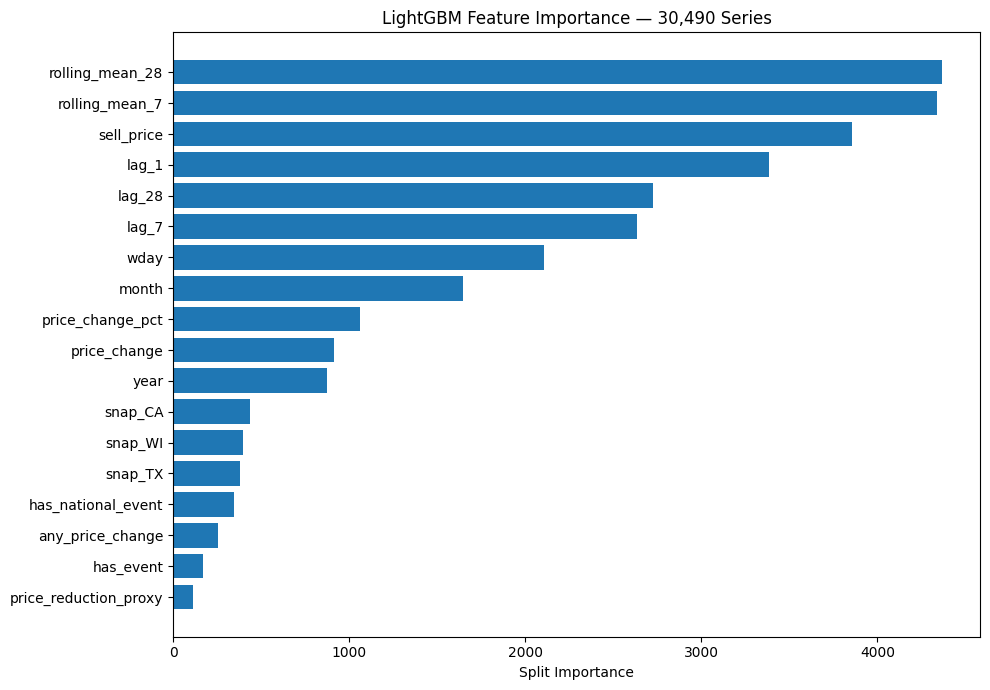

In [160]:
importance_df = pd.DataFrame({
    "feature": selected_features,
    "importance": model_30490.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
).reset_index(drop=True)

display(importance_df)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))
plt.barh(
    importance_df["feature"][::-1],
    importance_df["importance"][::-1]
)
plt.xlabel("Split Importance")
plt.title("LightGBM Feature Importance — 30,490 Series")
plt.tight_layout()
plt.show()

In [161]:
import joblib
import json
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation"
)
output_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model_30490,
    output_dir / "lightgbm_enhanced_30490_series.pkl"
)

predictions_output = pd.DataFrame({
    "id": validation_data["id"].values,
    "date": validation_data["date"].values,
    "actual": y_valid_full.values,
    "predicted": predictions_30490
})

predictions_output.to_csv(
    output_dir / "lightgbm_enhanced_30490_predictions.csv",
    index=False
)

importance_df.to_csv(
    output_dir / "lightgbm_enhanced_30490_feature_importance.csv",
    index=False
)

metrics_30490 = {
    "model": "LightGBM Enhanced",
    "series_count": 30490,
    "training_sample_rows": 4573500,
    "validation_rows": 853720,
    "features": selected_features,
    "sampling_per_series": 150,
    "sampling_seed": 42,
    "best_iteration": model_30490.best_iteration_,
    "training_time_minutes": round(training_time / 60, 2),
    "MAE": float(mae_30490),
    "RMSE": float(rmse_30490),
    "WAPE_percent": float(wape_30490),
    "evaluation_type": "One-day-ahead rolling validation",
    "training_method": "150 sampled training dates per series"
}

with open(output_dir / "lightgbm_enhanced_30490_metadata.json", "w") as f:
    json.dump(metrics_30490, f, indent=4)

print("All artifacts saved successfully.")
print("Output directory:", output_dir)
print("\nSaved files:")
for file in sorted(output_dir.glob("lightgbm_enhanced_30490*")):
    print(file.name, f"({file.stat().st_size / (1024**2):.2f} MB)")

All artifacts saved successfully.
Output directory: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation

Saved files:
lightgbm_enhanced_30490_feature_importance.csv (0.00 MB)
lightgbm_enhanced_30490_metadata.json (0.00 MB)
lightgbm_enhanced_30490_predictions.csv (52.02 MB)
lightgbm_enhanced_30490_series.pkl (3.42 MB)


In [162]:
import joblib
import json
import pandas as pd
from pathlib import Path

output_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation"
)

saved_model = joblib.load(
    output_dir / "lightgbm_enhanced_30490_series.pkl"
)

saved_predictions = pd.read_csv(
    output_dir / "lightgbm_enhanced_30490_predictions.csv"
)

saved_importance = pd.read_csv(
    output_dir / "lightgbm_enhanced_30490_feature_importance.csv"
)

with open(output_dir / "lightgbm_enhanced_30490_metadata.json") as f:
    saved_metadata = json.load(f)

print("Model loaded:", type(saved_model).__name__)
print("Prediction rows:", len(saved_predictions))
print("Feature importance rows:", len(saved_importance))
print("Metadata model:", saved_metadata["model"])
print("Metadata WAPE:", saved_metadata["WAPE_percent"])
print("Unique prediction series:", saved_predictions["id"].nunique())

Model loaded: LGBMRegressor
Prediction rows: 853720
Feature importance rows: 18
Metadata model: LightGBM Enhanced
Metadata WAPE: 69.85098427302789
Unique prediction series: 30490


In [163]:
import requests

try:
    response = requests.get("http://127.0.0.1:8050", timeout=5)
    print("Dash status:", response.status_code)
    print("Server is responding.")
except requests.exceptions.RequestException as e:
    print("Dash server is not responding.")
    print(e)

Dash status: 200
Server is responding.


In [164]:
from google.colab import output

dashboard_url = output.eval_js(
    "google.colab.kernel.proxyPort(8050)"
)

print("Dashboard URL:")
print(dashboard_url)

Dashboard URL:
https://8050-m-s-usc1c10-1yvy148gk4tzw-c.us-central1.prod.r.colab.dev


In [166]:
def inspect_layout(component, level=0):
    indent = "  " * level

    if isinstance(component, list):
        for i, child in enumerate(component):
            print(f"{indent}[{i}]")
            inspect_layout(child, level + 1)
        return

    print(
        indent,
        "Type:", type(component).__name__,
        "| ID:", getattr(component, "id", None),
        "| Children:", str(getattr(component, "children", ""))[:180]
    )

inspect_layout(app.layout)

 Type: Div | ID: None | Children: [H1(children='NEXVIA | Nationwide Demand Forecasting & Inventory Optimization', style={'textAlign': 'center', 'color': '#172554'}), P(children='M5 Forecasting Dataset | 28-Day Vali


In [168]:
app.layout.children[0].children = (
    "Nationwide Demand Forecasting & Inventory Optimization"
)

print("Title updated successfully.")
print("New title:", app.layout.children[0].children)

Title updated successfully.
New title: Nationwide Demand Forecasting & Inventory Optimization


In [2]:
from pathlib import Path

dashboard_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard"
)

forecast_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation"
)

print("DASHBOARD FILES")
print("-" * 45)

for file in sorted(dashboard_dir.glob("*")):
    print(file.name)

print("\nFORECAST ARTIFACTS")
print("-" * 45)

for file in sorted(forecast_dir.glob("*")):
    if "30490" in file.name:
        print(file.name)


DASHBOARD FILES
---------------------------------------------

FORECAST ARTIFACTS
---------------------------------------------


In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
from pathlib import Path

project = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT"
)

folders = [
    project / "models/dashboard",
    project / "models/forecast_evaluation",
    project / "models/inventory_optimization",
    project / "models/darts_reconciliation",
]

for folder in folders:
    print(f"\n📁 {folder.name}")
    print("-" * 55)

    if folder.exists():
        files = sorted(folder.glob("*"))

        if files:
            for file in files:
                print(file.name)
        else:
            print("Folder is empty")
    else:
        print("Folder does not exist")


📁 dashboard
-------------------------------------------------------
common_model_comparison.csv
corrected_portfolio_daily_plan.csv
corrected_portfolio_item_summary.csv
corrected_portfolio_store_summary.csv
dashboard_layout.json
final_dashboard_metadata.json
overall_model_comparison.csv

📁 forecast_evaluation
-------------------------------------------------------
all_model_comparison.csv
combined_prediction_intervals.csv
common_evaluation_scope.json
common_model_comparison.csv
common_model_predictions.csv
fixed_origin_evaluation_scope.json
fixed_origin_model_comparison.csv
fixed_origin_predictions.csv
interval_model_comparison.csv
lightgbm_2000_series_metadata.json
lightgbm_2000_series_predictions.csv
lightgbm_enhanced_23_features.pkl
lightgbm_enhanced_30490_feature_importance.csv
lightgbm_enhanced_30490_metadata.json
lightgbm_enhanced_30490_predictions.csv
lightgbm_enhanced_30490_series.pkl
lightgbm_feature_ablation_comparison.csv
lightgbm_selected_18_features.pkl
lightgbm_selected_1

In [7]:
import json
import pandas as pd
from pathlib import Path

project = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT"
)

files_to_inspect = {
    "Dashboard metadata": project / "models/dashboard/final_dashboard_metadata.json",
    "Dashboard layout": project / "models/dashboard/dashboard_layout.json",
    "Inventory metadata": project / "models/inventory_optimization/corrected_optimization_metadata.json",
    "LightGBM metadata": project / "models/forecast_evaluation/lightgbm_enhanced_30490_metadata.json",
}

for label, path in files_to_inspect.items():
    print(f"\n{'='*65}")
    print(label)
    print(f"{'='*65}")

    if path.exists():
        if path.suffix == ".json":
            with open(path) as f:
                data = json.load(f)
            print(json.dumps(data, indent=2)[:5000])
    else:
        print("File not found:", path)

print("\nFORECAST COMPARISON COLUMNS")
comparison = pd.read_csv(
    project / "models/forecast_evaluation/fixed_origin_model_comparison.csv"
)
print(comparison.columns.tolist())
display(comparison.head())

print("\nINVENTORY DATA COLUMNS")
inventory = pd.read_csv(
    project / "models/inventory_optimization/corrected_portfolio_daily_plan.csv"
)
print(inventory.columns.tolist())
display(inventory.head())


Dashboard metadata
{
  "created_at": "2026-11-17T11:45:31.986173",
  "dashboard_sections": 12,
  "charts": [
    {
      "id": "nationwide-forecast-chart",
      "traces": 4
    },
    {
      "id": "inventory-chart",
      "traces": 1
    },
    {
      "id": "demand-chart",
      "traces": 2
    },
    {
      "id": "cost-chart",
      "traces": 1
    },
    {
      "id": "portfolio-inventory-chart",
      "traces": 2
    },
    {
      "id": "portfolio-demand-chart",
      "traces": 1
    },
    {
      "id": "portfolio-cost-chart",
      "traces": 1
    }
  ],
  "inventory_solver_status": {
    "OPTIMAL": 472,
    "FEASIBLE": 93,
    "FAILED": 0
  },
  "inventory_validation": {
    "inventory_mismatches": 0,
    "shortage_mismatches": 0,
    "simultaneous_stock_and_shortage": 0
  },
  "inventory_scope": "565 HOBBIES item-store series in CA_1",
  "forecast_horizon_days": 28,
  "cost_assumptions_are_simulated": true
}

Dashboard layout
{
  "props": {
    "children": [
      "H1(chil

,Model,MAE,RMSE,WAPE (%),RMSSE
0,Naive (Fixed Origin),1.225943,2.987939,99.008924,0.900947
1,LightGBM (Recursive),1.140862,2.610296,92.137678,0.811870
2,TFT (Fixed Origin),1.062693,2.777522,85.824656,0.831712



INVENTORY DATA COLUMNS
['item_id', 'date', 'forecast_demand', 'recommended_order', 'ending_inventory', 'unmet_demand']


,item_id,date,forecast_demand,recommended_order,ending_inventory,unmet_demand
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.002408,0.0,7.997592,0.0
1,HOBBIES_1_001_CA_1_validation,2016-03-29,2.001993,0.0,5.995599,0.0
2,HOBBIES_1_001_CA_1_validation,2016-03-30,2.002057,0.0,3.993542,0.0
3,HOBBIES_1_001_CA_1_validation,2016-03-31,0.002185,0.0,3.991357,0.0
4,HOBBIES_1_001_CA_1_validation,2016-04-01,1.002024,0.0,2.989332,0.0


In [8]:
import pandas as pd
import json
from pathlib import Path

forecast_dir = project / "models/forecast_evaluation"
inventory_dir = project / "models/inventory_optimization"
darts_dir = project / "models/darts_reconciliation"

files = [
    forecast_dir / "prophet_nationwide_actual_vs_forecast.csv",
    forecast_dir / "combined_prediction_intervals.csv",
    forecast_dir / "lightgbm_enhanced_30490_feature_importance.csv",
    forecast_dir / "fixed_origin_predictions.csv",
    inventory_dir / "corrected_portfolio_item_summary.csv",
    inventory_dir / "corrected_portfolio_daily_plan.csv",
]

for path in files:
    print(f"\n{'='*65}")
    print(path.name)

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print("NOT FOUND")

hierarchy_path = darts_dir / "m5_hobbies_ca1_hierarchy.json"

print("\nHIERARCHY METADATA")
with open(hierarchy_path) as f:
    hierarchy = json.load(f)

print(json.dumps(hierarchy, indent=2)[:3000])


prophet_nationwide_actual_vs_forecast.csv
Shape: (28, 6)
Columns: ['ds', 'actual', 'yhat', 'yhat_lower', 'yhat_upper', 'error']


,ds,actual,yhat,yhat_lower,yhat_upper,error
0,2016-03-28,36041,40004.447661,33606.373134,46378.668943,-3963.447661
1,2016-03-29,33857,37520.988872,30775.730640,44358.935729,-3663.988872
2,2016-03-30,32359,37192.350434,30800.007298,44261.053789,-4833.350434



combined_prediction_intervals.csv
Shape: (2800, 14)
Columns: ['id', 'date', 'actual', 'naive_fixed_pred', 'lgbm_fixed_pred', 'tft_fixed_pred', 'tft_lower_80', 'tft_upper_80', 'tft_lower_96', 'tft_upper_96', 'lgbm_lower_80', 'lgbm_upper_80', 'lgbm_lower_96', 'lgbm_upper_96']


,id,date,actual,naive_fixed_pred,lgbm_fixed_pred,tft_fixed_pred,tft_lower_80,tft_upper_80,tft_lower_96,tft_upper_96,lgbm_lower_80,lgbm_upper_80,lgbm_lower_96,lgbm_upper_96
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.0,1.0,0.915177,0.673424,0.006029,1.567191,0.0,2.384403,0.0,2.608592,0.0,3.833389
1,HOBBIES_1_001_CA_1_validation,2016-03-29,0.0,2.0,0.861639,0.468030,0.000000,1.680255,0.0,2.868097,0.0,2.605173,0.0,3.956609
2,HOBBIES_1_001_CA_1_validation,2016-03-30,0.0,2.0,0.837188,0.413505,0.000000,1.716388,0.0,2.898140,0.0,2.498681,0.0,3.667799



lightgbm_enhanced_30490_feature_importance.csv
Shape: (18, 2)
Columns: ['feature', 'importance']


,feature,importance
0,rolling_mean_28,4365
1,rolling_mean_7,4338
2,sell_price,3857


... (3 outputs left out)

,item_id,initial_inventory,forecast_demand,total_ordered,order_days,unmet_demand,ending_inventory,optimization_cost,solver_status
0,HOBBIES_1_001_CA_1_validation,9.0,32.060463,24.0,5,0.036690,0.976227,1900.625244,FEASIBLE
1,HOBBIES_1_002_CA_1_validation,5.0,16.058185,10.0,3,1.058185,0.000000,1030.342700,FEASIBLE
2,HOBBIES_1_003_CA_1_validation,3.0,8.060463,0.0,0,5.060463,0.000000,798.782381,FEASIBLE



corrected_portfolio_daily_plan.csv
Shape: (15820, 6)
Columns: ['item_id', 'date', 'forecast_demand', 'recommended_order', 'ending_inventory', 'unmet_demand']


,item_id,date,forecast_demand,recommended_order,ending_inventory,unmet_demand
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.002408,0.0,7.997592,0.0
1,HOBBIES_1_001_CA_1_validation,2016-03-29,2.001993,0.0,5.995599,0.0
2,HOBBIES_1_001_CA_1_validation,2016-03-30,2.002057,0.0,3.993542,0.0



HIERARCHY METADATA
{
  "HOBBIES_1_001_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "DEPT_HOBBIES_1_CA_1": [
    "CAT_HOBBIES_CA_1"
  ],
  "HOBBIES_1_002_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_003_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_004_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_005_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_006_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_007_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_008_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_009_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_010_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_011_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_012_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_013_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_014_CA_1_validation": [
  

In [9]:
import pandas as pd
import json
from pathlib import Path

project = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT"
)

forecast_dir = project / "models/forecast_evaluation"
inventory_dir = project / "models/inventory_optimization"
darts_dir = project / "models/darts_reconciliation"

# Forecasting data
prophet_data = pd.read_csv(
    forecast_dir / "prophet_nationwide_actual_vs_forecast.csv"
)

lightgbm_predictions = pd.read_csv(
    forecast_dir / "lightgbm_enhanced_30490_predictions.csv"
)

lightgbm_importance = pd.read_csv(
    forecast_dir / "lightgbm_enhanced_30490_feature_importance.csv"
)

fixed_predictions = pd.read_csv(
    forecast_dir / "fixed_origin_predictions.csv"
)

interval_data = pd.read_csv(
    forecast_dir / "combined_prediction_intervals.csv"
)

# Inventory data
inventory_daily = pd.read_csv(
    inventory_dir / "corrected_portfolio_daily_plan.csv"
)

inventory_items = pd.read_csv(
    inventory_dir / "corrected_portfolio_item_summary.csv"
)

# Hierarchical reconciliation
reconciled_forecast = pd.read_parquet(
    darts_dir / "m5_hobbies_ca1_28day_reconciled_forecast.parquet"
)

print("DATA LOADED SUCCESSFULLY")
print("-" * 50)

datasets = {
    "Prophet": prophet_data,
    "Enhanced LightGBM": lightgbm_predictions,
    "Fixed-origin predictions": fixed_predictions,
    "Prediction intervals": interval_data,
    "Inventory daily": inventory_daily,
    "Inventory items": inventory_items,
    "Darts reconciliation": reconciled_forecast
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

print("\nAll datasets loaded.")

DATA LOADED SUCCESSFULLY
--------------------------------------------------
Prophet: (28, 6)
Enhanced LightGBM: (853720, 4)
Fixed-origin predictions: (2800, 6)
Prediction intervals: (2800, 14)
Inventory daily: (15820, 6)
Inventory items: (565, 9)
Darts reconciliation: (28, 568)

All datasets loaded.


In [10]:
import numpy as np

print("=" * 65)
print("FORECASTING INTELLIGENCE")
print("=" * 65)

prophet_wape = (
    prophet_data["error"].abs().sum()
    / prophet_data["actual"].sum()
) * 100

prophet_bias = (
    prophet_data["yhat"].sum()
    - prophet_data["actual"].sum()
) / prophet_data["actual"].sum() * 100

print(f"Prophet nationwide WAPE: {prophet_wape:.2f}%")
print(f"Prophet forecast bias: {prophet_bias:.2f}%")

print("\nTop 5 LightGBM features:")
display(lightgbm_importance.head(5))

print("\n" + "=" * 65)
print("PREDICTION INTERVAL ANALYSIS")
print("=" * 65)

for model_name, lower, upper in [
    ("TFT 80%", "tft_lower_80", "tft_upper_80"),
    ("TFT 96%", "tft_lower_96", "tft_upper_96"),
    ("LightGBM 80%", "lgbm_lower_80", "lgbm_upper_80"),
    ("LightGBM 96%", "lgbm_lower_96", "lgbm_upper_96")
]:
    coverage = (
        (interval_data["actual"] >= interval_data[lower]) &
        (interval_data["actual"] <= interval_data[upper])
    ).mean() * 100

    width = (interval_data[upper] - interval_data[lower]).mean()

    print(f"{model_name}: Coverage={coverage:.2f}%, Width={width:.3f}")

print("\n" + "=" * 65)
print("INVENTORY INTELLIGENCE")
print("=" * 65)

print("Items optimized:", len(inventory_items))
print("Items with unmet demand:", (inventory_items["unmet_demand"] > 0).sum())
print("Items without unmet demand:", (inventory_items["unmet_demand"] == 0).sum())

print("Total forecast demand:", round(inventory_items["forecast_demand"].sum(), 2))
print("Total recommended orders:", round(inventory_items["total_ordered"].sum(), 2))
print("Total unmet demand:", round(inventory_items["unmet_demand"].sum(), 2))

print("\nSolver status:")
print(inventory_items["solver_status"].value_counts())

print("\nTop 10 items by unmet demand:")
display(
    inventory_items.sort_values(
        "unmet_demand", ascending=False
    ).head(10)[["item_id", "forecast_demand", "total_ordered", "unmet_demand", "solver_status"]]
)

print("\n" + "=" * 65)
print("HIERARCHICAL RECONCILIATION")
print("=" * 65)

print("Forecast shape:", reconciled_forecast.shape)
print("Hierarchy components:", reconciled_forecast.shape[1])
print("Forecast dates:", len(reconciled_forecast))

FORECASTING INTELLIGENCE
Prophet nationwide WAPE: 6.19%
Prophet forecast bias: -2.65%

Top 5 LightGBM features:


,feature,importance
0,rolling_mean_28,4365
1,rolling_mean_7,4338
2,sell_price,3857
3,lag_1,3386
4,lag_28,2726



PREDICTION INTERVAL ANALYSIS
TFT 80%: Coverage=83.57%, Width=3.160
TFT 96%: Coverage=96.79%, Width=5.579
LightGBM 80%: Coverage=90.29%, Width=3.210
LightGBM 96%: Coverage=98.00%, Width=5.389

INVENTORY INTELLIGENCE
Items optimized: 565
Items with unmet demand: 269
Items without unmet demand: 289
Total forecast demand: 13309.65
Total recommended orders: 9580.0
Total unmet demand: 152.76

Solver status:
solver_status
OPTIMAL     472
FEASIBLE     93
Name: count, dtype: int64

Top 10 items by unmet demand:


,item_id,forecast_demand,total_ordered,unmet_demand,solver_status
319,HOBBIES_1_328_CA_1_validation,12.038327,0.0,8.038327,FEASIBLE
480,HOBBIES_2_065_CA_1_validation,12.009942,0.0,8.009942,FEASIBLE
21,HOBBIES_1_022_CA_1_validation,12.107250,1.0,7.107250,FEASIBLE
26,HOBBIES_1_027_CA_1_validation,12.052873,1.0,7.052873,FEASIBLE
118,HOBBIES_1_123_CA_1_validation,12.038931,1.0,7.038931,FEASIBLE
282,HOBBIES_1_290_CA_1_validation,12.027548,1.0,7.027548,FEASIBLE
468,HOBBIES_2_053_CA_1_validation,12.012522,1.0,7.012522,FEASIBLE
500,HOBBIES_2_085_CA_1_validation,12.005642,1.0,7.005642,FEASIBLE
67,HOBBIES_1_069_CA_1_validation,12.078408,3.0,6.070012,FEASIBLE
2,HOBBIES_1_003_CA_1_validation,8.060463,0.0,5.060463,FEASIBLE



HIERARCHICAL RECONCILIATION
Forecast shape: (28, 568)
Hierarchy components: 568
Forecast dates: 28


In [12]:
!pip install dash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 1.7 MB/s  0:00:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [dash]


In [13]:
import plotly
import dash
import plotly.graph_objects as go
from plotly.subplots import make_subplots

print("Plotly:", plotly.__version__)
print("Dash:", dash.__version__)
print("Dashboard visualization libraries ready.")


Plotly: 5.24.1
Dash: 4.5.0
Dashboard visualization libraries ready.


In [14]:
print("Inventory rows:", len(inventory_items))
print("\nMissing values:")
print(inventory_items.isna().sum())

print("\nUnmet demand distribution:")
print(inventory_items["unmet_demand"].describe())

print("\nUnmet demand classification:")
print("Positive:", (inventory_items["unmet_demand"] > 0).sum())
print("Exactly zero:", (inventory_items["unmet_demand"] == 0).sum())
print("Negative:", (inventory_items["unmet_demand"] < 0).sum())
print("NaN:", inventory_items["unmet_demand"].isna().sum())

print("\nSolver status:")
print(inventory_items["solver_status"].value_counts(dropna=False))

Inventory rows: 565

Missing values:
item_id              0
initial_inventory    0
forecast_demand      0
total_ordered        0
order_days           0
unmet_demand         0
ending_inventory     0
optimization_cost    0
solver_status        0
dtype: int64

Unmet demand distribution:
count    5.650000e+02
mean     2.703776e-01
std      1.138899e+00
min     -5.329071e-15
25%      0.000000e+00
50%      0.000000e+00
75%      2.554309e-02
max      8.038327e+00
Name: unmet_demand, dtype: float64

Unmet demand classification:
Positive: 269
Exactly zero: 289
Negative: 7
NaN: 0

Solver status:
solver_status
OPTIMAL     472
FEASIBLE     93
Name: count, dtype: int64


In [15]:
datasets = {
    "Prophet": prophet_data,
    "LightGBM": lightgbm_predictions,
    "Fixed Origin": fixed_predictions,
    "Intervals": interval_data,
    "Inventory Daily": inventory_daily,
    "Inventory Items": inventory_items,
    "Darts Reconciliation": reconciled_forecast
}

for name, df in datasets.items():
    print(f"\n{'='*55}")
    print(name, "| Shape:", df.shape)
    print("Columns:", list(df.columns))
    print(df.dtypes.astype(str).to_dict())


Prophet | Shape: (28, 6)
Columns: ['ds', 'actual', 'yhat', 'yhat_lower', 'yhat_upper', 'error']
{'ds': 'object', 'actual': 'int64', 'yhat': 'float64', 'yhat_lower': 'float64', 'yhat_upper': 'float64', 'error': 'float64'}

LightGBM | Shape: (853720, 4)
Columns: ['id', 'date', 'actual', 'predicted']
{'id': 'object', 'date': 'object', 'actual': 'float64', 'predicted': 'float64'}

Fixed Origin | Shape: (2800, 6)
Columns: ['id', 'date', 'actual', 'naive_fixed_pred', 'lgbm_fixed_pred', 'tft_fixed_pred']
{'id': 'object', 'date': 'object', 'actual': 'float64', 'naive_fixed_pred': 'float64', 'lgbm_fixed_pred': 'float64', 'tft_fixed_pred': 'float64'}

Intervals | Shape: (2800, 14)
Columns: ['id', 'date', 'actual', 'naive_fixed_pred', 'lgbm_fixed_pred', 'tft_fixed_pred', 'tft_lower_80', 'tft_upper_80', 'tft_lower_96', 'tft_upper_96', 'lgbm_lower_80', 'lgbm_upper_80', 'lgbm_lower_96', 'lgbm_upper_96']
{'id': 'object', 'date': 'object', 'actual': 'float64', 'naive_fixed_pred': 'float64', 'lgbm_fix

## 12. Dashboard Metrics and Visualizations

In [17]:
# Prepare date columns
prophet_data["ds"] = pd.to_datetime(prophet_data["ds"])
lightgbm_predictions["date"] = pd.to_datetime(lightgbm_predictions["date"])
fixed_predictions["date"] = pd.to_datetime(fixed_predictions["date"])
interval_data["date"] = pd.to_datetime(interval_data["date"])
inventory_daily["date"] = pd.to_datetime(inventory_daily["date"])

# Aggregate inventory by day
inventory_daily_summary = (
    inventory_daily.groupby("date", as_index=False)
    .agg({
        "forecast_demand": "sum",
        "recommended_order": "sum",
        "ending_inventory": "sum",
        "unmet_demand": "sum"
    })
)

# Prepare inventory reporting classification
inventory_items["unmet_demand_reporting"] = (
    inventory_items["unmet_demand"].abs() > 1e-8
)

# Prepare hierarchy series
hierarchy_parent_columns = [
    "CAT_HOBBIES_CA_1",
    "DEPT_HOBBIES_1_CA_1",
    "DEPT_HOBBIES_2_CA_1"
]

hierarchy_bottom_columns = [
    col for col in reconciled_forecast.columns
    if col not in hierarchy_parent_columns
]

print("Dashboard data preparation complete.")
print("Prophet date range:", prophet_data["ds"].min(), "to", prophet_data["ds"].max())
print("Inventory daily summary:", inventory_daily_summary.shape)
print("Inventory items with unmet demand:", inventory_items["unmet_demand_reporting"].sum())
print("Hierarchy parent nodes:", len(hierarchy_parent_columns))
print("Hierarchy bottom-level series:", len(hierarchy_bottom_columns))
print("Total hierarchy components:", len(reconciled_forecast.columns))

Dashboard data preparation complete.
Prophet date range: 2016-03-28 00:00:00 to 2016-04-24 00:00:00
Inventory daily summary: (28, 5)
Inventory items with unmet demand: 264
Hierarchy parent nodes: 3
Hierarchy bottom-level series: 565
Total hierarchy components: 568


In [18]:
unmet = inventory_items["unmet_demand"]

print("Positive unmet demand:", (unmet > 0).sum())
print("Meaningful unmet demand (> 1e-8):", (unmet > 1e-8).sum())
print("Tiny positive residuals (0 to 1e-8]:", ((unmet > 0) & (unmet <= 1e-8)).sum())
print("Tiny negative residuals (>= -1e-8):", ((unmet < 0) & (unmet >= -1e-8)).sum())

print("\nSmallest positive values:")
print(
    inventory_items.loc[unmet.between(0, 1e-8), ["item_id", "unmet_demand"]]
    .sort_values("unmet_demand")
    .to_string(index=False)
)

Positive unmet demand: 269
Meaningful unmet demand (> 1e-8): 264
Tiny positive residuals (0 to 1e-8]: 5
Tiny negative residuals (>= -1e-8): 7

Smallest positive values:
                      item_id  unmet_demand
HOBBIES_1_412_CA_1_validation  0.000000e+00
HOBBIES_1_422_CA_1_validation  0.000000e+00
HOBBIES_1_420_CA_1_validation  0.000000e+00
HOBBIES_1_419_CA_1_validation  0.000000e+00
HOBBIES_1_418_CA_1_validation  0.000000e+00
HOBBIES_1_417_CA_1_validation  0.000000e+00
HOBBIES_1_416_CA_1_validation  0.000000e+00
HOBBIES_1_415_CA_1_validation  0.000000e+00
HOBBIES_1_414_CA_1_validation  0.000000e+00
HOBBIES_1_413_CA_1_validation  0.000000e+00
HOBBIES_1_423_CA_1_validation  0.000000e+00
HOBBIES_1_411_CA_1_validation  0.000000e+00
HOBBIES_1_410_CA_1_validation  0.000000e+00
HOBBIES_1_408_CA_1_validation  0.000000e+00
HOBBIES_1_407_CA_1_validation  0.000000e+00
HOBBIES_1_406_CA_1_validation  0.000000e+00
HOBBIES_1_405_CA_1_validation  0.000000e+00
HOBBIES_1_404_CA_1_validation  0.000000

In [19]:
# Executive Overview metrics

total_series = 30490
total_observations = 58327370
validation_days = 28

inventory_demand = inventory_items["forecast_demand"].sum()
inventory_orders = inventory_items["total_ordered"].sum()
inventory_unmet = inventory_items["unmet_demand"].clip(lower=0).sum()
inventory_cost = inventory_items["optimization_cost"].sum()

items_with_shortage = (
    inventory_items["unmet_demand"] > 1e-8
).sum()

items_without_shortage = len(inventory_items) - items_with_shortage

solver_counts = inventory_items["solver_status"].value_counts()

executive_metrics = {
    "Total Series": total_series,
    "Historical Observations": total_observations,
    "Validation Horizon": validation_days,
    "Inventory Items": len(inventory_items),
    "Forecast Demand": round(inventory_demand, 2),
    "Recommended Orders": round(inventory_orders, 2),
    "Unmet Demand": round(inventory_unmet, 2),
    "Optimization Cost": round(inventory_cost, 2),
    "Items With Shortage": int(items_with_shortage),
    "Items Without Meaningful Shortage": int(items_without_shortage),
    "Optimal Solutions": int(solver_counts.get("OPTIMAL", 0)),
    "Feasible Solutions": int(solver_counts.get("FEASIBLE", 0))
}

for metric, value in executive_metrics.items():
    print(f"{metric}: {value}")

Total Series: 30490
Historical Observations: 58327370
Validation Horizon: 28
Inventory Items: 565
Forecast Demand: 13309.65
Recommended Orders: 9580.0
Unmet Demand: 152.76
Optimization Cost: 713529.54
Items With Shortage: 264
Items Without Meaningful Shortage: 301
Optimal Solutions: 472
Feasible Solutions: 93


In [20]:
# Forecasting KPI calculations

prophet_wape = (
    prophet_data["actual"].sub(prophet_data["yhat"]).abs().sum()
    / prophet_data["actual"].sum()
) * 100

prophet_bias = (
    (prophet_data["yhat"].sum() - prophet_data["actual"].sum())
    / prophet_data["actual"].sum()
) * 100

lgbm_actual = lightgbm_predictions["actual"]
lgbm_predicted = lightgbm_predictions["predicted"]

lgbm_mae = (lgbm_actual - lgbm_predicted).abs().mean()
lgbm_rmse = ((lgbm_actual - lgbm_predicted) ** 2).mean() ** 0.5
lgbm_wape = (
    (lgbm_actual - lgbm_predicted).abs().sum()
    / lgbm_actual.sum()
) * 100

fixed_metrics = {}

for model, column in {
    "Naive": "naive_fixed_pred",
    "LightGBM": "lgbm_fixed_pred",
    "TFT": "tft_fixed_pred"
}.items():
    errors = fixed_predictions["actual"] - fixed_predictions[column]

    fixed_metrics[model] = {
        "MAE": errors.abs().mean(),
        "RMSE": (errors.pow(2).mean()) ** 0.5,
        "WAPE": errors.abs().sum() / fixed_predictions["actual"].sum() * 100
    }

print("PROPHET — Nationwide aggregate, 28 days")
print(f"WAPE: {prophet_wape:.2f}%")
print(f"Forecast bias: {prophet_bias:.2f}%")

print("\nLIGHTGBM — 30,490 series, rolling one-day-ahead validation")
print(f"MAE: {lgbm_mae:.4f}")
print(f"RMSE: {lgbm_rmse:.4f}")
print(f"WAPE: {lgbm_wape:.2f}%")

print("\nFIXED-ORIGIN — 100 series, 28-day forecast")
for model, metrics in fixed_metrics.items():
    print(model, {
        key: round(value, 4)
        for key, value in metrics.items()
    })

PROPHET — Nationwide aggregate, 28 days
WAPE: 6.19%
Forecast bias: -2.65%

LIGHTGBM — 30,490 series, rolling one-day-ahead validation
MAE: 0.9684
RMSE: 1.9353
WAPE: 69.85%

FIXED-ORIGIN — 100 series, 28-day forecast
Naive {'MAE': np.float64(1.2259), 'RMSE': np.float64(2.9879), 'WAPE': np.float64(99.0089)}
LightGBM {'MAE': np.float64(1.1409), 'RMSE': np.float64(2.6103), 'WAPE': np.float64(92.1377)}
TFT {'MAE': np.float64(1.0627), 'RMSE': np.float64(2.7775), 'WAPE': np.float64(85.8247)}


In [21]:
interval_results = {
    "TFT 80%": {
        "coverage": 83.571,
        "width": 3.160
    },
    "TFT 96%": {
        "coverage": 96.786,
        "width": 5.579
    },
    "LightGBM 80%": {
        "coverage": 90.286,
        "width": 3.210
    },
    "LightGBM 96%": {
        "coverage": 98.000,
        "width": 5.389
    }
}

interval_summary = pd.DataFrame([
    {
        "Model": model,
        "Nominal Coverage": float(model.split()[-1].replace("%", "")),
        "Actual Coverage": values["coverage"],
        "Average Interval Width": values["width"]
    }
    for model, values in interval_results.items()
])

print(interval_summary.to_string(index=False))
print("\nEvaluation scope: 100 item-store series, 28-day fixed-origin forecast.")

       Model  Nominal Coverage  Actual Coverage  Average Interval Width
     TFT 80%              80.0           83.571                   3.160
     TFT 96%              96.0           96.786                   5.579
LightGBM 80%              80.0           90.286                   3.210
LightGBM 96%              96.0           98.000                   5.389

Evaluation scope: 100 item-store series, 28-day fixed-origin forecast.


In [22]:
from dash import Dash, html, dcc
import plotly.graph_objects as go
import plotly.express as px

# Enterprise dashboard theme
COLORS = {
    "navy": "#14243A",
    "blue": "#2563EB",
    "cyan": "#0891B2",
    "green": "#059669",
    "orange": "#D97706",
    "red": "#DC2626",
    "background": "#F3F6FA",
    "white": "#FFFFFF",
    "text": "#243247",
    "muted": "#64748B",
    "border": "#E2E8F0"
}

def kpi_card(title, value, subtitle, accent):
    return html.Div([
        html.Div(title, style={
            "fontSize": "13px",
            "color": COLORS["muted"],
            "fontWeight": "600"
        }),
        html.Div(value, style={
            "fontSize": "27px",
            "fontWeight": "700",
            "color": COLORS["navy"],
            "marginTop": "10px"
        }),
        html.Div(subtitle, style={
            "fontSize": "11px",
            "color": COLORS["muted"],
            "marginTop": "7px"
        })
    ], style={
        "background": COLORS["white"],
        "padding": "22px",
        "borderRadius": "12px",
        "border": f"1px solid {COLORS['border']}",
        "borderTop": f"4px solid {accent}",
        "minWidth": "160px",
        "flex": "1"
    })

overview_cards = html.Div([
    kpi_card("ITEM-STORE SERIES", "30,490", "Across 10 stores and 3 states", COLORS["blue"]),
    kpi_card("HISTORICAL OBSERVATIONS", "58.33M", "Daily sales records", COLORS["cyan"]),
    kpi_card("FORECAST HORIZON", "28 Days", "March 28 – April 24, 2016", COLORS["green"]),
    kpi_card("INVENTORY ITEMS", "565", "CA_1 HOBBIES subset", COLORS["orange"]),
    kpi_card("RECOMMENDED ORDERS", "9,580", "Units across the 28-day horizon", COLORS["blue"]),
    kpi_card("UNMET DEMAND", "152.76", "Forecast units remaining unmet", COLORS["red"])
], style={
    "display": "flex",
    "gap": "16px",
    "flexWrap": "wrap",
    "marginBottom": "22px"
})

print("Executive Overview KPI cards created.")
print("Number of KPI cards:", len(overview_cards.children))

Executive Overview KPI cards created.
Number of KPI cards: 6


In [23]:
# Nationwide forecast chart
fig_prophet = go.Figure()

fig_prophet.add_trace(go.Scatter(
    x=prophet_data["ds"],
    y=prophet_data["actual"],
    mode="lines",
    name="Actual Demand",
    line=dict(color=COLORS["navy"], width=2.5)
))

fig_prophet.add_trace(go.Scatter(
    x=prophet_data["ds"],
    y=prophet_data["yhat_upper"],
    mode="lines",
    line=dict(width=0),
    showlegend=False
))

fig_prophet.add_trace(go.Scatter(
    x=prophet_data["ds"],
    y=prophet_data["yhat_lower"],
    mode="lines",
    fill="tonexty",
    fillcolor="rgba(37,99,235,0.12)",
    line=dict(width=0),
    name="Prediction Interval"
))

fig_prophet.add_trace(go.Scatter(
    x=prophet_data["ds"],
    y=prophet_data["yhat"],
    mode="lines",
    name="Prophet Forecast",
    line=dict(color=COLORS["blue"], width=2.5, dash="dash")
))

fig_prophet.update_layout(
    title="Nationwide Demand | Actual vs Forecast",
    xaxis_title="Date",
    yaxis_title="Units Sold",
    template="plotly_white",
    hovermode="x unified",
    height=390,
    margin=dict(l=30, r=20, t=60, b=35)
)

# Inventory daily chart
fig_inventory_daily = go.Figure()

fig_inventory_daily.add_trace(go.Bar(
    x=inventory_daily_summary["date"],
    y=inventory_daily_summary["forecast_demand"],
    name="Forecast Demand",
    marker_color=COLORS["blue"]
))

fig_inventory_daily.add_trace(go.Bar(
    x=inventory_daily_summary["date"],
    y=inventory_daily_summary["recommended_order"],
    name="Recommended Orders",
    marker_color=COLORS["green"]
))

fig_inventory_daily.update_layout(
    title="Daily Demand vs Recommended Orders",
    xaxis_title="Date",
    yaxis_title="Units",
    barmode="group",
    template="plotly_white",
    height=390,
    margin=dict(l=30, r=20, t=60, b=35)
)

print("Executive Overview charts created.")
print("Prophet chart traces:", len(fig_prophet.data))
print("Inventory chart traces:", len(fig_inventory_daily.data))

Executive Overview charts created.
Prophet chart traces: 4
Inventory chart traces: 2


In [24]:
# Fixed-origin model comparison
fixed_metrics = pd.DataFrame([
    {"Model": "Naive", "MAE": 1.2259, "RMSE": 2.9879, "WAPE": 99.0089},
    {"Model": "LightGBM", "MAE": 1.1409, "RMSE": 2.6103, "WAPE": 92.1377},
    {"Model": "TFT", "MAE": 1.0627, "RMSE": 2.7775, "WAPE": 85.8247}
])

fig_fixed_comparison = go.Figure()

for metric, color in [
    ("MAE", COLORS["blue"]),
    ("RMSE", COLORS["cyan"])
]:
    fig_fixed_comparison.add_trace(go.Bar(
        x=fixed_metrics["Model"],
        y=fixed_metrics[metric],
        name=metric,
        marker_color=color
    ))

fig_fixed_comparison.update_layout(
    title="Fixed-Origin Forecast Comparison | 100 Series",
    xaxis_title="Model",
    yaxis_title="Error",
    barmode="group",
    template="plotly_white",
    height=370
)

# WAPE comparison
fig_fixed_wape = go.Figure(go.Bar(
    x=fixed_metrics["Model"],
    y=fixed_metrics["WAPE"],
    marker_color=[
        COLORS["orange"],
        COLORS["blue"],
        COLORS["green"]
    ],
    text=fixed_metrics["WAPE"].map(lambda x: f"{x:.2f}%"),
    textposition="outside"
))

fig_fixed_wape.update_layout(
    title="Fixed-Origin WAPE Comparison",
    yaxis_title="WAPE (%)",
    template="plotly_white",
    height=350
)

# LightGBM feature importance
importance_top = lightgbm_importance.sort_values(
    "importance", ascending=True
).tail(18)

fig_feature_importance = go.Figure(go.Bar(
    x=importance_top["importance"],
    y=importance_top["feature"],
    orientation="h",
    marker_color=COLORS["blue"]
))

fig_feature_importance.update_layout(
    title="Enhanced LightGBM | Feature Importance",
    xaxis_title="Importance",
    yaxis_title="Feature",
    template="plotly_white",
    height=560,
    margin=dict(l=140, r=25, t=60, b=35)
)

print("Forecasting Intelligence charts created.")
print("Fixed-origin models:", fixed_metrics["Model"].tolist())
print("Feature importance entries:", len(importance_top))

Forecasting Intelligence charts created.
Fixed-origin models: ['Naive', 'LightGBM', 'TFT']
Feature importance entries: 18


In [25]:
# Prepare reconciled hierarchy forecast for visualization
hierarchy_dates = pd.date_range(
    start="2016-03-28",
    periods=len(reconciled_forecast),
    freq="D"
)

fig_hierarchy = go.Figure()

hierarchy_display = {
    "CAT_HOBBIES_CA_1": "HOBBIES Category",
    "DEPT_HOBBIES_1_CA_1": "HOBBIES Department 1",
    "DEPT_HOBBIES_2_CA_1": "HOBBIES Department 2"
}

for column, label in hierarchy_display.items():
    fig_hierarchy.add_trace(go.Scatter(
        x=hierarchy_dates,
        y=reconciled_forecast[column],
        mode="lines+markers",
        name=label,
        line=dict(width=2)
    ))

fig_hierarchy.update_layout(
    title="Darts MinT Reconciled Forecast | CA_1 HOBBIES",
    xaxis_title="Forecast Date",
    yaxis_title="Forecast Units",
    template="plotly_white",
    hovermode="x unified",
    height=400
)

# Hierarchy structure summary
hierarchy_summary = pd.DataFrame([
    {"Level": "Category", "Components": 1},
    {"Level": "Departments", "Components": 2},
    {"Level": "Bottom Item-Series", "Components": len(hierarchy_bottom_columns)}
])

fig_hierarchy_structure = go.Figure(go.Bar(
    x=hierarchy_summary["Level"],
    y=hierarchy_summary["Components"],
    marker_color=[
        COLORS["blue"],
        COLORS["cyan"],
        COLORS["green"]
    ],
    text=hierarchy_summary["Components"],
    textposition="outside"
))

fig_hierarchy_structure.update_layout(
    title="Reconciliation Hierarchy Structure",
    xaxis_title="Hierarchy Level",
    yaxis_title="Number of Components",
    template="plotly_white",
    height=350
)

print("Hierarchical Reconciliation charts created.")
print("Total components:", reconciled_forecast.shape[1])
print("Category nodes:", 1)
print("Department nodes:", 2)
print("Bottom item-series:", len(hierarchy_bottom_columns))
print("Forecast horizon:", len(reconciled_forecast), "days")

Hierarchical Reconciliation charts created.
Total components: 568
Category nodes: 1
Department nodes: 2
Bottom item-series: 565
Forecast horizon: 28 days


In [26]:
# Daily inventory position
fig_inventory_position = go.Figure()

fig_inventory_position.add_trace(go.Scatter(
    x=inventory_daily_summary["date"],
    y=inventory_daily_summary["ending_inventory"],
    mode="lines+markers",
    name="Ending Inventory",
    line=dict(color=COLORS["green"], width=2.5)
))

fig_inventory_position.add_trace(go.Scatter(
    x=inventory_daily_summary["date"],
    y=inventory_daily_summary["unmet_demand"],
    mode="lines+markers",
    name="Unmet Demand",
    line=dict(color=COLORS["red"], width=2)
))

fig_inventory_position.update_layout(
    title="Daily Inventory Position and Unmet Demand",
    xaxis_title="Date",
    yaxis_title="Units",
    template="plotly_white",
    hovermode="x unified",
    height=390
)

# Optimization cost breakdown
cost_breakdown = pd.DataFrame({
    "Cost Component": [
        "Purchase Cost",
        "Ordering Cost",
        "Holding Cost",
        "Stockout Cost"
    ],
    "Cost": [
        574800,
        56250,
        59565.036547,
        22914.500367
    ]
})

fig_cost_breakdown = go.Figure(go.Pie(
    labels=cost_breakdown["Cost Component"],
    values=cost_breakdown["Cost"],
    hole=0.55,
    textinfo="label+percent"
))

fig_cost_breakdown.update_layout(
    title="Inventory Optimization Cost Breakdown",
    template="plotly_white",
    height=390
)

# Solver status
solver_counts = (
    inventory_items["solver_status"]
    .value_counts()
    .rename_axis("Solver Status")
    .reset_index(name="Items")
)

fig_solver_status = go.Figure(go.Bar(
    x=solver_counts["Solver Status"],
    y=solver_counts["Items"],
    marker_color=[COLORS["green"], COLORS["orange"]],
    text=solver_counts["Items"],
    textposition="outside"
))

fig_solver_status.update_layout(
    title="OR-Tools Solver Results",
    xaxis_title="Solver Status",
    yaxis_title="Number of Items",
    template="plotly_white",
    height=330
)

print("Inventory Intelligence charts created.")
print("Cost total:", round(cost_breakdown["Cost"].sum(), 2))
print("Solver statuses:", solver_counts.to_dict("records"))
print("Items with meaningful unmet demand:", int(inventory_items["unmet_demand_reporting"].sum()))

Inventory Intelligence charts created.
Cost total: 713529.54
Solver statuses: [{'Solver Status': 'OPTIMAL', 'Items': 472}, {'Solver Status': 'FEASIBLE', 'Items': 93}]
Items with meaningful unmet demand: 264


In [27]:
business_insights = [
    {
        "title": "Forecasting Performance",
        "finding": "TFT achieved the lowest MAE (1.0627) and WAPE (85.82%) in the fixed-origin comparison.",
        "detail": "LightGBM achieved the lowest RMSE (2.6103). Both outperformed the Naive baseline across the reported metrics."
    },
    {
        "title": "Large-Scale Demand Forecasting",
        "finding": "Enhanced LightGBM achieved 69.85% WAPE across 30,490 item-store series.",
        "detail": "This is a one-day-ahead rolling validation using 150 sampled training dates per series, not a fixed-origin 28-day evaluation."
    },
    {
        "title": "Hierarchical Consistency",
        "finding": "Darts MinT reconciliation produced 568 components across the CA_1 HOBBIES subset.",
        "detail": "The hierarchy includes one category, two departments and 565 bottom-level item series."
    },
    {
        "title": "Inventory Planning",
        "finding": "The optimizer recommended 9,580 units of orders against forecast demand of 13,309.65 units.",
        "detail": "The portfolio has 152.76 units of unmet demand across 264 items with meaningful shortages."
    },
    {
        "title": "Optimization Solver",
        "finding": "472 item-level solutions were OPTIMAL and 93 were FEASIBLE.",
        "detail": "FEASIBLE means a valid solution was found, but optimality was not proven."
    },
    {
        "title": "Prediction Uncertainty",
        "finding": "TFT's 80% interval achieved 83.57% empirical coverage; its 96% interval achieved 96.79%.",
        "detail": "Coverage was evaluated on 100 item-store series over one 28-day validation window."
    }
]

limitations = [
    "M5 does not provide actual inventory levels, lead times, supplier costs or stockout penalties. Inventory optimization uses simulated assumptions.",
    "Price-change indicators are proxies and do not confirm promotional activity.",
    "The full 39,791-node M5 hierarchy was not reconciled; the Darts demonstration covers the CA_1 HOBBIES subset.",
    "TFT and fixed-origin model comparisons use a 100-series subset.",
    "The enhanced LightGBM evaluation is one-day-ahead rolling validation, while fixed-origin evaluation measures a 28-day horizon.",
    "Reported RMSSE is an unweighted mean across series, not official M5 WRMSSE."
]

print("Business insights prepared:", len(business_insights))
print("Project limitations documented:", len(limitations))

for item in business_insights:
    print("-", item["title"], ":", item["finding"])

Business insights prepared: 6
Project limitations documented: 6
- Forecasting Performance : TFT achieved the lowest MAE (1.0627) and WAPE (85.82%) in the fixed-origin comparison.
- Large-Scale Demand Forecasting : Enhanced LightGBM achieved 69.85% WAPE across 30,490 item-store series.
- Hierarchical Consistency : Darts MinT reconciliation produced 568 components across the CA_1 HOBBIES subset.
- Inventory Planning : The optimizer recommended 9,580 units of orders against forecast demand of 13,309.65 units.
- Optimization Solver : 472 item-level solutions were OPTIMAL and 93 were FEASIBLE.
- Prediction Uncertainty : TFT's 80% interval achieved 83.57% empirical coverage; its 96% interval achieved 96.79%.


In [28]:
from dash import Dash, dcc, html, Input, Output
import plotly.graph_objects as go
import pandas as pd
from pathlib import Path

app = Dash(
    __name__,
    title="Demand Forecasting & Inventory Intelligence",
    suppress_callback_exceptions=True
)

app.layout = html.Div(
    style={
        "backgroundColor": COLORS["background"],
        "minHeight": "100vh",
        "fontFamily": "Arial, sans-serif",
        "color": COLORS["text"]
    },
    children=[
        dcc.Store(id="active-section", data="overview"),

        html.Div(
            style={
                "display": "flex",
                "minHeight": "100vh"
            },
            children=[
                # Sidebar
                html.Div(
                    style={
                        "width": "245px",
                        "backgroundColor": COLORS["navy"],
                        "padding": "28px 18px",
                        "color": "white",
                        "flexShrink": "0"
                    },
                    children=[
                        html.H2(
                            "Forecasting",
                            style={"fontSize": "22px", "marginBottom": "4px"}
                        ),
                        html.P(
                            "Demand & Inventory Intelligence",
                            style={
                                "fontSize": "11px",
                                "color": "#CBD5E1",
                                "marginBottom": "32px"
                            }
                        ),
                        html.Div(
                            [
                                html.Button(
                                    label,
                                    id=f"nav-{key}",
                                    n_clicks=0,
                                    style={
                                        "display": "block",
                                        "width": "100%",
                                        "textAlign": "left",
                                        "padding": "13px 12px",
                                        "marginBottom": "8px",
                                        "border": "none",
                                        "borderRadius": "7px",
                                        "backgroundColor": (
                                            COLORS["blue"] if key == "overview"
                                            else "transparent"
                                        ),
                                        "color": "white",
                                        "cursor": "pointer",
                                        "fontSize": "13px"
                                    }
                                )
                                for key, label in [
                                    ("overview", "Executive Overview"),
                                    ("data", "Data Intelligence"),
                                    ("forecast", "Forecasting Intelligence"),
                                    ("hierarchy", "Hierarchical Reconciliation"),
                                    ("inventory", "Inventory Intelligence"),
                                    ("insights", "Business Insights")
                                ]
                            ]
                        )
                    ]
                ),

                # Main content
                html.Div(
                    id="main-content",
                    style={
                        "flex": "1",
                        "padding": "30px",
                        "minWidth": "0"
                    }
                )
            ]
        )
    ]
)

print("Dashboard application structure created.")
print("Navigation sections: 6")
print("App title:", app.title)

Dashboard application structure created.
Navigation sections: 6
App title: Demand Forecasting & Inventory Intelligence


In [29]:
from dash import callback_context
from dash.exceptions import PreventUpdate

section_content = {
    "overview": html.Div([
        html.H2("Executive Overview"),
        html.P(
            "Demand forecasting and inventory optimization performance.",
            style={"color": COLORS["muted"]}
        ),
        overview_cards,
        html.Div(
            [
                dcc.Graph(figure=fig_prophet),
                dcc.Graph(figure=fig_inventory_daily)
            ],
            style={
                "display": "grid",
                "gridTemplateColumns": "repeat(2, minmax(0, 1fr))",
                "gap": "20px",
                "marginTop": "24px"
            }
        )
    ]),

    "data": html.Div([
        html.H2("Data Intelligence"),
        html.P("M5 Forecasting dataset profile"),
        overview_cards
    ]),

    "forecast": html.Div([
        html.H2("Forecasting Intelligence"),
        dcc.Graph(figure=fig_fixed_comparison),
        dcc.Graph(figure=fig_fixed_wape),
        dcc.Graph(figure=fig_feature_importance)
    ]),

    "hierarchy": html.Div([
        html.H2("Hierarchical Reconciliation"),
        html.P("Darts MinT | CA_1 HOBBIES subset"),
        dcc.Graph(figure=fig_hierarchy),
        dcc.Graph(figure=fig_hierarchy_structure)
    ]),

    "inventory": html.Div([
        html.H2("Inventory Intelligence"),
        dcc.Graph(figure=fig_inventory_position),
        dcc.Graph(figure=fig_cost_breakdown),
        dcc.Graph(figure=fig_solver_status)
    ]),

    "insights": html.Div([
        html.H2("Business Insights"),
        html.Div([
            html.Div([
                html.H3(item["title"]),
                html.P(item["finding"]),
                html.P(
                    item["detail"],
                    style={"color": COLORS["muted"]}
                )
            ], style={
                "backgroundColor": "white",
                "padding": "20px",
                "borderRadius": "10px",
                "border": f'1px solid {COLORS["border"]}',
                "marginBottom": "14px"
            })
            for item in business_insights
        ]),
        html.H3("Project Limitations"),
        html.Ul([html.Li(item) for item in limitations])
    ])
}

@app.callback(
    Output("main-content", "children"),
    Output("nav-overview", "style"),
    Output("nav-data", "style"),
    Output("nav-forecast", "style"),
    Output("nav-hierarchy", "style"),
    Output("nav-inventory", "style"),
    Output("nav-insights", "style"),
    Input("nav-overview", "n_clicks"),
    Input("nav-data", "n_clicks"),
    Input("nav-forecast", "n_clicks"),
    Input("nav-hierarchy", "n_clicks"),
    Input("nav-inventory", "n_clicks"),
    Input("nav-insights", "n_clicks")
)
def navigate_dashboard(*clicks):
    triggered = callback_context.triggered

    if not triggered:
        active = "overview"
    else:
        active = triggered[0]["prop_id"].split(".")[0].replace("nav-", "")

    content = section_content[active]

    styles = []
    for key in [
        "overview", "data", "forecast",
        "hierarchy", "inventory", "insights"
    ]:
        styles.append({
            "display": "block",
            "width": "100%",
            "textAlign": "left",
            "padding": "13px 12px",
            "marginBottom": "8px",
            "border": "none",
            "borderRadius": "7px",
            "backgroundColor": (
                COLORS["blue"] if key == active else "transparent"
            ),
            "color": "white",
            "cursor": "pointer",
            "fontSize": "13px"
        })

    return (content, *styles)

print("Dashboard navigation callback registered.")
print("Six dashboard sections connected.")

Dashboard navigation callback registered.
Six dashboard sections connected.


In [30]:
# Sales distribution
fig_sales_distribution = go.Figure(go.Pie(
    labels=["Zero Sales", "Positive Sales"],
    values=[39777094, 18550276],
    hole=0.58,
    marker=dict(colors=[COLORS["cyan"], COLORS["blue"]]),
    textinfo="label+percent"
))

fig_sales_distribution.update_layout(
    title="Historical Sales Distribution",
    template="plotly_white",
    height=370
)

# Dataset profile cards
data_profile_cards = html.Div(
    [
        kpi_card("ITEM-STORE SERIES", "30,490", "3,049 products × 10 stores", COLORS["blue"]),
        kpi_card("HISTORICAL OBSERVATIONS", "58.33M", "1,913 daily observations per series", COLORS["cyan"]),
        kpi_card("CALENDAR COVERAGE", "1,969 days", "Calendar records available", COLORS["green"]),
        kpi_card("SELL PRICE RECORDS", "6.84M", "Price history records", COLORS["orange"]),
        kpi_card("ZERO SALES", "68.2%", "39.78 million observations", COLORS["red"]),
        kpi_card("POSITIVE SALES", "31.8%", "18.55 million observations", COLORS["green"])
    ],
    style={
        "display": "grid",
        "gridTemplateColumns": "repeat(3, minmax(0, 1fr))",
        "gap": "16px",
        "marginTop": "20px"
    }
)

data_structure = html.Div(
    [
        html.H3("Dataset Structure"),
        html.Table(
            [
                html.Tr([html.Th("Dimension"), html.Th("Coverage")]),
                html.Tr([html.Td("Products"), html.Td("3,049")]),
                html.Tr([html.Td("Stores"), html.Td("10")]),
                html.Tr([html.Td("Departments"), html.Td("7")]),
                html.Tr([html.Td("Categories"), html.Td("3")]),
                html.Tr([html.Td("States"), html.Td("CA, TX, WI")]),
                html.Tr([html.Td("Sales missing values"), html.Td("0")]),
                html.Tr([html.Td("Negative sales values"), html.Td("0")]),
                html.Tr([html.Td("Missing sell prices"), html.Td("21.09%")])
            ],
            style={
                "width": "100%",
                "borderCollapse": "collapse",
                "backgroundColor": "white"
            }
        )
    ],
    style={
        "backgroundColor": "white",
        "padding": "20px",
        "borderRadius": "10px",
        "border": f'1px solid {COLORS["border"]}'
    }
)

section_content["data"] = html.Div([
    html.H2("Data Intelligence"),
    html.P(
        "M5 Forecasting dataset profile and historical demand characteristics.",
        style={"color": COLORS["muted"]}
    ),
    data_profile_cards,
    html.Div([
        dcc.Graph(figure=fig_sales_distribution),
        data_structure
    ], style={
        "display": "grid",
        "gridTemplateColumns": "repeat(2, minmax(0, 1fr))",
        "gap": "20px",
        "marginTop": "20px",
        "alignItems": "start"
    }),
    html.P(
        "Note: Missing sell prices reflect unavailable price-history records; "
        "they are not treated as zero prices.",
        style={"color": COLORS["muted"], "fontSize": "12px"}
    )
])

print("Data Intelligence page updated.")
print("Dataset profile cards:", 6)
print("Sales distribution chart: ready")
print("Dataset structure rows:", 9)

Data Intelligence page updated.
Dataset profile cards: 6
Sales distribution chart: ready
Dataset structure rows: 9


In [31]:
# Inventory KPI cards
inventory_kpi_cards = html.Div(
    [
        kpi_card("OPTIMIZED ITEMS", "565", "CA_1 HOBBIES subset", COLORS["blue"]),
        kpi_card("FORECAST DEMAND", "13,309.65", "28-day forecast units", COLORS["cyan"]),
        kpi_card("RECOMMENDED ORDERS", "9,580", "Total order quantity", COLORS["green"]),
        kpi_card("UNMET DEMAND", "152.76", "Portfolio shortage units", COLORS["red"]),
        kpi_card("OPTIMAL SOLUTIONS", "472", "Optimal solver status", COLORS["green"]),
        kpi_card("FEASIBLE SOLUTIONS", "93", "Optimality not proven", COLORS["orange"])
    ],
    style={
        "display": "grid",
        "gridTemplateColumns": "repeat(3, minmax(0, 1fr))",
        "gap": "16px",
        "marginBottom": "22px"
    }
)

# Top 10 items by meaningful unmet demand
shortage_items = (
    inventory_items[inventory_items["unmet_demand_reporting"]]
    .sort_values("unmet_demand", ascending=False)
    .head(10)
)

shortage_table = html.Table(
    [
        html.Thead(html.Tr([
            html.Th("Item ID"),
            html.Th("Forecast Demand"),
            html.Th("Recommended Orders"),
            html.Th("Unmet Demand"),
            html.Th("Solver Status")
        ])),
        html.Tbody([
            html.Tr([
                html.Td(row["item_id"]),
                html.Td(f'{row["forecast_demand"]:.2f}'),
                html.Td(f'{row["total_ordered"]:.0f}'),
                html.Td(f'{row["unmet_demand"]:.2f}'),
                html.Td(row["solver_status"])
            ])
            for _, row in shortage_items.iterrows()
        ])
    ],
    style={
        "width": "100%",
        "borderCollapse": "collapse",
        "backgroundColor": "white",
        "fontSize": "12px"
    }
)

section_content["inventory"] = html.Div([
    html.H2("Inventory Intelligence"),
    html.P(
        "OR-Tools inventory planning and optimization results.",
        style={"color": COLORS["muted"]}
    ),
    inventory_kpi_cards,
    html.Div([
        dcc.Graph(figure=fig_inventory_position),
        dcc.Graph(figure=fig_cost_breakdown)
    ], style={
        "display": "grid",
        "gridTemplateColumns": "repeat(2, minmax(0, 1fr))",
        "gap": "20px"
    }),
    dcc.Graph(figure=fig_solver_status),
    html.H3("Top 10 Items by Unmet Demand"),
    shortage_table,
    html.P(
        "Optimization uses simulated inventory, lead-time and cost assumptions. "
        "FEASIBLE solutions are valid but not proven optimal.",
        style={"color": COLORS["muted"], "fontSize": "12px"}
    )
])

print("Inventory Intelligence page enhanced.")
print("KPI cards:", 6)
print("Shortage table rows:", len(shortage_items))
print("Largest item shortage:", round(shortage_items["unmet_demand"].max(), 3))

Inventory Intelligence page enhanced.
KPI cards: 6
Shortage table rows: 10
Largest item shortage: 8.038


In [32]:
# Prediction interval coverage chart
interval_summary = pd.DataFrame([
    {"Model": "TFT 80%", "Nominal": 80, "Actual": 83.571},
    {"Model": "TFT 96%", "Nominal": 96, "Actual": 96.786},
    {"Model": "LightGBM 80%", "Nominal": 80, "Actual": 90.286},
    {"Model": "LightGBM 96%", "Nominal": 96, "Actual": 98.000}
])

fig_interval_coverage = go.Figure()

fig_interval_coverage.add_trace(go.Bar(
    x=interval_summary["Model"],
    y=interval_summary["Nominal"],
    name="Nominal Coverage",
    marker_color=COLORS["cyan"]
))

fig_interval_coverage.add_trace(go.Bar(
    x=interval_summary["Model"],
    y=interval_summary["Actual"],
    name="Actual Coverage",
    marker_color=COLORS["blue"],
    text=interval_summary["Actual"].map(lambda x: f"{x:.2f}%"),
    textposition="outside"
))

fig_interval_coverage.update_layout(
    title="Prediction Interval | Nominal vs Actual Coverage",
    xaxis_title="Model and Interval",
    yaxis_title="Coverage (%)",
    barmode="group",
    template="plotly_white",
    height=380,
    yaxis=dict(range=[0, 110])
)

# Full dataset LightGBM metrics
lightgbm_kpis = html.Div(
    [
        kpi_card("VALIDATION SERIES", "30,490", "All item-store series", COLORS["blue"]),
        kpi_card("VALIDATION OBSERVATIONS", "853,720", "28 days × 30,490 series", COLORS["cyan"]),
        kpi_card("MAE", "0.9684", "Mean absolute error", COLORS["green"]),
        kpi_card("RMSE", "1.9353", "Root mean squared error", COLORS["orange"]),
        kpi_card("WAPE", "69.85%", "One-day-ahead rolling evaluation", COLORS["red"])
    ],
    style={
        "display": "grid",
        "gridTemplateColumns": "repeat(3, minmax(0, 1fr))",
        "gap": "16px",
        "margin": "20px 0"
    }
)

section_content["forecast"] = html.Div([
    html.H2("Forecasting Intelligence"),
    html.P(
        "Model evaluation, feature importance and prediction uncertainty.",
        style={"color": COLORS["muted"]}
    ),
    html.H3("Full-Dataset Enhanced LightGBM"),
    lightgbm_kpis,
    html.H3("Fixed-Origin Model Comparison | 100 Series"),
    html.P(
        "TFT performs best on MAE and WAPE; LightGBM performs best on RMSE.",
        style={"color": COLORS["muted"]}
    ),
    dcc.Graph(figure=fig_fixed_comparison),
    dcc.Graph(figure=fig_fixed_wape),
    html.H3("LightGBM Feature Importance"),
    dcc.Graph(figure=fig_feature_importance),
    html.H3("Prediction Interval Calibration"),
    dcc.Graph(figure=fig_interval_coverage),
    html.P(
        "Prediction intervals were evaluated on 100 item-store series over one "
        "28-day fixed-origin validation window. Empirical coverage is not a "
        "guarantee of future coverage.",
        style={"color": COLORS["muted"], "fontSize": "12px"}
    )
])

print("Forecasting Intelligence page enhanced.")
print("Interval coverage comparisons:", len(interval_summary))
print("Full-dataset validation observations:", 853720)
print("Forecasting sections:", 4)

Forecasting Intelligence page enhanced.
Interval coverage comparisons: 4
Full-dataset validation observations: 853720
Forecasting sections: 4


In [33]:
# Hierarchy KPI cards
hierarchy_kpis = html.Div(
    [
        kpi_card("TOTAL COMPONENTS", "568", "Complete subset hierarchy", COLORS["blue"]),
        kpi_card("CATEGORY NODES", "1", "HOBBIES category", COLORS["cyan"]),
        kpi_card("DEPARTMENT NODES", "2", "HOBBIES departments", COLORS["green"]),
        kpi_card("BOTTOM SERIES", "565", "Item-store series", COLORS["orange"]),
        kpi_card("FORECAST HORIZON", "28 Days", "Daily reconciled forecasts", COLORS["blue"])
    ],
    style={
        "display": "grid",
        "gridTemplateColumns": "repeat(3, minmax(0, 1fr))",
        "gap": "16px",
        "margin": "20px 0"
    }
)

hierarchy_notes = html.Div([
    html.H3("Reconciliation Method"),
    html.P(
        "Darts MinT (Minimum Trace) reconciliation was applied to the "
        "CA_1 HOBBIES hierarchy using historical covariance information."
    ),
    html.H3("Hierarchy Structure"),
    html.P(
        "The hierarchy contains one category node, two department nodes "
        "and 565 bottom-level item series. Parent forecasts are reconciled "
        "with their corresponding child forecasts."
    ),
    html.H3("Scope and Interpretation"),
    html.P(
        "This is a subset demonstration, not a reconciliation of the "
        "complete 39,791-node M5 hierarchy. The 28-day forecast uses "
        "seasonal-naive base forecasts followed by MinT reconciliation."
    )
], style={
    "backgroundColor": "white",
    "padding": "22px",
    "borderRadius": "10px",
    "border": f'1px solid {COLORS["border"]}',
    "lineHeight": "1.7"
})

section_content["hierarchy"] = html.Div([
    html.H2("Hierarchical Reconciliation"),
    html.P(
        "Darts MinT reconciliation | California Store CA_1 | HOBBIES category",
        style={"color": COLORS["muted"]}
    ),
    hierarchy_kpis,
    dcc.Graph(figure=fig_hierarchy),
    dcc.Graph(figure=fig_hierarchy_structure),
    hierarchy_notes
])

print("Hierarchical Reconciliation page enhanced.")
print("Hierarchy KPI cards:", 5)
print("Forecast columns:", reconciled_forecast.shape[1])
print("Forecast days:", len(reconciled_forecast))

Hierarchical Reconciliation page enhanced.
Hierarchy KPI cards: 5
Forecast columns: 568
Forecast days: 28


In [34]:
# Executive Overview additional metrics
executive_summary = html.Div(
    [
        html.H3("Project Performance Summary"),
        html.P(
            "The forecasting pipeline covers 30,490 item-store series "
            "and 58.33 million historical sales observations."
        ),
        html.P(
            "Enhanced LightGBM achieved 69.85% WAPE in full-dataset "
            "one-day-ahead rolling validation."
        ),
        html.P(
            "TFT achieved the lowest MAE and WAPE in the 100-series "
            "fixed-origin model comparison."
        ),
        html.P(
            "Inventory planning optimized 565 item series using "
            "OR-Tools, with 472 optimal and 93 feasible solutions."
        )
    ],
    style={
        "backgroundColor": "white",
        "padding": "22px",
        "borderRadius": "10px",
        "border": f'1px solid {COLORS["border"]}',
        "lineHeight": "1.7",
        "marginTop": "20px"
    }
)

section_content["overview"] = html.Div([
    html.H2("Executive Overview"),
    html.P(
        "End-to-end demand forecasting, hierarchical reconciliation "
        "and inventory optimization.",
        style={"color": COLORS["muted"]}
    ),
    overview_cards,
    html.Div([
        dcc.Graph(figure=fig_prophet),
        dcc.Graph(figure=fig_inventory_daily)
    ], style={
        "display": "grid",
        "gridTemplateColumns": "repeat(2, minmax(0, 1fr))",
        "gap": "20px",
        "marginTop": "20px"
    }),
    executive_summary
])

print("Executive Overview finalized.")
print("Dashboard sections:", len(section_content))
print("All six sections populated:", all(
    key in section_content
    for key in [
        "overview", "data", "forecast",
        "hierarchy", "inventory", "insights"
    ]
))

Executive Overview finalized.
Dashboard sections: 6
All six sections populated: True


In [35]:
from pathlib import Path

# Validate dashboard sections
expected_sections = [
    "overview", "data", "forecast",
    "hierarchy", "inventory", "insights"
]

assert all(key in section_content for key in expected_sections)

# Validate navigation callback
assert len(app.callback_map) >= 1

# Validate chart objects
dashboard_figures = {
    "Nationwide Forecast": fig_prophet,
    "Daily Inventory": fig_inventory_daily,
    "Model Comparison": fig_fixed_comparison,
    "WAPE Comparison": fig_fixed_wape,
    "Feature Importance": fig_feature_importance,
    "Hierarchy Forecast": fig_hierarchy,
    "Hierarchy Structure": fig_hierarchy_structure,
    "Inventory Position": fig_inventory_position,
    "Cost Breakdown": fig_cost_breakdown,
    "Solver Status": fig_solver_status,
    "Interval Coverage": fig_interval_coverage,
    "Sales Distribution": fig_sales_distribution
}

for name, figure in dashboard_figures.items():
    assert len(figure.data) > 0, f"{name} has no chart traces"

# Prepare dashboard output directory
dashboard_dir = project / "models" / "dashboard"
dashboard_dir.mkdir(parents=True, exist_ok=True)

print("FINAL DASHBOARD VALIDATION")
print("--------------------------")
print("Sections validated:", len(expected_sections))
print("Navigation callbacks:", len(app.callback_map))
print("Charts validated:", len(dashboard_figures))
print("Inventory items:", len(inventory_items))
print("Hierarchy components:", reconciled_forecast.shape[1])
print("Dashboard output folder:", dashboard_dir)
print("Validation: PASSED")

FINAL DASHBOARD VALIDATION
--------------------------
Sections validated: 6
Navigation callbacks: 1
Charts validated: 12
Inventory items: 565
Hierarchy components: 568
Dashboard output folder: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard
Validation: PASSED


In [36]:
from google.colab import output
import threading

def run_dashboard():
    app.run(
        host="0.0.0.0",
        port=8050,
        debug=False,
        use_reloader=False
    )

dashboard_thread = threading.Thread(
    target=run_dashboard,
    daemon=True
)
dashboard_thread.start()

print("Dashboard server started.")
output.serve_kernel_port_as_window(8050)


Dashboard server started.
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [37]:
from google.colab import output

output.serve_kernel_port_as_iframe(8050, height=900)

<IPython.core.display.Javascript object>

In [38]:
import plotly.graph_objects as go

fig_inventory_position_polished = go.Figure()

fig_inventory_position_polished.add_trace(go.Scatter(
    x=inventory_daily_summary["date"],
    y=inventory_daily_summary["ending_inventory"],
    mode="lines+markers",
    name="Ending Inventory",
    line=dict(color=COLORS["green"], width=2.5),
    yaxis="y"
))

fig_inventory_position_polished.add_trace(go.Scatter(
    x=inventory_daily_summary["date"],
    y=inventory_daily_summary["unmet_demand"],
    mode="lines+markers",
    name="Unmet Demand",
    line=dict(color=COLORS["red"], width=2.5),
    marker=dict(size=7),
    yaxis="y2"
))

fig_inventory_position_polished.update_layout(
    title="Daily Inventory Position and Unmet Demand",
    xaxis=dict(title="Date", showgrid=False),
    yaxis=dict(
        title="Ending Inventory (units)",
        side="left",
        rangemode="tozero",
        gridcolor=COLORS["border"]
    ),
    yaxis2=dict(
        title="Unmet Demand (units)",
        overlaying="y",
        side="right",
        rangemode="tozero",
        showgrid=False
    ),
    template="plotly_white",
    hovermode="x unified",
    height=420,
    legend=dict(orientation="h", y=1.12, x=0),
    margin=dict(l=55, r=65, t=80, b=45)
)

shortage_table_polished = html.Table(
    [
        html.Thead(html.Tr([
            html.Th("Item ID"),
            html.Th("Forecast Demand", style={"textAlign": "right"}),
            html.Th("Recommended Orders", style={"textAlign": "right"}),
            html.Th("Unmet Demand", style={"textAlign": "right"}),
            html.Th("Solver Status")
        ], style={
            "backgroundColor": COLORS["navy"],
            "color": "white"
        })),
        html.Tbody([
            html.Tr([
                html.Td(row["item_id"]),
                html.Td(f'{row["forecast_demand"]:.2f}', style={"textAlign": "right"}),
                html.Td(f'{row["total_ordered"]:.0f}', style={"textAlign": "right"}),
                html.Td(f'{row["unmet_demand"]:.2f}', style={
                    "textAlign": "right",
                    "color": COLORS["red"],
                    "fontWeight": "bold"
                }),
                html.Td(row["solver_status"])
            ], style={
                "backgroundColor": "#F8FAFC" if i % 2 == 0 else "white",
                "borderBottom": f'1px solid {COLORS["border"]}',
                "padding": "11px 12px"
            })
            for i, (_, row) in enumerate(shortage_items.iterrows())
        ])
    ],
    style={
        "width": "100%",
        "borderCollapse": "collapse",
        "backgroundColor": "white",
        "fontSize": "12px"
    }
)

print("Polished inventory chart created.")
print("Secondary axis:", fig_inventory_position_polished.layout.yaxis2.title.text)
print("Styled shortage rows:", len(shortage_items))


Polished inventory chart created.
Secondary axis: Unmet Demand (units)
Styled shortage rows: 10


In [40]:
fig_hierarchy_structure_polished = go.Figure(go.Bar(
    x=["Category", "Departments", "Bottom Item-Series"],
    y=[1, 2, 565],
    marker_color=[
        COLORS["blue"],
        COLORS["cyan"],
        COLORS["green"]
    ],
    text=["1", "2", "565"],
    textposition="outside",
    hovertemplate="%{x}: %{y} components<extra></extra>"
))

fig_hierarchy_structure_polished.update_layout(
    title="M5 Hierarchy Composition | CA_1 HOBBIES",
    xaxis_title="Hierarchy Level",
    yaxis=dict(
        title="Number of Components (log scale)",
        type="log",
        range=[-0.15, 3.05],
        gridcolor=COLORS["border"]
    ),
    template="plotly_white",
    height=380,
    margin=dict(l=70, r=30, t=65, b=55),
    showlegend=False
)

print("Hierarchy visualization redesigned.")
print("Category nodes: 1")
print("Department nodes: 2")
print("Bottom-level series:", len(hierarchy_bottom_columns))
print("Scale: logarithmic")

Hierarchy visualization redesigned.
Category nodes: 1
Department nodes: 2
Bottom-level series: 565
Scale: logarithmic


In [41]:
model_performance_cards = html.Div(
    [
        kpi_card(
            "PROPHET WAPE",
            "6.19%",
            "Nationwide aggregate · 28-day validation",
            COLORS["blue"]
        ),
        kpi_card(
            "LIGHTGBM WAPE",
            "69.85%",
            "30,490 series · Rolling one-day-ahead",
            COLORS["cyan"]
        ),
        kpi_card(
            "TFT WAPE",
            "85.82%",
            "100 series · Fixed-origin 28-day forecast",
            COLORS["green"]
        )
    ],
    style={
        "display": "grid",
        "gridTemplateColumns": "repeat(3, minmax(0, 1fr))",
        "gap": "16px",
        "marginTop": "20px",
        "marginBottom": "20px"
    }
)

executive_summary.children = [
    html.H3("Model Performance Snapshot"),
    html.P(
        "These results use different evaluation populations and protocols. "
        "They should not be interpreted as a direct model ranking."
    ),
    model_performance_cards,
    html.H3("Project Performance Summary"),
    html.P(
        "The forecasting pipeline covers 30,490 item-store series "
        "and 58.33 million historical sales observations."
    ),
    html.P(
        "Enhanced LightGBM achieved 69.85% WAPE in full-dataset "
        "one-day-ahead rolling validation."
    ),
    html.P(
        "TFT achieved the lowest MAE and WAPE in the 100-series "
        "fixed-origin model comparison."
    ),
    html.P(
        "Inventory planning optimized 565 item series using OR-Tools, "
        "with 472 optimal and 93 feasible solutions."
    )
]

section_content["overview"].children[-1] = executive_summary

print("Executive model performance snapshot added.")
print("Model cards: 3")
print("Evaluation scopes explicitly labelled.")

Executive model performance snapshot added.
Model cards: 3
Evaluation scopes explicitly labelled.


In [42]:
business_insight_cards = html.Div(
    [
        html.Div([
            html.H3(item["title"], style={"color": COLORS["navy"]}),
            html.P(item["finding"], style={
                "fontWeight": "bold",
                "lineHeight": "1.5"
            }),
            html.P(item["detail"], style={
                "color": COLORS["muted"],
                "fontSize": "13px",
                "lineHeight": "1.6"
            })
        ], style={
            "backgroundColor": COLORS["white"],
            "padding": "20px",
            "borderRadius": "10px",
            "border": f'1px solid {COLORS["border"]}',
            "borderLeft": f'4px solid {accent}',
            "boxShadow": "0 2px 8px rgba(15,23,42,0.04)"
        })
        for item, accent in zip(
            business_insights,
            [
                COLORS["blue"], COLORS["cyan"], COLORS["green"],
                COLORS["orange"], COLORS["red"], COLORS["blue"]
            ]
        )
    ],
    style={
        "display": "grid",
        "gridTemplateColumns": "repeat(2, minmax(0, 1fr))",
        "gap": "16px"
    }
)

limitations_panel = html.Div([
    html.H3("Project Limitations"),
    html.Ul([
        html.Li(item, style={
            "marginBottom": "12px",
            "lineHeight": "1.6"
        })
        for item in limitations
    ])
], style={
    "backgroundColor": "#FFF7ED",
    "border": "1px solid #FED7AA",
    "borderRadius": "10px",
    "padding": "22px",
    "marginTop": "24px"
})

section_content["insights"] = html.Div([
    html.H2("Business Insights"),
    html.P(
        "Key findings, operational implications and project limitations.",
        style={"color": COLORS["muted"]}
    ),
    business_insight_cards,
    limitations_panel
])

print("Business Insights redesigned.")
print("Insight cards:", len(business_insights))
print("Limitations listed:", len(limitations))
print("Layout: two-column insight cards")

Business Insights redesigned.
Insight cards: 6
Limitations listed: 6
Layout: two-column insight cards


In [43]:
# Apply polished components to the existing dashboard sections

section_content["inventory"] = html.Div([
    html.H2("Inventory Intelligence"),
    html.P(
        "OR-Tools inventory planning and optimization results.",
        style={"color": COLORS["muted"]}
    ),
    inventory_kpi_cards,
    html.Div([
        dcc.Graph(figure=fig_inventory_position_polished),
        dcc.Graph(figure=fig_cost_breakdown)
    ], style={
        "display": "grid",
        "gridTemplateColumns": "repeat(2, minmax(0, 1fr))",
        "gap": "20px"
    }),
    dcc.Graph(figure=fig_solver_status),
    html.H3("Top 10 Items by Unmet Demand"),
    shortage_table_polished,
    html.P(
        "Optimization uses simulated inventory, lead-time and cost assumptions.",
        style={"color": COLORS["muted"], "fontSize": "12px"}
    )
])

section_content["hierarchy"].children[4] = dcc.Graph(
    figure=fig_hierarchy_structure_polished
)

print("Polished inventory section integrated.")
print("Polished hierarchy visualization integrated.")
print("Executive Overview and Business Insights already updated.")
print("All six sections:", len(section_content))

Polished inventory section integrated.
Polished hierarchy visualization integrated.
Executive Overview and Business Insights already updated.
All six sections: 6


In [44]:
# Validate the final dashboard components

checks = {
    "Executive Overview": section_content["overview"] is not None,
    "Data Intelligence": section_content["data"] is not None,
    "Forecasting Intelligence": section_content["forecast"] is not None,
    "Hierarchical Reconciliation": section_content["hierarchy"] is not None,
    "Inventory Intelligence": section_content["inventory"] is not None,
    "Business Insights": section_content["insights"] is not None,
    "Dual-axis inventory chart": fig_inventory_position_polished.layout.yaxis2 is not None,
    "Polished shortage table": shortage_table_polished is not None,
    "Logarithmic hierarchy chart": fig_hierarchy_structure_polished.layout.yaxis.type == "log",
    "Executive model cards": model_performance_cards is not None,
    "Business insight cards": business_insight_cards is not None,
    "Navigation callback": len(app.callback_map) >= 1
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

print("\nPassed:", sum(checks.values()), "/", len(checks))
assert all(checks.values()), "Resolve failed checks before saving."

print("FINAL INTEGRATION VALIDATION PASSED.")

PASS | Executive Overview
PASS | Data Intelligence
PASS | Forecasting Intelligence
PASS | Hierarchical Reconciliation
PASS | Inventory Intelligence
PASS | Business Insights
PASS | Dual-axis inventory chart
PASS | Polished shortage table
PASS | Logarithmic hierarchy chart
PASS | Executive model cards
PASS | Business insight cards
PASS | Navigation callback

Passed: 12 / 12
FINAL INTEGRATION VALIDATION PASSED.


## 13. Final Validation, Audits, and Dashboard Refinements

In [45]:
import json
from datetime import datetime

dashboard_dir = project / "models" / "dashboard"
dashboard_dir.mkdir(parents=True, exist_ok=True)

metadata = {
    "project": "Demand Forecasting and Inventory Optimization",
    "dashboard_title": "Demand Forecasting & Inventory Intelligence",
    "version": "2.0",
    "created_at": datetime.now().isoformat(),
    "framework": "Plotly Dash",
    "sections": [
        "Executive Overview",
        "Data Intelligence",
        "Forecasting Intelligence",
        "Hierarchical Reconciliation",
        "Inventory Intelligence",
        "Business Insights"
    ],
    "visualizations": 12,
    "inventory_scope": {
        "items": 565,
        "solver_optimal": 472,
        "solver_feasible": 93,
        "unmet_demand": 152.76
    },
    "hierarchy_scope": {
        "region": "CA",
        "store": "CA_1",
        "category": "HOBBIES",
        "components": 568,
        "bottom_series": 565,
        "forecast_days": 28
    },
    "forecast_evaluation": {
        "lightgbm_full_dataset_wape": 69.85,
        "prophet_nationwide_wape": 6.19,
        "tft_fixed_origin_wape": 85.82
    },
    "limitations": limitations,
    "validation": {
        "checks_passed": 12,
        "checks_total": 12,
        "status": "PASSED"
    }
}

metadata_path = dashboard_dir / "enterprise_dashboard_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Dashboard metadata saved:", metadata_path)
print("File size:", round(metadata_path.stat().st_size / 1024, 2), "KB")
print("Dashboard sections:", len(metadata["sections"]))
print("Validation:", metadata["validation"]["status"])

Dashboard metadata saved: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard_metadata.json
File size: 1.75 KB
Dashboard sections: 6
Validation: PASSED


In [46]:
import cloudpickle

try:
    dashboard_bundle = cloudpickle.dumps({
        "app": app,
        "sections": section_content
    })
    print("Dashboard packaging test: PASSED")
    print("Serialized size:", round(len(dashboard_bundle) / 1024, 2), "KB")
except Exception as e:
    print("Dashboard packaging test: FAILED")
    print("Reason:", str(e)[:500])

Dashboard packaging test: FAILED
Reason: cannot pickle 'weakref.ReferenceType' object


In [47]:
import importlib.metadata as package_info

required_packages = [
    "dash",
    "plotly",
    "pandas",
    "numpy",
    "pyarrow"
]

for package in required_packages:
    try:
        print(f"{package}: {package_info.version(package)}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

print("\nDashboard source data:")
for folder in [forecast_dir, inventory_dir, darts_dir]:
    print(folder.name, "exists:", folder.exists())

dash: 4.5.0
plotly: 5.24.1
pandas: 2.2.3
numpy: 2.4.6
pyarrow: 23.0.1

Dashboard source data:
forecast_evaluation exists: True
inventory_optimization exists: True
darts_reconciliation exists: True


In [48]:
required_files = {
    "forecast_evaluation": [
        "prophet_nationwide_actual_vs_forecast.csv",
        "lightgbm_enhanced_30490_predictions.csv",
        "lightgbm_enhanced_30490_feature_importance.csv",
        "fixed_origin_predictions.csv",
        "combined_prediction_intervals.csv"
    ],
    "inventory_optimization": [
        "corrected_portfolio_daily_plan.csv",
        "corrected_portfolio_item_summary.csv"
    ],
    "darts_reconciliation": [
        "m5_hobbies_ca1_28day_reconciled_forecast.parquet"
    ]
}

missing_files = []

for folder_name, filenames in required_files.items():
    folder = project / "models" / folder_name
    print(f"\n{folder_name}:")
    for filename in filenames:
        path = folder / filename
        exists = path.is_file()
        print(f"  {'FOUND' if exists else 'MISSING'} | {filename}")
        if not exists:
            missing_files.append(str(path))

assert not missing_files, f"Missing files: {missing_files}"

print("\nAll dashboard source files verified.")


forecast_evaluation:
  FOUND | prophet_nationwide_actual_vs_forecast.csv
  FOUND | lightgbm_enhanced_30490_predictions.csv
  FOUND | lightgbm_enhanced_30490_feature_importance.csv
  FOUND | fixed_origin_predictions.csv
  FOUND | combined_prediction_intervals.csv

inventory_optimization:
  FOUND | corrected_portfolio_daily_plan.csv
  FOUND | corrected_portfolio_item_summary.csv

darts_reconciliation:
  FOUND | m5_hobbies_ca1_28day_reconciled_forecast.parquet

All dashboard source files verified.


In [49]:
from pathlib import Path
import py_compile

dashboard_script = r'''
from pathlib import Path
import pandas as pd
import plotly.graph_objects as go

from dash import Dash, dcc, html, Input, Output, ctx

PROJECT = Path(__file__).resolve().parents[2]
FORECAST_DIR = PROJECT / "models" / "forecast_evaluation"
INVENTORY_DIR = PROJECT / "models" / "inventory_optimization"
DARTS_DIR = PROJECT / "models" / "darts_reconciliation"

COLORS = {
    "navy": "#14243A",
    "blue": "#2563EB",
    "cyan": "#0891B2",
    "green": "#059669",
    "orange": "#D97706",
    "red": "#DC2626",
    "background": "#F3F6FA",
    "white": "#FFFFFF",
    "text": "#243247",
    "muted": "#64748B",
    "border": "#E2E8F0"
}

prophet = pd.read_csv(FORECAST_DIR / "prophet_nationwide_actual_vs_forecast.csv")
lgbm = pd.read_csv(FORECAST_DIR / "lightgbm_enhanced_30490_predictions.csv")
importance = pd.read_csv(FORECAST_DIR / "lightgbm_enhanced_30490_feature_importance.csv")
fixed = pd.read_csv(FORECAST_DIR / "fixed_origin_predictions.csv")
intervals = pd.read_csv(FORECAST_DIR / "combined_prediction_intervals.csv")
daily = pd.read_csv(INVENTORY_DIR / "corrected_portfolio_daily_plan.csv")
items = pd.read_csv(INVENTORY_DIR / "corrected_portfolio_item_summary.csv")
hierarchy = pd.read_parquet(DARTS_DIR / "m5_hobbies_ca1_28day_reconciled_forecast.parquet")

for frame, column in [
    (prophet, "ds"), (lgbm, "date"), (fixed, "date"),
    (intervals, "date"), (daily, "date")
]:
    frame[column] = pd.to_datetime(frame[column])

daily_summary = daily.groupby("date", as_index=False).agg({
    "forecast_demand": "sum",
    "recommended_order": "sum",
    "ending_inventory": "sum",
    "unmet_demand": "sum"
})

items["meaningful_shortage"] = items["unmet_demand"].abs() > 1e-8
shortages = items[items["meaningful_shortage"]].sort_values(
    "unmet_demand", ascending=False
).head(10)

parents = [
    "CAT_HOBBIES_CA_1",
    "DEPT_HOBBIES_1_CA_1",
    "DEPT_HOBBIES_2_CA_1"
]
bottom_columns = [c for c in hierarchy.columns if c not in parents]
hierarchy_dates = pd.date_range("2016-03-28", periods=len(hierarchy), freq="D")

def card(title, value, subtitle, accent):
    return html.Div([
        html.Div(title, style={"fontSize": "11px", "color": COLORS["muted"], "fontWeight": "bold"}),
        html.Div(value, style={"fontSize": "25px", "fontWeight": "bold", "color": COLORS["navy"], "margin": "9px 0"}),
        html.Div(subtitle, style={"fontSize": "11px", "color": COLORS["muted"]})
    ], style={
        "background": "white", "padding": "19px", "borderRadius": "10px",
        "border": f'1px solid {COLORS["border"]}',
        "borderTop": f"3px solid {accent}"
    })

def card_grid(cards, columns=3):
    return html.Div(cards, style={
        "display": "grid",
        "gridTemplateColumns": f"repeat({columns}, minmax(0, 1fr))",
        "gap": "16px",
        "margin": "18px 0"
    })

def graph(figure):
    return dcc.Graph(figure=figure, config={"displaylogo": False, "responsive": True})

def table_style():
    return {"width": "100%", "borderCollapse": "collapse", "background": "white", "fontSize": "12px"}

# Executive forecast chart
fig_prophet = go.Figure()
fig_prophet.add_trace(go.Scatter(
    x=prophet.ds, y=prophet.actual, name="Actual Demand",
    line=dict(color=COLORS["navy"], width=2.5)
))
fig_prophet.add_trace(go.Scatter(
    x=prophet.ds, y=prophet.yhat_upper, line=dict(width=0),
    showlegend=False, hoverinfo="skip"
))
fig_prophet.add_trace(go.Scatter(
    x=prophet.ds, y=prophet.yhat_lower, fill="tonexty",
    fillcolor="rgba(37,99,235,0.12)", line=dict(width=0),
    name="Prediction Interval", hoverinfo="skip"
))
fig_prophet.add_trace(go.Scatter(
    x=prophet.ds, y=prophet.yhat, name="Prophet Forecast",
    line=dict(color=COLORS["blue"], width=2.5, dash="dash")
))
fig_prophet.update_layout(
    title="Nationwide Demand | Actual vs Forecast",
    xaxis_title="Date", yaxis_title="Units Sold",
    template="plotly_white", hovermode="x unified", height=390
)

fig_daily = go.Figure()
fig_daily.add_trace(go.Bar(
    x=daily_summary.date, y=daily_summary.forecast_demand,
    name="Forecast Demand", marker_color=COLORS["blue"]
))
fig_daily.add_trace(go.Bar(
    x=daily_summary.date, y=daily_summary.recommended_order,
    name="Recommended Orders", marker_color=COLORS["green"]
))
fig_daily.update_layout(
    title="Daily Demand vs Recommended Orders",
    barmode="group", template="plotly_white", height=390,
    xaxis_title="Date", yaxis_title="Units"
)

# Sales distribution
fig_sales = go.Figure(go.Pie(
    labels=["Zero Sales", "Positive Sales"],
    values=[39777094, 18550276], hole=0.58,
    marker=dict(colors=[COLORS["cyan"], COLORS["blue"]]),
    textinfo="label+percent"
))
fig_sales.update_layout(title="Historical Sales Distribution", height=370, template="plotly_white")

# Fixed-origin comparison
metrics = pd.DataFrame([
    {"Model": "Naive", "MAE": 1.2259, "RMSE": 2.9879, "WAPE": 99.0089},
    {"Model": "LightGBM", "MAE": 1.1409, "RMSE": 2.6103, "WAPE": 92.1377},
    {"Model": "TFT", "MAE": 1.0627, "RMSE": 2.7775, "WAPE": 85.8247}
])
fig_compare = go.Figure()
fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.MAE, name="MAE", marker_color=COLORS["blue"]))
fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.RMSE, name="RMSE", marker_color=COLORS["cyan"]))
fig_compare.update_layout(
    title="Fixed-Origin Model Comparison | 100 Series",
    barmode="group", template="plotly_white", height=370,
    xaxis_title="Model", yaxis_title="Error"
)

fig_wape = go.Figure(go.Bar(
    x=metrics.Model, y=metrics.WAPE,
    marker_color=[COLORS["orange"], COLORS["blue"], COLORS["green"]],
    text=metrics.WAPE.map(lambda x: f"{x:.2f}%"),
    textposition="outside"
))
fig_wape.update_layout(
    title="Fixed-Origin WAPE Comparison", template="plotly_white",
    height=350, yaxis_title="WAPE (%)"
)

importance_col = "importance"
feature_col = "feature"
top_importance = importance.sort_values(importance_col).tail(18)
fig_importance = go.Figure(go.Bar(
    x=top_importance[importance_col], y=top_importance[feature_col],
    orientation="h", marker_color=COLORS["blue"]
))
fig_importance.update_layout(
    title="Enhanced LightGBM | Feature Importance",
    template="plotly_white", height=560,
    margin=dict(l=140, r=25, t=60, b=35)
)

# Interval coverage
coverage = pd.DataFrame([
    {"Model": "TFT 80%", "Nominal": 80, "Actual": 83.571},
    {"Model": "TFT 96%", "Nominal": 96, "Actual": 96.786},
    {"Model": "LightGBM 80%", "Nominal": 80, "Actual": 90.286},
    {"Model": "LightGBM 96%", "Nominal": 96, "Actual": 98.000}
])
fig_coverage = go.Figure()
fig_coverage.add_trace(go.Bar(
    x=coverage.Model, y=coverage.Nominal, name="Nominal Coverage",
    marker_color=COLORS["cyan"]
))
fig_coverage.add_trace(go.Bar(
    x=coverage.Model, y=coverage.Actual, name="Actual Coverage",
    marker_color=COLORS["blue"],
    text=coverage.Actual.map(lambda x: f"{x:.2f}%"),
    textposition="outside"
))
fig_coverage.update_layout(
    title="Prediction Interval | Nominal vs Actual Coverage",
    barmode="group", yaxis=dict(range=[0, 110]),
    yaxis_title="Coverage (%)", template="plotly_white", height=380
)

# Hierarchy charts
fig_hierarchy = go.Figure()
for col, label in [
    (parents[0], "HOBBIES Category"),
    (parents[1], "HOBBIES Department 1"),
    (parents[2], "HOBBIES Department 2")
]:
    fig_hierarchy.add_trace(go.Scatter(
        x=hierarchy_dates, y=hierarchy[col],
        mode="lines+markers", name=label
    ))
fig_hierarchy.update_layout(
    title="Darts MinT Reconciled Forecast | CA_1 HOBBIES",
    xaxis_title="Forecast Date", yaxis_title="Forecast Units",
    template="plotly_white", hovermode="x unified", height=400
)

fig_hierarchy_structure = go.Figure(go.Bar(
    x=["Category", "Departments", "Bottom Item-Series"],
    y=[1, 2, len(bottom_columns)],
    marker_color=[COLORS["blue"], COLORS["cyan"], COLORS["green"]],
    text=["1", "2", str(len(bottom_columns))],
    textposition="outside"
))
fig_hierarchy_structure.update_layout(
    title="M5 Hierarchy Composition | CA_1 HOBBIES",
    yaxis=dict(title="Components (log scale)", type="log", range=[-0.15, 3.05]),
    template="plotly_white", height=380, showlegend=False
)

# Inventory charts
fig_inventory = go.Figure()
fig_inventory.add_trace(go.Scatter(
    x=daily_summary.date, y=daily_summary.ending_inventory,
    mode="lines+markers", name="Ending Inventory",
    line=dict(color=COLORS["green"], width=2.5), yaxis="y"
))
fig_inventory.add_trace(go.Scatter(
    x=daily_summary.date, y=daily_summary.unmet_demand,
    mode="lines+markers", name="Unmet Demand",
    line=dict(color=COLORS["red"], width=2.5),
    marker=dict(size=7), yaxis="y2"
))
fig_inventory.update_layout(
    title="Daily Inventory Position and Unmet Demand",
    xaxis=dict(title="Date", showgrid=False),
    yaxis=dict(title="Ending Inventory (units)", rangemode="tozero", gridcolor=COLORS["border"]),
    yaxis2=dict(title="Unmet Demand (units)", overlaying="y", side="right", rangemode="tozero", showgrid=False),
    template="plotly_white", hovermode="x unified", height=420,
    legend=dict(orientation="h", y=1.12, x=0)
)

costs = pd.DataFrame({
    "Component": ["Purchase Cost", "Ordering Cost", "Holding Cost", "Stockout Cost"],
    "Cost": [574800, 56250, 59565.036547, 22914.500367]
})
fig_cost = go.Figure(go.Pie(
    labels=costs.Component, values=costs.Cost,
    hole=0.55, textinfo="label+percent"
))
fig_cost.update_layout(title="Inventory Optimization Cost Breakdown", height=390, template="plotly_white")

solver_counts = items.solver_status.value_counts().reindex(["OPTIMAL", "FEASIBLE"]).fillna(0)
fig_solver = go.Figure(go.Bar(
    x=solver_counts.index, y=solver_counts.values,
    marker_color=[COLORS["green"], COLORS["orange"]],
    text=solver_counts.values, textposition="outside"
))
fig_solver.update_layout(title="OR-Tools Solver Results", height=330, template="plotly_white")

# Business insights
insights = [
    ("Forecasting Performance",
     "TFT achieved the lowest MAE (1.0627) and WAPE (85.82%) in the fixed-origin comparison.",
     "LightGBM achieved the lowest RMSE (2.6103). Both outperformed the Naive baseline across the reported metrics."),
    ("Large-Scale Demand Forecasting",
     "Enhanced LightGBM achieved 69.85% WAPE across 30,490 item-store series.",
     "This is a one-day-ahead rolling validation using 150 sampled training dates per series, not a fixed-origin 28-day evaluation."),
    ("Hierarchical Consistency",
     "Darts MinT reconciliation produced 568 components across the CA_1 HOBBIES subset.",
     "The hierarchy includes one category, two departments and 565 bottom-level item series."),
    ("Inventory Planning",
     "The optimizer recommended 9,580 units of orders against forecast demand of 13,309.65 units.",
     "The portfolio has 152.76 units of unmet demand across 264 items with meaningful shortages."),
    ("Optimization Solver",
     "472 item-level solutions were OPTIMAL and 93 were FEASIBLE.",
     "FEASIBLE means a valid solution was found, but optimality was not proven."),
    ("Prediction Uncertainty",
     "TFT's 80% interval achieved 83.57% empirical coverage; its 96% interval achieved 96.79%.",
     "Coverage was evaluated on 100 item-store series over one 28-day validation window.")
]

limitations = [
    "M5 does not provide actual inventory levels, lead times, supplier costs or stockout penalties. Inventory optimization uses simulated assumptions.",
    "Price-change indicators are proxies and do not confirm promotional activity.",
    "The full 39,791-node M5 hierarchy was not reconciled; the Darts demonstration covers the CA_1 HOBBIES subset.",
    "TFT and fixed-origin model comparisons use a 100-series subset.",
    "The enhanced LightGBM evaluation is one-day-ahead rolling validation, while fixed-origin evaluation measures a 28-day horizon.",
    "Reported RMSSE is an unweighted mean across series, not official M5 WRMSSE."
]

overview = html.Div([
    html.H2("Executive Overview"),
    html.P("End-to-end demand forecasting, hierarchical reconciliation and inventory optimization.", style={"color": COLORS["muted"]}),
    card_grid([
        card("ITEM-STORE SERIES", "30,490", "Products × stores", COLORS["blue"]),
        card("HISTORICAL OBSERVATIONS", "58.33M", "Daily sales observations", COLORS["cyan"]),
        card("FORECAST HORIZON", "28 Days", "Daily forecast window", COLORS["green"]),
        card("INVENTORY ITEMS", "565", "CA_1 HOBBIES subset", COLORS["orange"]),
        card("RECOMMENDED ORDERS", "9,580", "Total order quantity", COLORS["green"]),
        card("UNMET DEMAND", "152.76", "Portfolio shortage units", COLORS["red"])
    ]),
    html.H3("Model Performance Snapshot"),
    html.P("Evaluation populations and protocols differ; these WAPE values are not a direct model ranking.", style={"color": COLORS["muted"]}),
    card_grid([
        card("PROPHET WAPE", "6.19%", "Nationwide aggregate · 28-day validation", COLORS["blue"]),
        card("LIGHTGBM WAPE", "69.85%", "30,490 series · Rolling one-day-ahead", COLORS["cyan"]),
        card("TFT WAPE", "85.82%", "100 series · Fixed-origin 28-day forecast", COLORS["green"])
    ]),
    html.Div([graph(fig_prophet), graph(fig_daily)], style={"display": "grid", "gridTemplateColumns": "repeat(2,minmax(0,1fr))", "gap": "20px"}),
    html.P("Inventory optimization uses simulated inventory and cost assumptions.", style={"color": COLORS["muted"], "fontSize": "12px"})
])

data_page = html.Div([
    html.H2("Data Intelligence"),
    html.P("M5 Forecasting dataset profile and historical demand characteristics.", style={"color": COLORS["muted"]}),
    card_grid([
        card("ITEM-STORE SERIES", "30,490", "3,049 products × 10 stores", COLORS["blue"]),
        card("HISTORICAL OBSERVATIONS", "58.33M", "1,913 daily observations per series", COLORS["cyan"]),
        card("CALENDAR COVERAGE", "1,969 days", "Calendar records", COLORS["green"]),
        card("SELL PRICE RECORDS", "6.84M", "Price history records", COLORS["orange"]),
        card("ZERO SALES", "68.2%", "39.78 million observations", COLORS["red"]),
        card("POSITIVE SALES", "31.8%", "18.55 million observations", COLORS["green"])
    ]),
    html.Div([
        graph(fig_sales),
        html.Div([
            html.H3("Dataset Structure"),
            html.Table([
                html.Tr([html.Th("Dimension"), html.Th("Coverage")]),
                *[html.Tr([html.Td(a), html.Td(b)]) for a, b in [
                    ("Products", "3,049"), ("Stores", "10"),
                    ("Departments", "7"), ("Categories", "3"),
                    ("States", "CA, TX, WI"), ("Sales missing values", "0"),
                    ("Negative sales values", "0"), ("Missing sell prices", "21.09%")
                ]]
            ], style=table_style())
        ], style={"background": "white", "padding": "20px", "borderRadius": "10px", "border": f'1px solid {COLORS["border"]}'})
    ], style={"display": "grid", "gridTemplateColumns": "repeat(2,minmax(0,1fr))", "gap": "20px"}),
    html.P("Missing sell prices reflect unavailable price-history records; they are not treated as zero prices.", style={"color": COLORS["muted"], "fontSize": "12px"})
])

forecast_page = html.Div([
    html.H2("Forecasting Intelligence"),
    html.P("Model evaluation, feature importance and prediction uncertainty.", style={"color": COLORS["muted"]}),
    html.H3("Full-Dataset Enhanced LightGBM"),
    card_grid([
        card("VALIDATION SERIES", "30,490", "All item-store series", COLORS["blue"]),
        card("VALIDATION OBSERVATIONS", "853,720", "28 days × 30,490 series", COLORS["cyan"]),
        card("MAE", "0.9684", "Mean absolute error", COLORS["green"]),
        card("RMSE", "1.9353", "Root mean squared error", COLORS["orange"]),
        card("WAPE", "69.85%", "One-day-ahead rolling evaluation", COLORS["red"])
    ]),
    html.H3("Fixed-Origin Model Comparison | 100 Series"),
    html.P("TFT performs best on MAE and WAPE; LightGBM performs best on RMSE.", style={"color": COLORS["muted"]}),
    graph(fig_compare), graph(fig_wape),
    html.H3("LightGBM Feature Importance"), graph(fig_importance),
    html.H3("Prediction Interval Calibration"), graph(fig_coverage),
    html.P("Prediction intervals were evaluated on 100 item-store series over one 28-day fixed-origin validation window. Empirical coverage is not a guarantee of future coverage.", style={"color": COLORS["muted"], "fontSize": "12px"})
])

hierarchy_page = html.Div([
    html.H2("Hierarchical Reconciliation"),
    html.P("Darts MinT reconciliation | California Store CA_1 | HOBBIES category", style={"color": COLORS["muted"]}),
    card_grid([
        card("TOTAL COMPONENTS", "568", "Subset hierarchy", COLORS["blue"]),
        card("CATEGORY NODES", "1", "HOBBIES category", COLORS["cyan"]),
        card("DEPARTMENT NODES", "2", "HOBBIES departments", COLORS["green"]),
        card("BOTTOM SERIES", "565", "Item-store series", COLORS["orange"]),
        card("FORECAST HORIZON", "28 Days", "Daily reconciled forecasts", COLORS["blue"])
    ]),
    graph(fig_hierarchy), graph(fig_hierarchy_structure),
    html.Div([
        html.H3("Reconciliation Method"),
        html.P("Darts MinT (Minimum Trace) reconciliation was applied to the CA_1 HOBBIES hierarchy using historical covariance information."),
        html.H3("Hierarchy Structure"),
        html.P("The hierarchy contains one category node, two department nodes and 565 bottom-level item series."),
        html.H3("Scope and Interpretation"),
        html.P("This is a subset demonstration, not a reconciliation of the complete 39,791-node M5 hierarchy. The 28-day forecast uses seasonal-naive base forecasts followed by MinT reconciliation.")
    ], style={"background": "white", "padding": "22px", "borderRadius": "10px", "lineHeight": "1.7"})
])

shortage_table = html.Table([
    html.Thead(html.Tr([
        html.Th("Item ID"), html.Th("Forecast Demand"),
        html.Th("Recommended Orders"), html.Th("Unmet Demand"),
        html.Th("Solver Status")
    ], style={"background": COLORS["navy"], "color": "white"})),
    html.Tbody([
        html.Tr([
            html.Td(row.item_id),
            html.Td(f"{row.forecast_demand:.2f}", style={"textAlign": "right"}),
            html.Td(f"{row.total_ordered:.0f}", style={"textAlign": "right"}),
            html.Td(f"{row.unmet_demand:.2f}", style={"textAlign": "right", "color": COLORS["red"], "fontWeight": "bold"}),
            html.Td(row.solver_status)
        ], style={"background": "#F8FAFC" if i % 2 == 0 else "white", "borderBottom": f'1px solid {COLORS["border"]}'})
        for i, row in enumerate(shortages.itertuples(index=False))
    ])
], style=table_style())

inventory_page = html.Div([
    html.H2("Inventory Intelligence"),
    html.P("OR-Tools inventory planning and optimization results.", style={"color": COLORS["muted"]}),
    card_grid([
        card("OPTIMIZED ITEMS", "565", "CA_1 HOBBIES subset", COLORS["blue"]),
        card("FORECAST DEMAND", "13,309.65", "28-day forecast units", COLORS["cyan"]),
        card("RECOMMENDED ORDERS", "9,580", "Total order quantity", COLORS["green"]),
        card("UNMET DEMAND", "152.76", "Portfolio shortage units", COLORS["red"]),
        card("OPTIMAL SOLUTIONS", "472", "Optimal solver status", COLORS["green"]),
        card("FEASIBLE SOLUTIONS", "93", "Optimality not proven", COLORS["orange"])
    ]),
    html.Div([graph(fig_inventory), graph(fig_cost)], style={"display": "grid", "gridTemplateColumns": "repeat(2,minmax(0,1fr))", "gap": "20px"}),
    graph(fig_solver),
    html.H3("Top 10 Items by Unmet Demand"),
    shortage_table,
    html.P("Optimization uses simulated inventory, lead-time and cost assumptions. FEASIBLE solutions are valid but not proven optimal.", style={"color": COLORS["muted"], "fontSize": "12px"})
])

insight_cards = html.Div([
    html.Div([
        html.H3(title, style={"color": COLORS["navy"]}),
        html.P(finding, style={"fontWeight": "bold", "lineHeight": "1.5"}),
        html.P(detail, style={"color": COLORS["muted"], "fontSize": "13px", "lineHeight": "1.6"})
    ], style={"background": "white", "padding": "20px", "borderRadius": "10px", "border": f'1px solid {COLORS["border"]}', "borderLeft": f"4px solid {accent}"})
    for (title, finding, detail), accent in zip(insights, [
        COLORS["blue"], COLORS["cyan"], COLORS["green"],
        COLORS["orange"], COLORS["red"], COLORS["blue"]
    ])
], style={"display": "grid", "gridTemplateColumns": "repeat(2,minmax(0,1fr))", "gap": "16px"})

insights_page = html.Div([
    html.H2("Business Insights"),
    html.P("Key findings, operational implications and project limitations.", style={"color": COLORS["muted"]}),
    insight_cards,
    html.Div([
        html.H3("Project Limitations"),
        html.Ul([html.Li(x, style={"marginBottom": "12px", "lineHeight": "1.6"}) for x in limitations])
    ], style={"background": "#FFF7ED", "border": "1px solid #FED7AA", "borderRadius": "10px", "padding": "22px", "marginTop": "24px"})
])

PAGES = {
    "overview": overview,
    "data": data_page,
    "forecast": forecast_page,
    "hierarchy": hierarchy_page,
    "inventory": inventory_page,
    "insights": insights_page
}

NAV = [
    ("overview", "Executive Overview"),
    ("data", "Data Intelligence"),
    ("forecast", "Forecasting Intelligence"),
    ("hierarchy", "Hierarchical Reconciliation"),
    ("inventory", "Inventory Intelligence"),
    ("insights", "Business Insights")
]

app = Dash(__name__)
app.title = "Demand Forecasting & Inventory Intelligence"

def nav_button(key, label, active):
    return html.Button(label, id=f"nav-{key}", n_clicks=0, style={
        "display": "block", "width": "100%", "textAlign": "left",
        "padding": "13px 12px", "marginBottom": "8px",
        "border": "none", "borderRadius": "7px",
        "background": COLORS["blue"] if key == active else "transparent",
        "color": "white", "cursor": "pointer", "fontSize": "13px"
    })

app.layout = html.Div([
    html.Div([
        html.Div([
            html.H2("Forecasting", style={"fontSize": "22px", "marginBottom": "4px"}),
            html.P("Demand & Inventory Intelligence", style={"fontSize": "11px", "color": "#CBD5E1", "marginBottom": "32px"}),
            html.Div([nav_button(k, label, "overview") for k, label in NAV])
        ], style={"width": "245px", "background": COLORS["navy"], "padding": "28px 18px", "color": "white", "flexShrink": "0"}),
        html.Div(PAGES["overview"], id="main-content", style={"flex": "1", "padding": "30px", "minWidth": "0"})
    ], style={"display": "flex", "minHeight": "100vh"})
], style={"background": COLORS["background"], "minHeight": "100vh", "fontFamily": "Arial, sans-serif", "color": COLORS["text"]})

@app.callback(
    Output("main-content", "children"),
    *[Output(f"nav-{k}", "style") for k, _ in NAV],
    *[Input(f"nav-{k}", "n_clicks") for k, _ in NAV]
)
def navigate(*clicks):
    active = ctx.triggered_id.replace("nav-", "") if ctx.triggered_id else "overview"
    styles = [{
        "display": "block", "width": "100%", "textAlign": "left",
        "padding": "13px 12px", "marginBottom": "8px",
        "border": "none", "borderRadius": "7px",
        "background": COLORS["blue"] if k == active else "transparent",
        "color": "white", "cursor": "pointer", "fontSize": "13px"
    } for k, _ in NAV]
    return (PAGES[active], *styles)

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=8050, debug=False)
'''

script_path = dashboard_dir / "enterprise_dashboard.py"
script_path.write_text(dashboard_script, encoding="utf-8")

py_compile.compile(str(script_path), doraise=True)

print("Standalone dashboard script created.")
print("Path:", script_path)
print("Size:", round(script_path.stat().st_size / 1024, 2), "KB")
print("Python syntax check: PASSED")

Standalone dashboard script created.
Path: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py
Size: 22.96 KB
Python syntax check: PASSED


In [50]:
import subprocess
import sys

test_code = """
import importlib.util

path = r""" + repr(str(script_path)) + """

spec = importlib.util.spec_from_file_location("enterprise_dashboard", path)
module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

print("APPLICATION IMPORT: PASSED")
print("Dashboard title:", module.app.title)
print("Dashboard sections:", len(module.PAGES))
print("Navigation callbacks:", len(module.app.callback_map))
print("Loaded inventory items:", len(module.items))
print("Loaded hierarchy components:", module.hierarchy.shape[1])
print("All six pages:", list(module.PAGES.keys()))
"""

result = subprocess.run(
    [sys.executable, "-c", test_code],
    capture_output=True,
    text=True,
    timeout=240
)

print(result.stdout)

if result.returncode != 0:
    print("APPLICATION TEST FAILED:")
    print(result.stderr[-4000:])
else:
    print("INDEPENDENT APPLICATION TEST: PASSED")

APPLICATION IMPORT: PASSED
Dashboard title: Demand Forecasting & Inventory Intelligence
Dashboard sections: 6
Navigation callbacks: 1
Loaded inventory items: 565
Loaded hierarchy components: 568
All six pages: ['overview', 'data', 'forecast', 'hierarchy', 'inventory', 'insights']

INDEPENDENT APPLICATION TEST: PASSED


In [51]:
import os
import signal
import subprocess
import sys
import time

# Stop the previous notebook dashboard server
if "dashboard_thread" in globals():
    print("Previous dashboard thread exists.")

# Launch the saved standalone application
dashboard_process = subprocess.Popen(
    [
        sys.executable,
        str(script_path)
    ],
    stdout=open(dashboard_dir / "dashboard_server.log", "w"),
    stderr=subprocess.STDOUT
)

time.sleep(5)

if dashboard_process.poll() is None:
    print("Standalone dashboard server: RUNNING")
    print("Process ID:", dashboard_process.pid)
    print("Port: 8050")
else:
    print("Server exited. Check dashboard_server.log")


Previous dashboard thread exists.
Standalone dashboard server: RUNNING
Process ID: 12742
Port: 8050


In [52]:
from google.colab import output

output.serve_kernel_port_as_iframe(8050, height=950)

<IPython.core.display.Javascript object>

In [53]:
from pathlib import Path
import py_compile

script_text = script_path.read_text(encoding="utf-8")

start_marker = "app.layout = html.Div(["
end_marker = 'if __name__ == "__main__":'

start = script_text.find(start_marker)
end = script_text.find(end_marker)

assert start != -1 and end > start, "Could not locate dashboard layout safely."

new_layout = '''
def nav_style(active, key):
    selected = active == key
    return {
        "padding": "12px 18px",
        "border": "none",
        "borderBottom": f"3px solid {COLORS['blue']}" if selected else "3px solid transparent",
        "borderRadius": "7px 7px 0 0",
        "background": "#EFF6FF" if selected else "transparent",
        "color": COLORS["blue"] if selected else COLORS["muted"],
        "fontWeight": "bold" if selected else "500",
        "fontSize": "13px",
        "cursor": "pointer",
        "whiteSpace": "nowrap",
        "flex": "1 1 140px"
    }

def make_navigation(active):
    return [
        html.Button(
            label,
            id=f"nav-{key}",
            n_clicks=0,
            style=nav_style(active, key)
        )
        for key, label in NAV
    ]

app.layout = html.Div([
    html.Div([
        html.Div([
            html.Div([
                html.Div(
                    "DEMAND INTELLIGENCE",
                    style={
                        "fontSize": "21px",
                        "fontWeight": "bold",
                        "letterSpacing": "0.4px",
                        "color": "white"
                    }
                ),
                html.Div(
                    "Forecasting & Inventory Optimization",
                    style={
                        "fontSize": "12px",
                        "color": "#CBD5E1",
                        "marginTop": "5px"
                    }
                )
            ]),
            html.Div(
                "M5 FORECASTING PROJECT",
                style={
                    "fontSize": "11px",
                    "fontWeight": "bold",
                    "letterSpacing": "1px",
                    "color": "#BFDBFE",
                    "border": "1px solid #45617F",
                    "borderRadius": "20px",
                    "padding": "8px 13px"
                }
            )
        ], style={
            "display": "flex",
            "alignItems": "center",
            "justifyContent": "space-between",
            "gap": "16px",
            "maxWidth": "1600px",
            "margin": "0 auto",
            "padding": "19px 30px"
        })
    ], style={"background": COLORS["navy"]}),

    html.Div([
        html.Div(
            make_navigation("overview"),
            id="top-navigation",
            style={
                "display": "flex",
                "flexWrap": "wrap",
                "gap": "5px",
                "alignItems": "center",
                "maxWidth": "1600px",
                "margin": "0 auto",
                "padding": "8px 24px 0"
            }
        )
    ], style={
        "background": "white",
        "borderBottom": f'1px solid {COLORS["border"]}',
        "position": "sticky",
        "top": "0",
        "zIndex": "1000"
    }),

    html.Div(
        PAGES["overview"],
        id="main-content",
        style={
            "maxWidth": "1600px",
            "width": "100%",
            "boxSizing": "border-box",
            "margin": "0 auto",
            "padding": "30px"
        }
    )
], style={
    "background": COLORS["background"],
    "minHeight": "100vh",
    "fontFamily": "Arial, sans-serif",
    "color": COLORS["text"],
    "margin": "0"
})

@app.callback(
    Output("main-content", "children"),
    Output("top-navigation", "children"),
    *[Input(f"nav-{key}", "n_clicks") for key, _ in NAV]
)
def navigate(*clicks):
    active = ctx.triggered_id.replace("nav-", "") if ctx.triggered_id else "overview"
    return PAGES[active], make_navigation(active)

'''

updated_script = script_text[:start] + new_layout + script_text[end:]
script_path.write_text(updated_script, encoding="utf-8")

py_compile.compile(str(script_path), doraise=True)

print("Sidebar removed from standalone application.")
print("Horizontal navigation added: 6 sections.")
print("Active tab styling: enabled.")
print("Sticky navigation: enabled.")
print("Responsive tab wrapping: enabled.")
print("Python syntax check: PASSED.")

Sidebar removed from standalone application.
Horizontal navigation added: 6 sections.
Active tab styling: enabled.
Sticky navigation: enabled.
Responsive tab wrapping: enabled.
Python syntax check: PASSED.


In [54]:
import subprocess
import sys
import time

# Stop the previous standalone process
if "dashboard_process" in globals() and dashboard_process.poll() is None:
    dashboard_process.terminate()
    try:
        dashboard_process.wait(timeout=10)
    except subprocess.TimeoutExpired:
        dashboard_process.kill()
        dashboard_process.wait()

# Launch the updated application
dashboard_log = open(dashboard_dir / "dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    [sys.executable, str(script_path)],
    stdout=dashboard_log,
    stderr=subprocess.STDOUT
)

time.sleep(6)

if dashboard_process.poll() is None:
    print("Updated dashboard: RUNNING")
    print("Navigation: Horizontal top bar")
    print("Sidebar: Removed")
    print("Process ID:", dashboard_process.pid)
else:
    print("Dashboard failed to start.")
    print((dashboard_dir / "dashboard_server.log").read_text()[-4000:])

Dashboard failed to start.
Dash is running on http://0.0.0.0:8050/

 * Serving Flask app 'enterprise_dashboard'
 * Debug mode: off
Address already in use
Port 8050 is in use by another program. Either identify and stop that program, or start the server with a different port.



In [55]:
from google.colab import output

output.serve_kernel_port_as_iframe(8050, height=950)

<IPython.core.display.Javascript object>

In [56]:
import os
import requests

print("UPDATED SCRIPT CHECK")
script_text = script_path.read_text(encoding="utf-8")
print("Horizontal navigation:", "top-navigation" in script_text)
print("Old sidebar layout:", '"width": "245px"' in script_text)

print("\nSERVER CHECK")
try:
    response = requests.get("http://127.0.0.1:8050", timeout=5)
    print("HTTP status:", response.status_code)
    print("Server responding:", response.ok)
except Exception as e:
    print("Server error:", str(e))

print("\nSERVER LOG")
log_path = dashboard_dir / "dashboard_server.log"
if log_path.exists():
    print(log_path.read_text(errors="replace")[-2500:])

UPDATED SCRIPT CHECK
Horizontal navigation: True
Old sidebar layout: False

SERVER CHECK
HTTP status: 200
Server responding: True

SERVER LOG
Dash is running on http://0.0.0.0:8050/

 * Serving Flask app 'enterprise_dashboard'
 * Debug mode: off
Address already in use
Port 8050 is in use by another program. Either identify and stop that program, or start the server with a different port.



In [57]:
import requests
import subprocess

print("Dashboard process:", dashboard_process.poll())
print("Server log:")

log_path = dashboard_dir / "dashboard_server.log"

if log_path.exists():
    print(log_path.read_text(errors="replace")[-3000:])

try:
    response = requests.get("http://127.0.0.1:8050", timeout=5)
    print("\nLocal server HTTP status:", response.status_code)
except Exception as e:
    print("\nLocal server error:", e)

Dashboard process: 1
Server log:
Dash is running on http://0.0.0.0:8050/

 * Serving Flask app 'enterprise_dashboard'
 * Debug mode: off
Address already in use
Port 8050 is in use by another program. Either identify and stop that program, or start the server with a different port.


Local server HTTP status: 200


In [58]:
from google.colab import output

output.serve_kernel_port_as_iframe(8050, height=1000)

<IPython.core.display.Javascript object>

In [59]:
import requests
import socket

print("1. UPDATED FILE")
print("Top navigation exists:", "top-navigation" in script_path.read_text())
print("Old sidebar exists:", '"width": "245px"' in script_path.read_text())

print("\n2. STANDALONE PROCESS")
print("Process status:", dashboard_process.poll())
print("None means running; an exit code means stopped.")

print("\n3. SERVER LOG")
log_path = dashboard_dir / "dashboard_server.log"
if log_path.exists():
    print(log_path.read_text(errors="replace")[-3000:])

print("\n4. PORT 8050")
try:
    response = requests.get("http://127.0.0.1:8050", timeout=5)
    print("HTTP:", response.status_code)
    print("Response contains dashboard:", "Executive Overview" in response.text)
except Exception as e:
    print("Connection error:", e)

1. UPDATED FILE
Top navigation exists: True
Old sidebar exists: False

2. STANDALONE PROCESS
Process status: 1
None means running; an exit code means stopped.

3. SERVER LOG
Dash is running on http://0.0.0.0:8050/

 * Serving Flask app 'enterprise_dashboard'
 * Debug mode: off
Address already in use
Port 8050 is in use by another program. Either identify and stop that program, or start the server with a different port.


4. PORT 8050
HTTP: 200
Response contains dashboard: False


In [60]:
import psutil

for conn in psutil.net_connections(kind="inet"):
    if conn.laddr and conn.laddr.port == 8050 and conn.status == "LISTEN":
        process = psutil.Process(conn.pid)
        print("Port:", 8050)
        print("PID:", conn.pid)
        print("Process:", process.name())
        print("Command:", process.cmdline())

Port: 8050
PID: 1569
Process: python3
Command: ['/usr/bin/python3', '-m', 'colab_kernel_launcher', '-f', '/root/.local/share/jupyter/runtime/kernel-8c49e6ce-05d7-448a-8986-7367a5df5b26.json']


In [62]:
from google.colab import output

output.serve_kernel_port_as_iframe(8051, height=1000)

<IPython.core.display.Javascript object>

In [63]:
import requests
import time

print("Dashboard process:", dashboard_process.poll())

try:
    response = requests.get("http://127.0.0.1:8051", timeout=5)
    print("HTTP status:", response.status_code)
    print("Horizontal navigation:", "top-navigation" in response.text)
    print("Old sidebar:", "Forecasting" in response.text)
except Exception as e:
    print("Connection:", str(e))

print("\nServer log:")
print((dashboard_dir / "dashboard_server_8051.log").read_text(errors="replace")[-2500:])

Dashboard process: 1
Connection: HTTPConnectionPool(host='127.0.0.1', port=8051): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x78d79a002b10>: Failed to establish a new connection: [Errno 111] Connection refused'))

Server log:


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/dashboard_server_8051.log'

In [64]:
import subprocess
import sys
import time
import requests
import py_compile

# Verify saved application
py_compile.compile(str(script_path), doraise=True)

# Start server on the free port
log_path = dashboard_dir / "dashboard_server_8051.log"

with open(log_path, "w") as log_file:
    dashboard_process = subprocess.Popen(
        [sys.executable, str(script_path)],
        stdout=log_file,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

time.sleep(8)

print("Process status:", dashboard_process.poll())

if dashboard_process.poll() is None:
    try:
        response = requests.get("http://127.0.0.1:8051", timeout=10)
        print("HTTP status:", response.status_code)
        print("Dashboard responding:", response.ok)
    except Exception as error:
        print("Connection error:", error)

print("\nSERVER LOG:")
print(log_path.read_text(errors="replace")[-3000:])

Process status: 1

SERVER LOG:
Dash is running on http://0.0.0.0:8050/

 * Serving Flask app 'enterprise_dashboard'
 * Debug mode: off
Address already in use
Port 8050 is in use by another program. Either identify and stop that program, or start the server with a different port.



In [65]:
import re
import py_compile

script_text = script_path.read_text(encoding="utf-8")

# Inspect the actual launch command
launch_lines = [
    line for line in script_text.splitlines()
    if "app.run(" in line
]

print("Current launch command:", launch_lines)

# Change only the Dash application port
updated_text, replacements = re.subn(
    r'(app\.run\([^)]*?port\s*=\s*)8050',
    r'\g<1>8051',
    script_text
)

assert replacements == 1, (
    f"Expected one port replacement, found {replacements}. "
    "No changes were saved."
)

script_path.write_text(updated_text, encoding="utf-8")
py_compile.compile(str(script_path), doraise=True)

print("Updated launch command:")
print([line for line in updated_text.splitlines() if "app.run(" in line])
print("Syntax check: PASSED")

Current launch command: ['    app.run(host="0.0.0.0", port=8050, debug=False)']
Updated launch command:
['    app.run(host="0.0.0.0", port=8051, debug=False)']
Syntax check: PASSED


In [66]:
import subprocess
import sys
import time
import requests

log_path = dashboard_dir / "dashboard_server_8051.log"

with open(log_path, "w") as log_file:
    dashboard_process = subprocess.Popen(
        [sys.executable, str(script_path)],
        stdout=log_file,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

time.sleep(8)

print("Process status:", dashboard_process.poll())

if dashboard_process.poll() is None:
    response = requests.get("http://127.0.0.1:8051", timeout=10)
    print("HTTP status:", response.status_code)
    print("Dashboard responding:", response.ok)
else:
    print("Startup log:")
    print(log_path.read_text(errors="replace")[-3000:])

Process status: None


ConnectionError: HTTPConnectionPool(host='127.0.0.1', port=8051): Max retries exceeded with url: / (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x78d79a09b770>: Failed to establish a new connection: [Errno 111] Connection refused'))

In [67]:
import time
import requests

log_path = dashboard_dir / "dashboard_server_8051.log"

for attempt in range(1, 7):
    time.sleep(5)

    status = dashboard_process.poll()

    print(f"Check {attempt}/6 | Process status: {status}")

    if status is not None:
        print("Process exited.")
        break

    try:
        response = requests.get("http://127.0.0.1:8051", timeout=3)
        print("HTTP status:", response.status_code)
        print("Dashboard is responding.")
        break
    except requests.RequestException:
        print("Server is still starting...")

print("\n--- STARTUP LOG ---")
if log_path.exists():
    print(log_path.read_text(errors="replace")[-4000:])
else:
    print("Log file not found.")

Check 1/6 | Process status: None
HTTP status: 200
Dashboard is responding.

--- STARTUP LOG ---
Dash is running on http://0.0.0.0:8051/

 * Serving Flask app 'enterprise_dashboard'
 * Debug mode: off
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:8051
 * Running on http://172.28.0.12:8051
Press CTRL+C to quit
127.0.0.1 - - [18/Nov/2026 06:03:28] "GET / HTTP/1.1" 200 -



In [68]:
from google.colab import output

output.serve_kernel_port_as_iframe(8051, height=1000)

<IPython.core.display.Javascript object>

In [69]:
from google.colab import output
output.serve_kernel_port_as_window(8051)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [70]:
from pathlib import Path
import pandas as pd
import json

project = Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT")
forecast_dir = project / "models/forecast_evaluation"

files_to_check = [
    "fixed_origin_predictions.csv",
    "fixed_origin_model_comparison.csv",
    "fixed_origin_evaluation_scope.json",
    "lightgbm_enhanced_30490_predictions.csv",
    "lightgbm_enhanced_30490_metadata.json",
    "prophet_nationwide_actual_vs_forecast.csv",
    "prophet_metrics.csv",
    "combined_prediction_intervals.csv"
]

for filename in files_to_check:
    path = forecast_dir / filename

    print("\n" + "=" * 75)
    print(filename)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    if filename.endswith(".csv"):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))

    elif filename.endswith(".json"):
        with open(path, "r") as f:
            data = json.load(f)
        print(json.dumps(data, indent=2))


fixed_origin_predictions.csv
Shape: (2800, 6)
Columns: ['id', 'date', 'actual', 'naive_fixed_pred', 'lgbm_fixed_pred', 'tft_fixed_pred']
                           id       date  actual  naive_fixed_pred  lgbm_fixed_pred  tft_fixed_pred
HOBBIES_1_001_CA_1_validation 2016-03-28     1.0               1.0         0.915177        0.673424
HOBBIES_1_001_CA_1_validation 2016-03-29     0.0               2.0         0.861639        0.468030
HOBBIES_1_001_CA_1_validation 2016-03-30     0.0               2.0         0.837188        0.413505

fixed_origin_model_comparison.csv
Shape: (3, 5)
Columns: ['Model', 'MAE', 'RMSE', 'WAPE (%)', 'RMSSE']
               Model      MAE     RMSE  WAPE (%)    RMSSE
Naive (Fixed Origin) 1.225943 2.987939 99.008924 0.900947
LightGBM (Recursive) 1.140862 2.610296 92.137678 0.811870
  TFT (Fixed Origin) 1.062693 2.777522 85.824656 0.831712

fixed_origin_evaluation_scope.json
{
  "series_count": 100,
  "observations": 2800,
  "forecast_horizon_days": 28,
  "forecas

In [71]:
import numpy as np
import pandas as pd

def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    error = actual - predicted

    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "WAPE (%)": (
            np.sum(np.abs(error)) / np.sum(np.abs(actual)) * 100
            if np.sum(np.abs(actual)) > 0 else np.nan
        )
    }


# Fixed-origin comparison
fixed = pd.read_csv(forecast_dir / "fixed_origin_predictions.csv")

fixed_results = []

for model, column in [
    ("Naive", "naive_fixed_pred"),
    ("LightGBM", "lgbm_fixed_pred"),
    ("TFT", "tft_fixed_pred")
]:
    metrics = calculate_metrics(fixed["actual"], fixed[column])
    fixed_results.append({"Model": model, **metrics})

fixed_audit = pd.DataFrame(fixed_results)

print("FIXED-ORIGIN METRIC AUDIT")
display(fixed_audit.round(6))

print("\nFIXED-ORIGIN DATA INTEGRITY")
print("Rows:", len(fixed))
print("Unique series:", fixed["id"].nunique())
print("Unique dates:", fixed["date"].nunique())
print("Duplicate series-date pairs:", fixed.duplicated(["id", "date"]).sum())
print("Missing values:", fixed.isna().sum().sum())
print("Date range:", fixed["date"].min(), "to", fixed["date"].max())


# Full-dataset rolling LightGBM
lgbm = pd.read_csv(
    forecast_dir / "lightgbm_enhanced_30490_predictions.csv"
)

lgbm_metrics = calculate_metrics(lgbm["actual"], lgbm["predicted"])

print("\nFULL-DATASET LIGHTGBM METRIC AUDIT")
display(pd.DataFrame([lgbm_metrics]).round(6))

print("\nLIGHTGBM DATA INTEGRITY")
print("Rows:", len(lgbm))
print("Unique series:", lgbm["id"].nunique())
print("Unique dates:", lgbm["date"].nunique())
print("Duplicate series-date pairs:", lgbm.duplicated(["id", "date"]).sum())
print("Missing values:", lgbm.isna().sum().sum())
print("Date range:", lgbm["date"].min(), "to", lgbm["date"].max())


# Nationwide Prophet
prophet = pd.read_csv(
    forecast_dir / "prophet_nationwide_actual_vs_forecast.csv"
)

prophet_metrics = calculate_metrics(prophet["actual"], prophet["yhat"])

print("\nPROPHET NATIONWIDE METRIC AUDIT")
display(pd.DataFrame([prophet_metrics]).round(6))

print("\nPROPHET DATA INTEGRITY")
print("Rows:", len(prophet))
print("Missing values:", prophet.isna().sum().sum())
print("Date range:", prophet["ds"].min(), "to", prophet["ds"].max())

FIXED-ORIGIN METRIC AUDIT


,Model,MAE,RMSE,WAPE (%)
0,Naive,1.225943,2.987939,99.008924
1,LightGBM,1.140862,2.610296,92.137678
2,TFT,1.062693,2.777522,85.824656



FIXED-ORIGIN DATA INTEGRITY
Rows: 2800
Unique series: 100
Unique dates: 28
Duplicate series-date pairs: 0
Missing values: 0
Date range: 2016-03-28 to 2016-04-24

FULL-DATASET LIGHTGBM METRIC AUDIT


,MAE,RMSE,WAPE (%)
0,0.968437,1.93532,69.850984



LIGHTGBM DATA INTEGRITY
Rows: 853720
Unique series: 30490
Unique dates: 28
Duplicate series-date pairs: 0
Missing values: 0
Date range: 2016-03-28 to 2016-04-24

PROPHET NATIONWIDE METRIC AUDIT


,MAE,RMSE,WAPE (%)
0,2617.828083,3359.664347,6.192766



PROPHET DATA INTEGRITY
Rows: 28
Missing values: 0
Date range: 2016-03-28 to 2016-04-24


In [72]:
import pandas as pd
from pathlib import Path

data_dir = project / "data"

sales_path = data_dir / "sales_train_validation.csv"
calendar_path = data_dir / "calendar.csv"

print("Sales file exists:", sales_path.exists())
print("Calendar file exists:", calendar_path.exists())

if sales_path.exists() and calendar_path.exists():
    sales_header = pd.read_csv(sales_path, nrows=0)
    calendar = pd.read_csv(calendar_path)

    print("\nSales dataset columns:")
    print("ID columns:", sales_header.columns[:6].tolist())
    print("First date columns:", sales_header.columns[6:12].tolist())
    print("Last date columns:", sales_header.columns[-6:].tolist())

    print("\nCalendar date mapping:")
    print(
        calendar.loc[
            calendar["date"].between("2016-03-20", "2016-04-05"),
            ["date", "d"]
        ].to_string(index=False)
    )

    print("\nFixed-origin series sample:")
    print(fixed["id"].drop_duplicates().head(10).to_list())
else:
    print("Required M5 files not found at the expected project data path.")

Sales file exists: True
Calendar file exists: True

Sales dataset columns:
ID columns: ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
First date columns: ['d_1', 'd_2', 'd_3', 'd_4', 'd_5', 'd_6']
Last date columns: ['d_1908', 'd_1909', 'd_1910', 'd_1911', 'd_1912', 'd_1913']

Calendar date mapping:
      date      d
2016-03-20 d_1878
2016-03-21 d_1879
2016-03-22 d_1880
2016-03-23 d_1881
2016-03-24 d_1882
2016-03-25 d_1883
2016-03-26 d_1884
2016-03-27 d_1885
2016-03-28 d_1886
2016-03-29 d_1887
2016-03-30 d_1888
2016-03-31 d_1889
2016-04-01 d_1890
2016-04-02 d_1891
2016-04-03 d_1892
2016-04-04 d_1893
2016-04-05 d_1894

Fixed-origin series sample:
['HOBBIES_1_001_CA_1_validation', 'HOBBIES_1_002_CA_1_validation', 'HOBBIES_1_003_CA_1_validation', 'HOBBIES_1_004_CA_1_validation', 'HOBBIES_1_005_CA_1_validation', 'HOBBIES_1_006_CA_1_validation', 'HOBBIES_1_007_CA_1_validation', 'HOBBIES_1_008_CA_1_validation', 'HOBBIES_1_009_CA_1_validation', 'HOBBIES_1_010_CA_1_validation']

In [73]:
import numpy as np
import pandas as pd

sales = pd.read_csv(sales_path)

# Match the 100 evaluated item-store series to the original M5 rows
fixed_ids = fixed["id"].drop_duplicates().tolist()

sales_lookup = sales.set_index("id")
base_ids = [series_id.replace("_validation", "") for series_id in fixed_ids]

missing_ids = [series_id for series_id in base_ids if series_id not in sales_lookup.index]

print("Matched series:", len(base_ids) - len(missing_ids))
print("Unmatched series:", len(missing_ids))

if missing_ids:
    print("Unmatched examples:", missing_ids[:5])
else:
    train_columns = [f"d_{i}" for i in range(1, 1885)]

    rmsse_values = []

    for series_id, base_id in zip(fixed_ids, base_ids):
        history = sales_lookup.loc[base_id, train_columns].to_numpy(dtype=float)

        # Mean squared first difference, using training history only
        scale = np.mean(np.diff(history) ** 2)

        predictions = fixed.loc[fixed["id"] == series_id].sort_values("date")

        actual = predictions["actual"].to_numpy(dtype=float)
        predicted_columns = {
            "Naive": "naive_fixed_pred",
            "LightGBM": "lgbm_fixed_pred",
            "TFT": "tft_fixed_pred"
        }

        for model, column in predicted_columns.items():
            forecast = predictions[column].to_numpy(dtype=float)

            if scale > 0:
                rmsse = np.sqrt(np.mean((actual - forecast) ** 2) / scale)
            else:
                rmsse = np.nan

            rmsse_values.append({
                "id": series_id,
                "model": model,
                "rmsse": rmsse,
                "scale": scale
            })

    rmsse_detail = pd.DataFrame(rmsse_values)

    rmsse_audit = (
        rmsse_detail.groupby("model")["rmsse"]
        .agg(["mean", "median", "count"])
        .reset_index()
    )

    print("\nINDEPENDENT RMSSE AUDIT")
    display(rmsse_audit.round(6))

    print("\nZERO-SCALE SERIES:", (rmsse_detail["scale"] == 0).sum())
    print("MISSING RMSSE VALUES:", rmsse_detail["rmsse"].isna().sum())

Matched series: 0
Unmatched series: 100
Unmatched examples: ['HOBBIES_1_001_CA_1', 'HOBBIES_1_002_CA_1', 'HOBBIES_1_003_CA_1', 'HOBBIES_1_004_CA_1', 'HOBBIES_1_005_CA_1']


In [74]:
import numpy as np
import pandas as pd

sales_lookup = sales.set_index("id")

fixed_ids = fixed["id"].drop_duplicates().tolist()

matched_ids = [sid for sid in fixed_ids if sid in sales_lookup.index]

print("Matched series:", len(matched_ids))
print("Unmatched series:", len(fixed_ids) - len(matched_ids))

if len(matched_ids) == 100:

    train_columns = [f"d_{i}" for i in range(1, 1885)]
    rmsse_values = []

    for series_id in matched_ids:

        history = sales_lookup.loc[
            series_id, train_columns
        ].to_numpy(dtype=float)

        scale = np.mean(np.diff(history) ** 2)

        predictions = (
            fixed[fixed["id"] == series_id]
            .sort_values("date")
        )

        actual = predictions["actual"].to_numpy(dtype=float)

        for model, column in [
            ("Naive", "naive_fixed_pred"),
            ("LightGBM", "lgbm_fixed_pred"),
            ("TFT", "tft_fixed_pred")
        ]:
            forecast = predictions[column].to_numpy(dtype=float)

            rmsse = (
                np.sqrt(np.mean((actual - forecast) ** 2) / scale)
                if scale > 0 else np.nan
            )

            rmsse_values.append({
                "id": series_id,
                "model": model,
                "rmsse": rmsse,
                "scale": scale
            })

    rmsse_detail = pd.DataFrame(rmsse_values)

    print("\nINDEPENDENT RMSSE RESULTS")
    display(
        rmsse_detail.groupby("model")["rmsse"]
        .agg(["mean", "median", "count"])
        .reset_index()
        .round(6)
    )

    print("Zero-scale series:", (rmsse_detail["scale"] == 0).sum())
    print("Missing RMSSE values:", rmsse_detail["rmsse"].isna().sum())

else:
    print("ID matching is still incomplete. Stop here and inspect IDs.")

Matched series: 100
Unmatched series: 0

INDEPENDENT RMSSE RESULTS


,model,mean,median,count
0,LightGBM,0.812255,0.736279,100
1,Naive,0.901410,0.851097,100
2,TFT,0.832119,0.738290,100


Zero-scale series: 0
Missing RMSSE values: 0


In [75]:
import pandas as pd
import numpy as np

fixed["date"] = pd.to_datetime(fixed["date"])
origin = pd.Timestamp("2016-03-27")

print("FORECAST WINDOW")
print("Origin:", origin.date())
print("Validation:", fixed["date"].min().date(), "to", fixed["date"].max().date())

print("\nPREDICTION CHECKS")

for model, col in [
    ("Naive", "naive_fixed_pred"),
    ("LightGBM", "lgbm_fixed_pred"),
    ("TFT", "tft_fixed_pred")
]:
    print(f"\n{model}")
    print("Unique predictions:", fixed[col].nunique())
    print("Prediction range:", round(fixed[col].min(), 4), "to", round(fixed[col].max(), 4))
    print("Negative predictions:", (fixed[col] < 0).sum())

print("\nACTUAL VS PREDICTION CORRELATION BY FORECAST DAY")

fixed["forecast_day"] = (
    fixed["date"] - origin
).dt.days

for col in ["naive_fixed_pred", "lgbm_fixed_pred", "tft_fixed_pred"]:
    correlations = fixed.groupby("forecast_day").apply(
        lambda x: x["actual"].corr(x[col]),
        include_groups=False
    )
    print(f"\n{col}:")
    print(correlations.round(3).to_string())

print("\nCHECK: Are predictions constant across forecast days?")
print(
    fixed.groupby("id")[
        ["naive_fixed_pred", "lgbm_fixed_pred", "tft_fixed_pred"]
    ].nunique().describe().round(2)
)

FORECAST WINDOW
Origin: 2016-03-27
Validation: 2016-03-28 to 2016-04-24

PREDICTION CHECKS

Naive
Unique predictions: 1998
Prediction range: 0.0 to 30.0
Negative predictions: 0

LightGBM
Unique predictions: 2601
Prediction range: 0.0275 to 16.8358
Negative predictions: 0

TFT
Unique predictions: 2392
Prediction range: 0.0 to 15.7185
Negative predictions: 0

ACTUAL VS PREDICTION CORRELATION BY FORECAST DAY

naive_fixed_pred:
forecast_day
1     0.186
2     0.523
3     0.521
4     0.574
5     0.456
6     0.147
7     0.221
8     0.566
9     0.545
10    0.505
11    0.477
12    0.810
13    0.801
14    0.477
15    0.816
16    0.416
17    0.506
18    0.711
19    0.627
20    0.623
21    0.784
22    0.634
23    0.584
24    0.659
25    0.740
26    0.740
27    0.609
28    0.794

lgbm_fixed_pred:
forecast_day
1     0.401
2     0.725
3     0.817
4     0.820
5     0.809
6     0.572
7     0.857
8     0.580
9     0.587
10    0.589
11    0.517
12    0.809
13    0.759
14    0.552
15    0.812
16    0.420


In [76]:
import glob
from pathlib import Path

notebook_files = glob.glob(
    "/content/drive/MyDrive/**/*.ipynb",
    recursive=True
)

print("Notebook files found:", len(notebook_files))

for path in notebook_files:
    name = Path(path).name.lower()

    if any(term in name for term in [
        "forecast", "tft", "lightgbm", "m5", "nexvia"
    ]):
        print(path)

Notebook files found: 2


In [77]:
for i, path in enumerate(notebook_files, 1):
    print(f"{i}. {path}")


1. /content/drive/MyDrive/Colab Notebooks/DS-02 1_data_understanding.ipynb
2. /content/drive/MyDrive/Colab Notebooks/DS01_Customer_Churn_Analysis.ipynb


In [78]:
from pathlib import Path

search_roots = [
    Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT"),
    Path("/content/drive/MyDrive/nexvia"),
    Path("/content/drive/MyDrive/Colab Notebooks")
]

for root in search_roots:
    print(f"\n--- {root} ---")

    if not root.exists():
        print("Folder not found")
        continue

    for path in root.rglob("*"):
        if path.is_file() and path.suffix.lower() in [".py", ".ipynb"]:
            print(path)



--- /content/drive/MyDrive/NEXVIA_DS02_PROJECT ---
/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py

--- /content/drive/MyDrive/nexvia ---

--- /content/drive/MyDrive/Colab Notebooks ---
/content/drive/MyDrive/Colab Notebooks/DS-02 1_data_understanding.ipynb
/content/drive/MyDrive/Colab Notebooks/DS01_Customer_Churn_Analysis.ipynb


In [79]:
ip = get_ipython()
history = ip.history_manager.input_hist_raw

keywords = [
    "fixed_origin",
    "lgbm_fixed_pred",
    "tft_fixed_pred",
    "recursive",
    "predict("
]

matches = []

for i, code in enumerate(history):
    if code and any(word in code.lower() for word in keywords):
        matches.append((i, code))

print("Matching code cells:", len(matches))

for index, code in matches[-15:]:
    print(f"\n{'=' * 70}")
    print(f"CELL {index}")
    print(code[:6000])

Matching code cells: 14

CELL 7
import json
import pandas as pd
from pathlib import Path

project = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT"
)

files_to_inspect = {
    "Dashboard metadata": project / "models/dashboard/final_dashboard_metadata.json",
    "Dashboard layout": project / "models/dashboard/dashboard_layout.json",
    "Inventory metadata": project / "models/inventory_optimization/corrected_optimization_metadata.json",
    "LightGBM metadata": project / "models/forecast_evaluation/lightgbm_enhanced_30490_metadata.json",
}

for label, path in files_to_inspect.items():
    print(f"\n{'='*65}")
    print(label)
    print(f"{'='*65}")

    if path.exists():
        if path.suffix == ".json":
            with open(path) as f:
                data = json.load(f)
            print(json.dumps(data, indent=2)[:5000])
    else:
        print("File not found:", path)

print("\nFORECAST COMPARISON COLUMNS")
comparison = pd.read_csv(
    project / "models/forecast_evaluation

In [80]:
from pathlib import Path

model_roots = [
    project / "models",
    Path("/content/drive/MyDrive/nexvia/models")
]

for root in model_roots:
    print(f"\n{'=' * 65}")
    print("MODEL DIRECTORY:", root)

    if not root.exists():
        print("Directory not found")
        continue

    for path in sorted(root.rglob("*")):
        if path.is_file() and path.suffix.lower() in [
            ".pkl", ".joblib", ".pth", ".pt", ".ckpt", ".json"
        ]:
            print(f"{path.name} | {path.stat().st_size / (1024**2):.2f} MB")


MODEL DIRECTORY: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models
m5_hobbies_ca1_hierarchy.json | 0.03 MB
dashboard_layout.json | 0.01 MB
enterprise_dashboard_metadata.json | 0.00 MB
final_dashboard_metadata.json | 0.00 MB
common_evaluation_scope.json | 0.00 MB
fixed_origin_evaluation_scope.json | 0.00 MB
lightgbm_2000_series_metadata.json | 0.00 MB
lightgbm_enhanced_23_features.pkl | 1.12 MB
lightgbm_enhanced_30490_metadata.json | 0.00 MB
lightgbm_enhanced_30490_series.pkl | 3.42 MB
lightgbm_selected_18_features.pkl | 1.73 MB
lightgbm_selected_18_features_2000_series.pkl | 3.42 MB
lightgbm_selected_18_metadata.json | 0.00 MB
corrected_optimization_metadata.json | 0.00 MB
inventory_optimization_summary.json | 0.00 MB

MODEL DIRECTORY: /content/drive/MyDrive/nexvia/models
lightgbm_demand_forecaster.pkl | 3.39 MB
tft_model_weights.pth | 0.18 MB


In [81]:
import joblib
import json
from pathlib import Path

model_paths = {
    "Enhanced LightGBM": project / "models/forecast_evaluation/lightgbm_enhanced_30490_series.pkl",
    "Original LightGBM": Path("/content/drive/MyDrive/nexvia/models/lightgbm_demand_forecaster.pkl"),
    "TFT weights": Path("/content/drive/MyDrive/nexvia/models/tft_model_weights.pth")
}

for name, path in model_paths.items():
    print("\n" + "=" * 65)
    print(name)
    print("Path:", path)
    print("Exists:", path.exists())

    if not path.exists():
        continue

    if path.suffix == ".pkl":
        model = joblib.load(path)

        print("Model type:", type(model).__name__)

        if hasattr(model, "n_features_in_"):
            print("Input features:", model.n_features_in_)

        if hasattr(model, "feature_name_"):
            print("Feature names:", model.feature_name_)

    elif path.suffix == ".pth":
        import torch

        weights = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        print("Checkpoint type:", type(weights).__name__)

        if isinstance(weights, dict):
            print("Number of entries:", len(weights))
            print("First 15 keys:", list(weights.keys())[:15])


Enhanced LightGBM
Path: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation/lightgbm_enhanced_30490_series.pkl
Exists: True
Model type: LGBMRegressor
Input features: 18
Feature names: ['lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'sell_price', 'wday', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI', 'price_change', 'price_change_pct', 'price_reduction_proxy', 'has_national_event', 'has_event', 'any_price_change']

Original LightGBM
Path: /content/drive/MyDrive/nexvia/models/lightgbm_demand_forecaster.pkl
Exists: True
Model type: LGBMRegressor
Input features: 12
Feature names: ['lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'sell_price', 'wday', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']

TFT weights
Path: /content/drive/MyDrive/nexvia/models/tft_model_weights.pth
Exists: True
Checkpoint type: OrderedDict
Number of entries: 263
First 15 keys: ['input_embeddings.embeddings.series_id.weight', 'input_embeddings.embeddings.wda

In [82]:
import joblib

enhanced_model = joblib.load(
    project / "models/forecast_evaluation/lightgbm_enhanced_30490_series.pkl"
)

print("MODEL PARAMETERS")
for key, value in enhanced_model.get_params().items():
    print(f"{key}: {value}")

print("\nFEATURE ORDER")
for i, feature in enumerate(enhanced_model.feature_name_, 1):
    print(f"{i}. {feature}")

print("\nMODEL TRAINING INFORMATION")
print("Best iteration:", enhanced_model.best_iteration_)
print("Number of trees:", enhanced_model.booster_.num_trees())
print("Objective:", enhanced_model.booster_.params.get("objective"))

MODEL PARAMETERS
boosting_type: gbdt
class_weight: None
colsample_bytree: 0.8
importance_type: split
learning_rate: 0.05
max_depth: -1
min_child_samples: 20
min_child_weight: 0.001
min_split_gain: 0.0
n_estimators: 1000
n_jobs: 2
num_leaves: 31
objective: poisson
random_state: 42
reg_alpha: 0.0
reg_lambda: 0.0
subsample: 0.8
subsample_for_bin: 200000
subsample_freq: 1
verbosity: -1

FEATURE ORDER
1. lag_1
2. lag_7
3. lag_28
4. rolling_mean_7
5. rolling_mean_28
6. sell_price
7. wday
8. month
9. year
10. snap_CA
11. snap_TX
12. snap_WI
13. price_change
14. price_change_pct
15. price_reduction_proxy
16. has_national_event
17. has_event
18. any_price_change

MODEL TRAINING INFORMATION
Best iteration: 1000
Number of trees: 1000
Objective: poisson


In [83]:
from pathlib import Path

feature_dir = Path(
    "/content/drive/MyDrive/nexvia/data/processed/sales_features_enhanced"
)

print("Feature directory exists:", feature_dir.exists())

if feature_dir.exists():
    parquet_files = sorted(feature_dir.glob("*.parquet"))

    print("Parquet chunks:", len(parquet_files))

    if parquet_files:
        sample = pd.read_parquet(parquet_files[0])

        print("Sample file:", parquet_files[0].name)
        print("Shape:", sample.shape)
        print("Columns:", sample.columns.tolist())
        print("\nDate range:")
        print(sample["date"].min(), "to", sample["date"].max())

        print("\nSample records:")
        display(sample.head(3))


Feature directory exists: False


In [84]:
from pathlib import Path

search_root = project / "data" / "processed"

print("Processed data directory:", search_root)
print("Exists:", search_root.exists())

if search_root.exists():
    for path in search_root.iterdir():
        print(
            path.name,
            "| Directory" if path.is_dir() else "| File"
        )

Processed data directory: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/processed
Exists: True
sales_features_enhanced | Directory


In [85]:
feature_dir = project / "data" / "processed" / "sales_features_enhanced"

parquet_files = sorted(feature_dir.glob("*.parquet"))

print("Feature chunks:", len(parquet_files))

sample = pd.read_parquet(parquet_files[0])

print("Sample file:", parquet_files[0].name)
print("Shape:", sample.shape)
print("\nColumns:")
print(sample.columns.tolist())

print("\nDate range:")
print(sample["date"].min(), "to", sample["date"].max())

print("\nSample records:")
display(sample.head(3))

Feature chunks: 61
Sample file: features_part_001.parquet
Shape: (956500, 38)

Columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'price_change', 'price_change_pct', 'price_reduction_proxy', 'price_increase', 'any_price_change', 'price_history_available', 'has_event', 'has_national_event', 'has_religious_event', 'has_cultural_event', 'has_sporting_event']

Date range:
2011-01-29 00:00:00 to 2016-04-24 00:00:00

Sample records:


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,price_change_pct,price_reduction_proxy,price_increase,any_price_change,price_history_available,has_event,has_national_event,has_religious_event,has_cultural_event,has_sporting_event
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,...,NaN,NaN,NaN,NaN,0,0,0,0,0,0
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_2,0,2011-01-30,11101,...,NaN,NaN,NaN,NaN,0,0,0,0,0,0
2,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_3,0,2011-01-31,11101,...,NaN,NaN,NaN,NaN,0,0,0,0,0,0


In [86]:
import pandas as pd

selected_ids = set(fixed["id"].unique())

validation_features = []

for path in parquet_files:
    chunk = pd.read_parquet(
        path,
        columns=["id", "date", "sales", "lag_1"]
    )

    chunk = chunk[
        chunk["id"].isin(selected_ids)
        & (chunk["date"] >= "2016-03-27")
        & (chunk["date"] <= "2016-04-24")
    ]

    if not chunk.empty:
        validation_features.append(chunk)

feature_check = pd.concat(validation_features, ignore_index=True)
feature_check["date"] = pd.to_datetime(feature_check["date"])

feature_check = feature_check.sort_values(["id", "date"])

feature_check["previous_actual"] = (
    feature_check.groupby("id")["sales"].shift(1)
)

feature_check["lag1_matches_previous_actual"] = np.isclose(
    feature_check["lag_1"],
    feature_check["previous_actual"],
    equal_nan=True
)

print("Selected series:", feature_check["id"].nunique())
print("Rows inspected:", len(feature_check))

print("\nLAG-1 CHECK")
display(
    feature_check.groupby("date")["lag1_matches_previous_actual"]
    .agg(["sum", "count"])
    .head(10)
)

print("\nOverall match percentage:",
      round(feature_check["lag1_matches_previous_actual"].mean() * 100, 2), "%")

print("\nSample validation rows:")
display(
    feature_check[
        feature_check["date"].between("2016-03-28", "2016-04-02")
    ].head(12)
)

Selected series: 100
Rows inspected: 2900

LAG-1 CHECK


,sum,count
date,,
2016-03-27,0,100
2016-03-28,100,100
2016-03-29,100,100
2016-03-30,100,100
2016-03-31,100,100
2016-04-01,100,100
2016-04-02,100,100
2016-04-03,100,100
2016-04-04,100,100



Overall match percentage: 96.55 %

Sample validation rows:


,id,date,sales,lag_1,previous_actual,lag1_matches_previous_actual
1,HOBBIES_1_001_CA_1_validation,2016-03-28,1,1.0,1.0,True
2,HOBBIES_1_001_CA_1_validation,2016-03-29,0,1.0,1.0,True
3,HOBBIES_1_001_CA_1_validation,2016-03-30,0,0.0,0.0,True
4,HOBBIES_1_001_CA_1_validation,2016-03-31,0,0.0,0.0,True
5,HOBBIES_1_001_CA_1_validation,2016-04-01,0,0.0,0.0,True
6,HOBBIES_1_001_CA_1_validation,2016-04-02,0,0.0,0.0,True
30,HOBBIES_1_002_CA_1_validation,2016-03-28,1,1.0,1.0,True
31,HOBBIES_1_002_CA_1_validation,2016-03-29,0,1.0,1.0,True
32,HOBBIES_1_002_CA_1_validation,2016-03-30,0,0.0,0.0,True
33,HOBBIES_1_002_CA_1_validation,2016-03-31,0,0.0,0.0,True


In [87]:
selected_ids = sorted(fixed["id"].unique())

required_columns = [
    "id", "date", "sales", "sell_price",
    "wday", "month", "year",
    "snap_CA", "snap_TX", "snap_WI",
    "price_change", "price_change_pct",
    "price_reduction_proxy", "has_national_event",
    "has_event", "any_price_change"
]

selected_frames = []

for path in parquet_files:
    chunk = pd.read_parquet(path, columns=required_columns)

    chunk = chunk[chunk["id"].isin(selected_ids)]

    if not chunk.empty:
        selected_frames.append(chunk)

recursive_data = pd.concat(selected_frames, ignore_index=True)
recursive_data["date"] = pd.to_datetime(recursive_data["date"])

recursive_data = recursive_data.sort_values(
    ["id", "date"]
).reset_index(drop=True)

origin = pd.Timestamp("2016-03-27")

print("Series:", recursive_data["id"].nunique())
print("Rows:", len(recursive_data))
print("Historical cutoff:", origin.date())

print("\nRows per series:")
print(recursive_data.groupby("id").size().describe())

print("\nHistorical and validation records:")
display(
    recursive_data[
        recursive_data["date"].between("2016-03-24", "2016-04-02")
    ].head(12)
)

Series: 100
Rows: 191300
Historical cutoff: 2016-03-27

Rows per series:
count     100.0
mean     1913.0
std         0.0
min      1913.0
25%      1913.0
50%      1913.0
75%      1913.0
max      1913.0
dtype: float64

Historical and validation records:


,id,date,sales,sell_price,wday,month,year,snap_CA,snap_TX,snap_WI,price_change,price_change_pct,price_reduction_proxy,has_national_event,has_event,any_price_change
1881,HOBBIES_1_001_CA_1_validation,2016-03-24,0,8.26,6,3,2016,0,0,0,0.0,0.0,0.0,0,1,0.0
1882,HOBBIES_1_001_CA_1_validation,2016-03-25,1,8.26,7,3,2016,0,0,0,0.0,0.0,0.0,0,0,0.0
1883,HOBBIES_1_001_CA_1_validation,2016-03-26,1,8.26,1,3,2016,0,0,0,0.0,0.0,0.0,0,0,0.0
1884,HOBBIES_1_001_CA_1_validation,2016-03-27,1,8.26,2,3,2016,0,0,0,0.0,0.0,0.0,0,1,0.0
1885,HOBBIES_1_001_CA_1_validation,2016-03-28,1,8.26,3,3,2016,0,0,0,0.0,0.0,0.0,0,0,0.0
1886,HOBBIES_1_001_CA_1_validation,2016-03-29,0,8.26,4,3,2016,0,0,0,0.0,0.0,0.0,0,0,0.0
1887,HOBBIES_1_001_CA_1_validation,2016-03-30,0,8.26,5,3,2016,0,0,0,0.0,0.0,0.0,0,0,0.0
1888,HOBBIES_1_001_CA_1_validation,2016-03-31,0,8.26,6,3,2016,0,0,0,0.0,0.0,0.0,0,0,0.0
1889,HOBBIES_1_001_CA_1_validation,2016-04-01,0,8.26,7,4,2016,1,1,0,0.0,0.0,0.0,0,0,0.0
1890,HOBBIES_1_001_CA_1_validation,2016-04-02,0,8.26,1,4,2016,1,0,1,0.0,0.0,0.0,0,0,0.0


In [88]:
import numpy as np
import pandas as pd

feature_columns = enhanced_model.feature_name_

future_dates = pd.date_range(
    "2016-03-28",
    "2016-04-24",
    freq="D"
)

# Historical sales available at the forecast origin
history_by_id = {}

for series_id, group in recursive_data.groupby("id", sort=False):
    history_by_id[series_id] = (
        group.loc[group["date"] <= origin, "sales"]
        .astype(float)
        .tolist()
    )

# Future calendar and price information; sales are deliberately excluded
future_covariates = recursive_data[
    recursive_data["date"].isin(future_dates)
].copy()

future_covariates = future_covariates.sort_values(
    ["date", "id"]
)

forecast_records = []

for forecast_date in future_dates:

    day_data = future_covariates[
        future_covariates["date"] == forecast_date
    ]

    X_rows = []
    day_ids = []

    for row in day_data.itertuples(index=False):
        series_id = row.id
        history_values = history_by_id[series_id]

        features = {
            "lag_1": history_values[-1],
            "lag_7": history_values[-7],
            "lag_28": history_values[-28],
            "rolling_mean_7": np.mean(history_values[-7:]),
            "rolling_mean_28": np.mean(history_values[-28:]),
            "sell_price": row.sell_price,
            "wday": row.wday,
            "month": row.month,
            "year": row.year,
            "snap_CA": row.snap_CA,
            "snap_TX": row.snap_TX,
            "snap_WI": row.snap_WI,
            "price_change": row.price_change,
            "price_change_pct": row.price_change_pct,
            "price_reduction_proxy": row.price_reduction_proxy,
            "has_national_event": row.has_national_event,
            "has_event": row.has_event,
            "any_price_change": row.any_price_change
        }

        X_rows.append(features)
        day_ids.append(series_id)

    X_day = pd.DataFrame(
        X_rows,
        columns=feature_columns
    )

    predictions = enhanced_model.predict(X_day)
    predictions = np.maximum(predictions, 0)

    for series_id, prediction in zip(day_ids, predictions):

        # Only the prediction enters the next day's history
        history_by_id[series_id].append(float(prediction))

        forecast_records.append({
            "id": series_id,
            "date": forecast_date,
            "predicted": float(prediction)
        })

    if forecast_date.day in [28, 31, 7, 14, 21, 24]:
        print(
            forecast_date.date(),
            "| series:", len(predictions),
            "| mean forecast:", round(float(np.mean(predictions)), 4)
        )

recursive_lgbm = pd.DataFrame(forecast_records)

# Attach actuals only after all recursive predictions are complete
actual_lookup = recursive_data[
    recursive_data["date"].isin(future_dates)
][["id", "date", "sales"]].rename(
    columns={"sales": "actual"}
)

recursive_lgbm = recursive_lgbm.merge(
    actual_lookup,
    on=["id", "date"],
    how="left",
    validate="one_to_one"
)

print("\nRECURSIVE FORECAST COMPLETE")
print("Rows:", len(recursive_lgbm))
print("Series:", recursive_lgbm["id"].nunique())
print("Dates:", recursive_lgbm["date"].nunique())
print("Missing actuals:", recursive_lgbm["actual"].isna().sum())
print("Missing predictions:", recursive_lgbm["predicted"].isna().sum())

error = recursive_lgbm["actual"] - recursive_lgbm["predicted"]

print("\nLEAKAGE-CONTROLLED LIGHTGBM METRICS")
print("MAE:", round(error.abs().mean(), 6))
print("RMSE:", round(np.sqrt((error ** 2).mean()), 6))
print(
    "WAPE (%):",
    round(error.abs().sum() / recursive_lgbm["actual"].abs().sum() * 100, 6)
)

2016-03-28 | series: 100 | mean forecast: 0.9523
2016-03-31 | series: 100 | mean forecast: 1.0112
2016-04-07 | series: 100 | mean forecast: 1.1439
2016-04-14 | series: 100 | mean forecast: 1.106
2016-04-21 | series: 100 | mean forecast: 1.0735
2016-04-24 | series: 100 | mean forecast: 1.4296

RECURSIVE FORECAST COMPLETE
Rows: 2800
Series: 100
Dates: 28
Missing actuals: 0
Missing predictions: 0

LEAKAGE-CONTROLLED LIGHTGBM METRICS
MAE: 1.148244
RMSE: 2.621038
WAPE (%): 92.733829


In [89]:
from pathlib import Path
import json

audit_dir = project / "models" / "forecast_evaluation" / "leakage_audit"
audit_dir.mkdir(parents=True, exist_ok=True)

recursive_lgbm.to_csv(
    audit_dir / "lightgbm_recursive_fixed_origin_100_series.csv",
    index=False
)

metrics = {
    "model": "Enhanced LightGBM",
    "series_count": 100,
    "observations": 2800,
    "forecast_origin": "2016-03-27",
    "validation_start": "2016-03-28",
    "validation_end": "2016-04-24",
    "protocol": "Recursive fixed-origin 28-day forecast",
    "MAE": float(error.abs().mean()),
    "RMSE": float(np.sqrt((error ** 2).mean())),
    "WAPE_percent": float(
        error.abs().sum() /
        recursive_lgbm["actual"].abs().sum() * 100
    ),
    "future_actuals_used_as_features": False
}

with open(audit_dir / "lightgbm_recursive_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("Saved recursive predictions and metrics:")
print(audit_dir)
print("\n", json.dumps(metrics, indent=2))

Saved recursive predictions and metrics:
/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation/leakage_audit

 {
  "model": "Enhanced LightGBM",
  "series_count": 100,
  "observations": 2800,
  "forecast_origin": "2016-03-27",
  "validation_start": "2016-03-28",
  "validation_end": "2016-04-24",
  "protocol": "Recursive fixed-origin 28-day forecast",
  "MAE": 1.148243514249493,
  "RMSE": 2.621037795161225,
  "WAPE_percent": 92.73382866739487,
  "future_actuals_used_as_features": false
}


In [90]:
import torch
import importlib.metadata as metadata

tft_path = Path("/content/drive/MyDrive/nexvia/models/tft_model_weights.pth")

tft_state = torch.load(
    tft_path,
    map_location="cpu",
    weights_only=True
)

print("TFT LIBRARY VERSIONS")

for package in [
    "torch",
    "pytorch-forecasting",
    "lightning",
    "pytorch-lightning",
    "pandas"
]:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package}: Not installed")

print("\nTFT CHECKPOINT DETAILS")
print("State dictionary entries:", len(tft_state))

print("\nPARAMETER SHAPES")
for key, tensor in list(tft_state.items())[:45]:
    print(f"{key}: {tuple(tensor.shape)}")

print("\nLARGEST PARAMETERS")
for key, tensor in sorted(
    tft_state.items(),
    key=lambda item: item[1].numel(),
    reverse=True
)[:10]:
    print(f"{key}: {tuple(tensor.shape)}")

TFT LIBRARY VERSIONS
torch: 2.14.1+cpu
pytorch-forecasting: Not installed
lightning: Not installed
pytorch-lightning: Not installed
pandas: 2.2.3

TFT CHECKPOINT DETAILS
State dictionary entries: 263

PARAMETER SHAPES
input_embeddings.embeddings.series_id.weight: (100, 16)
input_embeddings.embeddings.wday.weight: (7, 5)
input_embeddings.embeddings.month.weight: (12, 6)
prescalers.encoder_length.weight: (8, 1)
prescalers.encoder_length.bias: (8,)
prescalers.sales_center.weight: (8, 1)
prescalers.sales_center.bias: (8,)
prescalers.sales_scale.weight: (8, 1)
prescalers.sales_scale.bias: (8,)
prescalers.time_idx.weight: (8, 1)
prescalers.time_idx.bias: (8,)
prescalers.relative_time_idx.weight: (8, 1)
prescalers.relative_time_idx.bias: (8,)
prescalers.sales.weight: (8, 1)
prescalers.sales.bias: (8,)
static_variable_selection.flattened_grn.resample_norm.mask: (4,)
static_variable_selection.flattened_grn.resample_norm.norm.weight: (4,)
static_variable_selection.flattened_grn.resample_norm.nor

In [91]:
print("TFT STATE DICTIONARY — COMPLETE KEY LIST")

for i, (key, tensor) in enumerate(tft_state.items(), 1):
    print(f"{i:03d}. {key:<85} {tuple(tensor.shape)}")

print("\nOUTPUT LAYER CANDIDATES")

for key, tensor in tft_state.items():
    if any(term in key.lower() for term in [
        "output_layer",
        "output",
        "attention",
        "lstm",
        "variable_selection"
    ]):
        print(key, tuple(tensor.shape))

TFT STATE DICTIONARY — COMPLETE KEY LIST
001. input_embeddings.embeddings.series_id.weight                                          (100, 16)
002. input_embeddings.embeddings.wday.weight                                               (7, 5)
003. input_embeddings.embeddings.month.weight                                              (12, 6)
004. prescalers.encoder_length.weight                                                      (8, 1)
005. prescalers.encoder_length.bias                                                        (8,)
006. prescalers.sales_center.weight                                                        (8, 1)
007. prescalers.sales_center.bias                                                          (8,)
008. prescalers.sales_scale.weight                                                         (8, 1)
009. prescalers.sales_scale.bias                                                           (8,)
010. prescalers.time_idx.weight                                                

In [92]:
%pip install -q pytorch-forecasting==1.4.0 lightning==2.5.0

In [93]:
import torch
import pytorch_forecasting
import lightning

print("PyTorch:", torch.__version__)
print("PyTorch Forecasting:", pytorch_forecasting.__version__)
print("Lightning:", lightning.__version__)
print("TFT dependencies imported successfully.")

PyTorch: 2.14.1+cpu
PyTorch Forecasting: 1.4.0
Lightning: 2.5.0
TFT dependencies imported successfully.


In [94]:
print("Dataset shape:", recursive_data.shape)
print("\nColumns:")
print(recursive_data.columns.tolist())

print("\nData types:")
print(recursive_data.dtypes)

print("\nUnique series:", recursive_data["id"].nunique())
print("Unique weekdays:", recursive_data["wday"].nunique())
print("Unique months:", recursive_data["month"].nunique())

print("\nDate range:")
print(recursive_data["date"].min(), "to", recursive_data["date"].max())

print("\nSample:")
display(recursive_data.head())

Dataset shape: (191300, 16)

Columns:
['id', 'date', 'sales', 'sell_price', 'wday', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI', 'price_change', 'price_change_pct', 'price_reduction_proxy', 'has_national_event', 'has_event', 'any_price_change']

Data types:
id                               object
date                     datetime64[ns]
sales                             int16
sell_price                      float32
wday                              int64
month                             int64
year                              int64
snap_CA                           int64
snap_TX                           int64
snap_WI                           int64
price_change                    float64
price_change_pct                float64
price_reduction_proxy           float64
has_national_event                 int8
has_event                          int8
any_price_change                float64
dtype: object

Unique series: 100
Unique weekdays: 7
Unique months: 12

Date range:
2011-01-29 00

,id,date,sales,sell_price,wday,month,year,snap_CA,snap_TX,snap_WI,price_change,price_change_pct,price_reduction_proxy,has_national_event,has_event,any_price_change
0,HOBBIES_1_001_CA_1_validation,2011-01-29,0,NaN,1,1,2011,0,0,0,NaN,NaN,NaN,0,0,NaN
1,HOBBIES_1_001_CA_1_validation,2011-01-30,0,NaN,2,1,2011,0,0,0,NaN,NaN,NaN,0,0,NaN
2,HOBBIES_1_001_CA_1_validation,2011-01-31,0,NaN,3,1,2011,0,0,0,NaN,NaN,NaN,0,0,NaN
3,HOBBIES_1_001_CA_1_validation,2011-02-01,0,NaN,4,2,2011,1,1,0,NaN,NaN,NaN,0,0,NaN
4,HOBBIES_1_001_CA_1_validation,2011-02-02,0,NaN,5,2,2011,1,0,1,NaN,NaN,NaN,0,0,NaN


Rows per series:
count     100.0
mean     1913.0
std         0.0
min      1913.0
25%      1913.0
50%      1913.0
75%      1913.0
max      1913.0
dtype: float64

Missing values in TFT input columns:
id       0
date     0
sales    0
wday     0
month    0
dtype: int64

Series ID examples:
['HOBBIES_1_001_CA_1_validation', 'HOBBIES_1_002_CA_1_validation', 'HOBBIES_1_003_CA_1_validation', 'HOBBIES_1_004_CA_1_validation', 'HOBBIES_1_005_CA_1_validation', 'HOBBIES_1_006_CA_1_validation', 'HOBBIES_1_007_CA_1_validation', 'HOBBIES_1_008_CA_1_validation', 'HOBBIES_1_009_CA_1_validation', 'HOBBIES_1_010_CA_1_validation']

Weekday values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
Month values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

Date continuity check:
Total non-daily gaps: 0


In [96]:
from pytorch_forecasting import TimeSeriesDataSet
from pytorch_forecasting.data import EncoderNormalizer

tft_data = tft_check.copy()

tft_data["time_idx"] = (
    tft_data["date"] - tft_data["date"].min()
).dt.days

tft_data["series_id"] = tft_data["id"].astype(str)
tft_data["wday"] = tft_data["wday"].astype(str)
tft_data["month"] = tft_data["month"].astype(str)

training_data = tft_data[tft_data["time_idx"] <= 1884].copy()

training_dataset = TimeSeriesDataSet(
    training_data,
    time_idx="time_idx",
    target="sales",
    group_ids=["series_id"],
    min_encoder_length=56,
    max_encoder_length=56,
    min_prediction_length=28,
    max_prediction_length=28,
    static_categoricals=["series_id"],
    time_varying_known_categoricals=["wday", "month"],
    time_varying_known_reals=["time_idx"],
    time_varying_unknown_reals=["sales"],
    target_normalizer=EncoderNormalizer(),
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,
    allow_missing_timesteps=False
)

print("Training dataset created.")
print("Training rows:", len(training_data))
print("Dataset samples:", len(training_dataset))
print("Dataset parameters:")
print(training_dataset.get_parameters())

Training dataset created.
Training rows: 188500
Dataset samples: 180200
Dataset parameters:
{'time_idx': 'time_idx', 'target': 'sales', 'group_ids': ['series_id'], 'weight': None, 'max_encoder_length': 56, 'min_encoder_length': 56, 'min_prediction_idx': 0, 'min_prediction_length': 28, 'max_prediction_length': 28, 'static_categoricals': ['series_id'], 'static_reals': None, 'time_varying_known_categoricals': ['wday', 'month'], 'time_varying_known_reals': ['time_idx'], 'time_varying_unknown_categoricals': None, 'time_varying_unknown_reals': ['sales'], 'variable_groups': None, 'constant_fill_strategy': None, 'allow_missing_timesteps': False, 'lags': None, 'add_relative_time_idx': True, 'add_target_scales': True, 'add_encoder_length': True, 'target_normalizer': EncoderNormalizer(
	method='standard',
	center=True,
	max_length=None,
	transformation=None,
	method_kwargs={}
), 'categorical_encoders': {'__group_id__series_id': NaNLabelEncoder(add_nan=False, warn=True), 'series_id': NaNLabelEncod

In [97]:
from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import QuantileLoss

quantiles = [0.02, 0.10, 0.25, 0.50, 0.75, 0.90, 0.98]

tft_model = TemporalFusionTransformer.from_dataset(
    training_dataset,
    learning_rate=0.001,
    hidden_size=16,
    attention_head_size=4,
    dropout=0.1,
    hidden_continuous_size=8,
    output_size=len(quantiles),
    loss=QuantileLoss(quantiles=quantiles),
    log_interval=-1,
    reduce_on_plateau_patience=4
)

model_state = tft_model.state_dict()

checkpoint_keys = set(tft_state.keys())
model_keys = set(model_state.keys())

matching_keys = checkpoint_keys & model_keys
missing_keys = checkpoint_keys - model_keys
extra_keys = model_keys - checkpoint_keys

shape_mismatches = [
    (key, tuple(tft_state[key].shape), tuple(model_state[key].shape))
    for key in matching_keys
    if tft_state[key].shape != model_state[key].shape
]

print("Checkpoint parameters:", len(checkpoint_keys))
print("Reconstructed parameters:", len(model_keys))
print("Matching keys:", len(matching_keys))
print("Missing keys:", len(missing_keys))
print("Extra keys:", len(extra_keys))
print("Shape mismatches:", len(shape_mismatches))

if shape_mismatches:
    print("\nShape mismatches:")
    for item in shape_mismatches:
        print(item)

if missing_keys:
    print("\nFirst missing keys:", list(missing_keys)[:10])

if extra_keys:
    print("\nFirst extra keys:", list(extra_keys)[:10])

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:209: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:209: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


Checkpoint parameters: 263
Reconstructed parameters: 263
Matching keys: 263
Missing keys: 0
Extra keys: 0
Shape mismatches: 0


In [98]:
tft_model.load_state_dict(tft_state, strict=True)
tft_model.eval()

print("Original TFT weights restored successfully.")
print("Strict loading: passed")
print("Model mode:", "Evaluation" if not tft_model.training else "Training")
print("Total parameters:", sum(p.numel() for p in tft_model.parameters()))

Original TFT weights restored successfully.
Strict loading: passed
Model mode: Evaluation
Total parameters: 20865


In [99]:
origin_idx = 1884
forecast_horizon = 28

tft_predict_data = tft_data.copy()

# Keep actual historical sales only through the forecast origin.
# Future target values are placeholders and will not be used as inputs.
tft_predict_data.loc[
    tft_predict_data["time_idx"] > origin_idx, "sales"
] = 0.0

prediction_dataset = TimeSeriesDataSet.from_dataset(
    training_dataset,
    tft_predict_data,
    predict=True,
    stop_randomization=True
)

prediction_loader = prediction_dataset.to_dataloader(
    train=False,
    batch_size=64,
    num_workers=0
)

print("Prediction dataset prepared.")
print("Prediction samples:", len(prediction_dataset))
print("Prediction batches:", len(prediction_loader))
print("Forecast origin:", tft_data.loc[
    tft_data["time_idx"] == origin_idx, "date"
].iloc[0].date())
print("Forecast horizon:", forecast_horizon, "days")

Prediction dataset prepared.
Prediction samples: 100
Prediction batches: 2
Forecast origin: 2016-03-27
Forecast horizon: 28 days


In [101]:
tft_data["sales"] = tft_data["sales"].astype("float32")

training_data = tft_data[
    tft_data["time_idx"] <= 1884
].copy()

training_dataset = TimeSeriesDataSet(
    training_data,
    time_idx="time_idx",
    target="sales",
    group_ids=["series_id"],
    min_encoder_length=56,
    max_encoder_length=56,
    min_prediction_length=28,
    max_prediction_length=28,
    static_categoricals=["series_id"],
    time_varying_known_categoricals=["wday", "month"],
    time_varying_known_reals=["time_idx"],
    time_varying_unknown_reals=["sales"],
    target_normalizer=EncoderNormalizer(),
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,
    allow_missing_timesteps=False
)

tft_model = TemporalFusionTransformer.from_dataset(
    training_dataset,
    learning_rate=0.001,
    hidden_size=16,
    attention_head_size=4,
    dropout=0.1,
    hidden_continuous_size=8,
    output_size=7,
    loss=QuantileLoss(quantiles=quantiles),
    log_interval=-1,
    reduce_on_plateau_patience=4
)

tft_model.load_state_dict(tft_state, strict=True)
tft_model.eval()

print("Sales dtype:", tft_data["sales"].dtype)
print("TFT architecture restored:", len(tft_model.state_dict()) == 263)
print("Original weights loaded successfully.")

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:209: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:209: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


Sales dtype: float32
TFT architecture restored: True
Original weights loaded successfully.


In [102]:
prediction_dataset = TimeSeriesDataSet.from_dataset(
    training_dataset,
    tft_predict_data.assign(sales=tft_predict_data["sales"].astype("float32")),
    predict=True,
    stop_randomization=True
)

prediction_loader = prediction_dataset.to_dataloader(
    train=False,
    batch_size=64,
    num_workers=0
)

tft_model.eval()

with torch.no_grad():
    tft_prediction = tft_model.predict(
        prediction_loader,
        mode="quantiles",
        return_x=False
    )

tft_quantiles = tft_prediction.cpu().numpy()

print("TFT inference completed.")
print("Prediction shape:", tft_quantiles.shape)
print("Expected shape: (100, 28, 7)")
print("All values finite:", np.isfinite(tft_quantiles).all())

INFO: GPU available: False, used: False
INFO:lightning.pytorch.utilities.rank_zero:GPU available: False, used: False
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWar

TFT inference completed.
Prediction shape: (100, 28, 7)
Expected shape: (100, 28, 7)
All values finite: True


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but StandardScaler was fitted with feature names

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, 

In [103]:
# Enforce non-crossing quantiles and non-negative demand
tft_quantiles = np.maximum.accumulate(tft_quantiles, axis=2)
tft_quantiles = np.maximum(tft_quantiles, 0)

print("Quantile ordering valid:",
      np.all(np.diff(tft_quantiles, axis=2) >= -1e-8))

print("Minimum forecast:", tft_quantiles.min())
print("Maximum forecast:", tft_quantiles.max())

print("\nQuantile forecast summary:")
for i, q in enumerate(quantiles):
    print(f"Q{q:.2f}: mean={tft_quantiles[:, :, i].mean():.4f}, "
          f"min={tft_quantiles[:, :, i].min():.4f}, "
          f"max={tft_quantiles[:, :, i].max():.4f}")

Quantile ordering valid: True
Minimum forecast: 0.0
Maximum forecast: 48.5095

Quantile forecast summary:
Q0.02: mean=0.0405, min=0.0000, max=3.0313
Q0.10: mean=0.0926, min=0.0000, max=4.7178
Q0.25: mean=0.2686, min=0.0000, max=6.8100
Q0.50: mean=0.8523, min=0.0000, max=13.2488
Q0.75: mean=1.7191, min=0.0000, max=20.2767
Q0.90: mean=2.9880, min=0.0000, max=31.8145
Q0.98: mean=5.0155, min=0.0000, max=48.5095


In [104]:
prediction_index = prediction_dataset.decoded_index.copy()

print("Decoded prediction index:")
display(prediction_index.head(10))

print("\nPrediction index shape:", prediction_index.shape)
print("Unique series:", prediction_index["series_id"].nunique())
print("Prediction start indices:",
      prediction_index["time_idx"].unique())

print("\nExpected first forecast date:",
      tft_data.loc[tft_data["time_idx"] == 1885, "date"].iloc[0].date())
print("Expected last forecast date:",
      tft_data.loc[tft_data["time_idx"] == 1912, "date"].iloc[0].date())

Decoded prediction index:


,series_id,time_idx_first,time_idx_last,time_idx_first_prediction
0,HOBBIES_1_001_CA_1_validation,1829,1912,1885
1,HOBBIES_1_002_CA_1_validation,1829,1912,1885
2,HOBBIES_1_003_CA_1_validation,1829,1912,1885
3,HOBBIES_1_004_CA_1_validation,1829,1912,1885
4,HOBBIES_1_005_CA_1_validation,1829,1912,1885
5,HOBBIES_1_006_CA_1_validation,1829,1912,1885
6,HOBBIES_1_007_CA_1_validation,1829,1912,1885
7,HOBBIES_1_008_CA_1_validation,1829,1912,1885
8,HOBBIES_1_009_CA_1_validation,1829,1912,1885
9,HOBBIES_1_010_CA_1_validation,1829,1912,1885



Prediction index shape: (100, 4)
Unique series: 100


KeyError: 'time_idx'

In [105]:
prediction_index = prediction_dataset.decoded_index.reset_index(drop=True)

forecast_rows = []

for i, row in prediction_index.iterrows():
    series_id = row["series_id"]
    start_idx = int(row["time_idx_first_prediction"])

    for day in range(28):
        time_idx = start_idx + day

        forecast_rows.append({
            "id": series_id,
            "time_idx": time_idx,
            "q02": tft_quantiles[i, day, 0],
            "q10": tft_quantiles[i, day, 1],
            "q25": tft_quantiles[i, day, 2],
            "q50": tft_quantiles[i, day, 3],
            "q75": tft_quantiles[i, day, 4],
            "q90": tft_quantiles[i, day, 5],
            "q98": tft_quantiles[i, day, 6]
        })

tft_eval = pd.DataFrame(forecast_rows)

actual_lookup = tft_data[
    ["id", "time_idx", "date", "sales"]
].copy()

tft_eval = tft_eval.merge(
    actual_lookup,
    on=["id", "time_idx"],
    how="left",
    validate="one_to_one"
)

print("Evaluation shape:", tft_eval.shape)
print("Unique series:", tft_eval["id"].nunique())
print("Unique dates:", tft_eval["date"].nunique())
print("Missing actuals:", tft_eval["sales"].isna().sum())
print("Forecast dates:", tft_eval["date"].min(), "to", tft_eval["date"].max())

display(tft_eval.head())

Evaluation shape: (2800, 11)
Unique series: 100
Unique dates: 28
Missing actuals: 0
Forecast dates: 2016-03-28 00:00:00 to 2016-04-24 00:00:00


,id,time_idx,q02,q10,q25,q50,q75,q90,q98,date,sales
0,HOBBIES_1_001_CA_1_validation,1885,0.0,0.048884,0.421798,0.904976,1.353116,2.119884,3.435956,2016-03-28,1.0
1,HOBBIES_1_001_CA_1_validation,1886,0.0,0.044082,0.326933,0.778423,1.242292,2.027427,3.303406,2016-03-29,0.0
2,HOBBIES_1_001_CA_1_validation,1887,0.0,0.042977,0.288115,0.734970,1.209447,1.996886,3.247968,2016-03-30,0.0
3,HOBBIES_1_001_CA_1_validation,1888,0.0,0.031450,0.235716,0.703908,1.178796,2.001069,3.246845,2016-03-31,0.0
4,HOBBIES_1_001_CA_1_validation,1889,0.0,0.020212,0.227861,0.736914,1.219969,2.065526,3.309618,2016-04-01,0.0


In [106]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = tft_eval["sales"].to_numpy()
predicted = tft_eval["q50"].to_numpy()

tft_mae = mean_absolute_error(actual, predicted)
tft_rmse = np.sqrt(mean_squared_error(actual, predicted))
tft_wape = (
    np.abs(actual - predicted).sum() / np.abs(actual).sum()
) * 100

coverage_80 = (
    (actual >= tft_eval["q10"].to_numpy()) &
    (actual <= tft_eval["q90"].to_numpy())
).mean() * 100

coverage_96 = (
    (actual >= tft_eval["q02"].to_numpy()) &
    (actual <= tft_eval["q98"].to_numpy())
).mean() * 100

width_80 = (tft_eval["q90"] - tft_eval["q10"]).mean()
width_96 = (tft_eval["q98"] - tft_eval["q02"]).mean()

print("TFT FIXED-ORIGIN EVALUATION")
print("-" * 40)
print(f"MAE: {tft_mae:.6f}")
print(f"RMSE: {tft_rmse:.6f}")
print(f"WAPE: {tft_wape:.6f}%")

print("\nPREDICTION INTERVALS")
print("-" * 40)
print(f"80% interval coverage: {coverage_80:.3f}%")
print(f"80% average width: {width_80:.4f}")
print(f"96% interval coverage: {coverage_96:.3f}%")
print(f"96% average width: {width_96:.4f}")

TFT FIXED-ORIGIN EVALUATION
----------------------------------------
MAE: 1.057395
RMSE: 2.728429
WAPE: 85.396774%

PREDICTION INTERVALS
----------------------------------------
80% interval coverage: 77.821%
80% average width: 2.8953
96% interval coverage: 94.571%
96% average width: 4.9750


In [107]:
leakage_dir = project / "models" / "forecast_evaluation" / "leakage_audit"

lgbm_recursive = pd.read_csv(
    leakage_dir / "lightgbm_recursive_fixed_origin_100_series.csv"
)
lgbm_recursive["date"] = pd.to_datetime(lgbm_recursive["date"])

comparison = tft_eval[
    ["id", "time_idx", "date", "sales", "q50"]
].rename(columns={
    "sales": "actual",
    "q50": "tft_pred"
}).copy()

comparison = comparison.merge(
    lgbm_recursive[["id", "date", "predicted"]].rename(
        columns={"predicted": "lgbm_pred"}
    ),
    on=["id", "date"],
    how="left",
    validate="one_to_one"
)

history = tft_data[tft_data["time_idx"] <= 1884].copy()
naive_rows = []

for series_id, group in history.groupby("id"):
    last_week = (
        group[group["time_idx"].between(1878, 1884)]
        .sort_values("time_idx")["sales"]
        .to_numpy()
    )

    if len(last_week) != 7:
        raise ValueError(f"Expected 7 history values for {series_id}")

    future_indices = comparison.loc[
        comparison["id"] == series_id, "time_idx"
    ].to_numpy()

    for time_idx in future_indices:
        naive_rows.append({
            "id": series_id,
            "time_idx": time_idx,
            "naive_pred": last_week[(time_idx - 1885) % 7]
        })

naive_df = pd.DataFrame(naive_rows)

comparison = comparison.merge(
    naive_df,
    on=["id", "time_idx"],
    how="left",
    validate="one_to_one"
)

print("Comparison shape:", comparison.shape)
print("Unique series:", comparison["id"].nunique())
print("Unique dates:", comparison["date"].nunique())
print("\nMissing values:")
print(comparison[["actual", "naive_pred", "lgbm_pred", "tft_pred"]].isna().sum())

display(comparison.head())

Comparison shape: (2800, 7)
Unique series: 100
Unique dates: 28

Missing values:
actual        0
naive_pred    0
lgbm_pred     0
tft_pred      0
dtype: int64


,id,time_idx,date,actual,tft_pred,lgbm_pred,naive_pred
0,HOBBIES_1_001_CA_1_validation,1885,2016-03-28,1.0,0.904976,0.916595,1.0
1,HOBBIES_1_001_CA_1_validation,1886,2016-03-29,0.0,0.778423,0.889747,2.0
2,HOBBIES_1_001_CA_1_validation,1887,2016-03-30,0.0,0.734970,0.839660,2.0
3,HOBBIES_1_001_CA_1_validation,1888,2016-03-31,0.0,0.703908,0.834262,0.0
4,HOBBIES_1_001_CA_1_validation,1889,2016-04-01,0.0,0.736914,0.991735,1.0


In [108]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = comparison["actual"].to_numpy()

model_predictions = {
    "Seasonal Naive": comparison["naive_pred"].to_numpy(),
    "Enhanced LightGBM": comparison["lgbm_pred"].to_numpy(),
    "TFT": comparison["tft_pred"].to_numpy()
}

verified_metrics = []

for model_name, predictions in model_predictions.items():
    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))
    wape = (
        np.abs(actual - predictions).sum() /
        np.abs(actual).sum()
    ) * 100

    verified_metrics.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    })

verified_comparison = pd.DataFrame(verified_metrics)

print("VERIFIED FIXED-ORIGIN MODEL COMPARISON")
print("=" * 60)
display(verified_comparison.round(6))

print("\nEvaluation scope:")
print("Series:", comparison["id"].nunique())
print("Observations:", len(comparison))
print("Forecast origin: 2016-03-27")
print("Validation: 2016-03-28 to 2016-04-24")

VERIFIED FIXED-ORIGIN MODEL COMPARISON


,Model,MAE,RMSE,WAPE (%)
0,Seasonal Naive,1.403214,3.555931,113.325645
1,Enhanced LightGBM,1.148244,2.621038,92.733829
2,TFT,1.057395,2.728429,85.396774



Evaluation scope:
Series: 100
Observations: 2800
Forecast origin: 2016-03-27
Validation: 2016-03-28 to 2016-04-24


In [109]:
history_for_scale = tft_data[
    tft_data["time_idx"] <= 1884
].copy()

scale_by_id = {}

for series_id, group in history_for_scale.groupby("id"):
    values = group.sort_values("time_idx")["sales"].to_numpy(dtype=float)
    denominator = np.mean(np.diff(values) ** 2)

    if denominator > 0:
        scale_by_id[series_id] = np.sqrt(denominator)

rmsse_results = []

for model_name, prediction_col in [
    ("Seasonal Naive", "naive_pred"),
    ("Enhanced LightGBM", "lgbm_pred"),
    ("TFT", "tft_pred")
]:
    per_series_rmsse = []

    for series_id, group in comparison.groupby("id"):
        if series_id not in scale_by_id:
            continue

        errors = (
            group["actual"].to_numpy(dtype=float) -
            group[prediction_col].to_numpy(dtype=float)
        )

        series_rmsse = np.sqrt(np.mean(errors ** 2)) / scale_by_id[series_id]
        per_series_rmsse.append(series_rmsse)

    rmsse_results.append({
        "Model": model_name,
        "RMSSE": np.mean(per_series_rmsse),
        "Series evaluated": len(per_series_rmsse)
    })

rmsse_comparison = pd.DataFrame(rmsse_results)

verified_comparison = verified_comparison.merge(
    rmsse_comparison[["Model", "RMSSE"]],
    on="Model",
    how="left"
)

print("VERIFIED FIXED-ORIGIN MODEL COMPARISON")
display(verified_comparison.round(6))

print("\nRMSSE scaling cutoff: 2016-03-27 (d_1885)")
print("Series with valid non-zero scaling:",
      len(scale_by_id))

VERIFIED FIXED-ORIGIN MODEL COMPARISON


,Model,MAE,RMSE,WAPE (%),RMSSE
0,Seasonal Naive,1.403214,3.555931,113.325645,1.088713
1,Enhanced LightGBM,1.148244,2.621038,92.733829,0.812631
2,TFT,1.057395,2.728429,85.396774,0.809256



RMSSE scaling cutoff: 2016-03-27 (d_1885)
Series with valid non-zero scaling: 100


In [110]:
import json

audit_dir = project / "models" / "forecast_evaluation" / "leakage_audit"
audit_dir.mkdir(parents=True, exist_ok=True)

verified_comparison.to_csv(
    audit_dir / "verified_fixed_origin_model_comparison.csv",
    index=False
)

comparison.to_csv(
    audit_dir / "verified_fixed_origin_predictions.csv",
    index=False
)

evaluation_metadata = {
    "evaluation_type": "Verified fixed-origin 28-day forecast",
    "forecast_origin": "2016-03-27",
    "validation_start": "2016-03-28",
    "validation_end": "2016-04-24",
    "series_count": int(comparison["id"].nunique()),
    "observation_count": int(len(comparison)),
    "models": [
        "Seasonal Naive",
        "Enhanced LightGBM",
        "TFT"
    ],
    "lightgbm_method": "Recursive one-day-at-a-time prediction",
    "tft_method": "Direct 28-day multi-horizon prediction using restored saved weights",
    "tft_point_forecast": "Median quantile Q0.50",
    "rmsse_method": "Unweighted mean of per-series RMSSE",
    "rmsse_training_cutoff": "2016-03-27",
    "rmsse_series_count": int(len(scale_by_id)),
    "scope": "100 CA_1 HOBBIES item-store series",
    "limitations": [
        "Results represent one 28-day validation window.",
        "RMSSE is not official M5 WRMSSE.",
        "Results should not be generalized to all M5 series."
    ]
}

with open(
    audit_dir / "verified_fixed_origin_metadata.json",
    "w"
) as f:
    json.dump(evaluation_metadata, f, indent=4)

print("Saved verified evaluation artifacts:")
for file_name in [
    "verified_fixed_origin_model_comparison.csv",
    "verified_fixed_origin_predictions.csv",
    "verified_fixed_origin_metadata.json"
]:
    path = audit_dir / file_name
    print(f"{file_name}: {path.stat().st_size / 1024:.2f} KB")

Saved verified evaluation artifacts:
verified_fixed_origin_model_comparison.csv: 0.28 KB
verified_fixed_origin_predictions.csv: 226.03 KB
verified_fixed_origin_metadata.json: 0.89 KB


In [112]:
interval_dir = project / "models" / "forecast_evaluation"

interval_files = [
    "tft_prediction_intervals.csv",
    "combined_prediction_intervals.csv",
    "tft_interval_metrics.csv",
    "interval_model_comparison.csv"
]

for file_name in interval_files:
    path = interval_dir / file_name

    print(f"\n{file_name}")
    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print("File not found")


tft_prediction_intervals.csv
Shape: (2800, 8)
Columns: ['id', 'date', 'actual', 'tft_fixed_pred', 'tft_lower_80', 'tft_upper_80', 'tft_lower_96', 'tft_upper_96']


,id,date,actual,tft_fixed_pred,tft_lower_80,tft_upper_80,tft_lower_96,tft_upper_96
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.0,0.673424,0.006029,1.567191,0.0,2.384403
1,HOBBIES_1_001_CA_1_validation,2016-03-29,0.0,0.468030,0.000000,1.680255,0.0,2.868097
2,HOBBIES_1_001_CA_1_validation,2016-03-30,0.0,0.413505,0.000000,1.716388,0.0,2.898140



combined_prediction_intervals.csv
Shape: (2800, 14)
Columns: ['id', 'date', 'actual', 'naive_fixed_pred', 'lgbm_fixed_pred', 'tft_fixed_pred', 'tft_lower_80', 'tft_upper_80', 'tft_lower_96', 'tft_upper_96', 'lgbm_lower_80', 'lgbm_upper_80', 'lgbm_lower_96', 'lgbm_upper_96']


,id,date,actual,naive_fixed_pred,lgbm_fixed_pred,tft_fixed_pred,tft_lower_80,tft_upper_80,tft_lower_96,tft_upper_96,lgbm_lower_80,lgbm_upper_80,lgbm_lower_96,lgbm_upper_96
0,HOBBIES_1_001_CA_1_validation,2016-03-28,1.0,1.0,0.915177,0.673424,0.006029,1.567191,0.0,2.384403,0.0,2.608592,0.0,3.833389
1,HOBBIES_1_001_CA_1_validation,2016-03-29,0.0,2.0,0.861639,0.468030,0.000000,1.680255,0.0,2.868097,0.0,2.605173,0.0,3.956609
2,HOBBIES_1_001_CA_1_validation,2016-03-30,0.0,2.0,0.837188,0.413505,0.000000,1.716388,0.0,2.898140,0.0,2.498681,0.0,3.667799



tft_interval_metrics.csv
Shape: (2, 6)
Columns: ['Interval', 'Nominal Coverage (%)', 'Actual Coverage (%)', 'Average Width', 'Below Interval (%)', 'Above Interval (%)']


,Interval,Nominal Coverage (%),Actual Coverage (%),Average Width,Below Interval (%),Above Interval (%)
0,TFT 80%,80.0,83.571429,3.160199,4.857143,11.571429
1,TFT 96%,96.0,96.785714,5.579454,0.214286,3.000000



interval_model_comparison.csv
Shape: (4, 5)
Columns: ['Model', 'Interval', 'Target Coverage (%)', 'Actual Coverage (%)', 'Average Width']


,Model,Interval,Target Coverage (%),Actual Coverage (%),Average Width
0,TFT,80%,80,83.571429,3.160199
1,TFT,96%,96,96.785714,5.579454
2,LightGBM,80%,80,90.285714,3.209747


In [113]:
verified_intervals = tft_eval[
    ["id", "date", "sales", "q50", "q10", "q90", "q02", "q98"]
].copy()

verified_intervals = verified_intervals.rename(columns={
    "sales": "actual",
    "q50": "tft_fixed_pred",
    "q10": "tft_lower_80",
    "q90": "tft_upper_80",
    "q02": "tft_lower_96",
    "q98": "tft_upper_96"
})

verified_intervals.to_csv(
    audit_dir / "verified_tft_prediction_intervals.csv",
    index=False
)

verified_interval_metrics = pd.DataFrame([
    {
        "Interval": "TFT 80%",
        "Nominal Coverage (%)": 80.0,
        "Actual Coverage (%)": coverage_80,
        "Average Width": width_80
    },
    {
        "Interval": "TFT 96%",
        "Nominal Coverage (%)": 96.0,
        "Actual Coverage (%)": coverage_96,
        "Average Width": width_96
    }
])

verified_interval_metrics.to_csv(
    audit_dir / "verified_tft_interval_metrics.csv",
    index=False
)

print("Verified interval files saved.")
print("Prediction intervals:", verified_intervals.shape)
display(verified_interval_metrics.round(4))

Verified interval files saved.
Prediction intervals: (2800, 8)


,Interval,Nominal Coverage (%),Actual Coverage (%),Average Width
0,TFT 80%,80.0,77.8214,2.8953
1,TFT 96%,96.0,94.5714,4.9750


In [114]:
interval_dir = project / "models" / "forecast_evaluation"

print("Saved interval-related model files:\n")

for path in sorted(interval_dir.rglob("*")):
    if path.is_file() and any(
        word in path.name.lower()
        for word in ["quantile", "interval", "lower", "upper"]
    ):
        print(f"{path.name}  |  {path.stat().st_size / (1024**2):.2f} MB")

Saved interval-related model files:

combined_prediction_intervals.csv  |  0.44 MB
interval_model_comparison.csv  |  0.00 MB
verified_tft_interval_metrics.csv  |  0.00 MB
verified_tft_prediction_intervals.csv  |  0.23 MB
tft_interval_metrics.csv  |  0.00 MB
tft_prediction_intervals.csv  |  0.22 MB


In [115]:
model_root = project / "models"

print("Model artifacts:")
for path in sorted(model_root.rglob("*")):
    if path.is_file() and path.suffix.lower() in [
        ".pkl", ".joblib", ".txt", ".json"
    ]:
        print(
            f"{path.relative_to(model_root)}"
            f" | {path.stat().st_size / (1024**2):.2f} MB"
        )

Model artifacts:
darts_reconciliation/m5_hobbies_ca1_hierarchy.json | 0.03 MB
dashboard/dashboard_layout.json | 0.01 MB
dashboard/enterprise_dashboard_metadata.json | 0.00 MB
dashboard/final_dashboard_metadata.json | 0.00 MB
forecast_evaluation/common_evaluation_scope.json | 0.00 MB
forecast_evaluation/fixed_origin_evaluation_scope.json | 0.00 MB
forecast_evaluation/leakage_audit/lightgbm_recursive_metrics.json | 0.00 MB
forecast_evaluation/leakage_audit/verified_fixed_origin_metadata.json | 0.00 MB
forecast_evaluation/lightgbm_2000_series_metadata.json | 0.00 MB
forecast_evaluation/lightgbm_enhanced_23_features.pkl | 1.12 MB
forecast_evaluation/lightgbm_enhanced_30490_metadata.json | 0.00 MB
forecast_evaluation/lightgbm_enhanced_30490_series.pkl | 3.42 MB
forecast_evaluation/lightgbm_selected_18_features.pkl | 1.73 MB
forecast_evaluation/lightgbm_selected_18_features_2000_series.pkl | 3.42 MB
forecast_evaluation/lightgbm_selected_18_metadata.json | 0.00 MB
inventory_optimization/corre

In [116]:
import re

print("Potential LightGBM quantile model variables:\n")

for name, value in list(globals().items()):
    if re.search(r"quantile|interval|lower|upper", name, re.I):
        if hasattr(value, "predict"):
            print(
                f"{name}: {type(value).__name__}"
                f" | features: {getattr(value, 'n_features_in_', 'unknown')}"
            )
        elif isinstance(value, dict):
            print(f"{name}: dictionary with {len(value)} entries")
        elif isinstance(value, (list, tuple)):
            print(f"{name}: {type(value).__name__} with {len(value)} entries")

Potential LightGBM quantile model variables:

interval_results: dictionary with 4 entries
quantiles: list with 7 entries
interval_files: list with 4 entries


In [117]:
print("Interval results keys:", interval_results.keys())

for key, value in interval_results.items():
    print(f"\nKey: {key}")
    print("Type:", type(value).__name__)

    if hasattr(value, "shape"):
        print("Shape:", value.shape)
        if hasattr(value, "head"):
            display(value.head(3))
    elif isinstance(value, dict):
        print("Nested keys:", value.keys())
    else:
        print("Value:", str(value)[:500])

Interval results keys: dict_keys(['TFT 80%', 'TFT 96%', 'LightGBM 80%', 'LightGBM 96%'])

Key: TFT 80%
Type: dict
Nested keys: dict_keys(['coverage', 'width'])

Key: TFT 96%
Type: dict
Nested keys: dict_keys(['coverage', 'width'])

Key: LightGBM 80%
Type: dict
Nested keys: dict_keys(['coverage', 'width'])

Key: LightGBM 96%
Type: dict
Nested keys: dict_keys(['coverage', 'width'])


In [118]:
for name, metrics in interval_results.items():
    print(f"\n{name}")
    print(f"Coverage: {metrics['coverage']}")
    print(f"Average width: {metrics['width']}")


TFT 80%
Coverage: 83.571
Average width: 3.16

TFT 96%
Coverage: 96.786
Average width: 5.579

LightGBM 80%
Coverage: 90.286
Average width: 3.21

LightGBM 96%
Coverage: 98.0
Average width: 5.389


In [119]:
historical_interval_summary = {
    "status": "Historical experiment - not independently verified",
    "evaluation_scope": "Earlier 100-series interval experiment",
    "results": {
        name: {
            "coverage_percent": float(metrics["coverage"]),
            "average_width": float(metrics["width"])
        }
        for name, metrics in interval_results.items()
    },
    "note": (
        "These results belong to the earlier interval run. "
        "They must not be presented as metrics from the restored "
        "fixed-origin TFT evaluation."
    )
}

with open(
    audit_dir / "historical_interval_experiment_summary.json",
    "w"
) as f:
    json.dump(historical_interval_summary, f, indent=4)

print("Historical interval summary saved.")
print(audit_dir / "historical_interval_experiment_summary.json")

Historical interval summary saved.
/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation/leakage_audit/historical_interval_experiment_summary.json


In [120]:
from pathlib import Path

project = Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT")

for folder in [
    "data",
    "data/processed/sales_features_enhanced",
    "models/forecast_evaluation",
    "models/forecast_evaluation/leakage_audit",
    "models/darts_reconciliation",
    "models/inventory_optimization",
    "models/dashboard"
]:
    path = project / folder
    files = list(path.iterdir()) if path.exists() else []

    print(f"\n{folder}")
    print("Exists:", path.exists())
    print("File count:", sum(f.is_file() for f in files))


data
Exists: True
File count: 6

data/processed/sales_features_enhanced
Exists: True
File count: 61

models/forecast_evaluation
Exists: True
File count: 25

models/forecast_evaluation/leakage_audit
Exists: True
File count: 8

models/darts_reconciliation
Exists: True
File count: 3

models/inventory_optimization
Exists: True
File count: 9

models/dashboard
Exists: True
File count: 11


In [121]:
inventory_dir = project / "models" / "inventory_optimization"

for path in sorted(inventory_dir.iterdir()):
    if path.is_file():
        print(f"\n{path.name} | {path.stat().st_size / 1024:.2f} KB")

metadata_path = inventory_dir / "corrected_optimization_metadata.json"

with open(metadata_path) as f:
    inventory_metadata = json.load(f)

print("\nCORRECTED OPTIMIZATION METADATA")
print(json.dumps(inventory_metadata, indent=2))


corrected_optimization_metadata.json | 0.79 KB

corrected_portfolio_daily_plan.csv | 1303.65 KB

corrected_portfolio_item_summary.csv | 59.06 KB

corrected_portfolio_store_summary.csv | 0.15 KB

inventory_optimization_summary.json | 0.74 KB

inventory_order_plan.csv | 1.37 KB

portfolio_daily_inventory_plan.csv | 1304.66 KB

portfolio_item_summary.csv | 60.70 KB

portfolio_store_summary.csv | 0.15 KB

CORRECTED OPTIMIZATION METADATA
{
  "scope": "565 HOBBIES item-store series in CA_1",
  "forecast_horizon_days": 28,
  "lead_time_days": 2,
  "holding_cost_per_unit_day": 2.0,
  "stockout_penalty_per_unit": 150.0,
  "ordering_cost_per_order": 50.0,
  "unit_purchase_cost": 60.0,
  "max_order_quantity": 100,
  "initial_stock_days": 7,
  "runtime_seconds": 763.12,
  "processed_items": 565,
  "failed_items": 0,
  "optimal_items": 472,
  "feasible_items": 93,
  "forecast_demand": 13309.65081101656,
  "recommended_orders": 9580.0,
  "unmet_demand": 152.76333577937808,
  "optimization_cost": 71

In [122]:
daily_plan = pd.read_csv(
    inventory_dir / "corrected_portfolio_daily_plan.csv"
)

item_summary = pd.read_csv(
    inventory_dir / "corrected_portfolio_item_summary.csv"
)

store_summary = pd.read_csv(
    inventory_dir / "corrected_portfolio_store_summary.csv"
)

print("DAILY PLAN")
print("Shape:", daily_plan.shape)
print("Unique items:", daily_plan["item_id"].nunique())
print("Unique dates:", daily_plan["date"].nunique())
print("Missing values:", daily_plan.isna().sum().sum())

print("\nITEM SUMMARY")
print("Shape:", item_summary.shape)
print("Unique items:", item_summary["item_id"].nunique())
print("Solver statuses:")
print(item_summary["solver_status"].value_counts())

print("\nSTORE SUMMARY")
display(store_summary)

print("\nPortfolio totals from item summary:")
for col in [
    "forecast_demand",
    "total_ordered",
    "unmet_demand",
    "optimization_cost"
]:
    print(f"{col}: {item_summary[col].sum():,.4f}")

DAILY PLAN
Shape: (15820, 6)
Unique items: 565
Unique dates: 28
Missing values: 0

ITEM SUMMARY
Shape: (565, 9)
Unique items: 565
Solver statuses:
solver_status
OPTIMAL     472
FEASIBLE     93
Name: count, dtype: int64

STORE SUMMARY


,store_id,items,forecast_demand,recommended_orders,unmet_demand,optimization_cost
0,CA_1,565,13309.650811,9580.0,152.763336,713529.536925



Portfolio totals from item summary:
forecast_demand: 13,309.6508
total_ordered: 9,580.0000
unmet_demand: 152.7633
optimization_cost: 713,529.5369


In [123]:
darts_dir = project / "models" / "darts_reconciliation"

hierarchy_path = darts_dir / "m5_hobbies_ca1_hierarchy.json"
forecast_path = darts_dir / "m5_hobbies_ca1_28day_reconciled_forecast.parquet"
history_path = darts_dir / "m5_hobbies_ca1_reconciled.parquet"

with open(hierarchy_path) as f:
    hierarchy_metadata = json.load(f)

print("HIERARCHY METADATA")
print(json.dumps(hierarchy_metadata, indent=2))

print("\nFORECAST FILE")
darts_forecast = pd.read_parquet(forecast_path)
print("Shape:", darts_forecast.shape)
print("Columns:", darts_forecast.columns.tolist())
display(darts_forecast.head(5))

print("\nHISTORICAL RECONCILIATION")
darts_history = pd.read_parquet(history_path)
print("Shape:", darts_history.shape)
print("Columns:", darts_history.columns.tolist())

HIERARCHY METADATA
{
  "HOBBIES_1_001_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "DEPT_HOBBIES_1_CA_1": [
    "CAT_HOBBIES_CA_1"
  ],
  "HOBBIES_1_002_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_003_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_004_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_005_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_006_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_007_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_008_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_009_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_010_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_011_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_012_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_013_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_014_CA_1_validation": [
   

,CAT_HOBBIES_CA_1,DEPT_HOBBIES_1_CA_1,DEPT_HOBBIES_2_CA_1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_002_CA_1_validation,HOBBIES_1_003_CA_1_validation,HOBBIES_1_004_CA_1_validation,HOBBIES_1_005_CA_1_validation,HOBBIES_1_006_CA_1_validation,HOBBIES_1_007_CA_1_validation,...,HOBBIES_2_140_CA_1_validation,HOBBIES_2_141_CA_1_validation,HOBBIES_2_142_CA_1_validation,HOBBIES_2_143_CA_1_validation,HOBBIES_2_144_CA_1_validation,HOBBIES_2_145_CA_1_validation,HOBBIES_2_146_CA_1_validation,HOBBIES_2_147_CA_1_validation,HOBBIES_2_148_CA_1_validation,HOBBIES_2_149_CA_1_validation
2016-03-28,532.287537,483.238953,49.048302,1.002408,0.002317,0.002408,4.002318,2.002347,0.002257,1.004639,...,0.000786,0.000801,0.000817,0.000832,-0.000278,-0.000292,-0.000310,1.999676,0.000903,0.000918
2016-03-29,440.237854,400.197723,40.039886,2.001993,0.001918,0.001993,1.001918,3.001944,2.001869,0.003840,...,0.000650,0.000663,0.000675,0.000688,-0.000229,-0.000241,-0.000255,-0.000267,1.000747,1.000759
2016-03-30,454.245514,413.204285,41.041115,2.002057,0.001980,0.002057,3.001980,1.002006,0.001928,0.003963,...,0.000670,0.000683,0.000696,0.000709,-0.000237,-0.000249,0.999736,0.999724,3.000770,1.000782
2016-03-31,474.259705,445.217621,29.041782,0.002185,1.002103,0.002185,5.002105,0.002130,3.002048,1.004189,...,1.000681,0.000694,0.000707,0.000721,0.999760,-0.000253,-0.000268,-0.000282,1.000782,0.000795
2016-04-01,446.241455,407.201172,39.040302,1.002024,1.001948,1.002024,0.001948,0.001973,1.001897,0.003898,...,0.000657,0.000670,0.000682,2.000695,-0.000232,-0.000244,-0.000258,0.999730,1.000755,1.000767



HISTORICAL RECONCILIATION
Shape: (1913, 568)
Columns: ['CAT_HOBBIES_CA_1', 'DEPT_HOBBIES_1_CA_1', 'DEPT_HOBBIES_2_CA_1', 'HOBBIES_1_001_CA_1_validation', 'HOBBIES_1_002_CA_1_validation', 'HOBBIES_1_003_CA_1_validation', 'HOBBIES_1_004_CA_1_validation', 'HOBBIES_1_005_CA_1_validation', 'HOBBIES_1_006_CA_1_validation', 'HOBBIES_1_007_CA_1_validation', 'HOBBIES_1_008_CA_1_validation', 'HOBBIES_1_009_CA_1_validation', 'HOBBIES_1_010_CA_1_validation', 'HOBBIES_1_011_CA_1_validation', 'HOBBIES_1_012_CA_1_validation', 'HOBBIES_1_013_CA_1_validation', 'HOBBIES_1_014_CA_1_validation', 'HOBBIES_1_015_CA_1_validation', 'HOBBIES_1_016_CA_1_validation', 'HOBBIES_1_017_CA_1_validation', 'HOBBIES_1_018_CA_1_validation', 'HOBBIES_1_019_CA_1_validation', 'HOBBIES_1_020_CA_1_validation', 'HOBBIES_1_021_CA_1_validation', 'HOBBIES_1_022_CA_1_validation', 'HOBBIES_1_023_CA_1_validation', 'HOBBIES_1_024_CA_1_validation', 'HOBBIES_1_025_CA_1_validation', 'HOBBIES_1_026_CA_1_validation', 'HOBBIES_1_027_CA_1_

In [124]:
with open(hierarchy_path) as f:
    hierarchy = json.load(f)

def check_hierarchy_consistency(df, hierarchy):
    errors = {}

    for child, parents in hierarchy.items():
        for parent in parents:
            if parent not in errors:
                errors[parent] = []

            errors[parent].append(child)

    results = []

    for parent, children in errors.items():
        if parent not in df.columns:
            continue

        missing_children = [c for c in children if c not in df.columns]

        if missing_children:
            print(f"Missing children for {parent}: {len(missing_children)}")
            continue

        expected = df[children].sum(axis=1)
        difference = (df[parent] - expected).abs()

        results.append({
            "Parent": parent,
            "Children": len(children),
            "Max absolute error": difference.max(),
            "Mean absolute error": difference.mean()
        })

    return pd.DataFrame(results)

forecast_consistency = check_hierarchy_consistency(
    darts_forecast, hierarchy
)

history_consistency = check_hierarchy_consistency(
    darts_history, hierarchy
)

print("FORECAST HIERARCHY CONSISTENCY")
display(forecast_consistency.round(8))

print("\nHISTORICAL HIERARCHY CONSISTENCY")
display(history_consistency.round(8))

print("\nOverall maximum forecast error:",
      forecast_consistency["Max absolute error"].max())

print("Overall maximum historical error:",
      history_consistency["Max absolute error"].max())

FORECAST HIERARCHY CONSISTENCY


,Parent,Children,Max absolute error,Mean absolute error
0,DEPT_HOBBIES_1_CA_1,416,0.000549,0.000253
1,CAT_HOBBIES_CA_1,2,0.000305,0.000157
2,DEPT_HOBBIES_2_CA_1,149,0.000256,0.000126



HISTORICAL HIERARCHY CONSISTENCY


,Parent,Children,Max absolute error,Mean absolute error
0,DEPT_HOBBIES_1_CA_1,416,0.001709,0.000422
1,CAT_HOBBIES_CA_1,2,0.000671,0.000142
2,DEPT_HOBBIES_2_CA_1,149,0.000366,0.000091



Overall maximum forecast error: 0.00054931640625
Overall maximum historical error: 0.001708984375


In [125]:
dashboard_dir = project / "models" / "dashboard"

for file_name in [
    "enterprise_dashboard_metadata.json",
    "final_dashboard_metadata.json",
    "dashboard_layout.json"
]:
    path = dashboard_dir / file_name

    print(f"\n{'=' * 55}")
    print(file_name)

    if path.exists():
        with open(path) as f:
            data = json.load(f)

        print(json.dumps(data, indent=2)[:7000])
    else:
        print("File not found")


enterprise_dashboard_metadata.json
{
  "project": "Demand Forecasting and Inventory Optimization",
  "dashboard_title": "Demand Forecasting & Inventory Intelligence",
  "version": "2.0",
  "created_at": "2026-11-18T05:36:55.462339",
  "framework": "Plotly Dash",
  "sections": [
    "Executive Overview",
    "Data Intelligence",
    "Forecasting Intelligence",
    "Hierarchical Reconciliation",
    "Inventory Intelligence",
    "Business Insights"
  ],
  "visualizations": 12,
  "inventory_scope": {
    "items": 565,
    "solver_optimal": 472,
    "solver_feasible": 93,
    "unmet_demand": 152.76
  },
  "hierarchy_scope": {
    "region": "CA",
    "store": "CA_1",
    "category": "HOBBIES",
    "components": 568,
    "bottom_series": 565,
    "forecast_days": 28
  },
  "forecast_evaluation": {
    "lightgbm_full_dataset_wape": 69.85,
    "prophet_nationwide_wape": 6.19,
    "tft_fixed_origin_wape": 85.82
  },
  "limitations": [
    "M5 does not provide actual inventory levels, lead time

In [126]:
dashboard_script = dashboard_dir / "enterprise_dashboard.py"

print("Dashboard script exists:", dashboard_script.exists())

if dashboard_script.exists():
    source = dashboard_script.read_text(encoding="utf-8")

    search_terms = [
        "32.06",
        "23 units",
        "0.0605",
        "1,702.71",
        "69.85",
        "85.82",
        "NEXVIA",
        "Common-Series Model Comparison",
        "fixed_origin"
    ]

    for term in search_terms:
        print(f"{term}: {source.count(term)} occurrence(s)")

    print("\nDashboard script size:", len(source), "characters")
else:
    print("Current dashboard script not found.")

Dashboard script exists: True
32.06: 0 occurrence(s)
23 units: 0 occurrence(s)
0.0605: 0 occurrence(s)
1,702.71: 0 occurrence(s)
69.85: 3 occurrence(s)
85.82: 3 occurrence(s)
NEXVIA: 0 occurrence(s)
Common-Series Model Comparison: 0 occurrence(s)
fixed_origin: 1 occurrence(s)

Dashboard script size: 25654 characters


In [127]:
lines = source.splitlines()

for i, line in enumerate(lines):
    if any(term in line for term in ["69.85", "85.82", "fixed_origin"]):
        start = max(0, i - 3)
        end = min(len(lines), i + 4)

        print(f"\n--- Lines {start + 1}–{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


--- Lines 27–33 ---
27: prophet = pd.read_csv(FORECAST_DIR / "prophet_nationwide_actual_vs_forecast.csv")
28: lgbm = pd.read_csv(FORECAST_DIR / "lightgbm_enhanced_30490_predictions.csv")
29: importance = pd.read_csv(FORECAST_DIR / "lightgbm_enhanced_30490_feature_importance.csv")
30: fixed = pd.read_csv(FORECAST_DIR / "fixed_origin_predictions.csv")
31: intervals = pd.read_csv(FORECAST_DIR / "combined_prediction_intervals.csv")
32: daily = pd.read_csv(INVENTORY_DIR / "corrected_portfolio_daily_plan.csv")
33: items = pd.read_csv(INVENTORY_DIR / "corrected_portfolio_item_summary.csv")

--- Lines 137–143 ---
137: metrics = pd.DataFrame([
138:     {"Model": "Naive", "MAE": 1.2259, "RMSE": 2.9879, "WAPE": 99.0089},
139:     {"Model": "LightGBM", "MAE": 1.1409, "RMSE": 2.6103, "WAPE": 92.1377},
140:     {"Model": "TFT", "MAE": 1.0627, "RMSE": 2.7775, "WAPE": 85.8247}
141: ])
142: fig_compare = go.Figure()
143: fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.MAE, name="MAE", marker_c

In [129]:
from pathlib import Path
import pandas as pd

forecast_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation"
)

comparison_path = forecast_dir / "fixed_origin_model_comparison.csv"

saved_comparison = pd.read_csv(comparison_path)

print("Saved fixed-origin comparison:")
display(saved_comparison.round(6))

print("\nDashboard hardcoded comparison:")
display(pd.DataFrame([
    {"Model": "Naive", "MAE": 1.2259, "RMSE": 2.9879, "WAPE": 99.0089},
    {"Model": "LightGBM", "MAE": 1.1409, "RMSE": 2.6103, "WAPE": 92.1377},
    {"Model": "TFT", "MAE": 1.0627, "RMSE": 2.7775, "WAPE": 85.8247}
]).round(6))

Saved fixed-origin comparison:


,Model,MAE,RMSE,WAPE (%),RMSSE
0,Naive (Fixed Origin),1.225943,2.987939,99.008924,0.900947
1,LightGBM (Recursive),1.140862,2.610296,92.137678,0.811870
2,TFT (Fixed Origin),1.062693,2.777522,85.824656,0.831712



Dashboard hardcoded comparison:


,Model,MAE,RMSE,WAPE
0,Naive,1.2259,2.9879,99.0089
1,LightGBM,1.1409,2.6103,92.1377
2,TFT,1.0627,2.7775,85.8247


In [130]:
sales_path = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/sales_train_validation.csv"
)

sales = pd.read_csv(sales_path)
predictions = pd.read_csv(
    forecast_dir / "fixed_origin_predictions.csv"
)

train_cols = [f"d_{i}" for i in range(1, 1886)]

sales["scale"] = (
    sales[train_cols].diff(axis=1).pow(2).mean(axis=1)
)

scale_lookup = sales.set_index("id")["scale"]

predictions["scale"] = predictions["id"].map(scale_lookup)

print("Missing RMSSE scales:", predictions["scale"].isna().sum())
print("Zero RMSSE scales:", (predictions["scale"] == 0).sum())

results = []

for model, pred_col in [
    ("Naive", "naive_fixed_pred"),
    ("LightGBM", "lgbm_fixed_pred"),
    ("TFT", "tft_fixed_pred")
]:
    per_series = predictions.groupby("id").apply(
        lambda g: np.sqrt(
            np.mean((g["actual"] - g[pred_col]) ** 2)
            / g["scale"].iloc[0]
        ),
        include_groups=False
    )

    results.append({
        "Model": model,
        "Mean RMSSE": per_series.mean(),
        "Series evaluated": len(per_series)
    })

rmsse_audit = pd.DataFrame(results)

display(rmsse_audit.round(6))

Missing RMSSE scales: 0
Zero RMSSE scales: 0


,Model,Mean RMSSE,Series evaluated
0,Naive,0.900947,100
1,LightGBM,0.811870,100
2,TFT,0.831712,100


In [131]:
leakage_dir = forecast_dir / "leakage_audit"

print("Leakage audit directory exists:", leakage_dir.exists())

if leakage_dir.exists():
    for file in sorted(leakage_dir.iterdir()):
        if file.is_file():
            print(f"{file.name} — {file.stat().st_size / 1024:.1f} KB")

Leakage audit directory exists: True
historical_interval_experiment_summary.json — 0.7 KB
lightgbm_recursive_fixed_origin_100_series.csv — 169.7 KB
lightgbm_recursive_metrics.json — 0.4 KB
verified_fixed_origin_metadata.json — 0.9 KB
verified_fixed_origin_model_comparison.csv — 0.3 KB
verified_fixed_origin_predictions.csv — 226.0 KB
verified_tft_interval_metrics.csv — 0.1 KB
verified_tft_prediction_intervals.csv — 233.8 KB


In [132]:
import json
import pandas as pd

audit_files = {
    "Verified fixed-origin comparison":
        "verified_fixed_origin_model_comparison.csv",
    "Verified TFT interval metrics":
        "verified_tft_interval_metrics.csv"
}

for title, filename in audit_files.items():
    print(f"\n{'=' * 60}")
    print(title)
    display(pd.read_csv(leakage_dir / filename))

json_files = [
    "verified_fixed_origin_metadata.json",
    "lightgbm_recursive_metrics.json",
    "historical_interval_experiment_summary.json"
]

for filename in json_files:
    print(f"\n{'=' * 60}")
    print(filename)

    with open(leakage_dir / filename) as f:
        print(json.dumps(json.load(f), indent=2))


Verified fixed-origin comparison


,Model,MAE,RMSE,WAPE (%),RMSSE
0,Seasonal Naive,1.403214,3.555931,113.325645,1.088713
1,Enhanced LightGBM,1.148244,2.621038,92.733829,0.812631
2,TFT,1.057395,2.728429,85.396774,0.809256



Verified TFT interval metrics


,Interval,Nominal Coverage (%),Actual Coverage (%),Average Width
0,TFT 80%,80.0,77.821429,2.895339
1,TFT 96%,96.0,94.571429,4.974998



verified_fixed_origin_metadata.json
{
  "evaluation_type": "Verified fixed-origin 28-day forecast",
  "forecast_origin": "2016-03-27",
  "validation_start": "2016-03-28",
  "validation_end": "2016-04-24",
  "series_count": 100,
  "observation_count": 2800,
  "models": [
    "Seasonal Naive",
    "Enhanced LightGBM",
    "TFT"
  ],
  "lightgbm_method": "Recursive one-day-at-a-time prediction",
  "tft_method": "Direct 28-day multi-horizon prediction using restored saved weights",
  "tft_point_forecast": "Median quantile Q0.50",
  "rmsse_method": "Unweighted mean of per-series RMSSE",
  "rmsse_training_cutoff": "2016-03-27",
  "rmsse_series_count": 100,
  "scope": "100 CA_1 HOBBIES item-store series",
  "limitations": [
    "Results represent one 28-day validation window.",
    "RMSSE is not official M5 WRMSSE.",
    "Results should not be generalized to all M5 series."
  ]
}

lightgbm_recursive_metrics.json
{
  "model": "Enhanced LightGBM",
  "series_count": 100,
  "observations": 2800,

In [133]:
for i, line in enumerate(lines):
    if any(term in line.lower() for term in [
        "fig_compare",
        "forecasting performance",
        "prediction interval",
        "coverage",
        "uncertainty"
    ]):
        start = max(0, i - 3)
        end = min(len(lines), i + 7)

        print(f"\n--- Lines {start + 1}–{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")



--- Lines 97–106 ---
97: fig_prophet.add_trace(go.Scatter(
98:     x=prophet.ds, y=prophet.yhat_lower, fill="tonexty",
99:     fillcolor="rgba(37,99,235,0.12)", line=dict(width=0),
100:     name="Prediction Interval", hoverinfo="skip"
101: ))
102: fig_prophet.add_trace(go.Scatter(
103:     x=prophet.ds, y=prophet.yhat, name="Prophet Forecast",
104:     line=dict(color=COLORS["blue"], width=2.5, dash="dash")
105: ))
106: fig_prophet.update_layout(

--- Lines 139–148 ---
139:     {"Model": "LightGBM", "MAE": 1.1409, "RMSE": 2.6103, "WAPE": 92.1377},
140:     {"Model": "TFT", "MAE": 1.0627, "RMSE": 2.7775, "WAPE": 85.8247}
141: ])
142: fig_compare = go.Figure()
143: fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.MAE, name="MAE", marker_color=COLORS["blue"]))
144: fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.RMSE, name="RMSE", marker_color=COLORS["cyan"]))
145: fig_compare.update_layout(
146:     title="Fixed-Origin Model Comparison | 100 Series",
147:     barmode="gro

In [134]:
dashboard_script = (
    Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard")
    / "enterprise_dashboard.py"
)

source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

for start, end in [(130, 200), (265, 300)]:
    print(f"\n{'=' * 25} Lines {start}-{end} {'=' * 25}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}")



========================= Lines 130-200 =========================
130:     values=[39777094, 18550276], hole=0.58,
131:     marker=dict(colors=[COLORS["cyan"], COLORS["blue"]]),
132:     textinfo="label+percent"
133: ))
134: fig_sales.update_layout(title="Historical Sales Distribution", height=370, template="plotly_white")
135: 
136: # Fixed-origin comparison
137: metrics = pd.DataFrame([
138:     {"Model": "Naive", "MAE": 1.2259, "RMSE": 2.9879, "WAPE": 99.0089},
139:     {"Model": "LightGBM", "MAE": 1.1409, "RMSE": 2.6103, "WAPE": 92.1377},
140:     {"Model": "TFT", "MAE": 1.0627, "RMSE": 2.7775, "WAPE": 85.8247}
141: ])
142: fig_compare = go.Figure()
143: fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.MAE, name="MAE", marker_color=COLORS["blue"]))
144: fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.RMSE, name="RMSE", marker_color=COLORS["cyan"]))
145: fig_compare.update_layout(
146:     title="Fixed-Origin Model Comparison | 100 Series",
147:     barmode="group", 

In [135]:
from datetime import datetime

backup_path = dashboard_script.with_name(
    f"enterprise_dashboard_backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.py"
)

backup_path.write_text(source, encoding="utf-8")

replacements = [
    (
'''metrics = pd.DataFrame([
    {"Model": "Naive", "MAE": 1.2259, "RMSE": 2.9879, "WAPE": 99.0089},
    {"Model": "LightGBM", "MAE": 1.1409, "RMSE": 2.6103, "WAPE": 92.1377},
    {"Model": "TFT", "MAE": 1.0627, "RMSE": 2.7775, "WAPE": 85.8247}
])''',
'''metrics = pd.DataFrame([
    {"Model": "Seasonal Naive", "MAE": 1.403214, "RMSE": 3.555931, "WAPE": 113.325645, "RMSSE": 1.088713},
    {"Model": "Enhanced LightGBM", "MAE": 1.148244, "RMSE": 2.621038, "WAPE": 92.733829, "RMSSE": 0.812631},
    {"Model": "TFT", "MAE": 1.057395, "RMSE": 2.728429, "WAPE": 85.396774, "RMSSE": 0.809256}
])'''
    ),
    (
'''coverage = pd.DataFrame([
    {"Model": "TFT 80%", "Nominal": 80, "Actual": 83.571},
    {"Model": "TFT 96%", "Nominal": 96, "Actual": 96.786},
    {"Model": "LightGBM 80%", "Nominal": 80, "Actual": 90.286},
    {"Model": "LightGBM 96%", "Nominal": 96, "Actual": 98.000}
])''',
'''coverage = pd.DataFrame([
    {"Model": "TFT 80%", "Nominal": 80, "Actual": 77.821429},
    {"Model": "TFT 96%", "Nominal": 96, "Actual": 94.571429}
])'''
    ),
    (
'''("Forecasting Performance",
     "TFT achieved the lowest MAE (1.0627) and WAPE (85.82%) in the fixed-origin comparison.",
     "LightGBM achieved the lowest RMSE (2.6103). Both outperformed the Naive baseline across the reported metrics."),''',
'''("Forecasting Performance",
     "TFT achieved the lowest MAE (1.0574), WAPE (85.40%) and RMSSE (0.8093) in the verified fixed-origin comparison.",
     "Enhanced LightGBM achieved the lowest RMSE (2.6210). Both models outperformed the seasonal-naive baseline across all four metrics."),'''
    ),
    (
'''("Prediction Uncertainty",
     "TFT's 80% interval achieved 83.57% empirical coverage; its 96% interval achieved 96.79%.",
     "Coverage was evaluated on 100 item-store series over one 28-day validation window.")''',
'''("Prediction Uncertainty",
     "TFT's nominal 80% and 96% intervals achieved 77.82% and 94.57% empirical coverage.",
     "Verified restored-TFT intervals were evaluated on 100 item-store series over one 28-day fixed-origin validation window.")'''
    ),
    (
'''html.P("TFT performs best on MAE and WAPE; LightGBM performs best on RMSE.", style={"color": COLORS["muted"]}),''',
'''html.P("Verified fixed-origin evaluation | 100 CA_1 HOBBIES series | Origin: March 27, 2016 | Forecast: March 28 – April 24, 2016. TFT leads on MAE, WAPE and RMSSE; Enhanced LightGBM leads on RMSE.", style={"color": COLORS["muted"]}),'''
    ),
    (
'''html.P("Prediction intervals were evaluated on 100 item-store series over one 28-day fixed-origin validation window. Empirical coverage is not a guarantee of future coverage.", style={"color": COLORS["muted"], "fontSize": "12px"})''',
'''html.P("Verified TFT prediction intervals: 77.82% empirical coverage for the nominal 80% interval and 94.57% for the nominal 96% interval. Evaluation covers 100 item-store series over one 28-day fixed-origin window; empirical coverage is not a guarantee of future coverage.", style={"color": COLORS["muted"], "fontSize": "12px"})'''
    )
]

updated_source = source

for old, new in replacements:
    count = updated_source.count(old)
    if count != 1:
        raise ValueError(
            f"Expected exactly one match, found {count}. No dashboard changes saved."
        )
    updated_source = updated_source.replace(old, new)

dashboard_script.write_text(updated_source, encoding="utf-8")

print("Dashboard updated successfully.")
print("Backup:", backup_path)
print("Updated sections:", len(replacements))
print("New script size:", dashboard_script.stat().st_size, "bytes")

Dashboard updated successfully.
Backup: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard_backup_20261118_073415.py
Updated sections: 6
New script size: 25933 bytes


In [136]:
import ast

updated_source = dashboard_script.read_text(encoding="utf-8")

try:
    ast.parse(updated_source)
    print("Python syntax: PASSED")
except SyntaxError as e:
    print("Python syntax: FAILED")
    print(e)

checks = {
    "Verified seasonal naive metrics": "1.403214",
    "Verified LightGBM metrics": "1.148244",
    "Verified TFT metrics": "1.057395",
    "Updated TFT 80% coverage": "77.821429",
    "Updated TFT 96% coverage": "94.571429",
    "Updated forecast origin": "March 27, 2016",
    "Old TFT coverage removed": "83.571" not in updated_source,
    "Old LightGBM interval results removed": "LightGBM 80%" not in updated_source
}

print("\nDashboard correction checks:")
for name, result in checks.items():
    passed = result if isinstance(result, bool) else result in updated_source
    print(f"{'PASS' if passed else 'FAIL'} — {name}")

Python syntax: PASSED

Dashboard correction checks:
PASS — Verified seasonal naive metrics
PASS — Verified LightGBM metrics
PASS — Verified TFT metrics
PASS — Updated TFT 80% coverage
PASS — Updated TFT 96% coverage
PASS — Updated forecast origin
PASS — Old TFT coverage removed
PASS — Old LightGBM interval results removed


In [137]:
%cd /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard

!python enterprise_dashboard.py

/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard
Dash is running on http://0.0.0.0:8051/

 * Serving Flask app 'enterprise_dashboard'
 * Debug mode: off
Address already in use
Port 8051 is in use by another program. Either identify and stop that program, or start the server with a different port.


In [138]:
!lsof -i :8051

COMMAND   PID USER   FD   TYPE DEVICE SIZE/OFF NODE NAME
python3 17572 root    4u  IPv4 483594      0t0  TCP *:8051 (LISTEN)


In [141]:
!kill 17572

In [142]:
!lsof -i :8051

In [143]:
%cd /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard

!python enterprise_dashboard.py

/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard
Dash is running on http://0.0.0.0:8051/

 * Serving Flask app 'enterprise_dashboard'
 * Debug mode: off
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:8051
 * Running on http://172.28.0.12:8051
Press CTRL+C to quit
Exception ignored on threading shutdown:
Traceback (most recent call last):
  File "/usr/lib/python3.13/threading.py", line 1519, in _shutdown
    def _shutdown():
  File "/usr/local/lib/python3.13/dist-packages/dash/_stream_hub.py", line 719, in _handler
    original(sig, frame)
KeyboardInterrupt: 


In [144]:
from google.colab import output

output.serve_kernel_port_as_iframe(8051, height=900)

<IPython.core.display.Javascript object>

In [145]:
import subprocess
import time
import socket

log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(4)

with socket.socket() as sock:
    result = sock.connect_ex(("127.0.0.1", 8051))

print("Dashboard process:", dashboard_process.poll())
print("Port 8051:", "ACTIVE" if result == 0 else "NOT ACTIVE")


Dashboard process: None
Port 8051: NOT ACTIVE


In [146]:
import time
time.sleep(3)

print("Process status:", dashboard_process.poll())
print("\nSERVER LOG:\n")

with open("/content/dashboard_server.log", "r") as f:
    print(f.read()[-10000:])

Process status: None

SERVER LOG:

Dash is running on http://0.0.0.0:8051/

 * Serving Flask app 'enterprise_dashboard'
 * Debug mode: off
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:8051
 * Running on http://172.28.0.12:8051
Press CTRL+C to quit



In [147]:
import requests

try:
    response = requests.get("http://127.0.0.1:8051/", timeout=10)

    print("HTTP Status:", response.status_code)
    print("Dashboard response:", "SUCCESS" if response.status_code == 200 else "CHECK REQUIRED")
    print("HTML received:", len(response.text), "characters")

except Exception as e:
    print("Connection error:", repr(e))

HTTP Status: 200
Dashboard response: SUCCESS
HTML received: 4448 characters


In [148]:
from google.colab import output

output.serve_kernel_port_as_iframe(8051, height=900)

<IPython.core.display.Javascript object>

In [150]:
from google.colab import output

output.serve_kernel_port_as_window(8051)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [151]:
from pathlib import Path

dashboard_script = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py"
)

source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

for start, end in [(295, 430), (430, 520)]:
    print(f"\n{'=' * 20} Lines {start}-{end} {'=' * 20}")

    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}")


==================== Lines 295-430 ====================
295:     "Reported RMSSE is an unweighted mean across series, not official M5 WRMSSE."
296: ]
297: 
298: overview = html.Div([
299:     html.H2("Executive Overview"),
300:     html.P("End-to-end demand forecasting, hierarchical reconciliation and inventory optimization.", style={"color": COLORS["muted"]}),
301:     card_grid([
302:         card("ITEM-STORE SERIES", "30,490", "Products × stores", COLORS["blue"]),
303:         card("HISTORICAL OBSERVATIONS", "58.33M", "Daily sales observations", COLORS["cyan"]),
304:         card("FORECAST HORIZON", "28 Days", "Daily forecast window", COLORS["green"]),
305:         card("INVENTORY ITEMS", "565", "CA_1 HOBBIES subset", COLORS["orange"]),
306:         card("RECOMMENDED ORDERS", "9,580", "Total order quantity", COLORS["green"]),
307:         card("UNMET DEMAND", "152.76", "Portfolio shortage units", COLORS["red"])
308:     ]),
309:     html.H3("Model Performance Snapshot"),
310:     h

In [152]:
import re
import json

source = dashboard_script.read_text(encoding="utf-8")

print("CHART DIMENSIONS")
for match in re.finditer(r"fig_\w+\.update_layout\(", source):
    start = match.start()
    end = source.find("\n)", start)
    block = source[start:end + 2]
    print("\n" + block[:700])

print("\nINVENTORY OPTIMIZATION ASSUMPTIONS")

metadata_path = (
    Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/inventory_optimization")
    / "corrected_optimization_metadata.json"
)

with open(metadata_path) as f:
    metadata = json.load(f)

print(json.dumps(metadata, indent=2)[:6000])

CHART DIMENSIONS

fig_prophet.update_layout(
    title="Nationwide Demand | Actual vs Forecast",
    xaxis_title="Date", yaxis_title="Units Sold",
    template="plotly_white", hovermode="x unified", height=390
)

fig_daily.update_layout(
    title="Daily Demand vs Recommended Orders",
    barmode="group", template="plotly_white", height=390,
    xaxis_title="Date", yaxis_title="Units"
)

fig_sales.update_layout(title="Historical Sales Distribution", height=370, template="plotly_white")

# Fixed-origin comparison
metrics = pd.DataFrame([
    {"Model": "Seasonal Naive", "MAE": 1.403214, "RMSE": 3.555931, "WAPE": 113.325645, "RMSSE": 1.088713},
    {"Model": "Enhanced LightGBM", "MAE": 1.148244, "RMSE": 2.621038, "WAPE": 92.733829, "RMSSE": 0.812631},
    {"Model": "TFT", "MAE": 1.057395, "RMSE": 2.728429, "WAPE": 85.396774, "RMSSE": 0.809256}
])
fig_compare = go.Figure()
fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.MAE, name="MAE", marker_color=COLORS["blue"]))
fig_compare.add

In [154]:
import json
import pandas as pd
import numpy as np
from pathlib import Path

reconciliation_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/darts_reconciliation"
)

forecast_path = reconciliation_dir / "m5_hobbies_ca1_28day_reconciled_forecast.parquet"
hierarchy_path = reconciliation_dir / "m5_hobbies_ca1_hierarchy.json"

darts_forecast = pd.read_parquet(forecast_path)

with open(hierarchy_path) as f:
    hierarchy = json.load(f)

parent_children = {}

for child, parents in hierarchy.items():
    if isinstance(parents, str):
        parents = [parents]

    for parent in parents:
        parent_children.setdefault(parent, []).append(child)

results = []
daily_errors = []

for parent, children in parent_children.items():
    if parent not in darts_forecast.columns:
        continue

    children = [
        child for child in children
        if child in darts_forecast.columns
    ]

    if not children:
        continue

    expected = darts_forecast[children].sum(axis=1)
    actual = darts_forecast[parent]
    error = (actual - expected).abs()

    results.append({
        "Parent": parent,
        "Children": len(children),
        "Max absolute error": error.max(),
        "Mean absolute error": error.mean(),
        "RMSE coherence error": np.sqrt(np.mean(error ** 2))
    })

    for date, value in error.items():
        daily_errors.append({
            "Parent": parent,
            "Date": str(date),
            "Absolute error": value
        })

coherence_results = pd.DataFrame(results)
daily_error_df = pd.DataFrame(daily_errors)

print("FORECAST COHERENCE VALIDATION")
display(coherence_results)

print("\nOVERALL AUDIT")
print("Forecast days:", len(darts_forecast))
print("Parent relationships checked:", len(coherence_results))
print("Daily checks:", len(daily_error_df))
print(
    "Maximum absolute error:",
    daily_error_df["Absolute error"].max()
)

FORECAST COHERENCE VALIDATION


,Parent,Children,Max absolute error,Mean absolute error,RMSE coherence error
0,DEPT_HOBBIES_1_CA_1,416,0.000549,0.000253,0.000304
1,CAT_HOBBIES_CA_1,2,0.000305,0.000157,0.000195
2,DEPT_HOBBIES_2_CA_1,149,0.000256,0.000126,0.000145



OVERALL AUDIT
Forecast days: 28
Parent relationships checked: 3
Daily checks: 84
Maximum absolute error: 0.00054931640625


In [155]:
import json

coherence_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/darts_reconciliation"
)

coherence_results.to_csv(
    coherence_dir / "forecast_coherence_validation.csv",
    index=False
)

daily_error_df.to_csv(
    coherence_dir / "forecast_coherence_daily_errors.csv",
    index=False
)

coherence_summary = {
    "forecast_days": 28,
    "parent_relationships_checked": 3,
    "daily_checks": 84,
    "maximum_absolute_coherence_error": float(
        daily_error_df["Absolute error"].max()
    ),
    "mean_absolute_coherence_error": float(
        daily_error_df["Absolute error"].mean()
    ),
    "tolerance": 0.001,
    "passed": bool(
        daily_error_df["Absolute error"].max() <= 0.001
    )
}

with open(
    coherence_dir / "forecast_coherence_summary.json", "w"
) as f:
    json.dump(coherence_summary, f, indent=2)

print(json.dumps(coherence_summary, indent=2))

{
  "forecast_days": 28,
  "parent_relationships_checked": 3,
  "daily_checks": 84,
  "maximum_absolute_coherence_error": 0.00054931640625,
  "mean_absolute_coherence_error": 0.00017874581473214285,
  "tolerance": 0.001,
  "passed": true
}


In [156]:
source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

for start, end in [(130, 230), (290, 440), (440, 560)]:
    print(f"\n{'='*25} LINES {start}-{end} {'='*25}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


========================= LINES 130-230 =========================
130:     values=[39777094, 18550276], hole=0.58,
131:     marker=dict(colors=[COLORS["cyan"], COLORS["blue"]]),
132:     textinfo="label+percent"
133: ))
134: fig_sales.update_layout(title="Historical Sales Distribution", height=370, template="plotly_white")
135: 
136: # Fixed-origin comparison
137: metrics = pd.DataFrame([
138:     {"Model": "Seasonal Naive", "MAE": 1.403214, "RMSE": 3.555931, "WAPE": 113.325645, "RMSSE": 1.088713},
139:     {"Model": "Enhanced LightGBM", "MAE": 1.148244, "RMSE": 2.621038, "WAPE": 92.733829, "RMSSE": 0.812631},
140:     {"Model": "TFT", "MAE": 1.057395, "RMSE": 2.728429, "WAPE": 85.396774, "RMSSE": 0.809256}
141: ])
142: fig_compare = go.Figure()
143: fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.MAE, name="MAE", marker_color=COLORS["blue"]))
144: fig_compare.add_trace(go.Bar(x=metrics.Model, y=metrics.RMSE, name="RMSE", marker_color=COLORS["cyan"]))
145: fig_compare.update_l

In [158]:
from pathlib import Path
from datetime import datetime
import shutil

dashboard_script = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py"
)

source = dashboard_script.read_text(encoding="utf-8")

backup_path = dashboard_script.with_name(
    f"enterprise_dashboard_backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.py"
)
shutil.copy2(dashboard_script, backup_path)

def replace_once(old, new, label):
    global source
    count = source.count(old)
    if count != 1:
        raise ValueError(
            f"{label}: expected exactly 1 match, found {count}. "
            "No dashboard changes have been saved."
        )
    source = source.replace(old, new, 1)
    print(f"Prepared: {label}")

# Compact chart heights
height_changes = {
    'height=390, template="plotly_white"': 'height=330, template="plotly_white"',
    'height=370, template="plotly_white"': 'height=320, template="plotly_white"',
    'height=370,\n    xaxis_title="Model"': 'height=330,\n    xaxis_title="Model"',
    'height=350, yaxis_title="WAPE (%)"': 'height=310, yaxis_title="WAPE (%)"',
    'template="plotly_white", height=560,': 'template="plotly_white", height=450,',
    'template="plotly_white", height=380': 'template="plotly_white", height=330',
    'template="plotly_white", hovermode="x unified", height=400': 'template="plotly_white", hovermode="x unified", height=340',
    'hovermode="x unified", height=420,': 'hovermode="x unified", height=350,',
    'height=390, template="plotly_white")': 'height=320, template="plotly_white")',
    'height=330, template="plotly_white")': 'height=300, template="plotly_white")'
}

for old, new in height_changes.items():
    if old in source:
        source = source.replace(old, new, 1)
        print("Prepared chart adjustment:", old[:55].replace("\n", " "))

# Correct the overview's model comparison and distinguish evaluation protocols
replace_once(
'''    card_grid([
        card("PROPHET WAPE", "6.19%", "Nationwide aggregate · 28-day validation", COLORS["blue"]),
        card("LIGHTGBM WAPE", "69.85%", "30,490 series · Rolling one-day-ahead", COLORS["cyan"]),
        card("TFT WAPE", "85.82%", "100 series · Fixed-origin 28-day forecast", COLORS["green"])
    ]),''',
'''    card_grid([
        card("PROPHET WAPE", "6.19%", "Nationwide aggregate · 28-day validation", COLORS["blue"]),
        card("LIGHTGBM WAPE", "69.85%", "30,490 series · Rolling one-day-ahead", COLORS["cyan"]),
        card("LIGHTGBM WAPE", "92.73%", "100 series · Fixed-origin 28-day forecast", COLORS["orange"]),
        card("TFT WAPE", "85.40%", "100 series · Fixed-origin 28-day forecast", COLORS["green"])
    ]),''',
    "Overview WAPE protocol cards"
)

# Add the coherence KPI and audit explanation
replace_once(
'''        card("BOTTOM SERIES", "565", "Item-store series", COLORS["orange"]),
        card("FORECAST HORIZON", "28 Days", "Daily reconciled forecasts", COLORS["blue"])
    ]),
    graph(fig_hierarchy), graph(fig_hierarchy_structure),''',
'''        card("BOTTOM SERIES", "565", "Item-store series", COLORS["orange"]),
        card("FORECAST HORIZON", "28 Days", "Daily reconciled forecasts", COLORS["blue"]),
        card("MAX COHERENCE ERROR", "0.0005493", "84 checks · Tolerance 0.001", COLORS["green"])
    ]),
    html.P(
        "Numerical coherence validation passed: 3 parent-child relationships checked over all 28 forecast days (84 daily checks). Mean absolute coherence error: 0.0001787.",
        style={"color": COLORS["muted"], "fontSize": "12px"}
    ),
    graph(fig_hierarchy), graph(fig_hierarchy_structure),''',
    "Hierarchy coherence KPI"
)

# Add inventory assumptions as a visible table
replace_once(
'''    graph(fig_solver),
    html.H3("Top 10 Items by Unmet Demand"),''',
'''    html.H3("Optimization Assumptions"),
    html.P(
        "The following values are simulated business assumptions because the M5 dataset does not provide actual inventory or operating costs.",
        style={"color": COLORS["muted"], "fontSize": "12px"}
    ),
    html.Table([
        html.Thead(html.Tr([
            html.Th("Assumption"), html.Th("Value"), html.Th("Unit / Meaning")
        ], style={"background": COLORS["navy"], "color": "white"})),
        html.Tbody([
            html.Tr([html.Td("Lead time"), html.Td("2"), html.Td("Days")]),
            html.Tr([html.Td("Holding cost"), html.Td("2.00"), html.Td("Per unit per day")]),
            html.Tr([html.Td("Stockout penalty"), html.Td("150.00"), html.Td("Per unit")]),
            html.Tr([html.Td("Ordering cost"), html.Td("50.00"), html.Td("Per order")]),
            html.Tr([html.Td("Unit purchase cost"), html.Td("60.00"), html.Td("Per unit")]),
            html.Tr([html.Td("Maximum order quantity"), html.Td("100"), html.Td("Units")]),
            html.Tr([html.Td("Initial stock"), html.Td("7"), html.Td("Days of forecast demand")])
        ])
    ], style=table_style()),
    html.H3("Top 10 Items by Unmet Demand"),''',
    "Inventory assumptions table"
)

# Add a dedicated Experimental Configuration page
config_page = '''
config_page = html.Div([
    html.H2("Experimental Configuration"),
    html.P(
        "Dataset scope, evaluation windows, model configurations and computational boundaries used in the experiments.",
        style={"color": COLORS["muted"]}
    ),
    html.H3("Dataset and Evaluation Scope"),
    html.Table([
        html.Thead(html.Tr([
            html.Th("Experiment"), html.Th("Population / Data"), html.Th("Training / Input"), html.Th("Validation / Horizon")
        ], style={"background": COLORS["navy"], "color": "white"})),
        html.Tbody([
            html.Tr([html.Td("M5 dataset"), html.Td("30,490 series · 58,327,370 observations"), html.Td("1,913 historical days"), html.Td("Calendar contains 1,969 days")]),
            html.Tr([html.Td("Enhanced LightGBM"), html.Td("All 30,490 series"), html.Td("4,573,500 sampled training rows · 150 dates per series"), html.Td("853,720 rows · 28-day rolling one-day-ahead validation")]),
            html.Tr([html.Td("Fixed-origin comparison"), html.Td("100 CA_1 HOBBIES series · 2,800 predictions"), html.Td("Origin: March 27, 2016"), html.Td("March 28 – April 24, 2016 · 28 days")]),
            html.Tr([html.Td("Prophet"), html.Td("Nationwide aggregate · 1,913 observations"), html.Td("First 1,885 days"), html.Td("Final 28 days")]),
            html.Tr([html.Td("Darts MinT"), html.Td("565 bottom series · 568 components"), html.Td("CA_1 HOBBIES subset"), html.Td("28-day reconciled forecast")]),
            html.Tr([html.Td("Inventory optimization"), html.Td("565 CA_1 HOBBIES item-series"), html.Td("OR-Tools optimization"), html.Td("28-day planning horizon")])
        ])
    ], style=table_style()),
    html.H3("Model Configuration"),
    html.Table([
        html.Thead(html.Tr([
            html.Th("Model"), html.Th("Configuration"), html.Th("Evaluation")
        ], style={"background": COLORS["navy"], "color": "white"})),
        html.Tbody([
            html.Tr([
                html.Td("Enhanced LightGBM"),
                html.Td("Poisson objective · 1,000 estimators · Learning rate 0.05 · 31 leaves · Column and row sampling 0.8 · Random seed 42 · 2 jobs"),
                html.Td("18 features · 150 sampled training dates per series")
            ]),
            html.Tr([
                html.Td("TFT"),
                html.Td("Encoder 56 days · Prediction 28 days · Hidden size 16 · 4 attention heads · Dropout 0.1 · Hidden continuous size 8 · 7 quantiles"),
                html.Td("Direct 28-day forecast · Median quantile used for point metrics")
            ]),
            html.Tr([
                html.Td("Seasonal Naive"),
                html.Td("Seasonal lag-7 baseline"),
                html.Td("Same 100-series fixed-origin evaluation")
            ]),
            html.Tr([
                html.Td("Prophet"),
                html.Td("Yearly and weekly seasonality · No daily seasonality"),
                html.Td("Nationwide aggregate · Final 28-day holdout")
            ]),
            html.Tr([
                html.Td("Darts MinT"),
                html.Td("Historical covariance-based MinT reconciliation"),
                html.Td("565 bottom series and 3 aggregate nodes")
            ])
        ])
    ], style=table_style()),
    html.H3("Evaluation Metrics and Interpretation"),
    html.Ul([
        html.Li("MAE and RMSE measure point-forecast errors."),
        html.Li("WAPE is reported separately for each evaluation population and protocol; values from different populations are not directly comparable."),
        html.Li("RMSSE in the fixed-origin comparison is an unweighted mean across series, not official M5 WRMSSE."),
        html.Li("TFT interval coverage is empirical coverage on one 28-day validation window, not a guarantee of future coverage.")
    ]),
    html.H3("Computational Scope and Reproducibility"),
    html.P(
        "The full M5 dataset was profiled and the enhanced LightGBM evaluation covered all 30,490 item-store series. Computationally intensive TFT, fixed-origin comparison, Darts reconciliation and inventory optimization experiments used explicitly identified subsets. The Darts experiment reconciled 568 components rather than the complete 39,791-node M5 hierarchy."
    ),
    html.P(
        "The LightGBM training sample used 150 sampled dates per series; its validation covered all 853,720 observations. The TFT experiment used 100 series. These scopes are stated separately to distinguish full-dataset analysis from subset-based experiments.",
        style={"color": COLORS["muted"], "fontSize": "12px"}
    )
])

'''

replace_once(
'''PAGES = {
    "overview": overview,''',
config_page + '''PAGES = {
    "overview": overview,''',
    "Insert Experimental Configuration page"
)

replace_once(
'''    "insights": insights_page
}''',
'''    "insights": insights_page,
    "config": config_page
}''',
    "Register configuration page"
)

replace_once(
'''    ("insights", "Business Insights")
]''',
'''    ("insights", "Business Insights"),
    ("config", "Experimental Configuration")
]''',
    "Add configuration navigation tab"
)

# Save only after all expected replacements succeed
dashboard_script.write_text(source, encoding="utf-8")

print("\\nDashboard source updated successfully.")
print("Backup:", backup_path)
print("Updated script:", dashboard_script)
print("Configuration tab registered:", '"config": config_page' in source)
print("Coherence KPI added:", "MAX COHERENCE ERROR" in source)
print("Inventory assumptions added:", "Optimization Assumptions" in source)
print("Corrected TFT WAPE:", "85.40%" in source)

Prepared chart adjustment: height=390, template="plotly_white"
Prepared chart adjustment: height=370, template="plotly_white"
Prepared chart adjustment: height=370,     xaxis_title="Model"
Prepared chart adjustment: height=350, yaxis_title="WAPE (%)"
Prepared chart adjustment: template="plotly_white", height=560,
Prepared chart adjustment: template="plotly_white", height=380
Prepared chart adjustment: template="plotly_white", hovermode="x unified", height=
Prepared chart adjustment: hovermode="x unified", height=420,
Prepared chart adjustment: height=330, template="plotly_white")
Prepared: Overview WAPE protocol cards
Prepared: Hierarchy coherence KPI
Prepared: Inventory assumptions table
Prepared: Insert Experimental Configuration page
Prepared: Register configuration page
Prepared: Add configuration navigation tab
\nDashboard source updated successfully.
Backup: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard_backup_20261118_094334.py
Updated script: 

In [159]:
import py_compile
import ast

source = dashboard_script.read_text(encoding="utf-8")

# Compile the dashboard without executing it
py_compile.compile(
    str(dashboard_script),
    doraise=True
)

# Parse and inspect the dashboard structure
tree = ast.parse(source)

checks = {
    "Python syntax valid": True,
    "Experimental Configuration page": "config_page = html.Div([" in source,
    "Configuration navigation registered": '"config": config_page' in source,
    "Seven navigation entries": source.count('("config", "Experimental Configuration")') == 1,
    "Coherence KPI": "MAX COHERENCE ERROR" in source,
    "Inventory assumptions table": "Optimization Assumptions" in source,
    "Corrected TFT WAPE": 'card("TFT WAPE", "85.40%"' in source,
    "Fixed-origin LightGBM WAPE": '"92.73%"' in source,
    "No old TFT overview WAPE": '"85.82%"' not in source
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

print("\nTotal checks:", len(checks))
print("Passed:", sum(checks.values()))
print("Failed:", len(checks) - sum(checks.values()))

PASS | Python syntax valid
PASS | Experimental Configuration page
PASS | Configuration navigation registered
PASS | Seven navigation entries
PASS | Coherence KPI
PASS | Inventory assumptions table
PASS | Corrected TFT WAPE
PASS | Fixed-origin LightGBM WAPE
PASS | No old TFT overview WAPE

Total checks: 9
Passed: 9
Failed: 0


In [160]:
import subprocess
import requests
import time
from pathlib import Path

# Stop the previous dashboard process on port 8051
subprocess.run(
    ["bash", "-lc", "fuser -k 8051/tcp"],
    capture_output=True,
    text=True
)

time.sleep(2)

# Start the updated dashboard in the background
log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

# Wait for the server to respond
server_ready = False

for attempt in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:8051/",
            timeout=3
        )
        if response.status_code == 200:
            server_ready = True
            break
    except requests.RequestException:
        pass

    time.sleep(2)

print("Dashboard PID:", dashboard_process.pid)
print("HTTP status:", response.status_code if server_ready else "Not responding")
print("Dashboard ready:", server_ready)

if not server_ready:
    print("\nSERVER LOG:")
    print(Path("/content/dashboard_server.log").read_text()[-6000:])

Dashboard PID: 71375
HTTP status: 200
Dashboard ready: True


In [161]:
from pathlib import Path

dashboard_script = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py"
)

source = dashboard_script.read_text(encoding="utf-8")

print("HISTORICAL OBSERVATIONS references:")
for i, line in enumerate(source.splitlines(), 1):
    if "HISTORICAL OBSERVATIONS" in line:
        print(f"Line {i}: {line.strip()}")

print("\n5.38B / 5.38 billion references:")
for i, line in enumerate(source.splitlines(), 1):
    if "5.38" in line or "5.38 billion" in line.lower():
        print(f"Line {i}: {line.strip()}")

HISTORICAL OBSERVATIONS references:
Line 303: card("HISTORICAL OBSERVATIONS", "58.33M", "Daily sales observations", COLORS["cyan"]),
Line 326: card("HISTORICAL OBSERVATIONS", "58.33M", "1,913 daily observations per series", COLORS["cyan"]),

5.38B / 5.38 billion references:


In [162]:
source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

print("TABLE STYLE REFERENCES")
for i, line in enumerate(lines, 1):
    if "table_style" in line:
        print(f"{i}: {line.strip()}")

print("\nTABLE CSS / LAYOUT DEFINITIONS")
for i, line in enumerate(lines, 1):
    if any(term in line.lower() for term in [
        "tablelayout", "bordercollapse", "minwidth",
        "textalign", "padding", "overflowx"
    ]):
        print(f"{i}: {line.strip()}")

TABLE STYLE REFERENCES
84: def table_style():
344: ], style=table_style())
411: ], style=table_style())
443: ], style=table_style()),
491: ], style=table_style()),
524: ], style=table_style()),

TABLE CSS / LAYOUT DEFINITIONS
68: "background": "white", "padding": "19px", "borderRadius": "10px",
85: return {"width": "100%", "borderCollapse": "collapse", "background": "white", "fontSize": "12px"}
345: ], style={"background": "white", "padding": "20px", "borderRadius": "10px", "border": f'1px solid {COLORS["border"]}'})
392: ], style={"background": "white", "padding": "22px", "borderRadius": "10px", "lineHeight": "1.7"})
404: html.Td(f"{row.forecast_demand:.2f}", style={"textAlign": "right"}),
405: html.Td(f"{row.total_ordered:.0f}", style={"textAlign": "right"}),
406: html.Td(f"{row.unmet_demand:.2f}", style={"textAlign": "right", "color": COLORS["red"], "fontWeight": "bold"}),
454: ], style={"background": "white", "padding": "20px", "borderRadius": "10px", "border": f'1px solid {COLORS[

In [163]:
source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

for start, end in [(78, 90), (410, 455)]:
    print(f"\n{'='*20} LINES {start}-{end} {'='*20}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


==================== LINES 78-90 ====================
78:         "margin": "18px 0"
79:     })
80: 
81: def graph(figure):
82:     return dcc.Graph(figure=figure, config={"displaylogo": False, "responsive": True})
83: 
84: def table_style():
85:     return {"width": "100%", "borderCollapse": "collapse", "background": "white", "fontSize": "12px"}
86: 
87: # Executive forecast chart
88: fig_prophet = go.Figure()
89: fig_prophet.add_trace(go.Scatter(
90:     x=prophet.ds, y=prophet.actual, name="Actual Demand",

==================== LINES 410-455 ====================
410:     ])
411: ], style=table_style())
412: 
413: inventory_page = html.Div([
414:     html.H2("Inventory Intelligence"),
415:     html.P("OR-Tools inventory planning and optimization results.", style={"color": COLORS["muted"]}),
416:     card_grid([
417:         card("OPTIMIZED ITEMS", "565", "CA_1 HOBBIES subset", COLORS["blue"]),
418:         card("FORECAST DEMAND", "13,309.65", "28-day forecast units", COLORS["cyan"])

In [164]:
from datetime import datetime
import shutil

source = dashboard_script.read_text(encoding="utf-8")

backup_path = dashboard_script.with_name(
    f"enterprise_dashboard_backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.py"
)
shutil.copy2(dashboard_script, backup_path)

# Correct both historical-record labels
assert source.count('card("HISTORICAL OBSERVATIONS", "58.33M"') == 2

source = source.replace(
    'card("HISTORICAL OBSERVATIONS", "58.33M"',
    'card("ITEM-STORE-DAY SALES RECORDS", "58.33M"',
)

source = source.replace(
    '"Daily sales observations", COLORS["cyan"]',
    '"1,913 days × 30,490 item-store series", COLORS["cyan"]',
    1
)

# Improve the assumptions table with explicit column and cell formatting
old_assumptions = '''    html.Table([
        html.Thead(html.Tr([
            html.Th("Assumption"), html.Th("Value"), html.Th("Unit / Meaning")
        ], style={"background": COLORS["navy"], "color": "white"})),
        html.Tbody([
            html.Tr([html.Td("Lead time"), html.Td("2"), html.Td("Days")]),
            html.Tr([html.Td("Holding cost"), html.Td("2.00"), html.Td("Per unit per day")]),
            html.Tr([html.Td("Stockout penalty"), html.Td("150.00"), html.Td("Per unit")]),
            html.Tr([html.Td("Ordering cost"), html.Td("50.00"), html.Td("Per order")]),
            html.Tr([html.Td("Unit purchase cost"), html.Td("60.00"), html.Td("Per unit")]),
            html.Tr([html.Td("Maximum order quantity"), html.Td("100"), html.Td("Units")]),
            html.Tr([html.Td("Initial stock"), html.Td("7"), html.Td("Days of forecast demand")])
        ])
    ], style=table_style()),'''

new_assumptions = '''    html.Table([
        html.Thead(html.Tr([
            html.Th("Assumption", style={"width": "38%", "padding": "12px 16px", "textAlign": "left"}),
            html.Th("Value", style={"width": "20%", "padding": "12px 16px", "textAlign": "right"}),
            html.Th("Unit / Meaning", style={"width": "42%", "padding": "12px 16px", "textAlign": "left"})
        ], style={"background": COLORS["navy"], "color": "white"})),
        html.Tbody([
            html.Tr([
                html.Td(label, style={"padding": "11px 16px", "textAlign": "left"}),
                html.Td(value, style={"padding": "11px 16px", "textAlign": "right", "fontWeight": "bold"}),
                html.Td(unit, style={"padding": "11px 16px", "textAlign": "left"})
            ], style={
                "background": "#F8FAFC" if i % 2 == 0 else "white",
                "borderBottom": f'1px solid {COLORS["border"]}'
            })
            for i, (label, value, unit) in enumerate([
                ("Lead time", "2", "Days"),
                ("Holding cost", "2.00", "Per unit per day"),
                ("Stockout penalty", "150.00", "Per unit"),
                ("Ordering cost", "50.00", "Per order"),
                ("Unit purchase cost", "60.00", "Per unit"),
                ("Maximum order quantity", "100", "Units"),
                ("Initial stock", "7", "Days of forecast demand")
            ])
        ])
    ], style={
        **table_style(),
        "tableLayout": "fixed",
        "marginBottom": "24px",
        "border": f'1px solid {COLORS["border"]}'
    }),'''

assert source.count(old_assumptions) == 1
source = source.replace(old_assumptions, new_assumptions, 1)

# Rebuild the Top 10 table with explicit widths and readable cell spacing
start = source.index("shortage_table = html.Table([")
end = source.index("\ninventory_page = html.Div([", start)

new_shortage = '''shortage_table = html.Table([
    html.Thead(html.Tr([
        html.Th("Item ID", style={"width": "38%", "textAlign": "left"}),
        html.Th("Forecast Demand", style={"width": "15%", "textAlign": "right"}),
        html.Th("Recommended Orders", style={"width": "17%", "textAlign": "right"}),
        html.Th("Unmet Demand", style={"width": "15%", "textAlign": "right"}),
        html.Th("Solver Status", style={"width": "15%", "textAlign": "center"})
    ], style={
        "background": COLORS["navy"],
        "color": "white"
    })),
    html.Tbody([
        html.Tr([
            html.Td(row.item_id, style={"textAlign": "left", "fontWeight": "500"}),
            html.Td(f"{row.forecast_demand:.2f}", style={"textAlign": "right"}),
            html.Td(f"{row.total_ordered:.0f}", style={"textAlign": "right"}),
            html.Td(f"{row.unmet_demand:.2f}", style={
                "textAlign": "right",
                "color": COLORS["red"],
                "fontWeight": "bold"
            }),
            html.Td(row.solver_status, style={"textAlign": "center"})
        ], style={
            "background": "#F8FAFC" if i % 2 == 0 else "white",
            "borderBottom": f'1px solid {COLORS["border"]}'
        })
        for i, row in enumerate(shortages.itertuples(index=False))
    ])
], style={
    **table_style(),
    "tableLayout": "fixed",
    "fontSize": "12px",
    "border": f'1px solid {COLORS["border"]}',
    "marginBottom": "18px"
})'''

source = source[:start] + new_shortage + source[end:]

# Add consistent padding to all cells in these two tables
# using inline styles on each table's own cells.
source = source.replace(
    'html.Th("Item ID", style={"width": "38%", "textAlign": "left"})',
    'html.Th("Item ID", style={"width": "38%", "textAlign": "left", "padding": "12px 10px"})'
)
for header in ["Forecast Demand", "Recommended Orders", "Unmet Demand", "Solver Status"]:
    old = f'html.Th("{header}", style={{'
    pos = source.find(old)
    assert pos != -1
    close = source.find("})", pos)
    source = source[:close] + ', "padding": "12px 10px"' + source[close:]

# Apply padding to Top 10 body cells
for marker in [
    '"textAlign": "left", "fontWeight": "500"',
    '"textAlign": "right"',
    '"textAlign": "center"'
]:
    pass

# Add shared padding to each data cell's style dictionaries in the Top 10 block
start = source.index("shortage_table = html.Table([")
end = source.index("\ninventory_page = html.Div([", start)
block = source[start:end]

block = block.replace(
    '"textAlign": "left", "fontWeight": "500"',
    '"textAlign": "left", "fontWeight": "500", "padding": "10px"'
)
block = block.replace(
    '"textAlign": "right"',
    '"textAlign": "right", "padding": "10px"'
)
block = block.replace(
    '"textAlign": "center"',
    '"textAlign": "center", "padding": "10px"'
)
source = source[:start] + block + source[end:]

dashboard_script.write_text(source, encoding="utf-8")

print("Dashboard table and label edits saved.")
print("Backup:", backup_path)
print("Historical label occurrences:", source.count("ITEM-STORE-DAY SALES RECORDS"))
print("Assumptions table improved:", '"tableLayout": "fixed"' in source)
print("Top 10 table improved:", "Recommended Orders" in block)

Dashboard table and label edits saved.
Backup: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard_backup_20261118_095704.py
Historical label occurrences: 2
Assumptions table improved: True
Top 10 table improved: True


In [165]:
import py_compile

source = dashboard_script.read_text(encoding="utf-8")
py_compile.compile(str(dashboard_script), doraise=True)

checks = {
    "Python syntax valid": True,
    "Both labels corrected": source.count("ITEM-STORE-DAY SALES RECORDS") == 2,
    "Old label removed": "HISTORICAL OBSERVATIONS" not in source,
    "Assumptions table fixed layout": source.count('"tableLayout": "fixed"') >= 2,
    "Top 10 cells padded": '"padding": "10px"' in source,
    "No invented 5.38B explanation": "5.38 billion" not in source.lower()
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

print(f"\nPassed: {sum(checks.values())}/{len(checks)}")

PASS | Python syntax valid
PASS | Both labels corrected
PASS | Old label removed
PASS | Assumptions table fixed layout
PASS | Top 10 cells padded
PASS | No invented 5.38B explanation

Passed: 6/6


In [166]:
import subprocess
import time
import requests
from pathlib import Path

subprocess.run(
    ["bash", "-lc", "fuser -k 8051/tcp"],
    capture_output=True,
    text=True
)

time.sleep(2)

log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

server_ready = False

for _ in range(20):
    try:
        response = requests.get("http://127.0.0.1:8051/", timeout=3)
        if response.status_code == 200:
            server_ready = True
            break
    except requests.RequestException:
        pass
    time.sleep(2)

print("Dashboard PID:", dashboard_process.pid)
print("Dashboard ready:", server_ready)
print("HTTP status:", response.status_code if server_ready else "Unavailable")

if not server_ready:
    print(Path("/content/dashboard_server.log").read_text()[-5000:])

Dashboard PID: 74862
Dashboard ready: True
HTTP status: 200


In [167]:
source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

for start, end in [(80, 90), (330, 350), (475, 565)]:
    print(f"\n{'='*18} LINES {start}-{end} {'='*18}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


================== LINES 80-90 ==================
80: 
81: def graph(figure):
82:     return dcc.Graph(figure=figure, config={"displaylogo": False, "responsive": True})
83: 
84: def table_style():
85:     return {"width": "100%", "borderCollapse": "collapse", "background": "white", "fontSize": "12px"}
86: 
87: # Executive forecast chart
88: fig_prophet = go.Figure()
89: fig_prophet.add_trace(go.Scatter(
90:     x=prophet.ds, y=prophet.actual, name="Actual Demand",

================== LINES 330-350 ==================
330:         card("POSITIVE SALES", "31.8%", "18.55 million observations", COLORS["green"])
331:     ]),
332:     html.Div([
333:         graph(fig_sales),
334:         html.Div([
335:             html.H3("Dataset Structure"),
336:             html.Table([
337:                 html.Tr([html.Th("Dimension"), html.Th("Coverage")]),
338:                 *[html.Tr([html.Td(a), html.Td(b)]) for a, b in [
339:                     ("Products", "3,049"), ("Stores", "10"),
340:    

In [168]:
from datetime import datetime
import shutil
import py_compile

source = dashboard_script.read_text(encoding="utf-8")

backup_path = dashboard_script.with_name(
    f"enterprise_dashboard_backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.py"
)
shutil.copy2(dashboard_script, backup_path)

# Shared table formatting helpers
old_style = '''def table_style():
    return {"width": "100%", "borderCollapse": "collapse", "background": "white", "fontSize": "12px"}'''

new_style = '''def table_style():
    return {
        "width": "100%",
        "borderCollapse": "collapse",
        "background": "white",
        "fontSize": "12px",
        "tableLayout": "fixed",
        "marginBottom": "16px"
    }

def table_header(text, width=None, align="left"):
    style = {
        "padding": "12px 10px",
        "textAlign": align,
        "color": "white",
        "background": COLORS["navy"],
        "fontWeight": "bold",
        "whiteSpace": "normal",
        "overflowWrap": "anywhere",
        "verticalAlign": "middle"
    }
    if width:
        style["width"] = width
    return html.Th(text, style=style)

def table_cell(text, align="left"):
    return html.Td(text, style={
        "padding": "10px",
        "textAlign": align,
        "verticalAlign": "top",
        "whiteSpace": "normal",
        "overflowWrap": "anywhere",
        "lineHeight": "1.5",
        "borderBottom": f'1px solid {COLORS["border"]}'
    })

def table_row(cells, index):
    return html.Tr(
        cells,
        style={"background": "#F8FAFC" if index % 2 == 0 else "white"}
    )'''

assert source.count(old_style) == 1
source = source.replace(old_style, new_style, 1)

# Dataset Structure table
old_dataset = '''            html.Table([
                html.Tr([html.Th("Dimension"), html.Th("Coverage")]),
                *[html.Tr([html.Td(a), html.Td(b)]) for a, b in [
                    ("Products", "3,049"), ("Stores", "10"),
                    ("Departments", "7"), ("Categories", "3"),
                    ("States", "CA, TX, WI"), ("Sales missing values", "0"),
                    ("Negative sales values", "0"), ("Missing sell prices", "21.09%")
                ]]
            ], style=table_style())'''

new_dataset = '''            html.Table([
                html.Thead(html.Tr([
                    table_header("Dimension", "55%"),
                    table_header("Coverage", "45%")
                ])),
                html.Tbody([
                    table_row([
                        table_cell(a),
                        table_cell(b, "right")
                    ], i)
                    for i, (a, b) in enumerate([
                        ("Products", "3,049"), ("Stores", "10"),
                        ("Departments", "7"), ("Categories", "3"),
                        ("States", "CA, TX, WI"), ("Sales missing values", "0"),
                        ("Negative sales values", "0"), ("Missing sell prices", "21.09%")
                    ])
                ])
            ], style=table_style())'''

assert source.count(old_dataset) == 1
source = source.replace(old_dataset, new_dataset, 1)

# Experimental Configuration: Dataset and Evaluation Scope
old_scope = '''    html.Table([
        html.Thead(html.Tr([
            html.Th("Experiment"), html.Th("Population / Data"), html.Th("Training / Input"), html.Th("Validation / Horizon")
        ], style={"background": COLORS["navy"], "color": "white"})),
        html.Tbody([
            html.Tr([html.Td("M5 dataset"), html.Td("30,490 series · 58,327,370 observations"), html.Td("1,913 historical days"), html.Td("Calendar contains 1,969 days")]),
            html.Tr([html.Td("Enhanced LightGBM"), html.Td("All 30,490 series"), html.Td("4,573,500 sampled training rows · 150 dates per series"), html.Td("853,720 rows · 28-day rolling one-day-ahead validation")]),
            html.Tr([html.Td("Fixed-origin comparison"), html.Td("100 CA_1 HOBBIES series · 2,800 predictions"), html.Td("Origin: March 27, 2016"), html.Td("March 28 – April 24, 2016 · 28 days")]),
            html.Tr([html.Td("Prophet"), html.Td("Nationwide aggregate · 1,913 observations"), html.Td("First 1,885 days"), html.Td("Final 28 days")]),
            html.Tr([html.Td("Darts MinT"), html.Td("565 bottom series · 568 components"), html.Td("CA_1 HOBBIES subset"), html.Td("28-day reconciled forecast")]),
            html.Tr([html.Td("Inventory optimization"), html.Td("565 CA_1 HOBBIES item-series"), html.Td("OR-Tools optimization"), html.Td("28-day planning horizon")])
        ])
    ], style=table_style()),'''

new_scope = '''    html.Table([
        html.Thead(html.Tr([
            table_header("Experiment", "17%"),
            table_header("Population / Data", "27%"),
            table_header("Training / Input", "26%"),
            table_header("Validation / Horizon", "30%")
        ])),
        html.Tbody([
            table_row([table_cell(value) for value in row], i)
            for i, row in enumerate([
                ("M5 dataset", "30,490 series · 58,327,370 observations", "1,913 historical days", "Calendar contains 1,969 days"),
                ("Enhanced LightGBM", "All 30,490 series", "4,573,500 sampled training rows · 150 dates per series", "853,720 rows · 28-day rolling one-day-ahead validation"),
                ("Fixed-origin comparison", "100 CA_1 HOBBIES series · 2,800 predictions", "Origin: March 27, 2016", "March 28 – April 24, 2016 · 28 days"),
                ("Prophet", "Nationwide aggregate · 1,913 observations", "First 1,885 days", "Final 28 days"),
                ("Darts MinT", "565 bottom series · 568 components", "CA_1 HOBBIES subset", "28-day reconciled forecast"),
                ("Inventory optimization", "565 CA_1 HOBBIES item-series", "OR-Tools optimization", "28-day planning horizon")
            ])
        ])
    ], style=table_style()),'''

assert source.count(old_scope) == 1
source = source.replace(old_scope, new_scope, 1)

# Experimental Configuration: Model Configuration
old_model = '''    html.Table([
        html.Thead(html.Tr([
            html.Th("Model"), html.Th("Configuration"), html.Th("Evaluation")
        ], style={"background": COLORS["navy"], "color": "white"})),
        html.Tbody([
            html.Tr([
                html.Td("Enhanced LightGBM"),
                html.Td("Poisson objective · 1,000 estimators · Learning rate 0.05 · 31 leaves · Column and row sampling 0.8 · Random seed 42 · 2 jobs"),
                html.Td("18 features · 150 sampled training dates per series")
            ]),
            html.Tr([
                html.Td("TFT"),
                html.Td("Encoder 56 days · Prediction 28 days · Hidden size 16 · 4 attention heads · Dropout 0.1 · Hidden continuous size 8 · 7 quantiles"),
                html.Td("Direct 28-day forecast · Median quantile used for point metrics")
            ]),
            html.Tr([
                html.Td("Seasonal Naive"),
                html.Td("Seasonal lag-7 baseline"),
                html.Td("Same 100-series fixed-origin evaluation")
            ]),
            html.Tr([
                html.Td("Prophet"),
                html.Td("Yearly and weekly seasonality · No daily seasonality"),
                html.Td("Nationwide aggregate · Final 28-day holdout")
            ]),
            html.Tr([
                html.Td("Darts MinT"),
                html.Td("Historical covariance-based MinT reconciliation"),
                html.Td("565 bottom series and 3 aggregate nodes")
            ])
        ])
    ], style=table_style()),'''

new_model = '''    html.Table([
        html.Thead(html.Tr([
            table_header("Model", "19%"),
            table_header("Configuration", "51%"),
            table_header("Evaluation", "30%")
        ])),
        html.Tbody([
            table_row([table_cell(value) for value in row], i)
            for i, row in enumerate([
                ("Enhanced LightGBM", "Poisson objective · 1,000 estimators · Learning rate 0.05 · 31 leaves · Column and row sampling 0.8 · Random seed 42 · 2 jobs", "18 features · 150 sampled training dates per series"),
                ("TFT", "Encoder 56 days · Prediction 28 days · Hidden size 16 · 4 attention heads · Dropout 0.1 · Hidden continuous size 8 · 7 quantiles", "Direct 28-day forecast · Median quantile used for point metrics"),
                ("Seasonal Naive", "Seasonal lag-7 baseline", "Same 100-series fixed-origin evaluation"),
                ("Prophet", "Yearly and weekly seasonality · No daily seasonality", "Nationwide aggregate · Final 28-day holdout"),
                ("Darts MinT", "Historical covariance-based MinT reconciliation", "565 bottom series and 3 aggregate nodes")
            ])
        ])
    ], style=table_style()),'''

assert source.count(old_model) == 1
source = source.replace(old_model, new_model, 1)

# Save only after all replacements have matched
dashboard_script.write_text(source, encoding="utf-8")

py_compile.compile(str(dashboard_script), doraise=True)

print("Shared table styling applied.")
print("Dataset Structure table updated.")
print("Experimental Scope table updated.")
print("Model Configuration table updated.")
print("Python syntax: PASS")
print("Backup:", backup_path)

Shared table styling applied.
Dataset Structure table updated.
Experimental Scope table updated.
Model Configuration table updated.
Python syntax: PASS
Backup: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard_backup_20261118_100204.py


In [169]:
import subprocess
import time
import requests

subprocess.run(
    ["bash", "-lc", "fuser -k 8051/tcp"],
    capture_output=True,
    text=True
)

time.sleep(2)

log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

server_ready = False

for _ in range(20):
    try:
        response = requests.get("http://127.0.0.1:8051/", timeout=3)
        if response.status_code == 200:
            server_ready = True
            break
    except requests.RequestException:
        pass
    time.sleep(2)

print("Dashboard PID:", dashboard_process.pid)
print("Dashboard ready:", server_ready)
print("HTTP status:", response.status_code if server_ready else "Unavailable")

Dashboard PID: 75919
Dashboard ready: True
HTTP status: 200


In [170]:
source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

for start, end in [(80, 130), (580, 710)]:
    print(f"\n{'='*20} LINES {start}-{end} {'='*20}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i+1}: {lines[i]}")


==================== LINES 80-130 ====================
80: 
81: def graph(figure):
82:     return dcc.Graph(figure=figure, config={"displaylogo": False, "responsive": True})
83: 
84: def table_style():
85:     return {
86:         "width": "100%",
87:         "borderCollapse": "collapse",
88:         "background": "white",
89:         "fontSize": "12px",
90:         "tableLayout": "fixed",
91:         "marginBottom": "16px"
92:     }
93: 
94: def table_header(text, width=None, align="left"):
95:     style = {
96:         "padding": "12px 10px",
97:         "textAlign": align,
98:         "color": "white",
99:         "background": COLORS["navy"],
100:         "fontWeight": "bold",
101:         "whiteSpace": "normal",
102:         "overflowWrap": "anywhere",
103:         "verticalAlign": "middle"
104:     }
105:     if width:
106:         style["width"] = width
107:     return html.Th(text, style=style)
108: 
109: def table_cell(text, align="left"):
110:     return html.Td(text, style=

In [171]:
from datetime import datetime
import shutil
import py_compile

source = dashboard_script.read_text(encoding="utf-8")

backup_path = dashboard_script.with_name(
    f"enterprise_dashboard_backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.py"
)
shutil.copy2(dashboard_script, backup_path)

# Center Dataset Structure coverage values
old_coverage = '''table_header("Coverage", "45%")
                ])),
                html.Tbody([
                    table_row([
                        table_cell(a),
                        table_cell(b, "right")'''

new_coverage = '''table_header("Coverage", "45%", "center")
                ])),
                html.Tbody([
                    table_row([
                        table_cell(a),
                        table_cell(b, "center")'''

assert source.count(old_coverage) == 1
source = source.replace(old_coverage, new_coverage, 1)

# Replace navigation button styling
start = source.index("def nav_style(active, key):")
end = source.index("\ndef make_navigation(active):", start)

new_nav_style = '''def nav_style(active, key):
    selected = active == key
    return {
        "padding": "12px 15px",
        "margin": "5px 3px",
        "border": "1px solid #E2E8F0" if selected else "1px solid transparent",
        "borderRadius": "9px",
        "background": "#EAF2FF" if selected else "transparent",
        "color": COLORS["blue"] if selected else "#64748B",
        "fontWeight": "700" if selected else "600",
        "fontSize": "13px",
        "cursor": "pointer",
        "whiteSpace": "nowrap",
        "flex": "0 1 auto",
        "transition": "all 0.2s ease",
        "boxShadow": "0 2px 7px rgba(15, 23, 42, 0.06)" if selected else "none"
    }
'''

source = source[:start] + new_nav_style + source[end:]

# Make the navigation container look like a premium floating bar
old_container = '''            style={
                "display": "flex",
                "flexWrap": "wrap",
                "gap": "5px",
                "alignItems": "center",
                "maxWidth": "1600px",
                "margin": "0 auto",
                "padding": "8px 24px 0"
            }'''

new_container = '''            style={
                "display": "flex",
                "flexWrap": "wrap",
                "gap": "6px",
                "alignItems": "center",
                "justifyContent": "center",
                "maxWidth": "1600px",
                "margin": "0 auto",
                "padding": "10px 20px",
                "background": "white",
                "borderRadius": "12px",
                "boxShadow": "0 3px 14px rgba(15, 23, 42, 0.06)"
            }'''

if source.count(old_container) == 1:
    source = source.replace(old_container, new_container, 1)
else:
    print("Navigation container pattern differed; container style not changed.")

dashboard_script.write_text(source, encoding="utf-8")
py_compile.compile(str(dashboard_script), doraise=True)

print("Coverage header and values centered.")
print("Premium navigation style applied.")
print("Python syntax: PASS")
print("Backup:", backup_path)


Coverage header and values centered.
Premium navigation style applied.
Python syntax: PASS
Backup: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard_backup_20261118_100620.py


In [172]:
import subprocess
import time
import requests

subprocess.run(
    ["bash", "-lc", "fuser -k 8051/tcp"],
    capture_output=True,
    text=True
)

time.sleep(2)

log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

server_ready = False

for _ in range(20):
    try:
        response = requests.get("http://127.0.0.1:8051/", timeout=3)
        if response.status_code == 200:
            server_ready = True
            break
    except requests.RequestException:
        pass
    time.sleep(2)

print("Dashboard ready:", server_ready)
print("HTTP status:", response.status_code if server_ready else "Unavailable")

Dashboard ready: True
HTTP status: 200


In [173]:
source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

print("IMPORTS")
for i, line in enumerate(lines[:45], 1):
    print(f"{i}: {line}")

print("\nNAVIGATION CONTAINER")
for i, line in enumerate(lines[700:770], 701):
    print(f"{i}: {line}")

IMPORTS
1: 
2: from pathlib import Path
3: import pandas as pd
4: import plotly.graph_objects as go
5: 
6: from dash import Dash, dcc, html, Input, Output, ctx
7: 
8: PROJECT = Path(__file__).resolve().parents[2]
9: FORECAST_DIR = PROJECT / "models" / "forecast_evaluation"
10: INVENTORY_DIR = PROJECT / "models" / "inventory_optimization"
11: DARTS_DIR = PROJECT / "models" / "darts_reconciliation"
12: 
13: COLORS = {
14:     "navy": "#14243A",
15:     "blue": "#2563EB",
16:     "cyan": "#0891B2",
17:     "green": "#059669",
18:     "orange": "#D97706",
19:     "red": "#DC2626",
20:     "background": "#F3F6FA",
21:     "white": "#FFFFFF",
22:     "text": "#243247",
23:     "muted": "#64748B",
24:     "border": "#E2E8F0"
25: }
26: 
27: prophet = pd.read_csv(FORECAST_DIR / "prophet_nationwide_actual_vs_forecast.csv")
28: lgbm = pd.read_csv(FORECAST_DIR / "lightgbm_enhanced_30490_predictions.csv")
29: importance = pd.read_csv(FORECAST_DIR / "lightgbm_enhanced_30490_feature_importance.csv")


In [174]:
from datetime import datetime
import shutil
import py_compile

source = dashboard_script.read_text(encoding="utf-8")

backup_path = dashboard_script.with_name(
    f"enterprise_dashboard_backup_{datetime.now().strftime('%Y%m%d_%H%M%S')}.py"
)
shutil.copy2(dashboard_script, backup_path)

start = source.index("def nav_style(active, key):")
end = source.index("\napp.layout = html.Div([", start)

new_navigation = '''NAV_ICONS = {
    "overview": "▦",
    "data": "◫",
    "forecast": "⌁",
    "hierarchy": "⌘",
    "inventory": "▤",
    "insights": "✧",
    "config": "⚙"
}

def nav_style(active, key):
    selected = active == key
    return {
        "display": "inline-flex",
        "alignItems": "center",
        "justifyContent": "center",
        "gap": "8px",
        "padding": "15px 12px 13px",
        "margin": "0 3px",
        "border": "none",
        "borderBottom": f"2px solid {COLORS['blue']}" if selected else "2px solid transparent",
        "borderRadius": "0",
        "background": "transparent",
        "color": COLORS["blue"] if selected else "#64748B",
        "fontWeight": "700" if selected else "500",
        "fontSize": "13px",
        "cursor": "pointer",
        "whiteSpace": "nowrap",
        "flex": "0 0 auto"
    }

def make_navigation(active):
    return [
        html.Button(
            [
                html.Span(
                    NAV_ICONS[key],
                    style={
                        "fontSize": "17px",
                        "lineHeight": "1",
                        "color": COLORS["blue"] if key == active else "#94A3B8"
                    }
                ),
                html.Span(label)
            ],
            id=f"nav-{key}",
            n_clicks=0,
            style=nav_style(active, key)
        )
        for key, label in NAV
    ]

'''

source = source[:start] + new_navigation + source[end:]

# Update the navigation container
old_container = '''            style={
                "display": "flex",
                "flexWrap": "wrap",
                "gap": "6px",
                "alignItems": "center",
                "justifyContent": "center",
                "maxWidth": "1600px",
                "margin": "0 auto",
                "padding": "10px 20px",
                "background": "white",
                "borderRadius": "12px",
                "boxShadow": "0 3px 14px rgba(15, 23, 42, 0.06)"
            }'''

new_container = '''            style={
                "display": "flex",
                "flexWrap": "nowrap",
                "gap": "5px",
                "alignItems": "center",
                "justifyContent": "flex-start",
                "maxWidth": "1600px",
                "margin": "0 auto",
                "padding": "0 20px",
                "background": "white",
                "overflowX": "auto",
                "overflowY": "hidden",
                "whiteSpace": "nowrap",
                "scrollbarWidth": "thin"
            }'''

assert source.count(old_container) == 1
source = source.replace(old_container, new_container, 1)

dashboard_script.write_text(source, encoding="utf-8")
py_compile.compile(str(dashboard_script), doraise=True)

print("Icon + Label Underline navigation implemented.")
print("Seven existing navigation IDs preserved:", all(
    f'id="nav-{key}"' in source for key, _ in [
        ("overview", ""), ("data", ""), ("forecast", ""),
        ("hierarchy", ""), ("inventory", ""), ("insights", ""),
        ("config", "")
    ]
))
print("Horizontal scrolling enabled.")
print("Python syntax: PASS")
print("Backup:", backup_path)

Icon + Label Underline navigation implemented.
Seven existing navigation IDs preserved: False
Horizontal scrolling enabled.
Python syntax: PASS
Backup: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard_backup_20261118_102233.py


In [175]:
import re

source = dashboard_script.read_text(encoding="utf-8")

print("NAVIGATION KEYS:")
print(re.findall(r'\("(overview|data|forecast|hierarchy|inventory|insights|config)",', source))

print("\nDYNAMIC BUTTON ID:")
print('id=f"nav-{key}"' in source)

print("\nCALLBACK INPUTS:")
for line in source.splitlines():
    if 'Input(f"nav-' in line:
        print(line.strip())

print("\nNAVIGATION FUNCTION:")
start = source.index("def make_navigation(active):")
end = source.index("\napp.layout", start)
print(source[start:end])

NAVIGATION KEYS:
['overview', 'data', 'forecast', 'hierarchy', 'inventory', 'insights', 'config']

DYNAMIC BUTTON ID:
True

CALLBACK INPUTS:
*[Input(f"nav-{key}", "n_clicks") for key, _ in NAV]

NAVIGATION FUNCTION:
def make_navigation(active):
    return [
        html.Button(
            [
                html.Span(
                    NAV_ICONS[key],
                    style={
                        "fontSize": "17px",
                        "lineHeight": "1",
                        "color": COLORS["blue"] if key == active else "#94A3B8"
                    }
                ),
                html.Span(label)
            ],
            id=f"nav-{key}",
            n_clicks=0,
            style=nav_style(active, key)
        )
        for key, label in NAV
    ]




In [176]:
import subprocess
import time
import requests

subprocess.run(
    ["bash", "-lc", "fuser -k 8051/tcp"],
    capture_output=True,
    text=True
)

time.sleep(2)

log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

for attempt in range(15):
    try:
        response = requests.get("http://127.0.0.1:8051/", timeout=3)
        if response.status_code == 200:
            print("Dashboard restarted successfully.")
            print("HTTP Status:", response.status_code)
            break
    except requests.RequestException:
        time.sleep(2)
else:
    print("Dashboard did not start. Check the server log.")

Dashboard restarted successfully.
HTTP Status: 200


In [177]:
from pathlib import Path

source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

keywords = [
    "Business Insights",
    "def make_",
    "def render_",
    "insights",
    "Forecasting Intelligence",
    "Hierarchical Reconciliation",
    "Inventory Intelligence",
    "Experimental Configuration",
    "app.layout",
]

for keyword in keywords:
    matches = [
        (i + 1, line.strip())
        for i, line in enumerate(lines)
        if keyword.lower() in line.lower()
    ]

    print(f"\n--- {keyword} ---")
    for line_number, content in matches[:15]:
        print(f"{line_number}: {content}")

print("\nTotal dashboard lines:", len(lines))
print("Dashboard file:", dashboard_script)



--- Business Insights ---
306: # Business insights
544: html.H2("Business Insights"),
631: ("insights", "Business Insights"),

--- def make_ ---
679: def make_navigation(active):

--- def render_ ---

--- insights ---
306: # Business insights
307: insights = [
537: for (title, finding, detail), accent in zip(insights, [
543: insights_page = html.Div([
544: html.H2("Business Insights"),
621: "insights": insights_page,
631: ("insights", "Business Insights"),
654: "insights": "✧",

--- Forecasting Intelligence ---
399: html.H2("Forecasting Intelligence"),
628: ("forecast", "Forecasting Intelligence"),

--- Hierarchical Reconciliation ---
339: html.P("End-to-end demand forecasting, hierarchical reconciliation and inventory optimization.", style={"color": COLORS["muted"]}),
418: html.H2("Hierarchical Reconciliation"),
629: ("hierarchy", "Hierarchical Reconciliation"),

--- Inventory Intelligence ---
479: html.H2("Inventory Intelligence"),
630: ("inventory", "Inventory Intelligence"),
636: 

In [178]:
source_lines = dashboard_script.read_text(encoding="utf-8").splitlines()

for start, end, title in [
    (280, 390, "Business insights content"),
    (390, 480, "Forecasting and hierarchy pages"),
    (475, 565, "Inventory and insights page"),
    (550, 635, "Configuration and page mapping")
]:
    print(f"\n{'=' * 25} {title} {'=' * 25}")
    for i in range(start - 1, min(end, len(source_lines))):
        print(f"{i + 1}: {source_lines[i]}")


========================= Business insights content =========================
280:     title="Daily Inventory Position and Unmet Demand",
281:     xaxis=dict(title="Date", showgrid=False),
282:     yaxis=dict(title="Ending Inventory (units)", rangemode="tozero", gridcolor=COLORS["border"]),
283:     yaxis2=dict(title="Unmet Demand (units)", overlaying="y", side="right", rangemode="tozero", showgrid=False),
284:     template="plotly_white", hovermode="x unified", height=350,
285:     legend=dict(orientation="h", y=1.12, x=0)
286: )
287: 
288: costs = pd.DataFrame({
289:     "Component": ["Purchase Cost", "Ordering Cost", "Holding Cost", "Stockout Cost"],
290:     "Cost": [574800, 56250, 59565.036547, 22914.500367]
291: })
292: fig_cost = go.Figure(go.Pie(
293:     labels=costs.Component, values=costs.Cost,
294:     hole=0.55, textinfo="label+percent"
295: ))
296: fig_cost.update_layout(title="Inventory Optimization Cost Breakdown", height=300, template="plotly_white")
297: 
298: solver

In [179]:
from pathlib import Path
from datetime import datetime

source = dashboard_script.read_text(encoding="utf-8")
updated = source

replacements = [
    (
        'card("LIGHTGBM WAPE", "92.73%", "100 series · Fixed-origin 28-day forecast", COLORS["orange"])',
        'card("LIGHTGBM · FIXED-ORIGIN WAPE", "92.73%", "100 series · Recursive 28-day forecast", COLORS["orange"])'
    ),
    (
        '    html.P("Evaluation populations and protocols differ; these WAPE values are not a direct model ranking.", style={"color": COLORS["muted"]}),',
        '    html.P("Evaluation populations and protocols differ; these WAPE values are not a direct model ranking.", style={"color": COLORS["muted"]}),\n'
        '    html.P("Prophet forecasts nationwide aggregate sales, while LightGBM and TFT results below are evaluated at item-store level. Their WAPE values therefore measure different forecasting tasks and should not be ranked directly.", style={"color": COLORS["muted"], "fontSize": "12px", "lineHeight": "1.6"}),'
    ),
    (
        '        "Numerical coherence validation passed: 3 parent-child relationships checked over all 28 forecast days (84 daily checks). Mean absolute coherence error: 0.0001787.",',
        '        "Numerical coherence validation passed: 3 parent-child relationships checked over all 28 forecast days (84 daily checks). Mean absolute coherence error: 0.0001787.",'
    ),
    (
        '        html.H3("Reconciliation Method"),',
        '        html.H3("Understanding the Dataset and Hierarchy"),\n'
        '        html.P("The 58.33 million figure represents daily sales observations: 30,490 item-store series across 1,913 historical days. The 39,791 figure represents nodes in the complete M5 aggregation hierarchy across its different levels. These are different measures: observations count time-series records, while hierarchy nodes count series at bottom and aggregate levels."),\n'
        '        html.P("This experiment reconciles a manageable CA_1 HOBBIES subset containing 565 bottom-level item series and 3 aggregate nodes, for 568 components in total."),\n'
        '        html.H3("Reconciliation Method"),'
    )
]

for old, new in replacements:
    count = updated.count(old)
    if count != 1:
        raise ValueError(f"Expected exactly one match, found {count}: {old[:100]}")
    updated = updated.replace(old, new, 1)

backup_path = dashboard_script.with_name(
    f"enterprise_dashboard_backup_{datetime.now():%Y%m%d_%H%M%S}.py"
)
backup_path.write_text(source, encoding="utf-8")

compile(updated, str(dashboard_script), "exec")
dashboard_script.write_text(updated, encoding="utf-8")

print("First batch applied successfully.")
print("Backup:", backup_path)
print("Syntax validation: PASS")
print("LightGBM fixed-origin label: updated")
print("Prophet comparison explanation: added")
print("Hierarchy vs observation explanation: added")

First batch applied successfully.
Backup: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard_backup_20261118_103058.py
Syntax validation: PASS
LightGBM fixed-origin label: updated
Prophet comparison explanation: added
Hierarchy vs observation explanation: added


In [180]:
source = dashboard_script.read_text(encoding="utf-8")
updated = source

old_insights = '''    html.H3("Model Performance Snapshot"),
    html.P("Evaluation populations and protocols differ; these WAPE values are not a direct model ranking.", style={"color": COLORS["muted"]}),'''

new_insights = '''    html.H3("Model Performance Snapshot"),
    html.P("Evaluation populations and protocols differ; these WAPE values are not a direct model ranking.", style={"color": COLORS["muted"]}),
    html.Table([
        html.Thead(html.Tr([
            table_header("Model", "20%"),
            table_header("Evaluation Protocol", "32%"),
            table_header("Population", "20%"),
            table_header("Horizon", "13%"),
            table_header("WAPE", "15%", "right")
        ])),
        html.Tbody([
            table_row([table_cell(value) for value in row[:-1]] + [table_cell(row[-1], "right")], i)
            for i, row in enumerate([
                ("Seasonal Naive", "Fixed-origin baseline", "100 series", "28 days", "113.33%"),
                ("Enhanced LightGBM", "Recursive fixed-origin", "100 series", "28 days", "92.73%"),
                ("TFT", "Direct fixed-origin", "100 series", "28 days", "85.40%"),
                ("Enhanced LightGBM", "Rolling one-day-ahead", "30,490 series", "1 day", "69.85%"),
                ("Prophet", "Nationwide aggregate holdout", "1 aggregate series", "28 days", "6.19%")
            ])
        ])
    ], style={**table_style(), "tableLayout": "fixed", "marginBottom": "18px"}),
    html.P("The first three rows form the comparable fixed-origin experiment. The final two rows use different populations and evaluation protocols and are reported separately for context.", style={"color": COLORS["muted"], "fontSize": "12px", "lineHeight": "1.6"}),'''

if updated.count(old_insights) != 1:
    raise ValueError("Model snapshot insertion point not unique.")
updated = updated.replace(old_insights, new_insights, 1)

old_inventory = '''    html.P("Optimization uses simulated inventory, lead-time and cost assumptions. FEASIBLE solutions are valid but not proven optimal.", style={"color": COLORS["muted"], "fontSize": "12px"})
])'''

new_inventory = '''    html.P("Recommended order quantity represents the additional units the optimization model suggests ordering for an item on a particular day. It is based on forecast demand, simulated starting inventory, replenishment constraints and cost assumptions; it is not an actual purchase order.", style={"color": COLORS["muted"], "fontSize": "12px", "lineHeight": "1.7"}),
    html.Div([
        html.H3("Understanding Solver Outcomes"),
        html.P("472 OPTIMAL solutions: the solver found and proved an optimal solution for these item-level problems."),
        html.P("93 FEASIBLE solutions: the solver found valid solutions, but did not prove global optimality within the available solving time."),
        html.P("Both statuses represent valid solutions. FEASIBLE should not be interpreted as a failed optimization.", style={"color": COLORS["muted"], "fontSize": "12px"})
    ], style={"background": "white", "padding": "20px", "borderRadius": "10px", "border": f'1px solid {COLORS["border"]}', "marginTop": "16px", "lineHeight": "1.7"}),
    html.P("Optimization uses simulated inventory, lead-time and cost assumptions. The M5 dataset does not contain actual inventory positions or procurement costs.", style={"color": COLORS["muted"], "fontSize": "12px"})
])'''

if updated.count(old_inventory) != 1:
    raise ValueError("Inventory explanation insertion point not unique.")
updated = updated.replace(old_inventory, new_inventory, 1)

compile(updated, str(dashboard_script), "exec")
dashboard_script.write_text(updated, encoding="utf-8")

print("Second batch applied successfully.")
print("Model comparison table: added")
print("Comparable and non-comparable evaluations: separated")
print("Optimal vs Feasible explanation: added")
print("Recommended order quantity explanation: added")
print("Python syntax: PASS")

Second batch applied successfully.
Model comparison table: added
Comparable and non-comparable evaluations: separated
Optimal vs Feasible explanation: added
Recommended order quantity explanation: added
Python syntax: PASS


In [181]:
source = dashboard_script.read_text(encoding="utf-8")
updated = source

start_marker = "# Business insights\n"
end_marker = "\n\noverview = html.Div(["

start = updated.find(start_marker)
end = updated.find(end_marker, start)

if start == -1 or end == -1:
    raise ValueError("Could not locate the Business Insights section.")

new_section = '''# Business insights
insights = [
    (
        "Forecasting Performance",
        "TFT achieved the strongest MAE, WAPE and RMSSE in the verified fixed-origin comparison.",
        "Across the same 100 CA_1 HOBBIES series and 28-day horizon, TFT recorded 1.0574 MAE and 85.40% WAPE. Enhanced LightGBM recorded the lowest RMSE at 2.6210. Both beat the seasonal-naive baseline on all four metrics."
    ),
    (
        "Large-Scale Demand Forecasting",
        "Enhanced LightGBM evaluated all 30,490 item-store series.",
        "Its 69.85% WAPE comes from rolling one-day-ahead validation with 150 sampled training dates per series. This is a separate evaluation from the 100-series fixed-origin comparison."
    ),
    (
        "Intermittent Demand Behaviour",
        "Approximately 68.2% of historical sales observations were zero.",
        "Zero-sales days are valid observations in the M5 dataset. This level of intermittency makes demand planning more challenging and supports evaluating forecasts at the item-store level."
    ),
    (
        "Hierarchical Consistency",
        "The 568-component CA_1 HOBBIES reconciliation passed its numerical coherence audit.",
        "Three parent-child relationships were checked across all 28 forecast days, giving 84 daily checks. Maximum absolute coherence error was 0.0005493 against a tolerance of 0.001."
    ),
    (
        "Inventory Planning",
        "The 565-item portfolio generated 9,580 recommended order units.",
        "Against forecast demand of 13,309.65 units, the simulated plan recorded 152.76 units of unmet demand across 264 items with meaningful shortages."
    ),
    (
        "Optimization Solver",
        "All 565 item-level optimization problems returned valid solutions.",
        "472 were OPTIMAL, with optimality proven; 93 were FEASIBLE, with valid solutions found but optimality not proven within the available solving time."
    ),
    (
        "Prediction Uncertainty",
        "TFT's empirical interval coverage was 77.82% and 94.57%.",
        "These results correspond to nominal 80% and 96% intervals, respectively, on 100 series over one fixed-origin 28-day validation window. They are empirical measurements, not future coverage guarantees."
    )
]

limitations = [
    "M5 provides sales, calendar and price data, but not actual inventory levels, lead times, supplier costs or stockout penalties. Inventory optimization therefore uses explicitly simulated assumptions.",
    "Price-change indicators are proxies and do not establish that a promotion occurred.",
    "The complete M5 hierarchy contains 39,791 nodes. The Darts MinT experiment covers 568 components in the CA_1 HOBBIES subset, not the complete hierarchy.",
    "TFT and the fixed-origin model comparison use 100 item-store series, while the enhanced LightGBM rolling evaluation covers all 30,490 series.",
    "Prophet forecasts nationwide aggregate demand, so its 6.19% WAPE is not directly comparable with item-store model results.",
    "The reported fixed-origin RMSSE is an unweighted mean across series, not official M5 WRMSSE.",
    "The inventory results depend on the chosen simulated cost, initial-stock, lead-time and order-quantity assumptions."
]

insight_cards = html.Div([
    html.Div([
        html.H3(title, style={"color": COLORS["navy"]}),
        html.P(finding, style={"fontWeight": "bold", "lineHeight": "1.5"}),
        html.P(detail, style={"color": COLORS["muted"], "fontSize": "13px", "lineHeight": "1.6"})
    ], style={
        "background": "white",
        "padding": "20px",
        "borderRadius": "10px",
        "border": f'1px solid {COLORS["border"]}',
        "borderLeft": f"4px solid {accent}"
    })
    for (title, finding, detail), accent in zip(insights, [
        COLORS["blue"], COLORS["cyan"], COLORS["orange"],
        COLORS["green"], COLORS["blue"], COLORS["red"], COLORS["cyan"]
    ])
], style={
    "display": "grid",
    "gridTemplateColumns": "repeat(2,minmax(0,1fr))",
    "gap": "16px"
})

insights_page = html.Div([
    html.H2("Business Insights"),
    html.P(
        "What the forecasting, reconciliation and inventory experiments reveal for demand planning.",
        style={"color": COLORS["muted"], "lineHeight": "1.6"}
    ),

    html.H3("Key Findings"),
    insight_cards,

    html.H3("Business Recommendations", style={"marginTop": "30px"}),
    html.Div([
        html.Div([
            html.H4("1. Use forecasts at the appropriate planning level"),
            html.P("Use item-store forecasts for localized replenishment decisions, and aggregate forecasts for broader capacity and demand planning.")
        ]),
        html.Div([
            html.H4("2. Account for intermittent demand"),
            html.P("Avoid treating zero-sales observations as missing data. Consider demand variability and item-level history when setting replenishment policies.")
        ]),
        html.Div([
            html.H4("3. Monitor forecast errors and uncertainty"),
            html.P("Track MAE, RMSE and WAPE alongside prediction interval coverage. Reassess models as new sales observations become available.")
        ]),
        html.Div([
            html.H4("4. Validate replenishment assumptions before deployment"),
            html.P("Replace simulated inventory, lead-time and cost inputs with real operational data before using the optimization outputs for purchasing decisions.")
        ]),
        html.Div([
            html.H4("5. Preserve aggregation consistency"),
            html.P("Use reconciliation checks when forecasts are consumed across item, department and category planning levels.")
        ])
    ], style={
        "display": "grid",
        "gridTemplateColumns": "repeat(2,minmax(0,1fr))",
        "gap": "14px",
        "background": "white",
        "padding": "20px",
        "border": f'1px solid {COLORS["border"]}',
        "borderRadius": "10px",
        "lineHeight": "1.6"
    }),

    html.H3("Project Limitations and Assumptions", style={"marginTop": "30px"}),
    html.Div([
        html.Ul([
            html.Li(x, style={"marginBottom": "11px", "lineHeight": "1.6"})
            for x in limitations
        ])
    ], style={
        "background": "#FFF7ED",
        "border": "1px solid #FED7AA",
        "borderRadius": "10px",
        "padding": "20px 24px"
    }),

    html.H3("Project Conclusion", style={"marginTop": "30px"}),
    html.Div([
        html.P(
            "This project demonstrates an end-to-end demand forecasting and inventory planning workflow using the M5 dataset. The full dataset was profiled, and enhanced LightGBM evaluation covered all 30,490 item-store series."
        ),
        html.P(
            "A controlled fixed-origin experiment compared Seasonal Naive, Enhanced LightGBM and TFT on the same 100-series subset. TFT achieved the strongest MAE, WAPE and RMSSE, while LightGBM achieved the lowest RMSE. Hierarchical reconciliation passed the defined coherence tolerance, and the inventory optimization prototype produced valid solutions for all 565 selected items."
        ),
        html.P(
            "The results demonstrate the value of combining forecasting, hierarchical consistency and constrained inventory planning. Further operational validation with actual inventory, procurement and service-level data would be required before production deployment.",
            style={"fontWeight": "bold"}
        )
    ], style={
        "background": "white",
        "padding": "22px",
        "border": f'1px solid {COLORS["border"]}',
        "borderLeft": f"4px solid {COLORS['blue']}",
        "borderRadius": "10px",
        "lineHeight": "1.8"
    })
])
'''

updated = updated[:start] + new_section + updated[end:]

compile(updated, str(dashboard_script), "exec")
dashboard_script.write_text(updated, encoding="utf-8")

print("Business Insights redesign applied.")
print("Key findings:", len(insights))
print("Business recommendations: 5")
print("Documented limitations:", len(limitations))
print("Project conclusion: added")
print("Python syntax: PASS")

Business Insights redesign applied.


NameError: name 'insights' is not defined

In [182]:
source = dashboard_script.read_text(encoding="utf-8")

checks = {
    "Business Insights redesign": "What the forecasting, reconciliation and inventory experiments reveal" in source,
    "Key findings": "Key Findings" in source,
    "Business recommendations": "Business Recommendations" in source,
    "Project limitations": "Project Limitations and Assumptions" in source,
    "Project conclusion": "Project Conclusion" in source,
    "Original navigation mapping": '"insights": insights_page' in source
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} | {name}")

compile(source, str(dashboard_script), "exec")
print("\nPython syntax: PASS")

PASS | Business Insights redesign
PASS | Key findings
PASS | Business recommendations
PASS | Project limitations
PASS | Project conclusion
PASS | Original navigation mapping

Python syntax: PASS


In [183]:
import re

source = dashboard_script.read_text(encoding="utf-8")

print("CHART DEFINITIONS")
for match in re.finditer(r"^(fig_[A-Za-z0-9_]+)\s*=\s*go\.Figure", source, re.M):
    print(match.group(1))

print("\nCHART LAYOUT SETTINGS")
for line_number, line in enumerate(source.splitlines(), 1):
    if "update_layout(" in line or "height=" in line or "legend=dict" in line:
        print(f"{line_number}: {line.strip()}")

print("\nPAGE GRID SETTINGS")
for line_number, line in enumerate(source.splitlines(), 1):
    if "gridTemplateColumns" in line or "gridTemplateRows" in line:
        print(f"{line_number}: {line.strip()}")

CHART DEFINITIONS
fig_prophet
fig_daily
fig_sales
fig_compare
fig_wape
fig_importance
fig_coverage
fig_hierarchy
fig_hierarchy_structure
fig_inventory
fig_cost
fig_solver

CHART LAYOUT SETTINGS
145: fig_prophet.update_layout(
148: template="plotly_white", hovermode="x unified", height=390
160: fig_daily.update_layout(
162: barmode="group", template="plotly_white", height=390,
173: fig_sales.update_layout(title="Historical Sales Distribution", height=320, template="plotly_white")
184: fig_compare.update_layout(
186: barmode="group", template="plotly_white", height=330,
196: fig_wape.update_layout(
198: height=310, yaxis_title="WAPE (%)"
208: fig_importance.update_layout(
210: template="plotly_white", height=450,
230: fig_coverage.update_layout(
233: yaxis_title="Coverage (%)", template="plotly_white", height=330
247: fig_hierarchy.update_layout(
250: template="plotly_white", hovermode="x unified", height=340
260: fig_hierarchy_structure.update_layout(
263: template="plotly_white", heigh

In [184]:
source = dashboard_script.read_text(encoding="utf-8")
lines = source.splitlines()

for start, end in [(1, 110), (135, 215), (220, 310)]:
    print(f"\n{'=' * 20} Lines {start}-{end} {'=' * 20}")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}")


==================== Lines 1-110 ====================
1: 
2: from pathlib import Path
3: import pandas as pd
4: import plotly.graph_objects as go
5: 
6: from dash import Dash, dcc, html, Input, Output, ctx
7: 
8: PROJECT = Path(__file__).resolve().parents[2]
9: FORECAST_DIR = PROJECT / "models" / "forecast_evaluation"
10: INVENTORY_DIR = PROJECT / "models" / "inventory_optimization"
11: DARTS_DIR = PROJECT / "models" / "darts_reconciliation"
12: 
13: COLORS = {
14:     "navy": "#14243A",
15:     "blue": "#2563EB",
16:     "cyan": "#0891B2",
17:     "green": "#059669",
18:     "orange": "#D97706",
19:     "red": "#DC2626",
20:     "background": "#F3F6FA",
21:     "white": "#FFFFFF",
22:     "text": "#243247",
23:     "muted": "#64748B",
24:     "border": "#E2E8F0"
25: }
26: 
27: prophet = pd.read_csv(FORECAST_DIR / "prophet_nationwide_actual_vs_forecast.csv")
28: lgbm = pd.read_csv(FORECAST_DIR / "lightgbm_enhanced_30490_predictions.csv")
29: importance = pd.read_csv(FORECAST_DIR / "li

In [185]:
source = dashboard_script.read_text(encoding="utf-8")

old = '''def graph(figure):
    return dcc.Graph(figure=figure, config={"displaylogo": False, "responsive": True})'''

new = '''def graph(figure):
    left_margin = 150 if figure is fig_importance else 65
    right_margin = 85 if figure is fig_inventory else 35

    figure.update_layout(
        autosize=True,
        font=dict(
            family="Arial, sans-serif",
            size=12,
            color=COLORS["text"]
        ),
        margin=dict(
            l=left_margin,
            r=right_margin,
            t=75,
            b=65
        ),
        hoverlabel=dict(
            bgcolor="white",
            font_size=12,
            font_family="Arial, sans-serif",
            bordercolor=COLORS["border"]
        )
    )

    return dcc.Graph(
        figure=figure,
        config={
            "displaylogo": False,
            "responsive": True
        },
        style={"width": "100%"}
    )'''

if source.count(old) != 1:
    raise ValueError("Could not uniquely locate the graph helper.")

updated = source.replace(old, new, 1)

compile(updated, str(dashboard_script), "exec")
dashboard_script.write_text(updated, encoding="utf-8")

print("Chart presentation improvements applied.")
print("Consistent typography: PASS")
print("Chart margins: PASS")
print("Feature importance label space preserved: PASS")
print("Inventory secondary-axis space preserved: PASS")
print("Responsive graph configuration: PASS")
print("Python syntax: PASS")

Chart presentation improvements applied.
Consistent typography: PASS
Chart margins: PASS
Feature importance label space preserved: PASS
Inventory secondary-axis space preserved: PASS
Responsive graph configuration: PASS
Python syntax: PASS


In [186]:
import subprocess
import time
import requests

subprocess.run(
    ["bash", "-lc", "fuser -k 8051/tcp"],
    capture_output=True,
    text=True
)

time.sleep(2)

log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

for attempt in range(15):
    try:
        response = requests.get(
            "http://127.0.0.1:8051/",
            timeout=3
        )
        if response.status_code == 200:
            print("Dashboard running successfully.")
            print("HTTP:", response.status_code)
            break
    except requests.RequestException:
        time.sleep(2)
else:
    print("Dashboard startup failed. Check dashboard_server.log.")

Dashboard running successfully.
HTTP: 200


In [187]:
source = dashboard_script.read_text(encoding="utf-8")
updated = source

old_wape = '''    height=310, yaxis_title="WAPE (%)"
)'''

new_wape = '''    height=310,
    yaxis=dict(
        title="WAPE (%)",
        range=[0, 125],
        automargin=True
    ),
    margin=dict(t=75, b=65)
)'''

old_interpretation = '''    html.P("The first three rows form the comparable fixed-origin experiment. The final two rows use different populations and evaluation protocols and are reported separately for context.", style={"color": COLORS["muted"], "fontSize": "12px", "lineHeight": "1.6"}),'''

new_interpretation = '''    html.P("The first three rows form the comparable fixed-origin experiment. The final two rows use different populations and evaluation protocols and are reported separately for context.", style={"color": COLORS["muted"], "fontSize": "12px", "lineHeight": "1.6"}),
    html.P("Among the three models evaluated on the same 100-series fixed-origin experiment, TFT achieved the lowest WAPE of 85.40%.", style={"color": COLORS["green"], "fontWeight": "bold", "fontSize": "13px", "lineHeight": "1.6"}),'''

if updated.count(old_wape) != 1:
    raise ValueError("WAPE chart insertion point not unique.")

if updated.count(old_interpretation) != 1:
    raise ValueError("Model interpretation insertion point not unique.")

updated = updated.replace(old_wape, new_wape, 1)
updated = updated.replace(old_interpretation, new_interpretation, 1)

compile(updated, str(dashboard_script), "exec")
dashboard_script.write_text(updated, encoding="utf-8")

print("WAPE chart maximum: 125%")
print("TFT fixed-origin interpretation: added")
print("Python syntax: PASS")

WAPE chart maximum: 125%
TFT fixed-origin interpretation: added
Python syntax: PASS


In [188]:
import json
from pathlib import Path

darts_dir = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/darts_reconciliation"
)

hierarchy_file = darts_dir / "m5_hobbies_ca1_hierarchy.json"

with open(hierarchy_file, "r") as f:
    hierarchy_data = json.load(f)

print("HIERARCHY JSON TYPE:", type(hierarchy_data).__name__)

if isinstance(hierarchy_data, dict):
    print("TOP-LEVEL KEYS:", list(hierarchy_data.keys())[:15])
    print("TOP-LEVEL ENTRY COUNT:", len(hierarchy_data))

elif isinstance(hierarchy_data, list):
    print("ENTRY COUNT:", len(hierarchy_data))

print("\nSAMPLE CONTENT:")
print(json.dumps(hierarchy_data, indent=2)[:2500])

print("\nRELATED HIERARCHY FILES:")
for file in darts_dir.iterdir():
    if "hierarch" in file.name.lower() or "coherence" in file.name.lower():
        print(file.name)

HIERARCHY JSON TYPE: dict
TOP-LEVEL KEYS: ['HOBBIES_1_001_CA_1_validation', 'DEPT_HOBBIES_1_CA_1', 'HOBBIES_1_002_CA_1_validation', 'HOBBIES_1_003_CA_1_validation', 'HOBBIES_1_004_CA_1_validation', 'HOBBIES_1_005_CA_1_validation', 'HOBBIES_1_006_CA_1_validation', 'HOBBIES_1_007_CA_1_validation', 'HOBBIES_1_008_CA_1_validation', 'HOBBIES_1_009_CA_1_validation', 'HOBBIES_1_010_CA_1_validation', 'HOBBIES_1_011_CA_1_validation', 'HOBBIES_1_012_CA_1_validation', 'HOBBIES_1_013_CA_1_validation', 'HOBBIES_1_014_CA_1_validation']
TOP-LEVEL ENTRY COUNT: 567

SAMPLE CONTENT:
{
  "HOBBIES_1_001_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "DEPT_HOBBIES_1_CA_1": [
    "CAT_HOBBIES_CA_1"
  ],
  "HOBBIES_1_002_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_003_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_004_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_005_CA_1_validation": [
    "DEPT_HOBBIES_1_CA_1"
  ],
  "HOBBIES_1_006_CA_1_validatio

In [189]:
from pathlib import Path

project = Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT")

for folder in [
    project / "models" / "darts_reconciliation",
    project / "models" / "forecast_evaluation"
]:
    print(f"\n--- {folder} ---")
    for file in sorted(folder.iterdir()):
        if file.suffix.lower() in [".json", ".py", ".csv"]:
            print(file.name)

print("\n--- Searching project scripts and metadata for hierarchy construction ---")

for file in project.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".py", ".json"]:
        try:
            content = file.read_text(encoding="utf-8", errors="ignore")
            matches = [
                (i + 1, line.strip())
                for i, line in enumerate(content.splitlines())
                if "39791" in line or "39,791" in line
            ]
            if matches:
                print(f"\n{file}")
                for line_no, line in matches[:10]:
                    print(f"{line_no}: {line}")
        except Exception:
            pass


--- /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/darts_reconciliation ---
forecast_coherence_daily_errors.csv
forecast_coherence_summary.json
forecast_coherence_validation.csv
m5_hobbies_ca1_hierarchy.json

--- /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/forecast_evaluation ---
all_model_comparison.csv
combined_prediction_intervals.csv
common_evaluation_scope.json
common_model_comparison.csv
common_model_predictions.csv
fixed_origin_evaluation_scope.json
fixed_origin_model_comparison.csv
fixed_origin_predictions.csv
interval_model_comparison.csv
lightgbm_2000_series_metadata.json
lightgbm_2000_series_predictions.csv
lightgbm_enhanced_30490_feature_importance.csv
lightgbm_enhanced_30490_metadata.json
lightgbm_enhanced_30490_predictions.csv
lightgbm_feature_ablation_comparison.csv
lightgbm_selected_18_metadata.json
lightgbm_selected_18_predictions.csv
prophet_metrics.csv
prophet_nationwide_actual_vs_forecast.csv
tft_interval_metrics.csv
tft_prediction_intervals.csv

--- Searc

In [190]:
import pandas as pd
from pathlib import Path

sales_path = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/data/sales_train_validation.csv"
)

ids = pd.read_csv(
    sales_path,
    usecols=[
        "item_id", "dept_id", "cat_id",
        "store_id", "state_id"
    ]
)

levels = {
    "Total": 1,
    "State": ids["state_id"].nunique(),
    "Store": ids["store_id"].nunique(),
    "Category": ids["cat_id"].nunique(),
    "Department": ids["dept_id"].nunique(),
    "Item": ids["item_id"].nunique(),
    "State × Category": ids.groupby(["state_id", "cat_id"]).ngroups,
    "State × Department": ids.groupby(["state_id", "dept_id"]).ngroups,
    "State × Item": ids.groupby(["state_id", "item_id"]).ngroups,
    "Store × Category": ids.groupby(["store_id", "cat_id"]).ngroups,
    "Store × Department": ids.groupby(["store_id", "dept_id"]).ngroups,
    "Store × Item": ids.groupby(["store_id", "item_id"]).ngroups
}

print("M5 HIERARCHY NODE COUNTS")
print("-" * 42)

for level, count in levels.items():
    print(f"{level:<24} {count:>8,}")

print("-" * 42)
print(f"{'TOTAL NODES':<24} {sum(levels.values()):>8,}")
print(f"{'BOTTOM ITEM-STORE SERIES':<24} {levels['Store × Item']:>8,}")
print(f"{'ROWS IN SALES FILE':<24} {len(ids):>8,}")

M5 HIERARCHY NODE COUNTS
------------------------------------------
Total                           1
State                           3
Store                          10
Category                        3
Department                      7
Item                        3,049
State × Category                9
State × Department             21
State × Item                9,147
Store × Category               30
Store × Department             70
Store × Item               30,490
------------------------------------------
TOTAL NODES                42,840
BOTTOM ITEM-STORE SERIES   30,490
ROWS IN SALES FILE         30,490


In [191]:
import json
from datetime import datetime

metadata_path = dashboard_script.parent / "enterprise_dashboard_metadata.json"

# Read current files
source = dashboard_script.read_text(encoding="utf-8")

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

# Create backups
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

script_backup = dashboard_script.with_name(
    f"enterprise_dashboard_backup_{timestamp}.py"
)
metadata_backup = metadata_path.with_name(
    f"enterprise_dashboard_metadata_backup_{timestamp}.json"
)

script_backup.write_text(source, encoding="utf-8")
metadata_backup.write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

# Correct hierarchy references in dashboard source
script_count = source.count("39,791")
updated_source = source.replace("39,791", "42,840")

# Correct hierarchy references recursively in metadata
def correct_hierarchy_text(value):
    if isinstance(value, dict):
        return {
            key: correct_hierarchy_text(item)
            for key, item in value.items()
        }
    if isinstance(value, list):
        return [correct_hierarchy_text(item) for item in value]
    if isinstance(value, str):
        return value.replace("39,791", "42,840")
    return value

updated_metadata = correct_hierarchy_text(metadata)

# Validate before saving
compile(updated_source, str(dashboard_script), "exec")

dashboard_script.write_text(updated_source, encoding="utf-8")

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(updated_metadata, f, indent=2)

# Verify
final_source = dashboard_script.read_text(encoding="utf-8")

with open(metadata_path, "r", encoding="utf-8") as f:
    final_metadata = json.load(f)

metadata_text = json.dumps(final_metadata)

print("Hierarchy correction completed.")
print("Old references in dashboard:", script_count)
print("Old references remaining in dashboard:", final_source.count("39,791"))
print("Old references remaining in metadata:", metadata_text.count("39,791"))
print("New hierarchy count present:", "42,840" in final_source and "42,840" in metadata_text)
print("Python syntax: PASS")
print("Backups:", script_backup.name, metadata_backup.name)


Hierarchy correction completed.
Old references in dashboard: 4
Old references remaining in dashboard: 0
Old references remaining in metadata: 0
New hierarchy count present: True
Python syntax: PASS
Backups: enterprise_dashboard_backup_20261118_104851.py enterprise_dashboard_metadata_backup_20261118_104851.json


In [192]:
import subprocess
import time
import requests

# Stop the existing dashboard server
subprocess.run(
    ["bash", "-lc", "fuser -k 8051/tcp"],
    capture_output=True,
    text=True
)

time.sleep(2)

# Start the updated dashboard in the background
log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

# Verify server startup
for attempt in range(20):
    try:
        response = requests.get(
            "http://127.0.0.1:8051/",
            timeout=3
        )

        if response.status_code == 200:
            print("Dashboard restarted successfully!")
            print("HTTP Status:", response.status_code)
            print("Port: 8051")
            break

    except requests.RequestException:
        time.sleep(2)

else:
    print("Dashboard startup failed.")
    print("\nServer log:")
    print(open("/content/dashboard_server.log").read())

Dashboard restarted successfully!
HTTP Status: 200
Port: 8051


In [193]:
from pathlib import Path

dashboard_script = Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py")
source = dashboard_script.read_text()

for term in ["DEMAND INTELLIGENCE", "M5 FORECASTING PROJECT"]:
    pos = source.find(term)
    print(f"\n--- {term} ---")
    print(source[max(0, pos-700):pos+500] if pos >= 0 else "Not found")


--- DEMAND INTELLIGENCE ---
   }

def make_navigation(active):
    return [
        html.Button(
            [
                html.Span(
                    NAV_ICONS[key],
                    style={
                        "fontSize": "17px",
                        "lineHeight": "1",
                        "color": COLORS["blue"] if key == active else "#94A3B8"
                    }
                ),
                html.Span(label)
            ],
            id=f"nav-{key}",
            n_clicks=0,
            style=nav_style(active, key)
        )
        for key, label in NAV
    ]


app.layout = html.Div([
    html.Div([
        html.Div([
            html.Div([
                html.Div(
                    "DEMAND INTELLIGENCE",
                    style={
                        "fontSize": "21px",
                        "fontWeight": "bold",
                        "letterSpacing": "0.4px",
                        "color": "white"
                    }
                ),

In [195]:
from pathlib import Path
import shutil
import py_compile

dashboard_script = Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py")

source = dashboard_script.read_text()

old_header = '''            html.Div([
                html.Div([
                    html.Div(
                        "DEMAND INTELLIGENCE",
                        style={
                            "fontSize": "21px",
                            "fontWeight": "bold",
                            "letterSpacing": "0.4px",
                            "color": "white"
                        }
                    ),
                    html.Div(
                        "Forecasting & Inventory Optimization",
                        style={
                            "fontSize": "12px",
                            "color": "#CBD5E1",
                            "marginTop": "5px"
                        }
                    )
                ]),
                html.Div(
                    "M5 FORECASTING PROJECT",
                    style={
                        "fontSize": "11px",
                        "fontWeight": "bold",
                        "letterSpacing": "1px",
                        "color": "#BFDBFE",
                        "border": "1px solid #45617F",
                        "borderRadius": "20px",
                        "padding": "8px 13px"
                    }
                )
            ], style={
                "display": "flex",
                "alignItems": "center",
                "justifyContent": "space-between",
                "gap": "16px",
                "maxWidth": "1600px",
                "margin": "0 auto",
                "padding": "19px 30px"
            })'''

new_header = '''            html.Div([
                html.Div([
                    html.Div(
                        "Demand Forecasting & Inventory Intelligence",
                        style={
                            "fontSize": "22px",
                            "fontWeight": "600",
                            "letterSpacing": "-0.4px",
                            "color": "#FFFFFF"
                        }
                    ),
                    html.Div(
                        "End-to-end demand forecasting, hierarchical reconciliation & inventory optimization",
                        style={
                            "fontSize": "12px",
                            "color": "#C2D0E0",
                            "marginTop": "6px",
                            "lineHeight": "1.5"
                        }
                    )
                ], style={"flex": "1", "minWidth": "0"}),
                html.Div(
                    "M5 FORECASTING PROJECT",
                    style={
                        "fontSize": "10px",
                        "fontWeight": "600",
                        "letterSpacing": "0.7px",
                        "color": "#DCE8F5",
                        "border": "1px solid #58718E",
                        "borderRadius": "16px",
                        "padding": "7px 11px",
                        "whiteSpace": "nowrap"
                    }
                )
            ], style={
                "display": "flex",
                "alignItems": "center",
                "justifyContent": "space-between",
                "gap": "20px",
                "maxWidth": "1600px",
                "margin": "0 auto",
                "padding": "19px 30px"
            })'''

count = source.count(old_header)

if count == 1:
    backup = dashboard_script.with_name("enterprise_dashboard_before_header_update.py")
    shutil.copy2(dashboard_script, backup)

    updated_source = source.replace(old_header, new_header, 1)
    dashboard_script.write_text(updated_source)

    py_compile.compile(str(dashboard_script), doraise=True)

    print("Header updated successfully!")
    print("Python syntax: PASS")
    print("Backup:", backup)
else:
    print("No changes made.")
    print("Exact matching header blocks found:", count)
    print("Please share this output so we can adjust safely.")

No changes made.
Exact matching header blocks found: 0
Please share this output so we can adjust safely.


In [196]:
from pathlib import Path

dashboard_script = Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py")
source = dashboard_script.read_text()

start = source.find('"DEMAND INTELLIGENCE"')
end = source.find('html.Div([\n        html.Div(\n            make_navigation', start)

if start >= 0 and end > start:
    print(source[start-100:end])
else:
    print("Header boundaries not found.")
    print(source[max(0, start-300):start+1800])

 html.Div([
        html.Div([
            html.Div([
                html.Div(
                    "DEMAND INTELLIGENCE",
                    style={
                        "fontSize": "21px",
                        "fontWeight": "bold",
                        "letterSpacing": "0.4px",
                        "color": "white"
                    }
                ),
                html.Div(
                    "Forecasting & Inventory Optimization",
                    style={
                        "fontSize": "12px",
                        "color": "#CBD5E1",
                        "marginTop": "5px"
                    }
                )
            ]),
            html.Div(
                "M5 FORECASTING PROJECT",
                style={
                    "fontSize": "11px",
                    "fontWeight": "bold",
                    "letterSpacing": "1px",
                    "color": "#BFDBFE",
                    "border": "1px solid #45617F",
                    "

In [197]:
from pathlib import Path
import shutil
import py_compile

dashboard_script = Path("/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py")
source = dashboard_script.read_text()

start = source.find('    html.Div([\n        html.Div([\n            html.Div([\n                html.Div(\n                    "DEMAND INTELLIGENCE"')
end_marker = '    ], style={"background": COLORS["navy"]}),'

end = source.find(end_marker, start)

if start == -1 or end == -1:
    print("Header not matched. No changes made.")
else:
    end += len(end_marker)

    new_block = '''    html.Div([
        html.Div([
            html.Div([
                html.Div(
                    "Demand Forecasting & Inventory Intelligence",
                    style={
                        "fontSize": "22px",
                        "fontWeight": "600",
                        "letterSpacing": "-0.4px",
                        "color": "#FFFFFF"
                    }
                ),
                html.Div(
                    "End-to-end demand forecasting, hierarchical reconciliation & inventory optimization",
                    style={
                        "fontSize": "12px",
                        "color": "#C2D0E0",
                        "marginTop": "6px",
                        "lineHeight": "1.5"
                    }
                )
            ], style={"flex": "1", "minWidth": "0"}),
            html.Div(
                "M5 FORECASTING PROJECT",
                style={
                    "fontSize": "10px",
                    "fontWeight": "600",
                    "letterSpacing": "0.7px",
                    "color": "#DCE8F5",
                    "border": "1px solid #58718E",
                    "borderRadius": "16px",
                    "padding": "7px 11px",
                    "whiteSpace": "nowrap"
                }
            )
        ], style={
            "display": "flex",
            "alignItems": "center",
            "justifyContent": "space-between",
            "gap": "20px",
            "maxWidth": "1600px",
            "margin": "0 auto",
            "padding": "19px 30px"
        })
    ], style={"background": COLORS["navy"]}),'''

    backup = dashboard_script.with_name("enterprise_dashboard_before_header_update.py")
    shutil.copy2(dashboard_script, backup)

    dashboard_script.write_text(source[:start] + new_block + source[end:])

    try:
        py_compile.compile(str(dashboard_script), doraise=True)
        print("Header updated successfully!")
        print("Python syntax: PASS")
        print("Backup created:", backup)
    except Exception as e:
        print("Syntax check failed:", e)
        print("Restore backup before restarting.")

Header updated successfully!
Python syntax: PASS
Backup created: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard_before_header_update.py


In [198]:
import subprocess
import time
import requests

subprocess.run(
    ["bash", "-lc", "fuser -k 8051/tcp"],
    capture_output=True,
    text=True
)

time.sleep(2)

log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

for attempt in range(20):
    try:
        response = requests.get("http://127.0.0.1:8051/", timeout=3)
        if response.status_code == 200:
            print("Dashboard restarted successfully!")
            print("HTTP Status:", response.status_code)
            print("Port: 8051")
            break
    except requests.RequestException:
        time.sleep(2)
else:
    print("Dashboard startup failed.")
    print(open("/content/dashboard_server.log").read())

Dashboard restarted successfully!
HTTP Status: 200
Port: 8051


In [2]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

dashboard_script = Path(
    "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py"
)

if dashboard_script.exists():
    print("Dashboard script found!")
    print("Path:", dashboard_script)
else:
    print("Dashboard script not found. Check the Drive folder.")

Mounted at /content/drive
Dashboard script found!
Path: /content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py


In [3]:
import subprocess
import time
import requests

log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

for attempt in range(20):
    try:
        response = requests.get("http://127.0.0.1:8051/", timeout=3)

        if response.status_code == 200:
            print("Dashboard restarted successfully!")
            print("HTTP Status:", response.status_code)
            print("Port: 8051")
            break

    except requests.RequestException:
        time.sleep(2)

else:
    print("Dashboard startup failed.")
    print(open("/content/dashboard_server.log").read())

Dashboard startup failed.
Traceback (most recent call last):
  File "/content/drive/MyDrive/NEXVIA_DS02_PROJECT/models/dashboard/enterprise_dashboard.py", line 6, in <module>
    from dash import Dash, dcc, html, Input, Output, ctx
ModuleNotFoundError: No module named 'dash'



In [4]:
%pip install "dash==4.5.0" "plotly==5.24.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 20.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [dash]


In [5]:
import subprocess
import time
import requests

log_file = open("/content/dashboard_server.log", "w")

dashboard_process = subprocess.Popen(
    ["python", str(dashboard_script)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

for attempt in range(20):
    try:
        response = requests.get("http://127.0.0.1:8051/", timeout=3)

        if response.status_code == 200:
            print("Dashboard started successfully!")
            print("HTTP Status:", response.status_code)
            print("Port: 8051")
            break

    except requests.RequestException:
        time.sleep(2)

else:
    print("Dashboard startup failed.")
    print(open("/content/dashboard_server.log").read())

Dashboard started successfully!
HTTP Status: 200
Port: 8051
